# ST1504 Deep Learning CA2 — Part A

## Conditional Image Generation on CIFAR-10

**Models investigated:** Conditional Deep Convolutional GAN and Conditional Variational Autoencoder  
**Dataset:** CIFAR-10  
**Team members:** Hein Htet Aung and Lee Jun Hao  
**Class:** DAAA/FT/2A/04



## Notebook Run Guide

Run the notebook from top to bottom for a completely fresh experiment set.

- **Training cells** save a checkpoint and a fixed class-balanced grid every 10 epochs.
- **Evaluation cells** are deliberately separate and appear immediately after each
  training experiment. Run them manually after training finishes.
- FID is the primary quantitative metric, KID is the secondary metric, and both
  are interpreted together with fixed-grid visual inspection and manual
  `clear / marginal / nonsense` labelling.
- No checkpoint or experiment is selected automatically.
- Final weight export remains disabled until the manual comparison is completed.


## 1. Introduction

This project investigates image generation using the CIFAR-10 dataset, which
contains `32 × 32` RGB images from ten object classes.

Two class-conditional generative approaches are being developed by the project
team:

1. A conditional Deep Convolutional Generative Adversarial Network (cDCGAN).
2. A conditional Variational Autoencoder (cVAE).

This notebook documents the cDCGAN workflow. The two approaches use the same raw
dataset and data split, while retaining model-appropriate preprocessing, losses
and hyperparameters.

The cDCGAN experiments are compared using:

- Fréchet Inception Distance (FID);
- Kernel Inception Distance (KID);
- fixed class-balanced visual comparisons;
- class consistency, diversity, artefact and mode-collapse checks; and
- training stability and computational cost.

After the final project-level comparison, the selected model will generate
1,000 images, consisting of 100 images for each CIFAR-10 class.


## 2. Project Background and Objectives


### 2.1 Background Research

CIFAR-10 contains 60,000 colour images from ten balanced classes. The official
split contains 50,000 training images and 10,000 test images, and each image has
a resolution of `32 × 32 × 3` pixels (TensorFlow, n.d.). The low resolution
makes fine object details difficult to model, while variation in viewpoint,
colour and background still requires the model to learn a complex distribution.

A Generative Adversarial Network trains a generator and discriminator in
competition (Goodfellow et al., 2014). Conditional GANs provide class
information to both networks, allowing a requested image class to be generated
(Mirza and Osindero, 2014). This notebook therefore uses a conditional DCGAN
architecture based on the convolutional design principles described by Radford,
Metz and Chintala (2015).

The retained fresh-run experiments investigate learning-rate balance, differentiable augmentation, exponential moving averaging, late TTUR and minibatch standard deviation. Earlier exploratory work on intermediate learning rates, spectral normalization with hinge loss, top-k training and late continuation is archived later in the notebook instead of being rerun. The retained experiments change one major factor at a time so improvements or regressions can be attributed to a clearly stated change.

FID and KID are used as distribution-level evaluation metrics. FID was
introduced alongside TTUR by Heusel et al. (2017), while KID was proposed by
Bińkowski et al. (2018). Lower values are preferred, but finite-sample metric
values are interpreted together with fixed-input visual grids because FID can
be biased at finite sample sizes (Chong and Forsyth, 2019).

### References

Bińkowski, M., Sutherland, D.J., Arbel, M. and Gretton, A. (2018)
'Demystifying MMD GANs', *arXiv*. Available at:
https://arxiv.org/abs/1801.01401 (Accessed: 22 July 2026).

Chong, M.J. and Forsyth, D. (2019) 'Effectively unbiased FID and Inception
Score and where to find them', *arXiv*. Available at:
https://arxiv.org/abs/1911.07023 (Accessed: 22 July 2026).

Goodfellow, I.J., Pouget-Abadie, J., Mirza, M., Xu, B., Warde-Farley, D.,
Ozair, S., Courville, A. and Bengio, Y. (2014) 'Generative adversarial
networks', *arXiv*. Available at: https://arxiv.org/abs/1406.2661
(Accessed: 22 July 2026).

Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B. and Hochreiter, S.
(2017) 'GANs trained by a two time-scale update rule converge to a local Nash
equilibrium', *arXiv*. Available at: https://arxiv.org/abs/1706.08500
(Accessed: 22 July 2026).

Karras, T., Aila, T., Laine, S. and Lehtinen, J. (2017) 'Progressive growing
of GANs for improved quality, stability, and variation', *arXiv*. Available
at: https://arxiv.org/abs/1710.10196 (Accessed: 22 July 2026).

Mirza, M. and Osindero, S. (2014) 'Conditional generative adversarial nets',
*arXiv*. Available at: https://arxiv.org/abs/1411.1784
(Accessed: 22 July 2026).

Miyato, T., Kataoka, T., Koyama, M. and Yoshida, Y. (2018) 'Spectral
normalization for generative adversarial networks', *arXiv*. Available at:
https://arxiv.org/abs/1802.05957 (Accessed: 22 July 2026).

Radford, A., Metz, L. and Chintala, S. (2015) 'Unsupervised representation
learning with deep convolutional generative adversarial networks', *arXiv*.
Available at: https://arxiv.org/abs/1511.06434
(Accessed: 22 July 2026).

Scikit-learn (n.d.) 'train_test_split'. Available at:
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
(Accessed: 22 July 2026).

Sinha, S., Zhao, Z., Goyal, A., Raffel, C. and Odena, A. (2020) 'Top-k
training of GANs: Improving GAN performance by throwing away bad samples',
*arXiv*. Available at: https://arxiv.org/abs/2002.06224
(Accessed: 22 July 2026).

TensorFlow (n.d.) 'tf.keras.datasets.cifar10.load_data'. Available at:
https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10/load_data
(Accessed: 22 July 2026).

Yazıcı, Y., Foo, C.-S., Winkler, S., Yap, K.-H., Piliouras, G. and
Chandrasekhar, V. (2018) 'The unusual effectiveness of averaging in GAN
training', *arXiv*. Available at: https://arxiv.org/abs/1806.04498
(Accessed: 22 July 2026).

Zhao, S., Liu, Z., Lin, J., Zhu, J.-Y. and Han, S. (2020) 'Differentiable
augmentation for data-efficient GAN training', *arXiv*. Available at:
https://arxiv.org/abs/2006.10738 (Accessed: 22 July 2026).


### 2.2 Project Objectives

The objectives of this project are to:

1. Explore the structure and characteristics of the CIFAR-10 dataset.
2. Develop a baseline cDCGAN and systematically improve its performance.
3. Develop a baseline cVAE and systematically improve its performance.
4. Generate images belonging to a user-specified CIFAR-10 class.
5. Compare both models using a common and reproducible evaluation protocol.
6. Identify classes that are relatively easier or harder to generate.
7. Discuss how RGB image generation differs from grayscale image generation.
8. Select the strongest model and use it to generate 1,000 final images.

## 3. Environment, Libraries and Dataset


In [2]:
# Standard library
import gc
import hashlib
import json
import os
import pickle
import tarfile
import random
import re
import shutil
import time
from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Visualisation and notebook display
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Deep learning
import tensorflow as tf
from tensorflow.keras import Model, layers

# Dataset splitting and metric mathematics
from sklearn.model_selection import train_test_split
from scipy.linalg import sqrtm


from pathlib import Path
from zipfile import ZipFile
import shutil






C:\Users\ASUS\anaconda3\envs\gpu_env\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# Shared random seed used for reproducibility
SEED = 42


def reset_experiment_state(seed):
    """
    Reset Keras naming state and all random generators before constructing
    a fresh independent experiment.
    """

    tf.keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


reset_experiment_state(SEED)
print(f"Random seed: {SEED}")


Random seed: 42


In [3]:
# Main folder for every experiment, checkpoint and evaluation output.
OUTPUT_ROOT = Path.cwd() / "HeinHtetPartA_outputs"
OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

### Clean Full-Rerun Note

All generated artefacts are written to the folder:

```text
HeinHtetPartA_outputs
```

The preflight check stops a new training run when this folder is already
non-empty. This prevents checkpoints, grids and evaluation tables from separate
runs being mixed accidentally.


A fixed random seed is used to make dataset splitting, sample selection and model
initialisation more reproducible. Complete numerical reproducibility is not always
guaranteed when GPU operations are used, but all experiment seeds will be recorded.

In [4]:
# Load the official CIFAR-10 dataset using TensorFlow/Keras.

from tensorflow.keras.datasets import cifar10


(x_train, y_train), (x_test, y_test) = cifar10.load_data()

dataset_source = "tf.keras.datasets.cifar10.load_data()"

print("Dataset source:", dataset_source)
print("Loaded successfully:", x_train.shape, x_test.shape)

assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)
assert x_train.dtype == np.uint8
assert x_test.dtype == np.uint8

Dataset source: tf.keras.datasets.cifar10.load_data()
Loaded successfully: (50000, 32, 32, 3) (10000, 32, 32, 3)


In [5]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

print("New training label shape:", y_train.shape)
print("New test label shape:", y_test.shape)

New training label shape: (50000,)
New test label shape: (10000,)


## 4. Exploratory Data Analysis

In [6]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

print("\nImage data type:", x_train.dtype)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000,)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000,)

Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [7]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

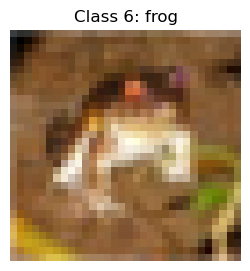

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3, 3))
plt.imshow(x_train[0])
plt.title(
    f"Class {y_train[0]}: {class_names[y_train[0]]}"
)
plt.axis("off")
plt.show()

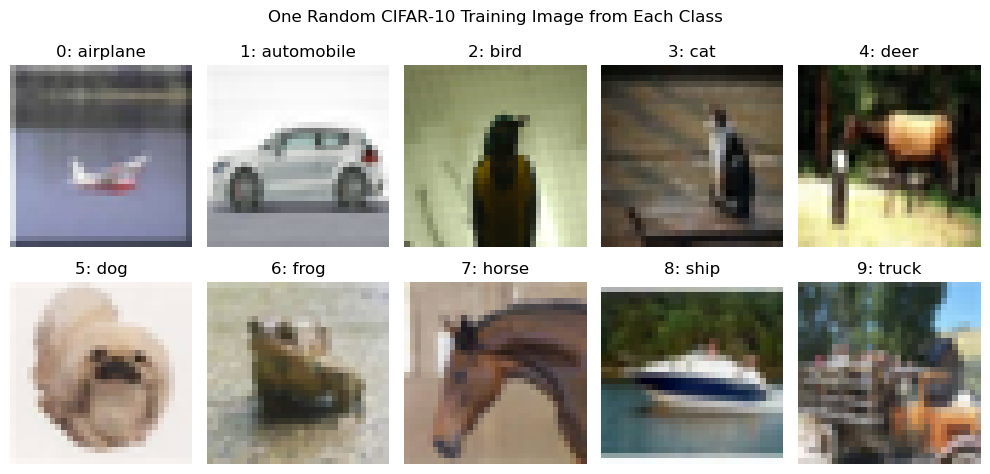

In [9]:
## Displaying one random picture from each class

np.random.seed(42)

# Ensure labels are one-dimensional
y_train_flat = y_train

# Select one random image index from each of the 10 classes
random_indices = []

for class_id in range(len(class_names)):
    class_indices = np.where(y_train_flat == class_id)[0]
    selected_index = np.random.choice(class_indices)
    random_indices.append(selected_index)

# Display the 10 selected images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for class_id, (index, axis) in enumerate(
    zip(random_indices, axes.flat)
):
    axis.imshow(x_train[index], interpolation="nearest")
    axis.set_title(
        f"{class_id}: {class_names[class_id]}"
    )
    axis.axis("off")

plt.suptitle("One Random CIFAR-10 Training Image from Each Class")
plt.tight_layout()
plt.show()

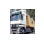

In [10]:
## Viewing the images as their original size for testing purposes

import matplotlib.pyplot as plt
plt.figure(figsize=(0.32, 0.32), dpi=100)
plt.imshow(x_train[1], interpolation="nearest")
plt.axis("off")
plt.show()

In [11]:
### Checking distribution for each class

train_counts = np.bincount(y_train,minlength=10)
test_counts = np.bincount(y_test , minlength=10)

for class_id, class_name in enumerate(class_names):
    print(
        f"{class_id}: {class_name:<10} | "
        f"Train: {train_counts[class_id]:4d} | "
        f"Test: {test_counts[class_id]:4d}"
    )

0: airplane   | Train: 5000 | Test: 1000
1: automobile | Train: 5000 | Test: 1000
2: bird       | Train: 5000 | Test: 1000
3: cat        | Train: 5000 | Test: 1000
4: deer       | Train: 5000 | Test: 1000
5: dog        | Train: 5000 | Test: 1000
6: frog       | Train: 5000 | Test: 1000
7: horse      | Train: 5000 | Test: 1000
8: ship       | Train: 5000 | Test: 1000
9: truck      | Train: 5000 | Test: 1000


,Class ID,Class,Training images,Test images
0,0,airplane,5000,1000
1,1,automobile,5000,1000
2,2,bird,5000,1000
3,3,cat,5000,1000
4,4,deer,5000,1000
5,5,dog,5000,1000
6,6,frog,5000,1000
7,7,horse,5000,1000
8,8,ship,5000,1000
9,9,truck,5000,1000


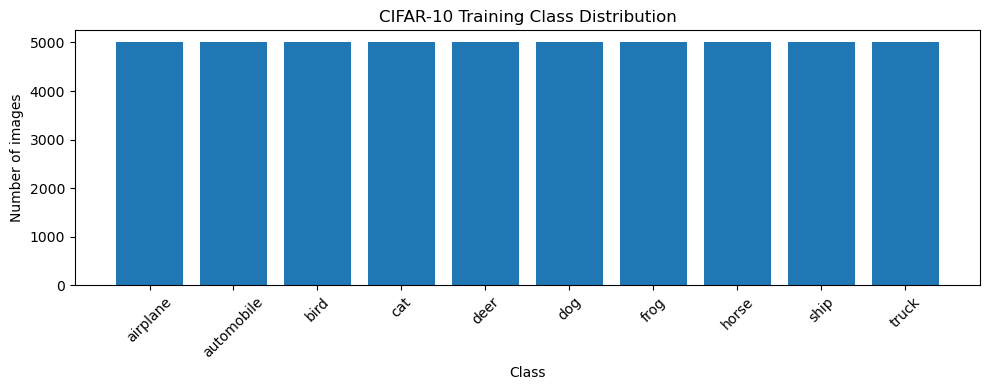

In [12]:
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

class_distribution = pd.DataFrame({
    "Class ID": range(10),
    "Class": class_names,
    "Training images": train_counts,
    "Test images": test_counts
})

display(class_distribution)

plt.figure(figsize=(10, 4))
plt.bar(class_names, train_counts)
plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

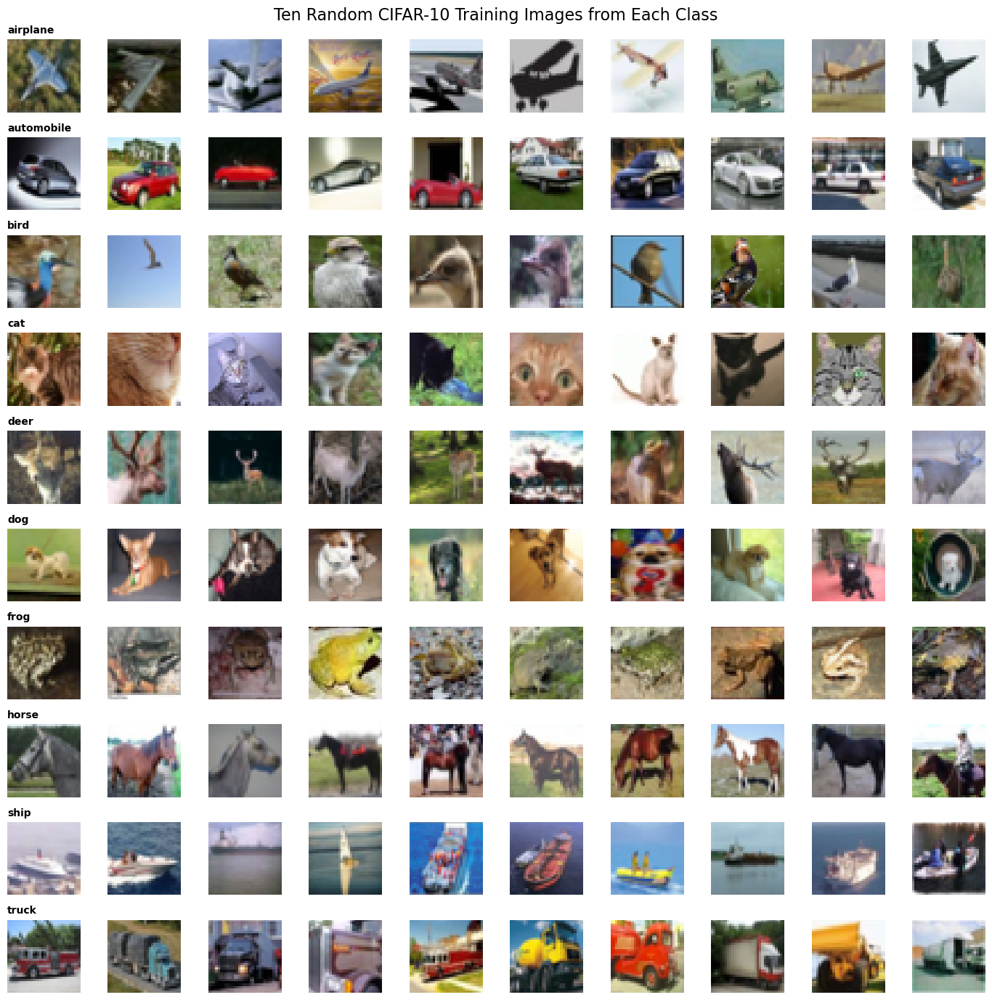

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure labels are one-dimensional
y_train_flat = y_train

rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(14, 14)
)

for class_id in range(10):
    class_indices = np.where(y_train_flat == class_id)[0]

    selected_indices = rng.choice(
        class_indices,
        size=10,
        replace=False
    )

    for column, image_index in enumerate(selected_indices):
        axis = axes[class_id, column]

        axis.imshow(
            x_train[image_index],
            interpolation="nearest"
        )

        axis.axis("off")

        # Put the class name at the start of each row
        if column == 0:
            axis.set_title(
                class_names[class_id],
                loc="left",
                fontsize=10,
                fontweight="bold"
            )

plt.suptitle(
    "Ten Random CIFAR-10 Training Images from Each Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Visual Inspection of Within-Class Variation

A manual visual inspection was carried out by viewing 10 randomly selected
training images from each CIFAR-10 class. The inspection showed that images
within the same class are not visually identical. Objects appear at different
sizes, positions, viewing angles, and distances, while backgrounds, lighting and
colours also vary. Some objects occupy most of the image, whereas others are
small or partly obscured. Because each image is only 32 × 32 pixels, fine
details are often unclear.


### Visual Observations from Ten Random Images per Class

The following observations were made by manually inspecting only the ten randomly
selected training images shown for each CIFAR-10 class. Therefore, these findings
describe this sample of 100 images and should not be treated as a complete summary
of every image in the dataset.

| Class | Observations from the 10 sampled images |
|---|---|
| **Airplane** | The aircraft appears at different angles, including side, front, and overhead views. Most images contain bright sky or outdoor backgrounds, although some aircraft are close-up, while others occupy a smaller area of the image. |
| **Automobile** | The cars vary in colour, shape, and viewing angle. Most are photographed from the side or front-side position, with backgrounds including roads, buildings, grass, and plain studio-like settings. |
| **Bird** | The birds appear in different poses, such as flying, standing and perching. Some images show the bird clearly against the sky, while others contain detailed natural backgrounds that make the bird less distinct. |
| **Cat** | The sample includes close-up faces, partial bodies and full-body views. Fur colour, pose and background vary noticeably, and several images contain cluttered surroundings or unusual viewing angles. |
| **Deer** | Most deer appear outdoors in grassland, forest or natural settings. Their size and distance from the camera vary, and antlers are clearly visible in several samples. Some deer blend into their backgrounds because of similar brown and green colours. |
| **Dog** | The ten images contain different breeds, fur colours, body sizes and poses. Some are close-up portraits, while others show full bodies in indoor or outdoor environments. This class shows considerable visual variation. |
| **Frog** | The frogs mostly appear in natural environments with green, brown or grey colours. Several blend into leaves, rocks or ground textures, making their outlines difficult to distinguish at the low image resolution. |
| **Horse** | Most horses are shown from a side view with much of the body visible. Coat colours vary between brown, black, white and mixed patterns, while the backgrounds are mainly fields, grass or outdoor enclosures. |
| **Ship** | The vessels differ in size, shape, and colour, ranging from small boats to larger ships. Water and sky are common background features, although image clarity and viewing distance vary across the sample. |
| **Truck** | The trucks vary in colour, design, and purpose, including delivery, construction, and emergency-style vehicles. Most are shown from side or front angles, with road, industrial, or outdoor backgrounds. |

From this limited sample, the vehicle classes generally show clearer geometric
shapes, while animal classes contain greater variation in pose, texture, and
background.

In [14]:
x_train_float = x_train.astype("float32")

channel_names = ["Red", "Green", "Blue"]

channel_means = x_train_float.mean(axis=(0, 1, 2))
channel_stds = x_train_float.std(axis=(0, 1, 2))
channel_mins = x_train_float.min(axis=(0, 1, 2))
channel_maxs = x_train_float.max(axis=(0, 1, 2))

channel_statistics = pd.DataFrame({
    "Channel": channel_names,
    "Mean": channel_means,
    "Standard deviation": channel_stds,
    "Minimum": channel_mins,
    "Maximum": channel_maxs
})

display(channel_statistics.round(2))

,Channel,Mean,Standard deviation,Minimum,Maximum
0,Red,125.309998,62.990002,0.0,255.0
1,Green,122.949997,62.090000,0.0,255.0
2,Blue,113.870003,66.709999,0.0,255.0


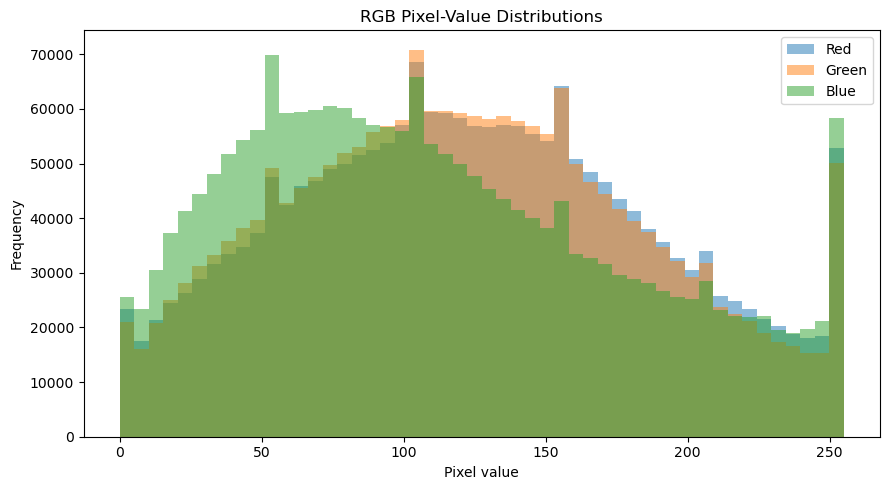

In [15]:
sample_indices = rng.choice(
    len(x_train),
    size=2000,
    replace=False
)

sample_images = x_train[sample_indices]

plt.figure(figsize=(9, 5))

for channel_index, channel_name in enumerate(channel_names):
    plt.hist(
        sample_images[..., channel_index].ravel(),
        bins=50,
        alpha=0.5,
        label=channel_name
    )

plt.title("RGB Pixel-Value Distributions")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

The RGB pixel-value distributions were examined to understand the colour and
intensity range of the CIFAR-10 images before preprocessing. This check helps
confirm whether the channels contain similar value ranges, whether one colour
channel strongly dominates the dataset, and what normalisation should be applied
before model training.

All three channels use almost the full pixel range from 0 to 255 and their
distributions overlap considerably. This indicates that the dataset contains a
wide variety of dark, medium and bright colours rather than being dominated by
one narrow intensity range. The blue channel appears slightly more frequent at
some lower pixel values, while the red and green channels are more concentrated
around the middle of the range. However, no channel shows an extreme imbalance.

In [16]:
image_brightness = x_train.mean(axis=(1, 2, 3))
image_contrast = x_train.std(axis=(1, 2, 3))

image_statistics = pd.DataFrame({
    "Class ID": y_train_flat,
    "Brightness": image_brightness,
    "Contrast": image_contrast
})

class_image_statistics = (
    image_statistics
    .groupby("Class ID")
    .agg({
        "Brightness": ["mean", "std"],
        "Contrast": ["mean", "std"]
    })
    .round(2)
)

class_image_statistics.index = class_names

display(class_image_statistics)

Brightness        Contrast       
                 mean    std     mean    std
airplane       142.37  35.59    52.11  14.47
automobile     116.70  30.87    60.46  11.24
bird           119.41  34.23    46.49  13.80
cat            116.23  32.77    55.30  13.78
deer           111.78  28.19    45.60  12.83
dog            117.39  28.74    55.39  13.15
frog           106.56  31.07    47.74  12.74
horse          118.89  26.26    56.40  12.57
ship           133.48  28.64    55.06  13.06
truck          124.28  25.85    63.62  11.29

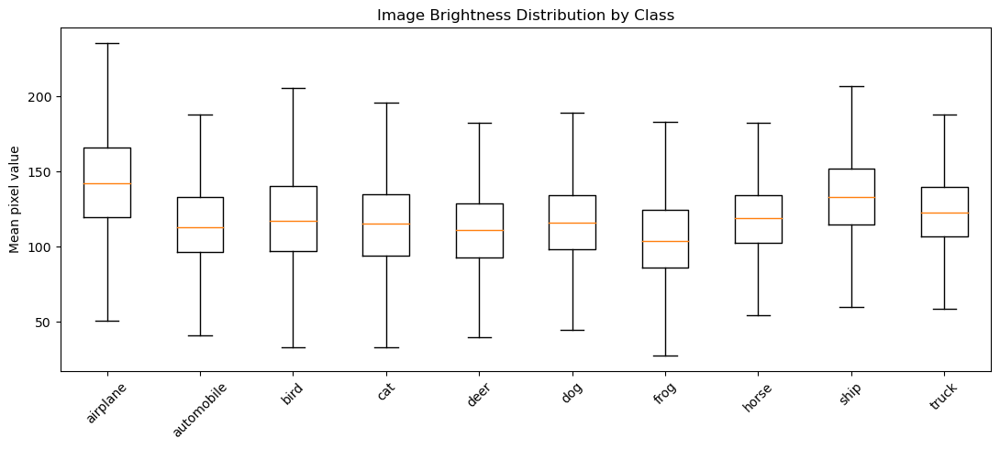

In [17]:
brightness_by_class = [
    image_brightness[y_train_flat == class_id]
    for class_id in range(10)
]

plt.figure(figsize=(11, 5))
plt.boxplot(
    brightness_by_class,
    labels=class_names,
    showfliers=False
)
plt.title("Image Brightness Distribution by Class")
plt.ylabel("Mean pixel value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Brightness and Contrast Analysis by Class

Brightness and contrast were examined to determine whether CIFAR-10 classes have
different overall lighting and intensity characteristics. For each image,
brightness was calculated as the mean pixel value, while contrast was calculated
as the standard deviation of its pixel values.

However, the boxplots overlap substantially, meaning brightness alone
cannot reliably distinguish the classes.

Contrast also varied between classes. Deer and bird images had
lower average contrast, which may be related to animals blending into natural
backgrounds. These observations suggest that the generative models must learn a
wide range of lighting and edge conditions. 

### EDA Summary

CIFAR-10 is balanced across all ten classes, so no class-balancing method is
required. Its images are low-resolution but contain three colour channels,
varied object positions and complex backgrounds.

The original arrays will be preserved before model-specific preprocessing.

## 5. Preprocessing and feature engineering including data augmentation

### Preserving the Original Arrays as backup

### Preservation of the Original Data and reshaping class labels

The original CIFAR-10 image arrays were preserved before any preprocessing was
performed. The images were loaded as unsigned 8-bit integers with pixel values
from 0 to 255 and a shape of 32 × 32 × 3 (TensorFlow, n.d.).

The labels were reshaped from (N, 1) to (N,) using squeeze(). This does not
change their values or the image data. It only converts each label from a
one-element array into a scalar integer, simplifying class filtering, frequency
counting and class conditioning later in the model.

Preserving the original arrays ensures that visualisation, verification, and
alternative preprocessing experiments can always begin from the same unmodified
data.

In [19]:
SEED = 42

# Preserve the original arrays
x_train_full_raw = x_train.copy()
x_test_raw = x_test.copy()

y_train_full = y_train.squeeze().astype(np.int64)
y_test = y_test.squeeze().astype(np.int64)

# Create a stratified 90:10 split from the original training set.
# This gives 45,000 development-training images and 5,000
# validation images while preserving the CIFAR-10 class proportions.
x_train_raw, x_val_raw, y_train_split, y_val = train_test_split(
    x_train_full_raw,
    y_train_full,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_full
)

print("Development training images:", x_train_raw.shape)
print("Validation images:", x_val_raw.shape)
print("Official test images:", x_test_raw.shape)

Development training images: (45000, 32, 32, 3)
Validation images: (5000, 32, 32, 3)
Official test images: (10000, 32, 32, 3)


In [20]:
## Checking if every class remains balanced after splitting
train_counts = np.bincount(
    y_train_split,
    minlength=len(class_names)
)

val_counts = np.bincount(
    y_val,
    minlength=len(class_names)
)

for class_id, class_name in enumerate(class_names):
    print(
        f"{class_name:<10} | "
        f"Train: {train_counts[class_id]:4d} | "
        f"Validation: {val_counts[class_id]:3d}"
    )

assert np.all(train_counts == 4500)
assert np.all(val_counts == 500)


airplane   | Train: 4500 | Validation: 500
automobile | Train: 4500 | Validation: 500
bird       | Train: 4500 | Validation: 500
cat        | Train: 4500 | Validation: 500
deer       | Train: 4500 | Validation: 500
dog        | Train: 4500 | Validation: 500
frog       | Train: 4500 | Validation: 500
horse      | Train: 4500 | Validation: 500
ship       | Train: 4500 | Validation: 500
truck      | Train: 4500 | Validation: 500


### Training, Validation and Test Sets

The official CIFAR-10 test set was kept separate from model training and
hyperparameter selection. A validation set was instead created from the original
training data using a stratified 90:10 split.

This produced 45,000 model-training images and 5,000 validation images. Since
CIFAR-10 is balanced, stratification retained 4,500 training images and 500
validation images from each class. A fixed random seed was used so that the split
can be reproduced in every experiment (Scikit-learn, n.d.).

The training subset will be used to update the generator and discriminator. The
validation subset will be used for checkpoint selection and comparisons such as
validation FID and manual image inspection. The untouched official test set will
only be used after the final model and preprocessing configuration have been
selected .

In [21]:
def normalise_for_gan(images):
    """
    Convert CIFAR-10 images from uint8 [0, 255]
    to float32 [-1, 1].
    """
    images = images.astype(np.float32)
    return (images - 127.5) / 127.5


x_train_gan = normalise_for_gan(x_train_raw)
x_val_gan = normalise_for_gan(x_val_raw)

print("Training data type:", x_train_gan.dtype)
print(
    "Training pixel range:",
    x_train_gan.min(),
    "to",
    x_train_gan.max()
)

Training data type: float32
Training pixel range: -1.0 to 1.0


### Pixel Normalisation

The raw images were converted from `uint8` to `float32` and linearly scaled from
`[0, 255]` to `[-1, 1]`.

The generator uses a `tanh` activation in its output layer, which produces values
between `-1` and `1`. Scaling the real images to the same range ensures that the
discriminator receives real and generated images on a consistent numerical
scale. This follows the preprocessing used in the original DCGAN architecture from the research paper.
(Radford, Metz and Chintala, 2015).

Normalisation is treated as an architectural compatibility requirement rather
than an augmentation experiment. Its correctness was verified by checking the
resulting data type and minimum and maximum values.

In [22]:
print("Minimum class ID:", y_train_split.min())
print("Maximum class ID:", y_train_split.max())
print("Label data type:", y_train_split.dtype)

Minimum class ID: 0
Maximum class ID: 9
Label data type: int64


### Class Labels as Conditioning Features

The class labels were retained as an additional model input rather than being
used only for dataset analysis. In a conditional GAN, the requested label is
provided to both the generator and discriminator. This allows the generator to
produce an image from a specified class and allows the discriminator to judge
whether an image is both realistic and consistent with its label (Mirza and Osindero, 2014).

The labels remain integers from 0 to 9 and are transformed through trainable
embedding layers. This feature-engineering choice directly addresses the
requirement to generate a requested CIFAR-10 class.

Conditioning is evaluated with fixed class-balanced image grids and qualitative
inspection of class consistency, diversity, artefacts and possible mode
collapse. FID and KID provide supporting distribution-level comparisons.


### Augmentation Hypotheses

The baseline is trained without augmentation to establish a reference result.
Horizontal flipping is tested because many CIFAR-10 objects can face either
left or right while retaining class identity. Small translation is tested
because objects can occur at different positions within the 32 × 32 frame.

DiffAugment applies differentiable transformations to both real and generated
images so that the discriminator cannot rely on unaugmented image details while
the generator still receives gradients through the transformation
(Zhao et al., 2020). This research motivates the experiments but does not prove
that an augmentation will improve this implementation.


### Augmentation Review Rule

Every augmentation experiment is evaluated with the same validation images,
evaluation noise, requested labels, FID implementation, KID implementation and
fixed-grid procedure. The notebook presents the complete checkpoint results and
leaves the final interpretation to manual review.

An augmentation should only be described as beneficial when its quantitative
and qualitative evidence supports that conclusion.


In [23]:
def denormalise_gan_images(images):
    """
    Convert images from [-1, 1] to [0, 1]
    for display and saving.
    """
    images = (images + 1.0) / 2.0
    return np.clip(images, 0.0, 1.0)

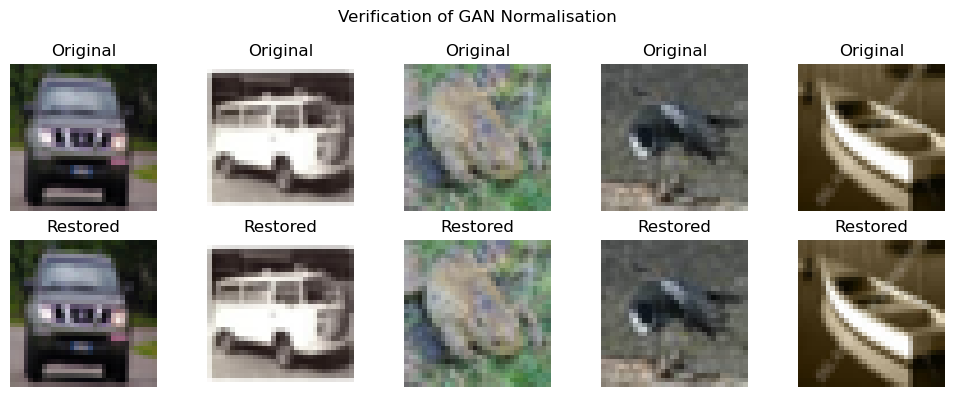

In [24]:
### Making sure normalization doesn't damage the images

import matplotlib.pyplot as plt

sample_indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for column, index in enumerate(sample_indices):
    axes[0, column].imshow(x_train_raw[index])
    axes[0, column].set_title("Original")
    axes[0, column].axis("off")

    restored_image = denormalise_gan_images(
        x_train_gan[index]
    )

    axes[1, column].imshow(restored_image)
    axes[1, column].set_title("Restored")
    axes[1, column].axis("off")

plt.suptitle("Verification of GAN Normalisation")
plt.tight_layout()
plt.show()

### Verification of Normalisation

Several normalised images were converted back to the display range and compared
with their original versions. No visible change in image content, colour or
spatial structure was observed. This confirms that the transformation only
changed the numerical pixel range and did not remove information from the
images.

## 6. Conditional DCGAN Architecture and Shared Configuration


In [25]:
# Shared names and constants used by every retained experiment.
CLASS_NAMES = list(class_names)
IMAGE_SHAPE = (32, 32, 3)
NUM_CLASSES = len(CLASS_NAMES)
LATENT_DIM = 100
LABEL_EMBED_DIM = 50
BATCH_SIZE = 128

BASE_GENERATOR_LR = 2e-4
BASE_DISCRIMINATOR_LR = 2e-4
ADAM_BETA_1 = 0.5

BASE_EPOCHS = 100
CONTINUATION_END_EPOCH = 150
SAVE_EVERY = 10
EMA_DECAY = 0.999

# Compatibility aliases. The EDA and split above remain unchanged.
x_validation_raw = x_val_raw
y_train = y_train_split
y_validation = y_val


def reset_random_state(seed=SEED):
    """Reset Keras state and all random generators for a fresh experiment."""

    reset_experiment_state(seed)


assert x_train_gan.shape == (45000, 32, 32, 3)
assert x_validation_raw.shape == (5000, 32, 32, 3)
assert np.all(np.bincount(y_train, minlength=NUM_CLASSES) == 4500)
assert np.all(np.bincount(y_validation, minlength=NUM_CLASSES) == 500)

print("Shared experiment configuration loaded.")
print("Output root:", OUTPUT_ROOT.resolve())


Shared experiment configuration loaded.
Output root: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs


### 6.1 Baseline Experimental Context

The first model will be a conditional DCGAN trained without data augmentation.
This baseline will establish the initial image quality and training behaviour
before any preprocessing or architectural improvement is introduced.

**Fixed baseline settings**

- Training images: 45,000
- Validation images: 5,000
- Image range: `[-1, 1]`
- Image shape: `32 × 32 × 3`
- Latent dimension: 100
- Batch size: 128
- Augmentation: none
- Random seed: 42
- Conditioning: CIFAR-10 class labels
- Evaluation inputs: 100 fixed latent vectors, ten per class

Later experiments will change one major factor at a time while retaining the
remaining settings wherever possible.

### 6.2 Baseline Conditional DCGAN Architecture

The baseline model is a conditional Deep Convolutional Generative Adversarial
Network, or cDCGAN. It contains two competing neural networks:

- The generator creates synthetic CIFAR-10 images from random latent vectors and
  requested class labels.
- The discriminator judges whether an image is real or generated and whether it
  is consistent with the supplied class label.

Class information is supplied to both networks. This follows the conditional GAN
framework introduced by Mirza and Osindero, where the condition \(y\) is provided
to both the generator and discriminator. This allows the model to generate a
requested category instead of producing an uncontrolled CIFAR-10 class.

The convolutional structure follows the main DCGAN principles: learned
convolutional upsampling is used in the generator, strided convolutions are used
in the discriminator, batch normalisation is applied in intermediate layers,
ReLU is used in the generator, LeakyReLU is used in the discriminator, and the
generator ends with a `tanh` activation.

This first architecture is treated as a baseline rather than the assumed best
model. Later experiments will modify one major component at a time and compare
the results using the same data, training budget and evaluation procedure.

#### Baseline Architecture Settings

A latent dimension of 100 was selected as the initial baseline because it is a
commonly used starting point in DCGAN implementations and is also used in the
module practical. It is not assumed to be optimal for CIFAR-10 and may later be
investigated as a separate hyperparameter.

Each class label is converted into a trainable 50-dimensional embedding. An
embedding allows the model to learn relationships between class labels instead
of treating the class number as a continuous numerical quantity. The embedding
dimension of 50 is a practical starting value rather than a value mandated by
research, and it will remain fixed during the initial experiments.

#### Weight Initialisation

The trainable layers use random-normal weight initialisation with a mean of zero
and a standard deviation of 0.02. This follows the initialisation procedure
reported for DCGAN and provides a clearly documented starting point.

The same initialisation will be used throughout the baseline. It will not be
changed together with other architecture settings, because doing so would make
the source of any performance difference unclear.

#### Generator Design

The generator first converts the combined latent vector and label embedding into
a `4 × 4 × 256` feature map. Three transposed-convolution stages then double the
spatial dimensions:

This produces the exact spatial dimensions required for CIFAR-10. The number of
feature channels decreases from 256 to 128 and then 64 as the spatial resolution
increases. This allows the early layers to learn broad high-level structure and
the later layers to construct finer image details.

Batch normalisation and ReLU are used after intermediate generator layers. The
final layer contains three filters because CIFAR-10 images have red, green and
blue channels. Its tanh activation matches the [-1, 1 normalisation applied
to the real images.

#### Discriminator Design

The discriminator receives both an image and its proposed class label. The label
is embedded into a trainable vector containing 1,024 values and reshaped into a
`32 × 32 × 1` spatial map. This map is concatenated with the RGB image, producing
a 32 × 32 × 4 conditioned input.

The discriminator can therefore learn whether an image is realistic and whether
the image-label pair is compatible. For example, a realistic truck image paired
with the label cat should not be accepted as a correct real pair.

Three strided convolutional layers progressively reduce the spatial dimensions
from `32 × 32` to `4 × 4`. Strided convolutions are used instead of pooling so
that the downsampling operation is learned. LeakyReLU is used because it retains
a small gradient for negative activations.


In [26]:
def dcgan_initializer():
    """Create a fresh DCGAN random-normal initializer."""

    return tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)


def build_generator(
    latent_dim=LATENT_DIM,
    num_classes=NUM_CLASSES,
    label_embed_dim=LABEL_EMBED_DIM,
):
    """Build the shared conditional generator."""

    noise_input = layers.Input(shape=(latent_dim,), name="noise_input")
    label_input = layers.Input(
        shape=(1,), dtype=tf.int32, name="generator_class_label"
    )

    label_embedding = layers.Embedding(
        num_classes,
        label_embed_dim,
        embeddings_initializer=dcgan_initializer(),
    )(label_input)
    label_embedding = layers.Flatten()(label_embedding)

    x = layers.Concatenate()([noise_input, label_embedding])
    x = layers.Dense(
        4 * 4 * 256,
        use_bias=False,
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 4, 256))(x)

    x = layers.Conv2DTranspose(
        128, 4, strides=2, padding="same", use_bias=False,
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(
        64, 4, strides=2, padding="same", use_bias=False,
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    output_image = layers.Conv2DTranspose(
        3, 4, strides=2, padding="same", activation="tanh",
        kernel_initializer=dcgan_initializer(),
        name="generated_image",
    )(x)

    return Model(
        [noise_input, label_input],
        output_image,
        name="conditional_dcgan_generator",
    )

In [27]:
class MinibatchStandardDeviation(layers.Layer):
    """Append one batch-level standard-deviation feature map."""

    def call(self, inputs):
        inputs = tf.convert_to_tensor(inputs, dtype=tf.float32)
        feature_std = tf.math.reduce_std(inputs, axis=0, keepdims=True)
        scalar_std = tf.reduce_mean(feature_std, keepdims=True)
        dynamic_shape = tf.shape(inputs)

        std_map = tf.ones(
            (
                dynamic_shape[0],
                dynamic_shape[1],
                dynamic_shape[2],
                1,
            ),
            dtype=inputs.dtype,
        ) * scalar_std

        outputs = tf.concat([inputs, std_map], axis=-1)

        if inputs.shape.rank == 4 and inputs.shape[-1] is not None:
            outputs.set_shape(
                inputs.shape[:-1].concatenate(inputs.shape[-1] + 1)
            )

        return outputs

    def compute_output_shape(self, input_shape):
        return (
            input_shape[0],
            input_shape[1],
            input_shape[2],
            input_shape[3] + 1,
        )


def build_discriminator(
    image_shape=IMAGE_SHAPE,
    num_classes=NUM_CLASSES,
    add_minibatch_stddev=False,
):
    """Build the shared discriminator or the B6 variant."""

    image_input = layers.Input(image_shape, name="discriminator_image")
    label_input = layers.Input(
        shape=(1,), dtype=tf.int32, name="discriminator_class_label"
    )

    label_embedding = layers.Embedding(
        num_classes,
        image_shape[0] * image_shape[1],
        embeddings_initializer=dcgan_initializer(),
    )(label_input)
    label_map = layers.Reshape((32, 32, 1))(
        layers.Flatten()(label_embedding)
    )

    x = layers.Concatenate(axis=-1)([image_input, label_map])

    x = layers.Conv2D(
        64, 4, strides=2, padding="same",
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(
        128, 4, strides=2, padding="same", use_bias=False,
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(
        256, 4, strides=2, padding="same", use_bias=False,
        kernel_initializer=dcgan_initializer(),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    if add_minibatch_stddev:
        x = MinibatchStandardDeviation()(x)

    x = layers.Flatten()(x)
    output_logit = layers.Dense(
        1,
        kernel_initializer=dcgan_initializer(),
        name="discriminator_logit",
    )(x)

    return Model(
        [image_input, label_input],
        output_logit,
        name=(
            "conditional_discriminator_minibatch_stddev"
            if add_minibatch_stddev
            else "conditional_discriminator"
        ),
    )

In [28]:
# Forward-pass checks
reset_random_state()

test_generator = build_generator()
test_discriminator = build_discriminator()
test_b6_discriminator = build_discriminator(add_minibatch_stddev=True)

test_noise = tf.zeros((2, LATENT_DIM), dtype=tf.float32)
test_labels = tf.constant([[0], [1]], dtype=tf.int32)
test_images = test_generator([test_noise, test_labels], training=False)

assert test_images.shape == (2, 32, 32, 3)
assert test_discriminator([test_images, test_labels]).shape == (2, 1)
assert test_b6_discriminator([test_images, test_labels]).shape == (2, 1)

print("Architecture checks passed.")

del test_generator, test_discriminator, test_b6_discriminator
gc.collect()
tf.keras.backend.clear_session()

Architecture checks passed.


#### Adversarial Loss Functions

The discriminator performs binary classification. Real image-label pairs use a
target of one, while generated image-label pairs use a target of zero. Its total
loss is the sum of the real-image and generated-image binary cross-entropy
losses.

The generator is trained using targets of one for its generated images. It is
therefore rewarded when the discriminator judges a generated image-label pair as
real.

The discriminator produces logits rather than probabilities, so
`BinaryCrossentropy(from_logits=True)` is used. Label smoothing is deliberately
excluded from the baseline and may later be investigated as a separate
stabilisation experiment.

#### Optimiser Selection

Separate Adam optimisers are used because the generator and discriminator have
different parameters and are updated independently.

The baseline uses a learning rate of 0.0002 and an Adam first-moment coefficient
of 0.5. These values follow the original DCGAN training configuration (Radford, Metz and Chintala, 2015) and the module practical. They provide a research-supported baseline but are not assumed
to be universally optimal for CIFAR-10.

The generator and discriminator initially use equal learning rates. Different
learning rates will only be tested later as a controlled experiment if the
training results show that one network consistently dominates the other.

#### Fixed Evaluation Inputs

A fixed set of 100 latent vectors was created, with ten vectors assigned to each
CIFAR-10 class. The same noise vectors and labels will be passed through the
generator at every saved checkpoint.

This controls the input during visual comparison. Therefore, changes in the
displayed images are caused mainly by changes in the trained generator rather
than by sampling different random vectors at each epoch.

In [29]:
binary_cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)


def discriminator_loss(real_logits, generated_logits):
    """Binary cross-entropy loss for real and generated pairs."""

    real_loss = binary_cross_entropy(tf.ones_like(real_logits), real_logits)
    fake_loss = binary_cross_entropy(
        tf.zeros_like(generated_logits), generated_logits
    )
    return real_loss + fake_loss


def generator_loss(generated_logits):
    """Train generated pairs toward the real target."""

    return binary_cross_entropy(
        tf.ones_like(generated_logits), generated_logits
    )


def discriminator_diagnostics(real_logits, generated_logits):
    """Return probabilities and threshold accuracies for monitoring only."""

    real_probability = tf.reduce_mean(tf.sigmoid(real_logits))
    generated_probability = tf.reduce_mean(tf.sigmoid(generated_logits))
    real_accuracy = tf.reduce_mean(
        tf.cast(real_logits >= 0.0, tf.float32)
    )
    generated_accuracy = tf.reduce_mean(
        tf.cast(generated_logits < 0.0, tf.float32)
    )
    balanced_accuracy = (real_accuracy + generated_accuracy) / 2.0

    return (
        real_probability,
        generated_probability,
        real_accuracy,
        generated_accuracy,
        balanced_accuracy,
    )

## 7. Shared Training Framework


The following functions are used by every retained experiment. Defining the
architecture, augmentation policies, training step, checkpoint manager and
plotting helpers once prevents copy-and-paste inconsistencies.

A fixed 10-by-10 grid is displayed and saved every ten epochs. The same fixed
noise and class labels are used throughout, so changes across checkpoints are
visually comparable.


In [30]:
# Differentiable augmentation policies

def identity_policy(images):
    return tf.cast(images, tf.float32)


def horizontal_flip_policy(images):
    return tf.image.random_flip_left_right(images)


def translation_policy(images, max_shift=2):
    """Translate each image by at most two pixels with reflective padding."""

    images = tf.convert_to_tensor(images, dtype=tf.float32)
    padded = tf.pad(
        images,
        [[0, 0], [max_shift, max_shift], [max_shift, max_shift], [0, 0]],
        mode="REFLECT",
    )

    return tf.map_fn(
        lambda image: tf.image.random_crop(image, size=[32, 32, 3]),
        padded,
        fn_output_signature=tf.TensorSpec((32, 32, 3), tf.float32),
        parallel_iterations=1,
    )


def mild_colour_translation_policy(images):
    """Translation plus mild per-image brightness and contrast changes."""

    images = translation_policy(images, max_shift=2)
    batch_size = tf.shape(images)[0]

    brightness_delta = tf.random.uniform(
        (batch_size, 1, 1, 1), -0.10, 0.10, dtype=images.dtype
    )
    contrast_scale = tf.random.uniform(
        (batch_size, 1, 1, 1), 0.90, 1.10, dtype=images.dtype
    )
    image_mean = tf.reduce_mean(images, axis=(1, 2, 3), keepdims=True)

    transformed = (
        (images - image_mean) * contrast_scale
        + image_mean
        + brightness_delta
    )

    return tf.clip_by_value(transformed, -1.0, 1.0)

In [31]:
def build_training_dataset(batch_size=BATCH_SIZE):
    """Create the same deterministic pipeline for every experiment."""

    dataset = (
        tf.data.Dataset.from_tensor_slices((x_train_gan, y_train_split))
        .shuffle(
            len(x_train_gan),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
        .batch(batch_size, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )

    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options)


SAMPLES_PER_CLASS = 10
fixed_labels = tf.convert_to_tensor(
    np.repeat(np.arange(NUM_CLASSES), SAMPLES_PER_CLASS).reshape(-1, 1),
    dtype=tf.int32,
)
fixed_noise = tf.random.stateless_normal(
    (NUM_CLASSES * SAMPLES_PER_CLASS, LATENT_DIM),
    seed=[SEED, 1],
)


def generate_class_grid(
    generator,
    *,
    epoch,
    run_label,
    save_directory,
    show=True,
):
    """Generate and save a fixed 10-by-10 class-balanced grid."""

    images = generator([fixed_noise, fixed_labels], training=False).numpy()
    images = denormalise_gan_images(images)

    fig, axes = plt.subplots(NUM_CLASSES, SAMPLES_PER_CLASS, figsize=(12, 12))

    for class_id in range(NUM_CLASSES):
        for sample_id in range(SAMPLES_PER_CLASS):
            image_index = class_id * SAMPLES_PER_CLASS + sample_id
            axis = axes[class_id, sample_id]
            axis.imshow(images[image_index], interpolation="nearest")
            axis.axis("off")

            if sample_id == 0:
                axis.set_title(
                    CLASS_NAMES[class_id],
                    loc="left",
                    fontsize=9,
                    fontweight="bold",
                )

    fig.suptitle(f"{run_label} — Epoch {epoch}", fontsize=15)
    plt.tight_layout()

    save_directory = Path(save_directory)
    save_directory.mkdir(parents=True, exist_ok=True)
    save_path = save_directory / f"generated_grid_epoch_{int(epoch):03d}.png"
    fig.savefig(save_path, dpi=150, bbox_inches="tight")

    if show:
        plt.show()

    plt.close(fig)
    print("Saved grid:", save_path)


In [32]:
@tf.function
def update_ema_generator(source_generator, ema_generator, decay):
    """Update EMA weights after one generator step."""

    for source_weight, ema_weight in zip(
        source_generator.weights, ema_generator.weights
    ):
        if source_weight.dtype.is_floating:
            ema_weight.assign(
                decay * ema_weight + (1.0 - decay) * source_weight
            )
        else:
            ema_weight.assign(source_weight)


def late_ttur_learning_rates(epoch):
    """B4/B5 learning-rate schedule."""

    if int(epoch) <= 125:
        return 2e-4, 1e-4
    return 1e-4, 5e-5


def assign_learning_rate(optimizer, learning_rate):
    tf.keras.backend.set_value(optimizer.learning_rate, float(learning_rate))

In [33]:
def make_bce_train_step(
    *,
    generator,
    discriminator,
    generator_optimizer,
    discriminator_optimizer,
    augmentation_function=identity_policy,
    ema_generator=None,
    ema_decay=EMA_DECAY,
):
    """Create the shared compiled BCE train step."""

    @tf.function
    def train_step(real_images, class_labels):
        real_images = tf.cast(real_images, tf.float32)
        class_labels = tf.cast(
            tf.reshape(class_labels, (-1, 1)), tf.int32
        )
        batch_size = tf.shape(real_images)[0]
        noise = tf.random.normal((batch_size, LATENT_DIM))

        with tf.GradientTape() as generator_tape:
            with tf.GradientTape() as discriminator_tape:
                generated_images = generator(
                    [noise, class_labels], training=True
                )

                combined_images = tf.concat(
                    [real_images, generated_images], axis=0
                )
                augmented_images = augmentation_function(combined_images)
                augmented_real = augmented_images[:batch_size]
                augmented_fake = augmented_images[batch_size:]

                real_logits = discriminator(
                    [augmented_real, class_labels], training=True
                )
                fake_logits = discriminator(
                    [augmented_fake, class_labels], training=True
                )

                current_generator_loss = generator_loss(fake_logits)
                current_discriminator_loss = discriminator_loss(
                    real_logits, fake_logits
                )

        generator_gradients = generator_tape.gradient(
            current_generator_loss,
            generator.trainable_variables,
        )
        discriminator_gradients = discriminator_tape.gradient(
            current_discriminator_loss,
            discriminator.trainable_variables,
        )

        tf.debugging.assert_all_finite(
            current_generator_loss, "Generator loss became non-finite."
        )
        tf.debugging.assert_all_finite(
            current_discriminator_loss,
            "Discriminator loss became non-finite.",
        )

        generator_optimizer.apply_gradients(
            zip(generator_gradients, generator.trainable_variables)
        )
        discriminator_optimizer.apply_gradients(
            zip(discriminator_gradients, discriminator.trainable_variables)
        )

        if ema_generator is not None:
            update_ema_generator(
                generator,
                ema_generator,
                tf.cast(ema_decay, tf.float32),
            )

        diagnostics = discriminator_diagnostics(real_logits, fake_logits)

        return (
            current_generator_loss,
            current_discriminator_loss,
            *diagnostics,
        )

    return train_step

In [34]:
def prepare_run_directories(run_name, include_ema=False):
    """Create an isolated empty output directory for one experiment."""

    run_directory = OUTPUT_ROOT / run_name

    if run_directory.exists() and any(run_directory.iterdir()):
        raise FileExistsError(
            "Existing experiment outputs found:\n"
            f"{run_directory.resolve()}\n\n"
            "Remove only this experiment folder before intentionally rerunning it."
        )

    paths = {
        "run_name": run_name,
        "run_directory": run_directory,
        "checkpoint_directory": run_directory / "checkpoints",
        "history_path": run_directory / "training_history.csv",
        "raw_grid_directory": run_directory / "generated_grids_raw",
    }

    if include_ema:
        paths["ema_grid_directory"] = run_directory / "generated_grids_ema"

    for value in paths.values():
        if isinstance(value, Path) and value.suffix == "":
            value.mkdir(parents=True, exist_ok=True)

    return paths


def materialize_optimizer_slots(optimizer, variables):
    """Create Adam slot variables before continuation restoration."""

    if hasattr(optimizer, "_create_all_weights"):
        optimizer._create_all_weights(variables)
    elif hasattr(optimizer, "build"):
        optimizer.build(variables)
    else:
        raise RuntimeError("Could not create optimizer slot variables.")


def create_fresh_experiment(
    *,
    run_name,
    generator_learning_rate=BASE_GENERATOR_LR,
    discriminator_learning_rate=BASE_DISCRIMINATOR_LR,
    discriminator_builder=None,
):
    """Create a fresh independent experiment."""

    paths = prepare_run_directories(run_name, include_ema=False)
    reset_random_state()

    generator = build_generator()
    discriminator = (
        build_discriminator()
        if discriminator_builder is None
        else discriminator_builder()
    )

    generator_optimizer = tf.keras.optimizers.Adam(
        generator_learning_rate, beta_1=ADAM_BETA_1
    )
    discriminator_optimizer = tf.keras.optimizers.Adam(
        discriminator_learning_rate, beta_1=ADAM_BETA_1
    )
    epoch_counter = tf.Variable(
        0,
        dtype=tf.int64,
        trainable=False,
        name=f"{run_name}_epoch",
    )

    checkpoint = tf.train.Checkpoint(
        epoch=epoch_counter,
        generator=generator,
        discriminator=discriminator,
        generator_optimizer=generator_optimizer,
        discriminator_optimizer=discriminator_optimizer,
    )
    checkpoint_manager = tf.train.CheckpointManager(
        checkpoint,
        str(paths["checkpoint_directory"]),
        max_to_keep=20,
    )

    return {
        **paths,
        "generator": generator,
        "discriminator": discriminator,
        "generator_optimizer": generator_optimizer,
        "discriminator_optimizer": discriminator_optimizer,
        "epoch_counter": epoch_counter,
        "checkpoint": checkpoint,
        "checkpoint_manager": checkpoint_manager,
        "train_dataset": build_training_dataset(),
    }


def create_b3_continuation(*, run_name, source_epoch=100):
    """Restore the complete B3 state into an independent EMA continuation."""

    paths = prepare_run_directories(run_name, include_ema=True)
    reset_random_state()

    generator = build_generator()
    discriminator = build_discriminator()
    ema_generator = build_generator()

    generator_optimizer = tf.keras.optimizers.Adam(
        BASE_GENERATOR_LR, beta_1=ADAM_BETA_1
    )
    discriminator_optimizer = tf.keras.optimizers.Adam(
        BASE_DISCRIMINATOR_LR, beta_1=ADAM_BETA_1
    )

    materialize_optimizer_slots(
        generator_optimizer, generator.trainable_variables
    )
    materialize_optimizer_slots(
        discriminator_optimizer, discriminator.trainable_variables
    )

    source_path = (
        OUTPUT_ROOT
        / "B3_translation_2px"
        / "checkpoints"
        / f"ckpt-{int(source_epoch)}"
    )

    if not Path(str(source_path) + ".index").exists():
        raise FileNotFoundError(
            f"B3 source checkpoint not found: {source_path.resolve()}"
        )

    restored_epoch = tf.Variable(0, dtype=tf.int64, trainable=False)
    source_checkpoint = tf.train.Checkpoint(
        epoch=restored_epoch,
        generator=generator,
        discriminator=discriminator,
        generator_optimizer=generator_optimizer,
        discriminator_optimizer=discriminator_optimizer,
    )

    status = source_checkpoint.restore(str(source_path))
    status.expect_partial()
    status.assert_existing_objects_matched()

    if int(restored_epoch.numpy()) != int(source_epoch):
        raise RuntimeError(
            f"Expected epoch {source_epoch}, restored {int(restored_epoch.numpy())}."
        )

    ema_generator.set_weights(generator.get_weights())
    epoch_counter = tf.Variable(
        int(source_epoch),
        dtype=tf.int64,
        trainable=False,
        name=f"{run_name}_epoch",
    )

    checkpoint = tf.train.Checkpoint(
        epoch=epoch_counter,
        generator=generator,
        discriminator=discriminator,
        ema_generator=ema_generator,
        generator_optimizer=generator_optimizer,
        discriminator_optimizer=discriminator_optimizer,
    )
    checkpoint_manager = tf.train.CheckpointManager(
        checkpoint,
        str(paths["checkpoint_directory"]),
        max_to_keep=20,
    )

    baseline_checkpoint = checkpoint_manager.save(
        checkpoint_number=int(source_epoch)
    )
    print("Restored B3:", source_path)
    print("Saved continuation baseline:", baseline_checkpoint)

    generate_class_grid(
        generator,
        epoch=source_epoch,
        run_label=f"{run_name} raw",
        save_directory=paths["raw_grid_directory"],
        show=True,
    )
    generate_class_grid(
        ema_generator,
        epoch=source_epoch,
        run_label=f"{run_name} EMA",
        save_directory=paths["ema_grid_directory"],
        show=True,
    )

    return {
        **paths,
        "generator": generator,
        "discriminator": discriminator,
        "ema_generator": ema_generator,
        "generator_optimizer": generator_optimizer,
        "discriminator_optimizer": discriminator_optimizer,
        "epoch_counter": epoch_counter,
        "checkpoint": checkpoint,
        "checkpoint_manager": checkpoint_manager,
        "train_dataset": build_training_dataset(),
    }


In [35]:
def append_training_log(log_path, message):
    """Append one line to a permanent experiment log."""

    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)

    with log_path.open("a", encoding="utf-8") as log_file:
        log_file.write(str(message) + "\n")


def run_training_experiment(
    *,
    experiment,
    train_step,
    run_label,
    start_epoch,
    end_epoch,
    save_every=SAVE_EVERY,
    learning_rate_schedule=None,
):
    """Train one experiment and save complete logs, checkpoints and grids."""

    start_epoch = int(start_epoch)
    end_epoch = int(end_epoch)

    history = {
        "epoch": [],
        "generator_learning_rate": [],
        "discriminator_learning_rate": [],
        "generator_loss": [],
        "discriminator_loss": [],
        "real_probability": [],
        "generated_probability": [],
        "real_accuracy": [],
        "generated_accuracy": [],
        "discriminator_accuracy": [],
        "epoch_time_seconds": [],
    }

    log_path = experiment["run_directory"] / "training_log.txt"
    log_path.write_text(
        f"{run_label}\nEpoch range: {start_epoch}-{end_epoch}\n\n",
        encoding="utf-8",
    )

    for epoch in range(start_epoch, end_epoch + 1):
        if learning_rate_schedule is not None:
            generator_lr, discriminator_lr = learning_rate_schedule(epoch)
            assign_learning_rate(
                experiment["generator_optimizer"], generator_lr
            )
            assign_learning_rate(
                experiment["discriminator_optimizer"], discriminator_lr
            )

        epoch_start = time.perf_counter()
        metric_objects = {
            name: tf.keras.metrics.Mean()
            for name in [
                "generator_loss",
                "discriminator_loss",
                "real_probability",
                "generated_probability",
                "real_accuracy",
                "generated_accuracy",
                "discriminator_accuracy",
            ]
        }

        for real_batch, label_batch in experiment["train_dataset"]:
            values = train_step(real_batch, label_batch)

            for metric_name, value in zip(metric_objects, values):
                metric_objects[metric_name].update_state(value)

        epoch_seconds = time.perf_counter() - epoch_start
        epoch_row = {
            "epoch": int(epoch),
            "generator_learning_rate": float(
                experiment["generator_optimizer"].learning_rate.numpy()
            ),
            "discriminator_learning_rate": float(
                experiment["discriminator_optimizer"].learning_rate.numpy()
            ),
            **{
                name: float(metric.result())
                for name, metric in metric_objects.items()
            },
            "epoch_time_seconds": float(epoch_seconds),
        }

        numeric_values = np.asarray(
            list(epoch_row.values()), dtype=np.float64
        )
        if not np.isfinite(numeric_values).all():
            raise FloatingPointError(
                f"{run_label} produced a non-finite value at epoch {epoch}."
            )

        for key, value in epoch_row.items():
            history[key].append(value)

        history_frame = pd.DataFrame(history)
        history_frame.to_csv(experiment["history_path"], index=False)

        epoch_line = (
            f"Epoch {epoch:03d}/{end_epoch} | "
            f"G {epoch_row['generator_loss']:.4f} | "
            f"D {epoch_row['discriminator_loss']:.4f} | "
            f"D(real) {epoch_row['real_probability']:.4f} | "
            f"D(fake) {epoch_row['generated_probability']:.4f} | "
            f"D acc {epoch_row['discriminator_accuracy']:.4f} | "
            f"{epoch_seconds:.1f}s"
        )
        print(epoch_line, flush=True)
        append_training_log(log_path, epoch_line)

        should_save = (
            epoch % int(save_every) == 0
            or epoch == end_epoch
        )

        if should_save:
            experiment["epoch_counter"].assign(epoch)
            checkpoint_path = experiment["checkpoint_manager"].save(
                checkpoint_number=epoch
            )
            print("Saved checkpoint:", checkpoint_path, flush=True)
            append_training_log(
                log_path,
                f"Saved checkpoint: {checkpoint_path}",
            )

            generate_class_grid(
                experiment["generator"],
                epoch=epoch,
                run_label=f"{run_label} raw",
                save_directory=experiment["raw_grid_directory"],
                show=True,
            )

            if "ema_generator" in experiment:
                generate_class_grid(
                    experiment["ema_generator"],
                    epoch=epoch,
                    run_label=f"{run_label} EMA",
                    save_directory=experiment["ema_grid_directory"],
                    show=True,
                )

    history_frame = pd.DataFrame(history)
    expected_epochs = np.arange(start_epoch, end_epoch + 1)

    if not np.array_equal(
        history_frame["epoch"].to_numpy(), expected_epochs
    ):
        raise RuntimeError(
            f"{run_label} history is incomplete. "
            f"Expected epochs {start_epoch}-{end_epoch}."
        )

    (experiment["run_directory"] / "training_history_full.txt").write_text(
        history_frame.to_string(index=False),
        encoding="utf-8",
    )

    print(
        f"Completed {run_label}: {len(history_frame)} epochs recorded.",
        flush=True,
    )
    return history_frame


def plot_training_history(history_frame, run_label):
    """Plot losses and discriminator probabilities after training."""

    plt.figure(figsize=(10, 5))
    plt.plot(
        history_frame["epoch"],
        history_frame["generator_loss"],
        label="Generator loss",
    )
    plt.plot(
        history_frame["epoch"],
        history_frame["discriminator_loss"],
        label="Discriminator loss",
    )
    plt.title(f"{run_label}: Adversarial Losses")
    plt.xlabel("Epoch")
    plt.ylabel("BCE loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(
        history_frame["epoch"],
        history_frame["real_probability"],
        label="D(real)",
    )
    plt.plot(
        history_frame["epoch"],
        history_frame["generated_probability"],
        label="D(fake)",
    )
    plt.axhline(0.5, linestyle="--", label="0.5 reference")
    plt.title(f"{run_label}: Discriminator Probabilities")
    plt.xlabel("Epoch")
    plt.ylabel("Average probability")
    plt.legend()
    plt.tight_layout()
    plt.show()


def release_experiment(experiment):
    """Release large in-memory training objects after saving them."""

    del experiment
    gc.collect()
    tf.keras.backend.clear_session()
    gc.collect()


In [36]:
def execute_fresh_experiment(
    *,
    run_name,
    run_label,
    augmentation_function=identity_policy,
    generator_learning_rate=BASE_GENERATOR_LR,
    discriminator_learning_rate=BASE_DISCRIMINATOR_LR,
    discriminator_builder=None,
):
    """Create, train, save and release one fresh experiment."""

    experiment = create_fresh_experiment(
        run_name=run_name,
        generator_learning_rate=generator_learning_rate,
        discriminator_learning_rate=discriminator_learning_rate,
        discriminator_builder=discriminator_builder,
    )
    train_step = make_bce_train_step(
        generator=experiment["generator"],
        discriminator=experiment["discriminator"],
        generator_optimizer=experiment["generator_optimizer"],
        discriminator_optimizer=experiment["discriminator_optimizer"],
        augmentation_function=augmentation_function,
    )
    history = run_training_experiment(
        experiment=experiment,
        train_step=train_step,
        run_label=run_label,
        start_epoch=1,
        end_epoch=BASE_EPOCHS,
    )
    plot_training_history(history, run_label)

    result = {
        "run_name": run_name,
        "run_directory": experiment["run_directory"],
        "checkpoint_directory": experiment["checkpoint_directory"],
        "history_path": experiment["history_path"],
        "history": history,
    }
    release_experiment(experiment)
    return result


def execute_b3_continuation(
    *,
    run_name,
    run_label,
    augmentation_function,
):
    """Restore B3 epoch 100 and continue to epoch 150 with EMA/TTUR."""

    experiment = create_b3_continuation(run_name=run_name, source_epoch=100)
    train_step = make_bce_train_step(
        generator=experiment["generator"],
        discriminator=experiment["discriminator"],
        generator_optimizer=experiment["generator_optimizer"],
        discriminator_optimizer=experiment["discriminator_optimizer"],
        augmentation_function=augmentation_function,
        ema_generator=experiment["ema_generator"],
        ema_decay=EMA_DECAY,
    )
    history = run_training_experiment(
        experiment=experiment,
        train_step=train_step,
        run_label=run_label,
        start_epoch=101,
        end_epoch=CONTINUATION_END_EPOCH,
        learning_rate_schedule=late_ttur_learning_rates,
    )
    plot_training_history(history, run_label)

    result = {
        "run_name": run_name,
        "run_directory": experiment["run_directory"],
        "checkpoint_directory": experiment["checkpoint_directory"],
        "history_path": experiment["history_path"],
        "history": history,
    }
    release_experiment(experiment)
    return result

In [37]:
# One-batch smoke test before long training.
reset_random_state()
smoke_generator = build_generator()
smoke_discriminator = build_discriminator()
smoke_g_optimizer = tf.keras.optimizers.Adam(BASE_GENERATOR_LR, beta_1=ADAM_BETA_1)
smoke_d_optimizer = tf.keras.optimizers.Adam(BASE_DISCRIMINATOR_LR, beta_1=ADAM_BETA_1)
smoke_step = make_bce_train_step(
    generator=smoke_generator,
    discriminator=smoke_discriminator,
    generator_optimizer=smoke_g_optimizer,
    discriminator_optimizer=smoke_d_optimizer,
)
smoke_images, smoke_labels = next(iter(build_training_dataset()))
weights_before = [
    variable.numpy().copy()
    for variable in smoke_generator.trainable_variables
]
smoke_values = smoke_step(smoke_images, smoke_labels)
maximum_change = max(
    np.max(np.abs(before - after.numpy()))
    for before, after in zip(weights_before, smoke_generator.trainable_variables)
)

assert all(np.isfinite(float(value)) for value in smoke_values)
assert maximum_change > 0.0
print("Smoke test passed. Maximum generator weight change:", maximum_change)

del smoke_generator, smoke_discriminator, smoke_g_optimizer, smoke_d_optimizer, smoke_step
gc.collect()
tf.keras.backend.clear_session()

Smoke test passed. Maximum generator weight change: 0.00020003319


## 7.1 Shared Manual FID and KID Evaluation


FID is the primary quantitative metric and KID is the secondary metric.
The functions below are defined once, but **no evaluation is triggered inside a
training function**. A separate evaluation cell appears directly after every
experiment so the user controls when the potentially slow checkpoint sweep is
run.

Each evaluation cell:

- uses the same 5,000 balanced validation images;
- uses the same fixed noise and requested labels;
- evaluates every checkpoint saved at ten-epoch intervals;
- displays the complete FID/KID table;
- plots FID and KID against epoch; and
- saves the table inside that experiment's folder.

The plots support checkpoint review but do not choose a winner automatically.


In [38]:
EVALUATION_SAMPLES_PER_CLASS = 500
EVALUATION_SAMPLE_COUNT = NUM_CLASSES * EVALUATION_SAMPLES_PER_CLASS
EVALUATION_BATCH_SIZE = 8
INCEPTION_IMAGE_SIZE = 299
METRIC_SEED = 2026

KID_SUBSET_SIZE = 100
KID_NUM_SUBSETS = 50

EVALUATION_ROOT = OUTPUT_ROOT / "manual_checkpoint_evaluation"
MANUAL_EVALUATION_DIRECTORY = EVALUATION_ROOT / "visual_labelling"
MANUAL_EVALUATION_DIRECTORY.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE_DIRECTORY = EVALUATION_ROOT / "feature_cache"
FEATURE_CACHE_DIRECTORY.mkdir(parents=True, exist_ok=True)

REAL_FEATURE_CACHE_PATH = (
    FEATURE_CACHE_DIRECTORY
    / f"cifar10_validation_{EVALUATION_SAMPLE_COUNT}_inceptionv3.npy"
)

# Fixed class-balanced inputs used for every experiment.
evaluation_labels = tf.convert_to_tensor(
    np.repeat(
        np.arange(NUM_CLASSES),
        EVALUATION_SAMPLES_PER_CLASS,
    ).reshape(-1, 1),
    dtype=tf.int32,
)
evaluation_noise = tf.random.stateless_normal(
    (EVALUATION_SAMPLE_COUNT, LATENT_DIM),
    seed=[SEED, METRIC_SEED],
)

_metric_encoder = None


def ensure_metric_encoder():
    """Load InceptionV3 only when a manual evaluation cell is executed."""

    global _metric_encoder

    if _metric_encoder is None:
        print("Loading InceptionV3 for FID/KID evaluation...", flush=True)
        _metric_encoder = tf.keras.applications.InceptionV3(
            include_top=False,
            weights="imagenet",
            pooling="avg",
            input_shape=(
                INCEPTION_IMAGE_SIZE,
                INCEPTION_IMAGE_SIZE,
                3,
            ),
        )
        _metric_encoder.trainable = False

    return _metric_encoder


def encode_for_metrics(images_0_255):
    """Convert RGB images in [0, 255] into Inception feature vectors."""

    encoder = ensure_metric_encoder()
    images = tf.cast(images_0_255, tf.float32)
    images = tf.image.resize(
        images,
        (INCEPTION_IMAGE_SIZE, INCEPTION_IMAGE_SIZE),
        method="bilinear",
        antialias=True,
    )
    images = tf.keras.applications.inception_v3.preprocess_input(images)
    return encoder(images, training=False)


def extract_real_features(images, batch_size=EVALUATION_BATCH_SIZE):
    """Extract features from real uint8 CIFAR-10 validation images."""

    feature_batches = []

    for start in range(0, len(images), int(batch_size)):
        end = min(start + int(batch_size), len(images))
        feature_batches.append(
            encode_for_metrics(images[start:end]).numpy()
        )

    return np.concatenate(feature_batches, axis=0).astype(np.float64)


def load_or_create_real_validation_features(force_recompute=False):
    """Load the shared real-feature cache or compute it once."""

    if REAL_FEATURE_CACHE_PATH.exists() and not force_recompute:
        features = np.load(REAL_FEATURE_CACHE_PATH).astype(np.float64)
        expected_shape = (EVALUATION_SAMPLE_COUNT, 2048)

        if features.shape != expected_shape:
            raise RuntimeError(
                f"Unexpected cached feature shape {features.shape}; "
                f"expected {expected_shape}."
            )

        print(
            "Loaded cached real features:",
            REAL_FEATURE_CACHE_PATH.resolve(),
        )
        return features

    features = extract_real_features(
        x_validation_raw,
        batch_size=EVALUATION_BATCH_SIZE,
    )
    np.save(REAL_FEATURE_CACHE_PATH, features)
    print("Saved real features:", REAL_FEATURE_CACHE_PATH.resolve())
    return features


def extract_generated_features(
    generator,
    noise=evaluation_noise,
    labels=evaluation_labels,
    batch_size=EVALUATION_BATCH_SIZE,
):
    """Generate the fixed balanced sample and extract Inception features."""

    feature_batches = []
    total_images = int(noise.shape[0])

    for start in range(0, total_images, int(batch_size)):
        end = min(start + int(batch_size), total_images)
        generated = generator(
            [noise[start:end], labels[start:end]],
            training=False,
        )
        generated = tf.clip_by_value(
            (generated + 1.0) * 127.5,
            0.0,
            255.0,
        )
        feature_batches.append(encode_for_metrics(generated).numpy())

    return np.concatenate(feature_batches, axis=0).astype(np.float64)


def calculate_fid(real_features, generated_features, epsilon=1e-6):
    """Calculate Fréchet Inception Distance; lower is better."""

    real_features = np.asarray(real_features, dtype=np.float64)
    generated_features = np.asarray(
        generated_features, dtype=np.float64
    )

    real_mean = real_features.mean(axis=0)
    generated_mean = generated_features.mean(axis=0)
    real_covariance = np.cov(real_features, rowvar=False)
    generated_covariance = np.cov(
        generated_features, rowvar=False
    )

    mean_difference = real_mean - generated_mean
    covariance_mean = sqrtm(
        real_covariance @ generated_covariance
    )

    if not np.isfinite(covariance_mean).all():
        offset = np.eye(real_covariance.shape[0]) * float(epsilon)
        covariance_mean = sqrtm(
            (real_covariance + offset)
            @ (generated_covariance + offset)
        )

    if np.iscomplexobj(covariance_mean):
        covariance_mean = covariance_mean.real

    fid_value = (
        mean_difference @ mean_difference
        + np.trace(real_covariance)
        + np.trace(generated_covariance)
        - 2.0 * np.trace(covariance_mean)
    )
    return float(max(np.real(fid_value), 0.0))


def calculate_kid(
    real_features,
    generated_features,
    subset_size=KID_SUBSET_SIZE,
    num_subsets=KID_NUM_SUBSETS,
    seed=METRIC_SEED,
):
    """Estimate unbiased polynomial-kernel KID mean and standard deviation."""

    real_features = np.asarray(real_features, dtype=np.float64)
    generated_features = np.asarray(
        generated_features, dtype=np.float64
    )

    if subset_size > min(
        len(real_features), len(generated_features)
    ):
        raise ValueError("KID subset_size is larger than the feature sets.")

    rng = np.random.default_rng(int(seed))
    feature_dimension = real_features.shape[1]
    kid_scores = []

    for _ in range(int(num_subsets)):
        real_subset = real_features[
            rng.choice(
                len(real_features), subset_size, replace=False
            )
        ]
        generated_subset = generated_features[
            rng.choice(
                len(generated_features), subset_size, replace=False
            )
        ]

        real_kernel = (
            real_subset @ real_subset.T / feature_dimension + 1.0
        ) ** 3
        generated_kernel = (
            generated_subset @ generated_subset.T
            / feature_dimension
            + 1.0
        ) ** 3
        cross_kernel = (
            real_subset @ generated_subset.T
            / feature_dimension
            + 1.0
        ) ** 3

        real_term = (
            real_kernel.sum() - np.trace(real_kernel)
        ) / (subset_size * (subset_size - 1))
        generated_term = (
            generated_kernel.sum()
            - np.trace(generated_kernel)
        ) / (subset_size * (subset_size - 1))
        cross_term = cross_kernel.mean()

        kid_scores.append(
            real_term + generated_term - 2.0 * cross_term
        )

    return (
        float(np.mean(kid_scores)),
        float(np.std(kid_scores, ddof=1)),
    )


def load_selected_generator(*, run_name, epoch, candidate="raw"):
    """Restore one explicitly requested raw or EMA generator checkpoint."""

    candidate = str(candidate).strip().lower()
    if candidate not in {"raw", "ema"}:
        raise ValueError("candidate must be 'raw' or 'ema'.")

    checkpoint_path = (
        OUTPUT_ROOT
        / run_name
        / "checkpoints"
        / f"ckpt-{int(epoch)}"
    )

    if not Path(str(checkpoint_path) + ".index").exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path.resolve()}"
        )

    selected_generator = build_generator()
    restore_object = (
        tf.train.Checkpoint(generator=selected_generator)
        if candidate == "raw"
        else tf.train.Checkpoint(ema_generator=selected_generator)
    )

    status = restore_object.restore(str(checkpoint_path))
    status.expect_partial()
    status.assert_existing_objects_matched()
    return selected_generator


def saved_checkpoint_epochs(checkpoint_directory):
    """Return checkpoint numbers in ascending order."""

    checkpoint_directory = Path(checkpoint_directory)
    epochs = sorted(
        int(path.stem.split("-")[-1])
        for path in checkpoint_directory.glob("ckpt-*.index")
    )

    if not epochs:
        raise FileNotFoundError(
            "No checkpoints found in: "
            f"{checkpoint_directory.resolve()}"
        )

    return epochs


def evaluate_checkpoint_directory(
    *,
    experiment_name,
    run_name,
    candidates=("raw",),
    expected_epochs=None,
):
    """Manually evaluate all saved checkpoints without selecting a winner."""

    checkpoint_directory = OUTPUT_ROOT / run_name / "checkpoints"
    checkpoint_epochs = saved_checkpoint_epochs(checkpoint_directory)

    if expected_epochs is not None:
        expected_epochs = [int(epoch) for epoch in expected_epochs]
        if checkpoint_epochs != expected_epochs:
            raise RuntimeError(
                f"{experiment_name} checkpoints do not match the expected "
                f"epochs. Found {checkpoint_epochs}; expected "
                f"{expected_epochs}."
            )

    result_directory = OUTPUT_ROOT / run_name / "checkpoint_evaluation"
    result_directory.mkdir(parents=True, exist_ok=True)
    result_path = result_directory / "fid_kid_by_checkpoint.csv"

    real_features = load_or_create_real_validation_features()

    if result_path.exists():
        results = pd.read_csv(result_path)
        print("Resuming saved metric table:", result_path.resolve())
    else:
        results = pd.DataFrame(columns=[
            "experiment",
            "run_name",
            "epoch",
            "candidate",
            "fid",
            "kid_mean",
            "kid_std",
            "generated_samples",
        ])

    completed_pairs = {
        (int(row.epoch), str(row.candidate))
        for row in results.itertuples(index=False)
    }

    for epoch in checkpoint_epochs:
        for candidate in candidates:
            pair = (int(epoch), str(candidate))

            if pair in completed_pairs:
                print(
                    f"Already evaluated {experiment_name}: "
                    f"epoch {epoch}, {candidate}; skipping.",
                    flush=True,
                )
                continue

            print(
                f"Evaluating {experiment_name}: "
                f"epoch {epoch}, {candidate}...",
                flush=True,
            )
            generator = load_selected_generator(
                run_name=run_name,
                epoch=epoch,
                candidate=candidate,
            )
            generated_features = extract_generated_features(generator)

            fid_score = calculate_fid(
                real_features, generated_features
            )
            kid_mean, kid_std = calculate_kid(
                real_features, generated_features
            )

            new_row = pd.DataFrame([{
                "experiment": experiment_name,
                "run_name": run_name,
                "epoch": int(epoch),
                "candidate": str(candidate),
                "fid": float(fid_score),
                "kid_mean": float(kid_mean),
                "kid_std": float(kid_std),
                "generated_samples": EVALUATION_SAMPLE_COUNT,
            }])

            results = pd.concat(
                [results, new_row],
                ignore_index=True,
            )
            results = (
                results
                .drop_duplicates(
                    subset=["epoch", "candidate"],
                    keep="last",
                )
                .sort_values(["candidate", "epoch"])
                .reset_index(drop=True)
            )
            results.to_csv(result_path, index=False)
            completed_pairs.add(pair)

            print(
                f"Epoch {epoch:03d} | {candidate:<3} | "
                f"FID {fid_score:.4f} | "
                f"KID {kid_mean:.6f} ± {kid_std:.6f}",
                flush=True,
            )

            del generator, generated_features
            gc.collect()

    results = (
        results
        .sort_values(["candidate", "epoch"])
        .reset_index(drop=True)
    )
    results.to_csv(result_path, index=False)

    display(results.style.format({
        "fid": "{:.4f}",
        "kid_mean": "{:.6f}",
        "kid_std": "{:.6f}",
    }))

    plt.figure(figsize=(10, 5))
    for candidate, group in results.groupby("candidate"):
        plt.plot(
            group["epoch"],
            group["fid"],
            marker="o",
            label=candidate,
        )
    plt.title(f"{experiment_name}: FID by Checkpoint")
    plt.xlabel("Epoch")
    plt.ylabel("FID (lower is better)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    for candidate, group in results.groupby("candidate"):
        plt.errorbar(
            group["epoch"],
            group["kid_mean"],
            yerr=group["kid_std"],
            marker="o",
            capsize=3,
            label=candidate,
        )
    plt.title(f"{experiment_name}: KID by Checkpoint")
    plt.xlabel("Epoch")
    plt.ylabel("KID mean (lower is better)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Saved checkpoint metrics:", result_path.resolve())
    print(
        "No checkpoint was selected automatically. Review the table, "
        "plots and saved class grids together."
    )

    global _metric_encoder
    _metric_encoder = None
    gc.collect()
    tf.keras.backend.clear_session()
    gc.collect()

    return results


## 8. Systematic Training Experiments


### Experiment Rules

- B0, B1, B2, B3 and B6 start from fresh weights with the same seed.
- B4 and B5 independently restore the complete B3 epoch-100 state.
- One principal factor is changed at a time.
- Checkpoints and fixed grids are saved every 10 epochs.
- The evaluation cell directly after each training cell is run manually.
- No model is promoted or exported automatically.


### 8.1 B0 — Baseline Conditional DCGAN

The first model will be a conditional DCGAN trained without data augmentation.
This baseline will establish the initial image quality and training behaviour
before any preprocessing or architectural improvement is introduced.

**Fixed baseline settings**

- Training images: 45,000
- Validation images: 5,000
- Image range: `[-1, 1]`
- Image shape: `32 × 32 × 3`
- Latent dimension: 100
- Batch size: 128
- Augmentation: none
- Random seed: 42
- Conditioning: CIFAR-10 class labels
- Evaluation inputs: 100 fixed latent vectors, ten per class

Later experiments will change one major factor at a time while retaining the
remaining settings wherever possible.

### Training Monitoring

Every epoch records generator loss, discriminator loss, discriminator
probabilities and threshold-based discriminator accuracy. The combined accuracy
is the balanced mean of real-image accuracy and generated-image accuracy.

These values diagnose adversarial balance but do not select the generator.
Checkpoint quality is reviewed manually using FID, KID and fixed-input image
grids.


Epoch 001/100 | G 4.1823 | D 0.1240 | D(real) 0.9476 | D(fake) 0.0465 | D acc 0.9871 | 20.9s
Epoch 002/100 | G 3.1626 | D 0.2753 | D(real) 0.8916 | D(fake) 0.1012 | D acc 0.9641 | 18.8s
Epoch 003/100 | G 3.3442 | D 0.2562 | D(real) 0.9029 | D(fake) 0.0938 | D acc 0.9661 | 18.5s
Epoch 004/100 | G 2.8724 | D 0.3879 | D(real) 0.8608 | D(fake) 0.1356 | D acc 0.9371 | 18.9s
Epoch 005/100 | G 3.0512 | D 0.2977 | D(real) 0.8849 | D(fake) 0.1112 | D acc 0.9594 | 18.9s
Epoch 006/100 | G 3.0322 | D 0.3242 | D(real) 0.8839 | D(fake) 0.1145 | D acc 0.9557 | 18.6s
Epoch 007/100 | G 3.1250 | D 0.3099 | D(real) 0.8885 | D(fake) 0.1093 | D acc 0.9578 | 18.7s
Epoch 008/100 | G 2.9906 | D 0.3187 | D(real) 0.8786 | D(fake) 0.1189 | D acc 0.9533 | 18.7s
Epoch 009/100 | G 2.8346 | D 0.3899 | D(real) 0.8593 | D(fake) 0.1383 | D acc 0.9381 | 18.7s
Epoch 010/100 | G 2.7224 | D 0.4565 | D(real) 0.8445 | D(fake) 0.1534 | D acc 0.9266 | 19.1s
Saved checkpoint: HeinHtetPartA_outputs\B0_baseline\checkpoints\ckpt-1

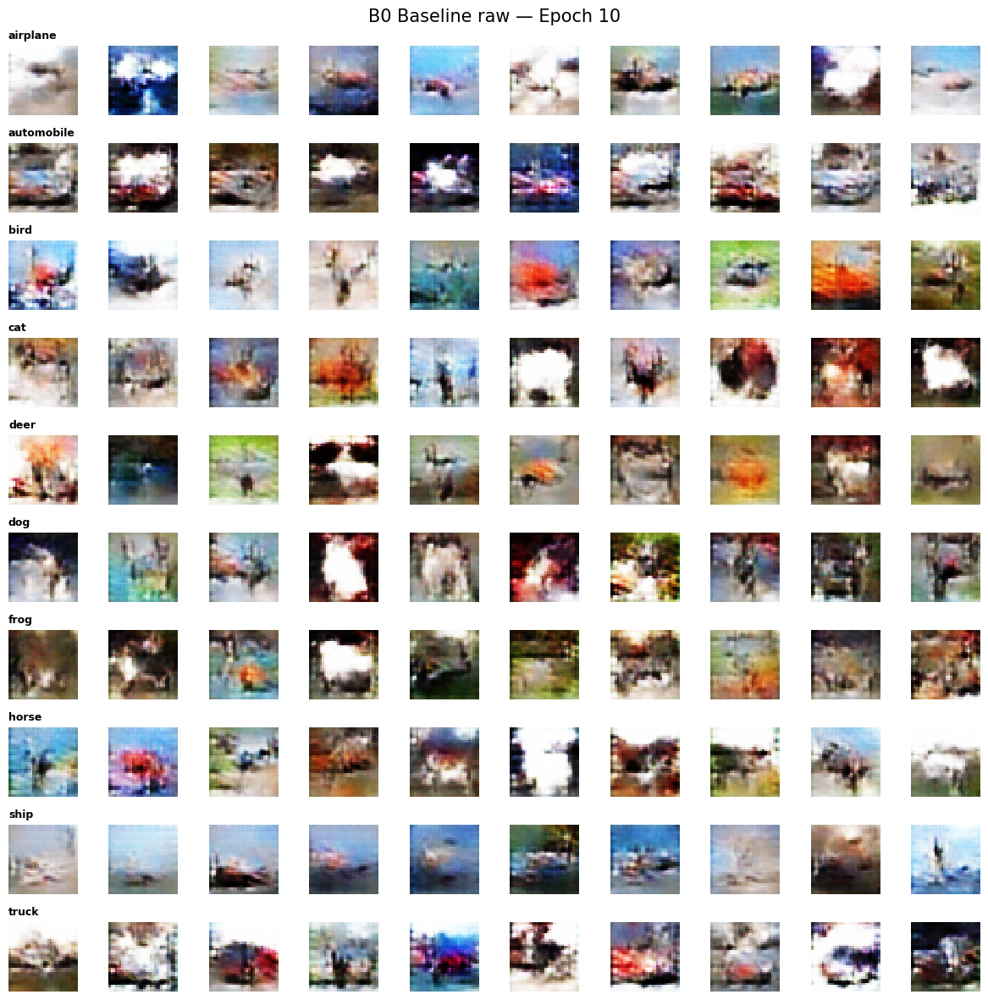

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_010.png
Epoch 011/100 | G 2.4128 | D 0.4716 | D(real) 0.8240 | D(fake) 0.1733 | D acc 0.9183 | 19.0s
Epoch 012/100 | G 2.3676 | D 0.5524 | D(real) 0.8099 | D(fake) 0.1880 | D acc 0.9036 | 18.9s
Epoch 013/100 | G 2.2972 | D 0.5033 | D(real) 0.8139 | D(fake) 0.1834 | D acc 0.9161 | 19.0s
Epoch 014/100 | G 2.3973 | D 0.4733 | D(real) 0.8234 | D(fake) 0.1742 | D acc 0.9238 | 19.2s
Epoch 015/100 | G 2.3446 | D 0.5730 | D(real) 0.8085 | D(fake) 0.1895 | D acc 0.9093 | 19.0s
Epoch 016/100 | G 2.3387 | D 0.5576 | D(real) 0.8095 | D(fake) 0.1881 | D acc 0.9085 | 19.2s
Epoch 017/100 | G 2.3510 | D 0.5040 | D(real) 0.8169 | D(fake) 0.1806 | D acc 0.9195 | 19.2s
Epoch 018/100 | G 2.3377 | D 0.5246 | D(real) 0.8128 | D(fake) 0.1841 | D acc 0.9147 | 19.5s
Epoch 019/100 | G 2.2881 | D 0.5308 | D(real) 0.8104 | D(fake) 0.1879 | D acc 0.9159 | 19.5s
Epoch 020/100 | G 2.1792 | D 0.5639 | D(real) 0.7979 | D(fake) 0.198

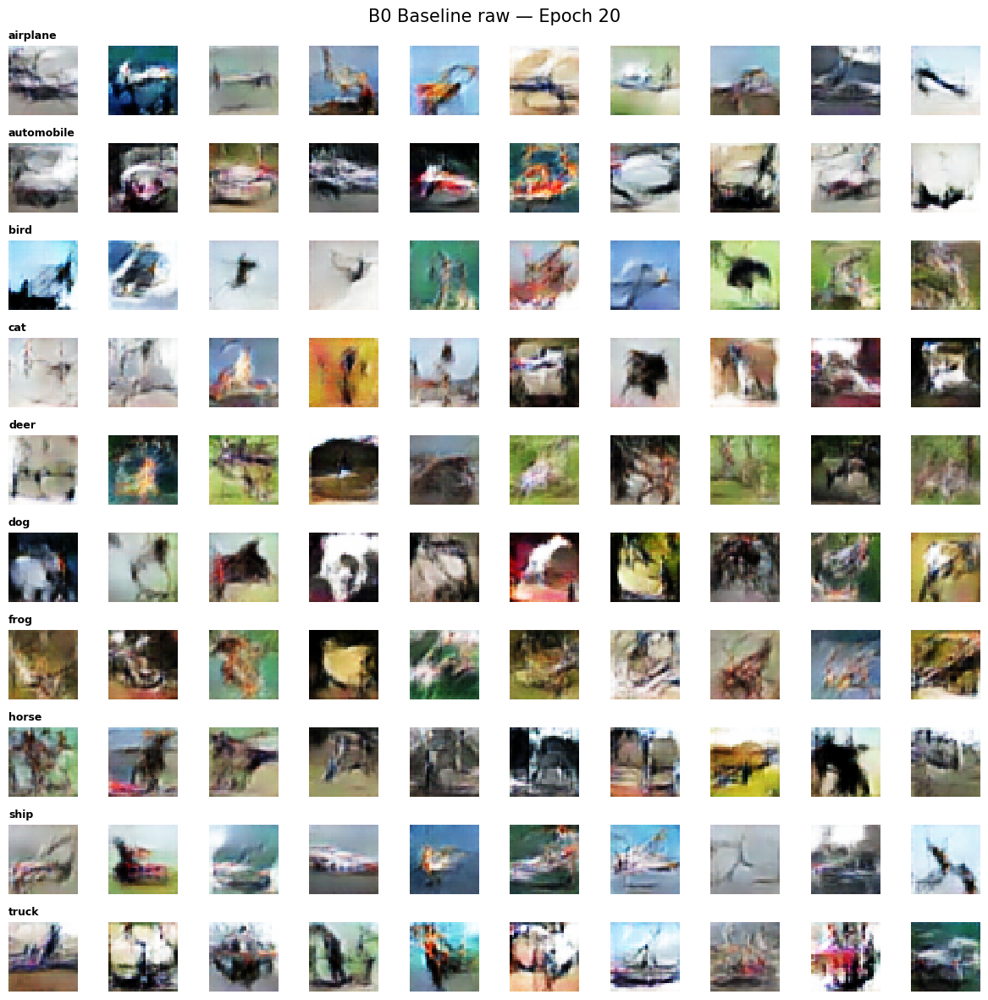

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_020.png
Epoch 021/100 | G 2.1951 | D 0.6332 | D(real) 0.7829 | D(fake) 0.2168 | D acc 0.8761 | 19.6s
Epoch 022/100 | G 2.1358 | D 0.5758 | D(real) 0.7909 | D(fake) 0.2064 | D acc 0.9014 | 19.3s
Epoch 023/100 | G 2.1573 | D 0.5547 | D(real) 0.7964 | D(fake) 0.2022 | D acc 0.9061 | 19.4s
Epoch 024/100 | G 2.0999 | D 0.5648 | D(real) 0.7898 | D(fake) 0.2074 | D acc 0.9010 | 19.5s
Epoch 025/100 | G 2.1491 | D 0.6062 | D(real) 0.7833 | D(fake) 0.2152 | D acc 0.8861 | 19.5s
Epoch 026/100 | G 2.1259 | D 0.5854 | D(real) 0.7896 | D(fake) 0.2093 | D acc 0.9002 | 19.4s
Epoch 027/100 | G 2.1217 | D 0.6027 | D(real) 0.7839 | D(fake) 0.2149 | D acc 0.8891 | 19.3s
Epoch 028/100 | G 2.1053 | D 0.5686 | D(real) 0.7885 | D(fake) 0.2090 | D acc 0.9011 | 19.4s
Epoch 029/100 | G 2.0884 | D 0.6469 | D(real) 0.7756 | D(fake) 0.2238 | D acc 0.8803 | 19.4s
Epoch 030/100 | G 2.0652 | D 0.5712 | D(real) 0.7876 | D(fake) 0.210

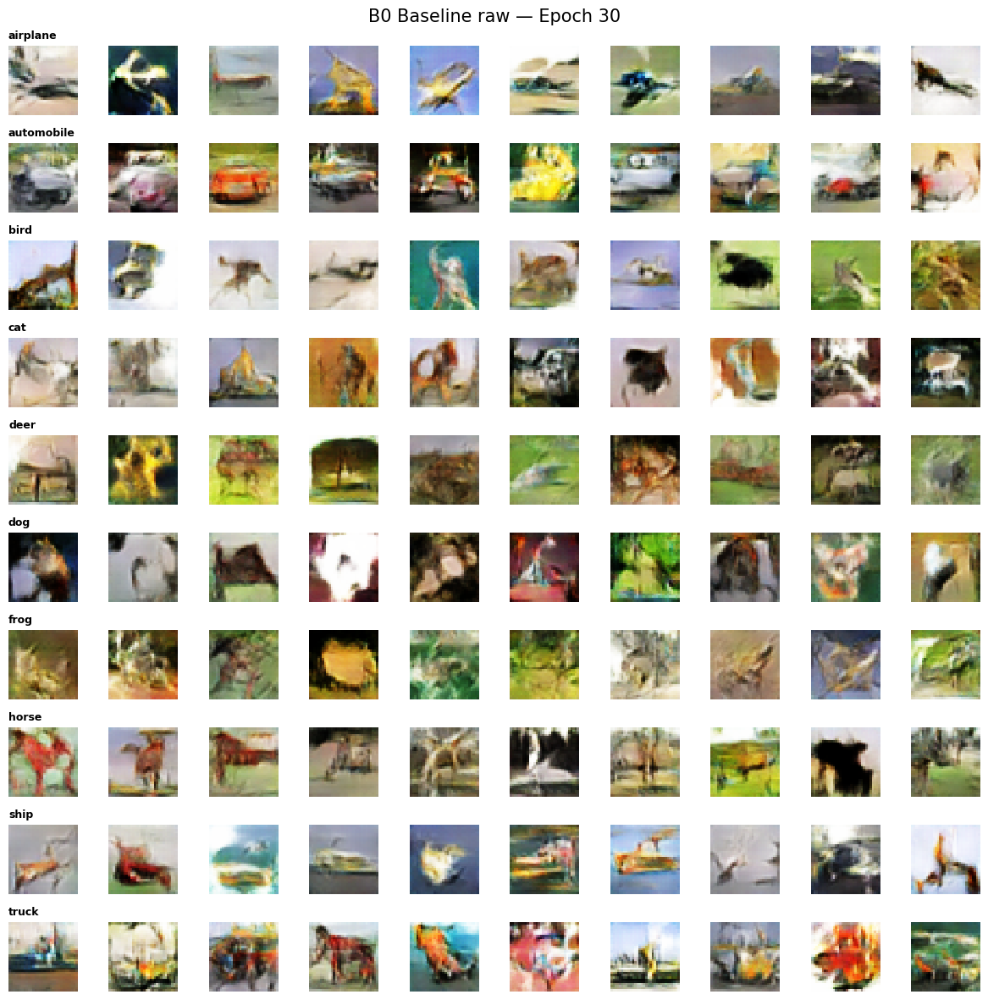

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_030.png
Epoch 031/100 | G 2.0531 | D 0.6265 | D(real) 0.7799 | D(fake) 0.2191 | D acc 0.8968 | 19.9s
Epoch 032/100 | G 2.0564 | D 0.6214 | D(real) 0.7771 | D(fake) 0.2208 | D acc 0.8894 | 19.8s
Epoch 033/100 | G 2.0635 | D 0.6164 | D(real) 0.7793 | D(fake) 0.2199 | D acc 0.8887 | 19.9s
Epoch 034/100 | G 2.0455 | D 0.5718 | D(real) 0.7849 | D(fake) 0.2128 | D acc 0.9027 | 19.8s
Epoch 035/100 | G 2.0437 | D 0.6896 | D(real) 0.7707 | D(fake) 0.2284 | D acc 0.8817 | 19.7s
Epoch 036/100 | G 2.0556 | D 0.5641 | D(real) 0.7880 | D(fake) 0.2108 | D acc 0.9076 | 19.6s
Epoch 037/100 | G 2.0817 | D 0.5790 | D(real) 0.7864 | D(fake) 0.2116 | D acc 0.9008 | 19.6s
Epoch 038/100 | G 2.1205 | D 0.6602 | D(real) 0.7786 | D(fake) 0.2211 | D acc 0.8885 | 19.5s
Epoch 039/100 | G 2.0878 | D 0.5973 | D(real) 0.7862 | D(fake) 0.2134 | D acc 0.9012 | 19.4s
Epoch 040/100 | G 2.1064 | D 0.5648 | D(real) 0.7903 | D(fake) 0.206

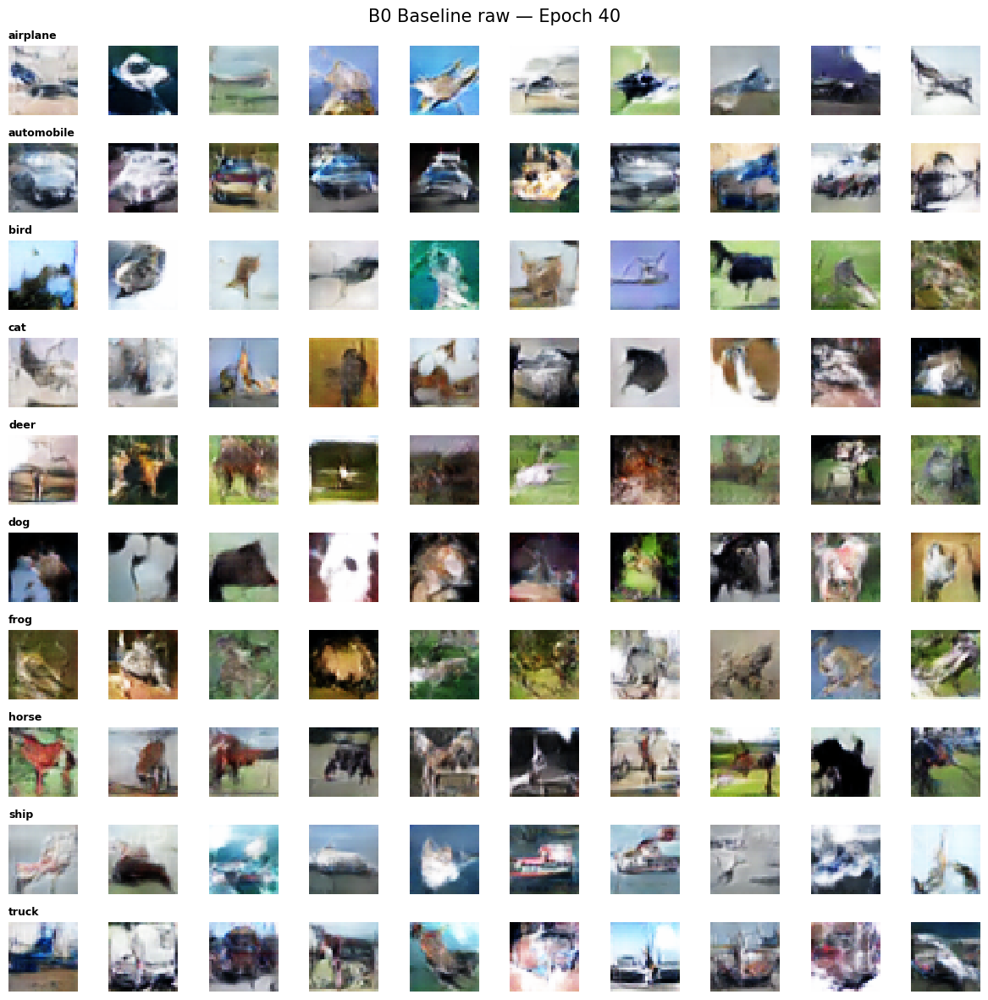

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_040.png
Epoch 041/100 | G 2.1271 | D 0.6338 | D(real) 0.7844 | D(fake) 0.2148 | D acc 0.8932 | 20.3s
Epoch 042/100 | G 2.0818 | D 0.5966 | D(real) 0.7858 | D(fake) 0.2134 | D acc 0.8966 | 19.6s
Epoch 043/100 | G 2.1708 | D 0.6016 | D(real) 0.7935 | D(fake) 0.2055 | D acc 0.9046 | 19.7s
Epoch 044/100 | G 2.1506 | D 0.5552 | D(real) 0.7969 | D(fake) 0.2021 | D acc 0.9091 | 19.5s
Epoch 045/100 | G 2.1976 | D 0.6658 | D(real) 0.7936 | D(fake) 0.2062 | D acc 0.9028 | 19.4s
Epoch 046/100 | G 2.1540 | D 0.5289 | D(real) 0.8031 | D(fake) 0.1950 | D acc 0.9243 | 19.4s
Epoch 047/100 | G 2.2351 | D 0.5043 | D(real) 0.8095 | D(fake) 0.1886 | D acc 0.9227 | 19.7s
Epoch 048/100 | G 2.2986 | D 0.5115 | D(real) 0.8152 | D(fake) 0.1844 | D acc 0.9258 | 19.6s
Epoch 049/100 | G 2.2925 | D 0.5745 | D(real) 0.8071 | D(fake) 0.1923 | D acc 0.9158 | 19.7s
Epoch 050/100 | G 2.3402 | D 0.4479 | D(real) 0.8272 | D(fake) 0.171

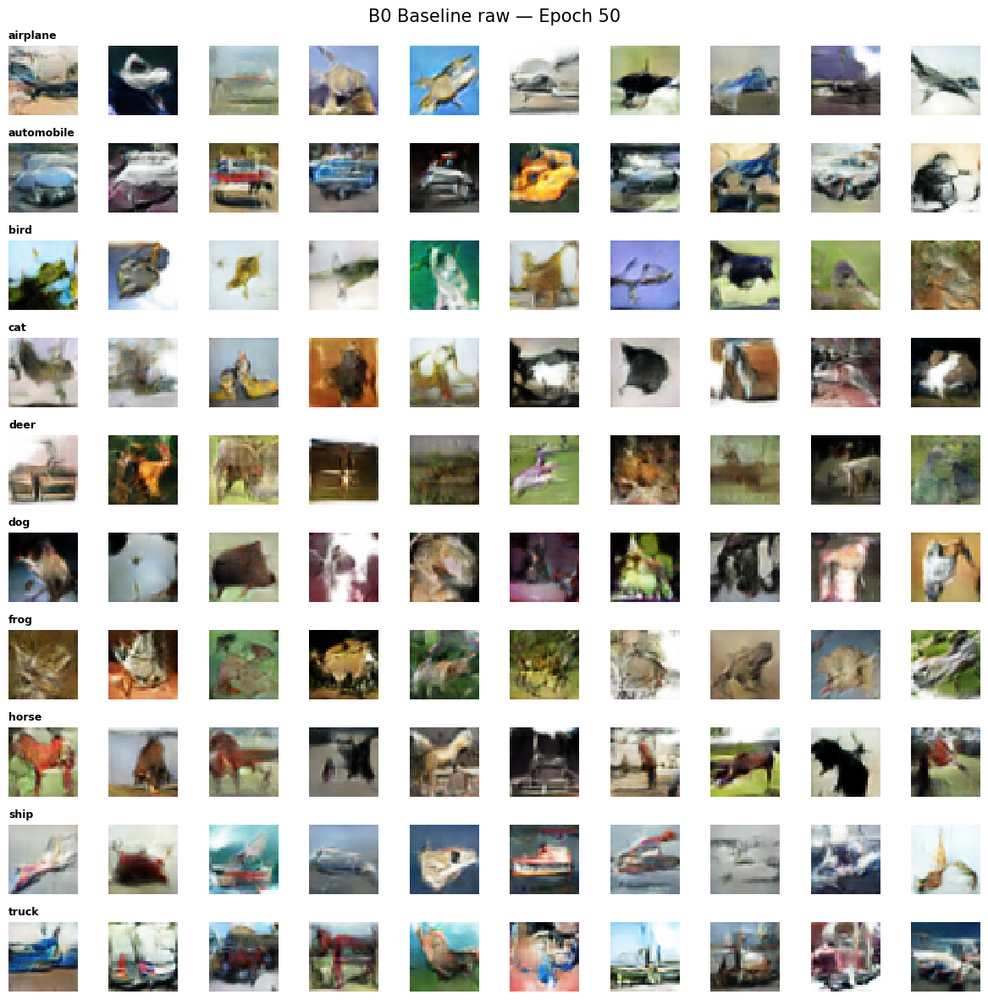

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_050.png
Epoch 051/100 | G 2.3119 | D 0.6067 | D(real) 0.8035 | D(fake) 0.1962 | D acc 0.9068 | 19.5s
Epoch 052/100 | G 2.3731 | D 0.4563 | D(real) 0.8264 | D(fake) 0.1726 | D acc 0.9334 | 19.7s
Epoch 053/100 | G 2.3828 | D 0.5198 | D(real) 0.8221 | D(fake) 0.1765 | D acc 0.9296 | 19.8s
Epoch 054/100 | G 2.4325 | D 0.4850 | D(real) 0.8268 | D(fake) 0.1726 | D acc 0.9305 | 19.9s
Epoch 055/100 | G 2.4709 | D 0.5311 | D(real) 0.8242 | D(fake) 0.1747 | D acc 0.9248 | 19.6s
Epoch 056/100 | G 2.4911 | D 0.4456 | D(real) 0.8373 | D(fake) 0.1621 | D acc 0.9409 | 19.4s
Epoch 057/100 | G 2.4664 | D 0.4932 | D(real) 0.8304 | D(fake) 0.1692 | D acc 0.9323 | 19.5s
Epoch 058/100 | G 2.5172 | D 0.4247 | D(real) 0.8393 | D(fake) 0.1594 | D acc 0.9409 | 19.5s
Epoch 059/100 | G 2.5800 | D 0.4982 | D(real) 0.8377 | D(fake) 0.1620 | D acc 0.9351 | 19.5s
Epoch 060/100 | G 2.5761 | D 0.4892 | D(real) 0.8381 | D(fake) 0.160

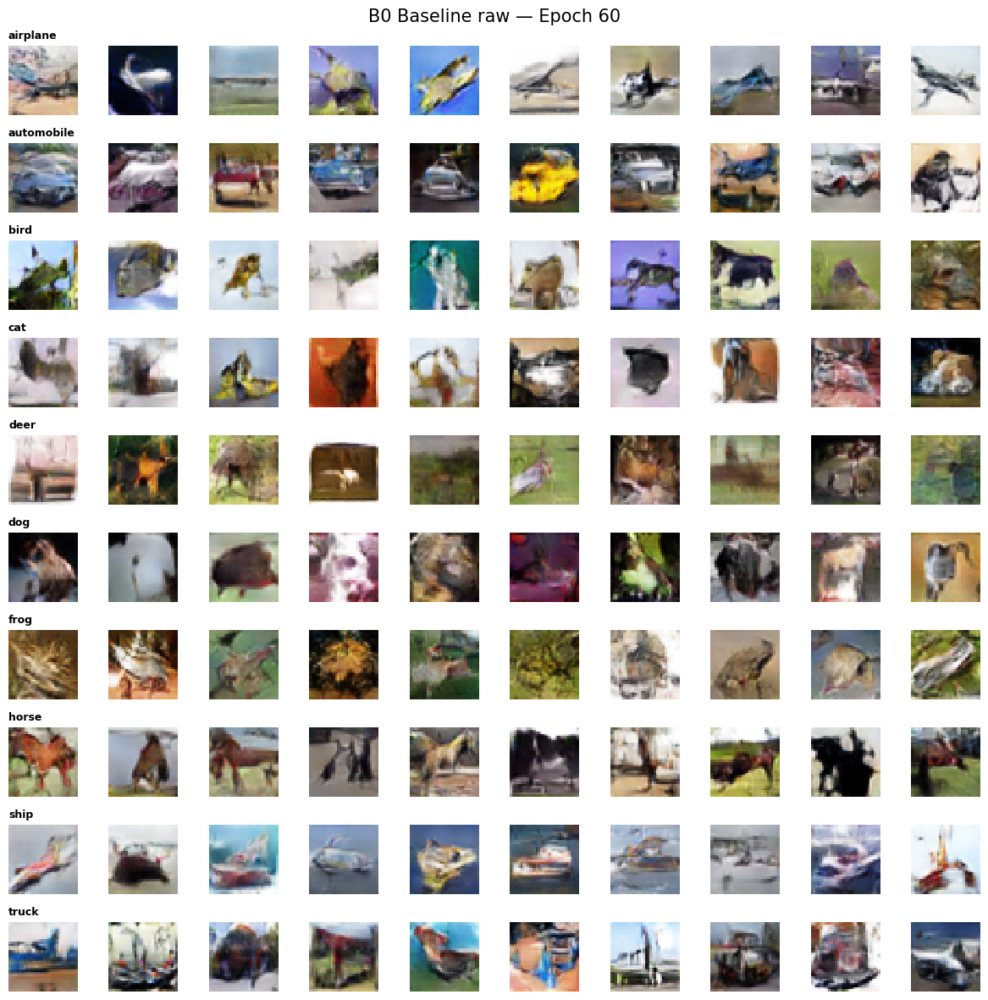

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_060.png
Epoch 061/100 | G 2.6212 | D 0.3347 | D(real) 0.8621 | D(fake) 0.1367 | D acc 0.9669 | 19.5s
Epoch 062/100 | G 2.6295 | D 0.4751 | D(real) 0.8420 | D(fake) 0.1572 | D acc 0.9386 | 19.4s
Epoch 063/100 | G 2.6802 | D 0.4089 | D(real) 0.8487 | D(fake) 0.1505 | D acc 0.9419 | 19.6s
Epoch 064/100 | G 2.7142 | D 0.4483 | D(real) 0.8511 | D(fake) 0.1481 | D acc 0.9434 | 19.6s
Epoch 065/100 | G 2.7125 | D 0.4200 | D(real) 0.8530 | D(fake) 0.1467 | D acc 0.9460 | 19.6s
Epoch 066/100 | G 2.7673 | D 0.4822 | D(real) 0.8498 | D(fake) 0.1497 | D acc 0.9376 | 20.1s
Epoch 067/100 | G 2.7667 | D 0.3128 | D(real) 0.8712 | D(fake) 0.1276 | D acc 0.9677 | 19.6s
Epoch 068/100 | G 2.7715 | D 0.5607 | D(real) 0.8412 | D(fake) 0.1581 | D acc 0.9270 | 20.1s
Epoch 069/100 | G 2.7893 | D 0.4405 | D(real) 0.8586 | D(fake) 0.1406 | D acc 0.9471 | 19.7s
Epoch 070/100 | G 2.7935 | D 0.2939 | D(real) 0.8773 | D(fake) 0.121

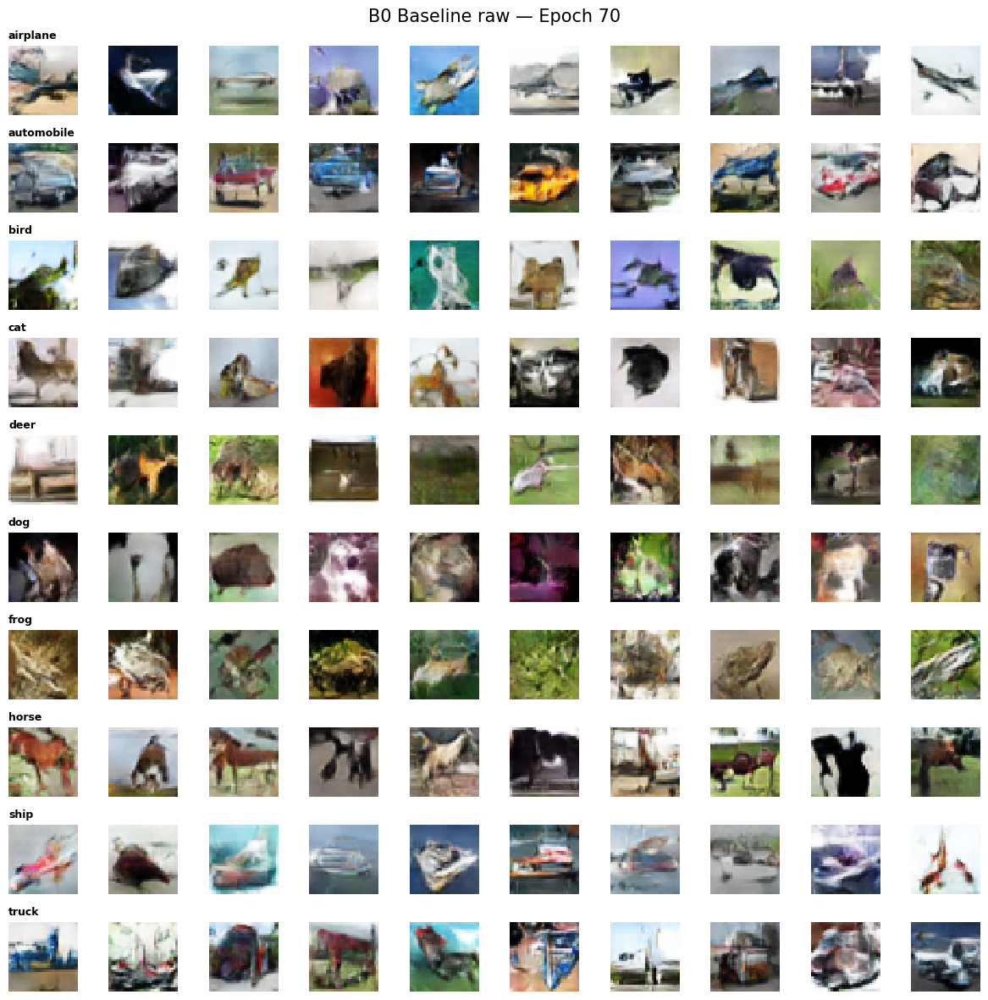

Epoch 074/100 | G 2.9257 | D 0.3681 | D(real) 0.8730 | D(fake) 0.1263 | D acc 0.9588 | 19.9s
Epoch 075/100 | G 2.9269 | D 0.4291 | D(real) 0.8704 | D(fake) 0.1292 | D acc 0.9557 | 20.2s
Epoch 076/100 | G 3.0141 | D 0.4226 | D(real) 0.8706 | D(fake) 0.1286 | D acc 0.9495 | 20.5s
Epoch 077/100 | G 3.0247 | D 0.3746 | D(real) 0.8840 | D(fake) 0.1153 | D acc 0.9676 | 19.9s
Epoch 078/100 | G 2.9071 | D 0.3112 | D(real) 0.8775 | D(fake) 0.1224 | D acc 0.9634 | 19.7s
Epoch 079/100 | G 3.0410 | D 0.4545 | D(real) 0.8689 | D(fake) 0.1300 | D acc 0.9475 | 19.9s
Epoch 080/100 | G 3.0738 | D 0.2405 | D(real) 0.8981 | D(fake) 0.1015 | D acc 0.9818 | 19.9s
Saved checkpoint: HeinHtetPartA_outputs\B0_baseline\checkpoints\ckpt-80


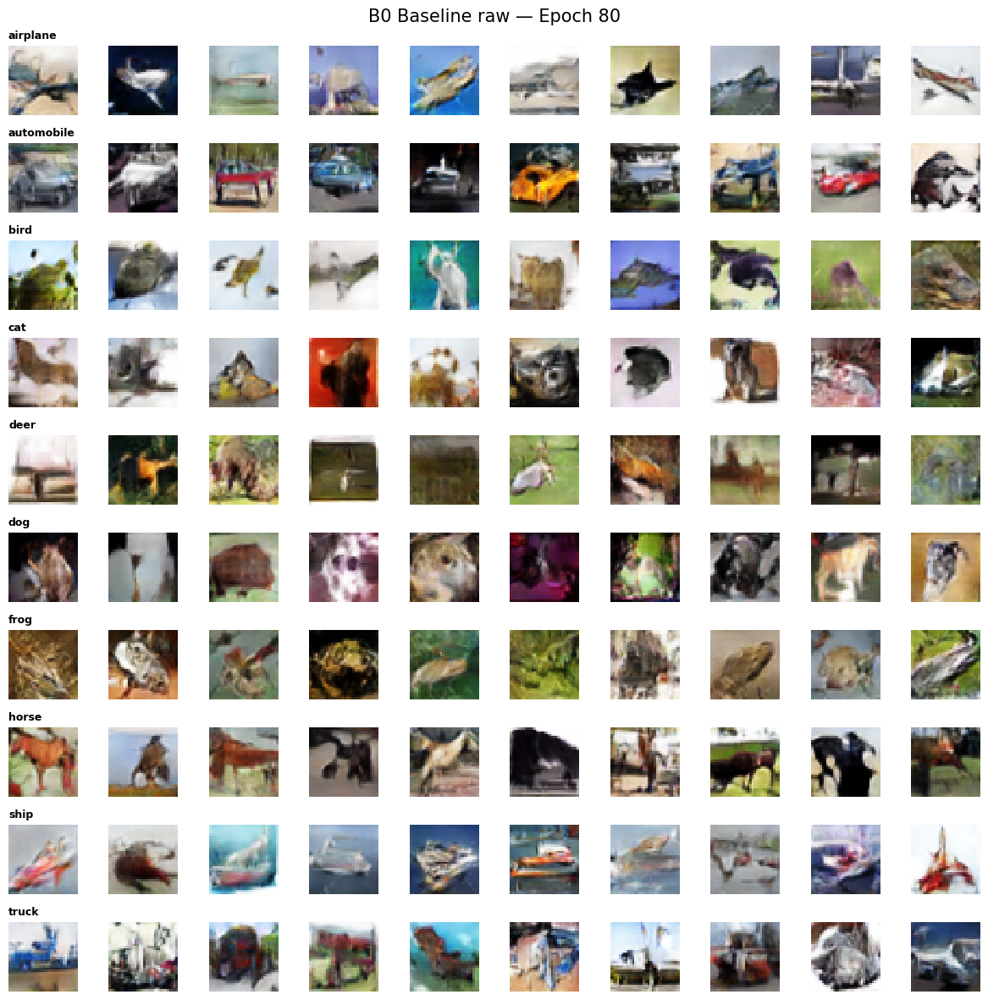

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_080.png
Epoch 081/100 | G 3.0701 | D 0.3839 | D(real) 0.8732 | D(fake) 0.1264 | D acc 0.9508 | 19.7s
Epoch 082/100 | G 3.0311 | D 0.5409 | D(real) 0.8627 | D(fake) 0.1370 | D acc 0.9359 | 19.9s
Epoch 083/100 | G 3.1059 | D 0.2319 | D(real) 0.9011 | D(fake) 0.0982 | D acc 0.9831 | 19.6s
Epoch 084/100 | G 2.7876 | D 0.8254 | D(real) 0.8098 | D(fake) 0.1901 | D acc 0.8750 | 19.8s
Epoch 085/100 | G 3.0336 | D 0.2381 | D(real) 0.8977 | D(fake) 0.1012 | D acc 0.9844 | 20.0s
Epoch 086/100 | G 3.0579 | D 0.3457 | D(real) 0.8806 | D(fake) 0.1192 | D acc 0.9600 | 19.9s
Epoch 087/100 | G 3.1019 | D 0.4046 | D(real) 0.8751 | D(fake) 0.1242 | D acc 0.9484 | 19.8s
Epoch 088/100 | G 3.1948 | D 0.2139 | D(real) 0.9081 | D(fake) 0.0917 | D acc 0.9859 | 19.7s
Epoch 089/100 | G 3.1259 | D 0.4097 | D(real) 0.8765 | D(fake) 0.1228 | D acc 0.9498 | 19.7s
Epoch 090/100 | G 3.2037 | D 0.3483 | D(real) 0.8866 | D(fake) 0.112

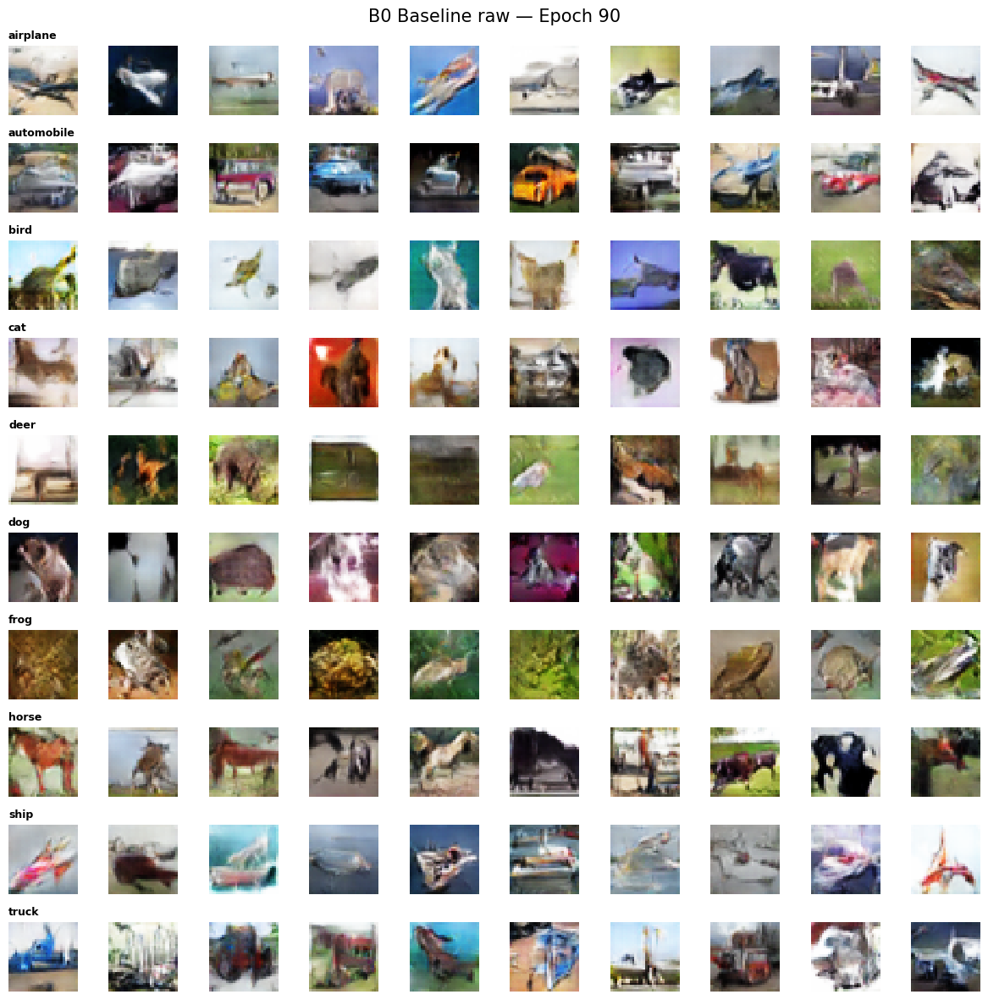

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_090.png
Epoch 091/100 | G 3.2308 | D 0.3514 | D(real) 0.8816 | D(fake) 0.1178 | D acc 0.9500 | 19.6s
Epoch 092/100 | G 3.1734 | D 0.4299 | D(real) 0.8800 | D(fake) 0.1205 | D acc 0.9515 | 19.5s
Epoch 093/100 | G 3.2129 | D 0.2202 | D(real) 0.9054 | D(fake) 0.0928 | D acc 0.9844 | 19.6s
Epoch 094/100 | G 3.2752 | D 0.2725 | D(real) 0.8980 | D(fake) 0.1025 | D acc 0.9681 | 19.6s
Epoch 095/100 | G 3.2289 | D 0.3764 | D(real) 0.8859 | D(fake) 0.1129 | D acc 0.9571 | 19.5s
Epoch 096/100 | G 3.3853 | D 0.3505 | D(real) 0.8969 | D(fake) 0.1034 | D acc 0.9617 | 19.9s
Epoch 097/100 | G 3.3465 | D 0.3047 | D(real) 0.8969 | D(fake) 0.1023 | D acc 0.9645 | 19.8s
Epoch 098/100 | G 3.3751 | D 0.1967 | D(real) 0.9152 | D(fake) 0.0840 | D acc 0.9869 | 19.7s
Epoch 099/100 | G 3.2836 | D 0.4494 | D(real) 0.8760 | D(fake) 0.1237 | D acc 0.9408 | 19.7s
Epoch 100/100 | G 3.3078 | D 0.3983 | D(real) 0.8856 | D(fake) 0.114

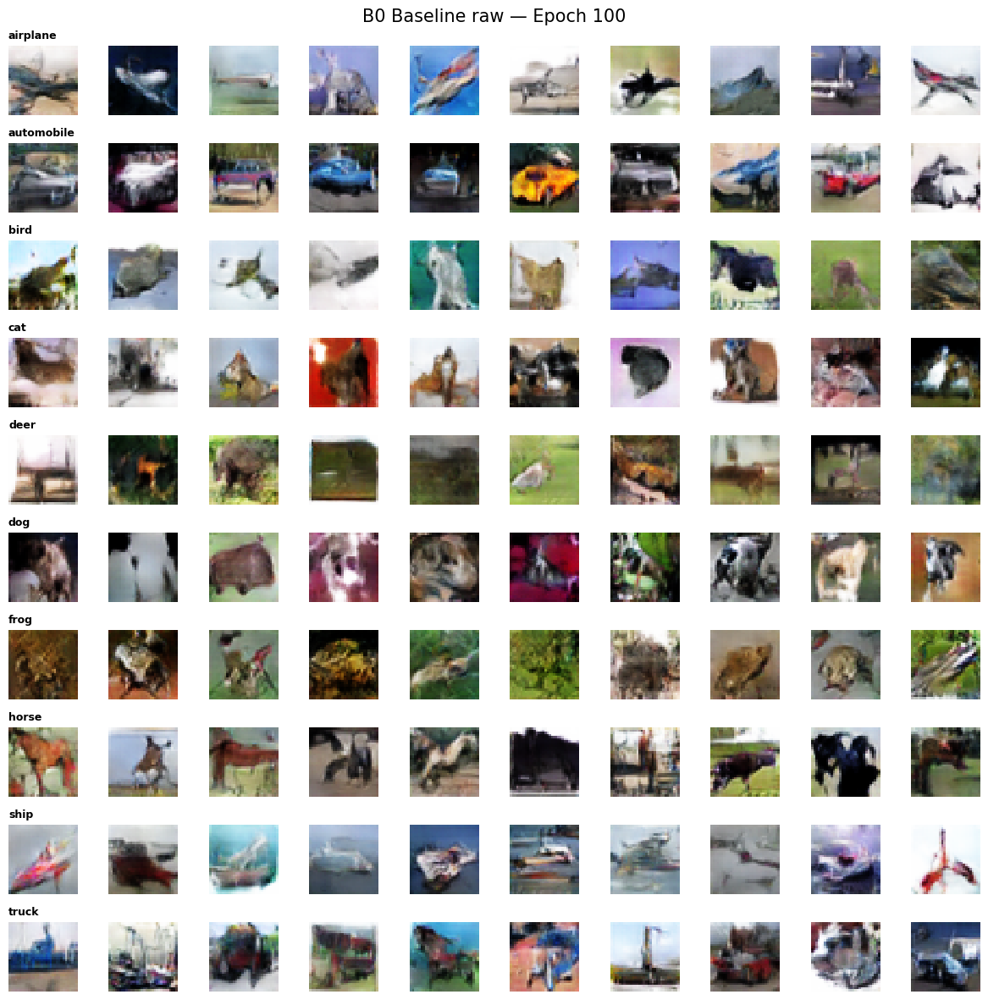

Saved grid: HeinHtetPartA_outputs\B0_baseline\generated_grids_raw\generated_grid_epoch_100.png
Completed B0 Baseline: 100 epochs recorded.


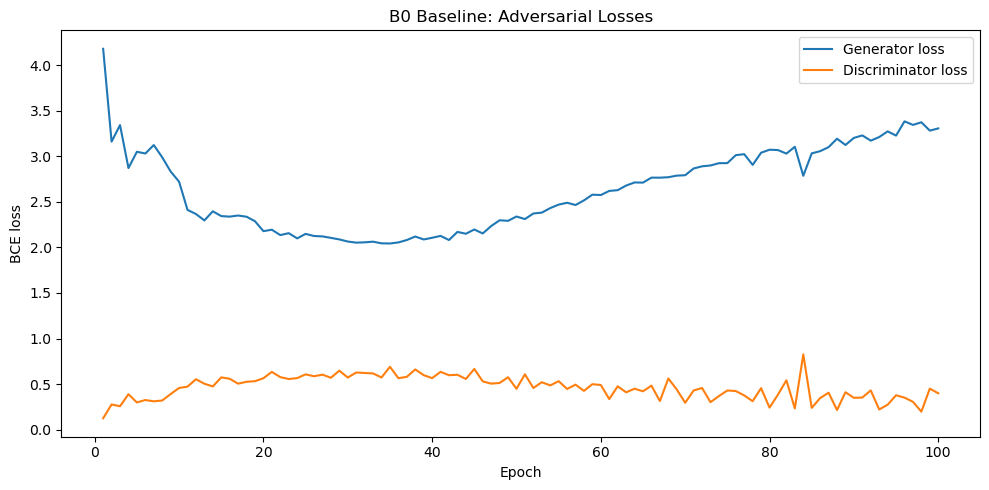

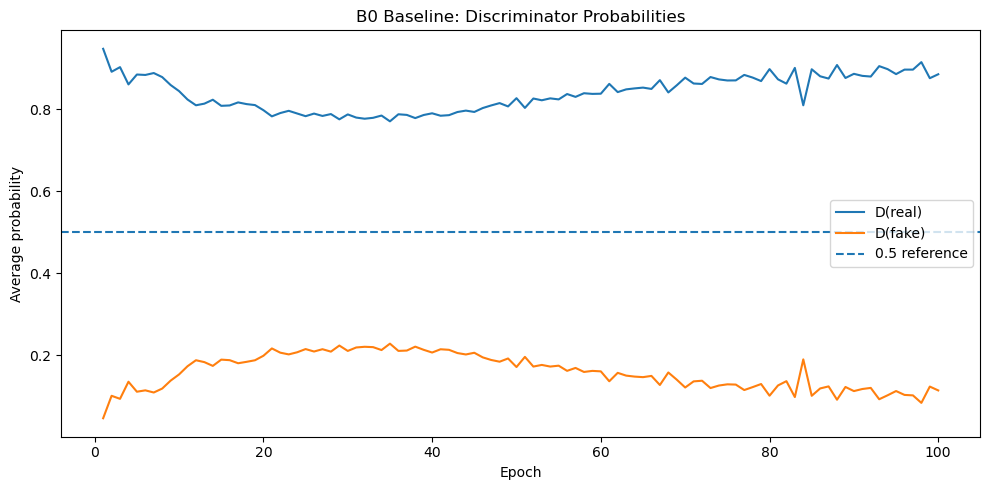

In [39]:
B0_RESULT = execute_fresh_experiment(
    run_name="B0_baseline",
    run_label="B0 Baseline",
    augmentation_function=identity_policy,
)


### B0 Training Assessment

B0 is the non-augmented conditional DCGAN baseline. Training remained
numerically stable for all 100 epochs, with finite generator and discriminator
losses and no sudden divergence.

The generator loss decreased sharply during the early stages of training,
falling from approximately 4.2 to around 2.0 by the middle of the run. This
indicates that the generator initially became more successful at producing
images that could challenge the discriminator. After approximately epoch 40,
the generator loss gradually increased and ended at around 3.3. This suggests
that the discriminator became increasingly difficult to fool during the later
stages of training.

The discriminator loss increased during the early epochs before stabilising
mostly between approximately 0.3 and 0.6. The discriminator probabilities
provide further evidence of this imbalance. Throughout most of the run,
`D(real)` remained high at approximately 0.78 to 0.90, while `D(fake)` remained
low and declined to approximately 0.10 near the end of training. Therefore,
the discriminator was generally stronger than the generator and became more
confident at separating real and generated images during the later epochs.

Although the adversarial game was not perfectly balanced, the curves remained
stable and did not show an obvious training collapse. The saved class-balanced
grids also showed progression from poorly structured early outputs toward more
recognisable class-dependent images. Vehicle classes generally displayed
clearer silhouettes, while visually similar animal classes remained more
blurred and ambiguous at the `32 × 32` resolution.

The loss values alone were not used to select the final B0 checkpoint because
GAN losses do not directly measure generated-image quality. Checkpoint selection
was instead performed manually using FID as the primary metric and KID as
supporting evidence. Visual inspection was used only as a verification step to
ensure that the selected quantitative result was not associated with severe mode
collapse, obvious artefacts or loss of class recognisability.

#### B0 FID/KID Evaluation — Run After B0 Training


Loading InceptionV3 for FID/KID evaluation...
Saved real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B0: epoch 10, raw...
Epoch 010 | raw | FID 115.4572 | KID 0.093037 ± 0.006093
Evaluating B0: epoch 20, raw...
Epoch 020 | raw | FID 65.8842 | KID 0.041301 ± 0.004600
Evaluating B0: epoch 30, raw...
Epoch 030 | raw | FID 54.0379 | KID 0.029529 ± 0.004619
Evaluating B0: epoch 40, raw...
Epoch 040 | raw | FID 54.2456 | KID 0.030553 ± 0.003932
Evaluating B0: epoch 50, raw...
Epoch 050 | raw | FID 46.6291 | KID 0.022650 ± 0.003794
Evaluating B0: epoch 60, raw...
Epoch 060 | raw | FID 43.8061 | KID 0.021033 ± 0.003892
Evaluating B0: epoch 70, raw...
Epoch 070 | raw | FID 43.1193 | KID 0.020370 ± 0.003706
Evaluating B0: epoch 80, raw...
Epoch 080 | raw | FID 41.6952 | KID 0.019938 ± 0.004004
Evaluating B0: epoch 90, raw...
Epoch 090 | raw | FID 41.2569 | KID 0.019602 ± 0.003938
Eva

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B0,B0_baseline,10,raw,115.4572,0.093037,0.006093,5000
1,B0,B0_baseline,20,raw,65.8842,0.041301,0.004600,5000
2,B0,B0_baseline,30,raw,54.0379,0.029529,0.004619,5000
3,B0,B0_baseline,40,raw,54.2456,0.030553,0.003932,5000
4,B0,B0_baseline,50,raw,46.6291,0.022650,0.003794,5000
5,B0,B0_baseline,60,raw,43.8061,0.021033,0.003892,5000
6,B0,B0_baseline,70,raw,43.1193,0.020370,0.003706,5000
7,B0,B0_baseline,80,raw,41.6952,0.019938,0.004004,5000
8,B0,B0_baseline,90,raw,41.2569,0.019602,0.003938,5000
9,B0,B0_baseline,100,raw,40.6290,0.018764,0.003678,5000


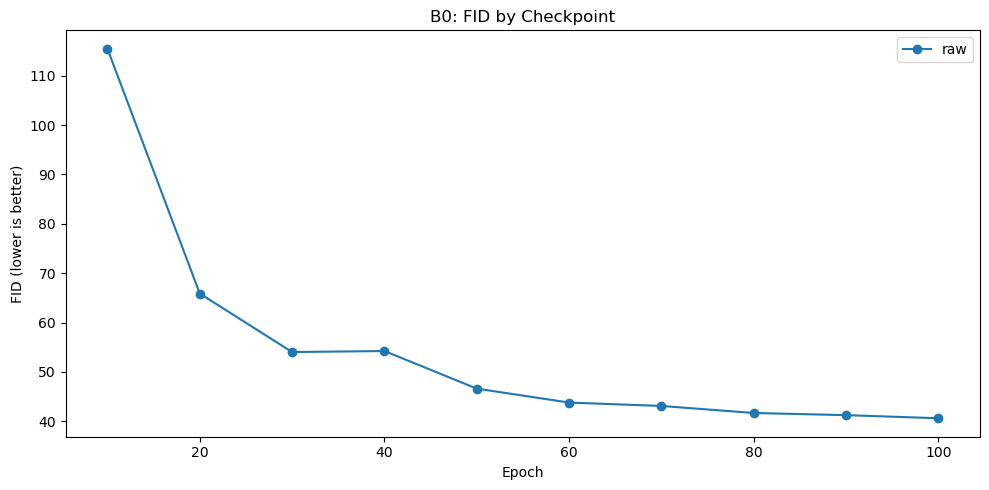

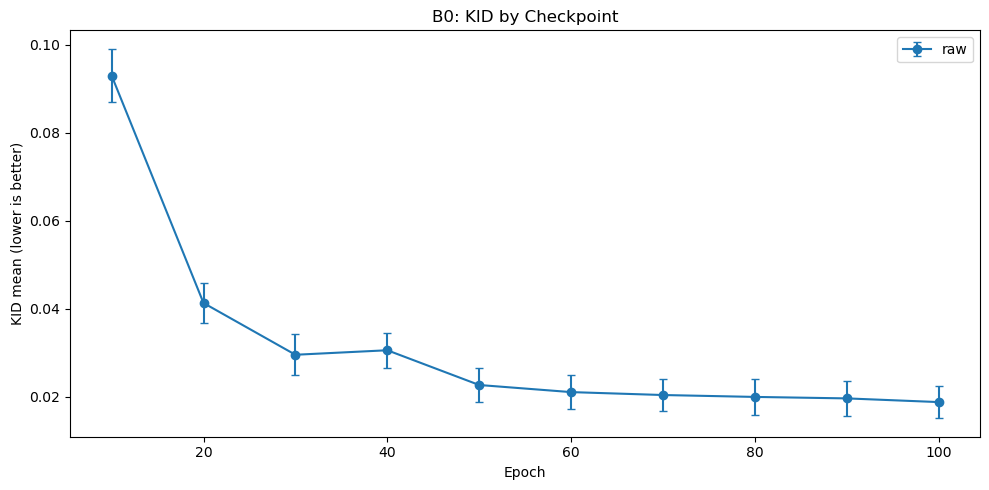

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B0_baseline\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [40]:
B0_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B0",
    run_name="B0_baseline",
    candidates=("raw",),
    expected_epochs=range(10, 101, 10),
)


## B0 Review

- **Chosen epoch:** 100
- **FID:** 40.6290
- **KID mean ± standard deviation:** 0.018764 ± 0.003678
- **Decision:** Retained as the best B0 baseline checkpoint.

### Selection Reasoning

Epoch 100 was selected manually because it achieved the lowest FID among
the evaluated B0 checkpoints. FID was treated as the primary checkpoint
selection metric because it measures the overall difference between the real
and generated image feature distributions, with a lower value indicating a
closer match.

KID was used as a supporting metric. Epoch 100 also achieved the lowest KID
mean for B0, which supports the FID-based selection. Both metrics generally
improved as training progressed, although the improvements became smaller
during the later epochs. This suggests that the baseline model was beginning
to converge rather than continuing to make large improvements.

The saved class grid for epoch 100 was inspected only as a verification step.
The purpose of this visual check was to ensure that the quantitative result was
not associated with an obvious failure such as severe mode collapse, major
artefacts or complete loss of class recognisability. The visual inspection was
consistent with the FID and KID findings and did not provide a reason to reject
epoch 100.

Visual inspection was therefore used to support the quantitative evidence,
rather than as the main method for selecting the checkpoint.

- **Visual label counts:** Not completed at this stage because the full
  clear/marginal/nonsense assessment was reserved for the strongest final
  candidates.
- **Requested-class match observations:** The class-balanced grid was checked
  for general conditional consistency, but detailed requested-class matching
  was reserved for the final shortlisted models.

### 8.2 B1 — Reduced Discriminator Learning Rate

The B0 diagnostics indicated that the discriminator became stronger relative to
the generator during later training. B1 tests whether reducing only the
discriminator learning rate from `0.0002` to `0.0001` improves the adversarial
balance. The generator learning rate remains `0.0002`.

The Two Time-Scale Update Rule establishes that generator and discriminator
learning rates may be treated separately rather than assumed to be identical
(Heusel et al., 2017). It does not prescribe `0.0001` for this model, so the value remains a
controlled experimental hypothesis.

All other settings, including the architecture, dataset split, normalisation,
batch size, latent dimension, loss function, random seed, training budget and
evaluation procedure, remain unchanged from B0.


Epoch 001/100 | G 2.4729 | D 0.3370 | D(real) 0.8623 | D(fake) 0.1290 | D acc 0.9516 | 20.6s
Epoch 002/100 | G 2.0080 | D 0.4859 | D(real) 0.8024 | D(fake) 0.1781 | D acc 0.9340 | 18.6s
Epoch 003/100 | G 1.9778 | D 0.4866 | D(real) 0.8052 | D(fake) 0.1864 | D acc 0.9368 | 18.7s
Epoch 004/100 | G 2.0593 | D 0.4932 | D(real) 0.8090 | D(fake) 0.1871 | D acc 0.9270 | 18.9s
Epoch 005/100 | G 2.0905 | D 0.4891 | D(real) 0.8099 | D(fake) 0.1852 | D acc 0.9268 | 18.6s
Epoch 006/100 | G 2.2308 | D 0.4427 | D(real) 0.8260 | D(fake) 0.1684 | D acc 0.9395 | 18.7s
Epoch 007/100 | G 2.2286 | D 0.4297 | D(real) 0.8296 | D(fake) 0.1664 | D acc 0.9432 | 18.8s
Epoch 008/100 | G 2.2210 | D 0.4448 | D(real) 0.8271 | D(fake) 0.1717 | D acc 0.9365 | 19.0s
Epoch 009/100 | G 2.2499 | D 0.4523 | D(real) 0.8254 | D(fake) 0.1725 | D acc 0.9306 | 19.0s
Epoch 010/100 | G 2.2904 | D 0.4556 | D(real) 0.8244 | D(fake) 0.1726 | D acc 0.9284 | 19.1s
Saved checkpoint: HeinHtetPartA_outputs\B1_lower_discriminator_lr\chec

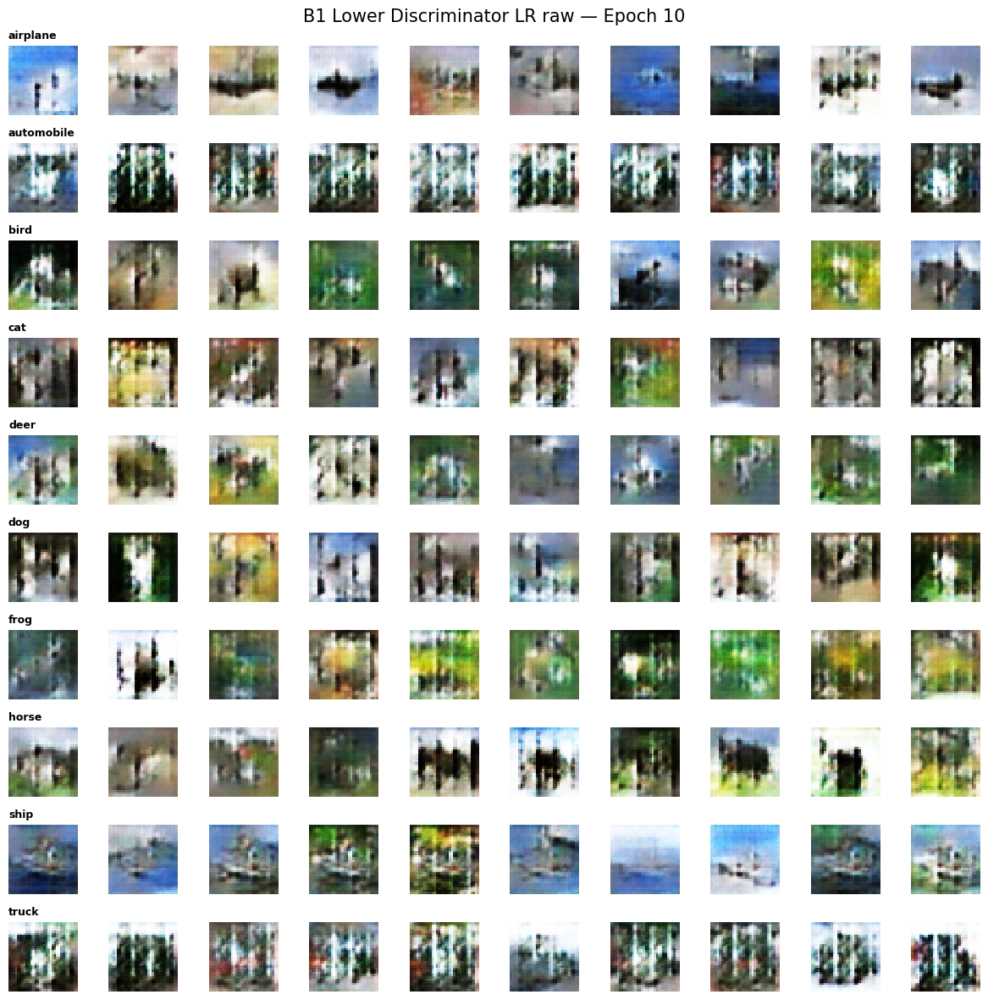

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_010.png
Epoch 011/100 | G 2.0963 | D 0.5452 | D(real) 0.8004 | D(fake) 0.1974 | D acc 0.9125 | 19.4s
Epoch 012/100 | G 1.9420 | D 0.5765 | D(real) 0.7816 | D(fake) 0.2152 | D acc 0.9014 | 19.2s
Epoch 013/100 | G 1.8232 | D 0.6495 | D(real) 0.7629 | D(fake) 0.2338 | D acc 0.8905 | 19.2s
Epoch 014/100 | G 1.8109 | D 0.6583 | D(real) 0.7571 | D(fake) 0.2401 | D acc 0.8801 | 19.2s
Epoch 015/100 | G 1.8013 | D 0.6441 | D(real) 0.7614 | D(fake) 0.2363 | D acc 0.8957 | 19.4s
Epoch 016/100 | G 1.8784 | D 0.6499 | D(real) 0.7672 | D(fake) 0.2310 | D acc 0.8918 | 19.4s
Epoch 017/100 | G 1.8818 | D 0.6076 | D(real) 0.7697 | D(fake) 0.2273 | D acc 0.8961 | 19.4s
Epoch 018/100 | G 1.8457 | D 0.6210 | D(real) 0.7642 | D(fake) 0.2325 | D acc 0.8937 | 19.5s
Epoch 019/100 | G 1.7571 | D 0.6535 | D(real) 0.7533 | D(fake) 0.2440 | D acc 0.8869 | 19.6s
Epoch 020/100 | G 1.8174 | D 0.6612 | D(real) 0.7540 |

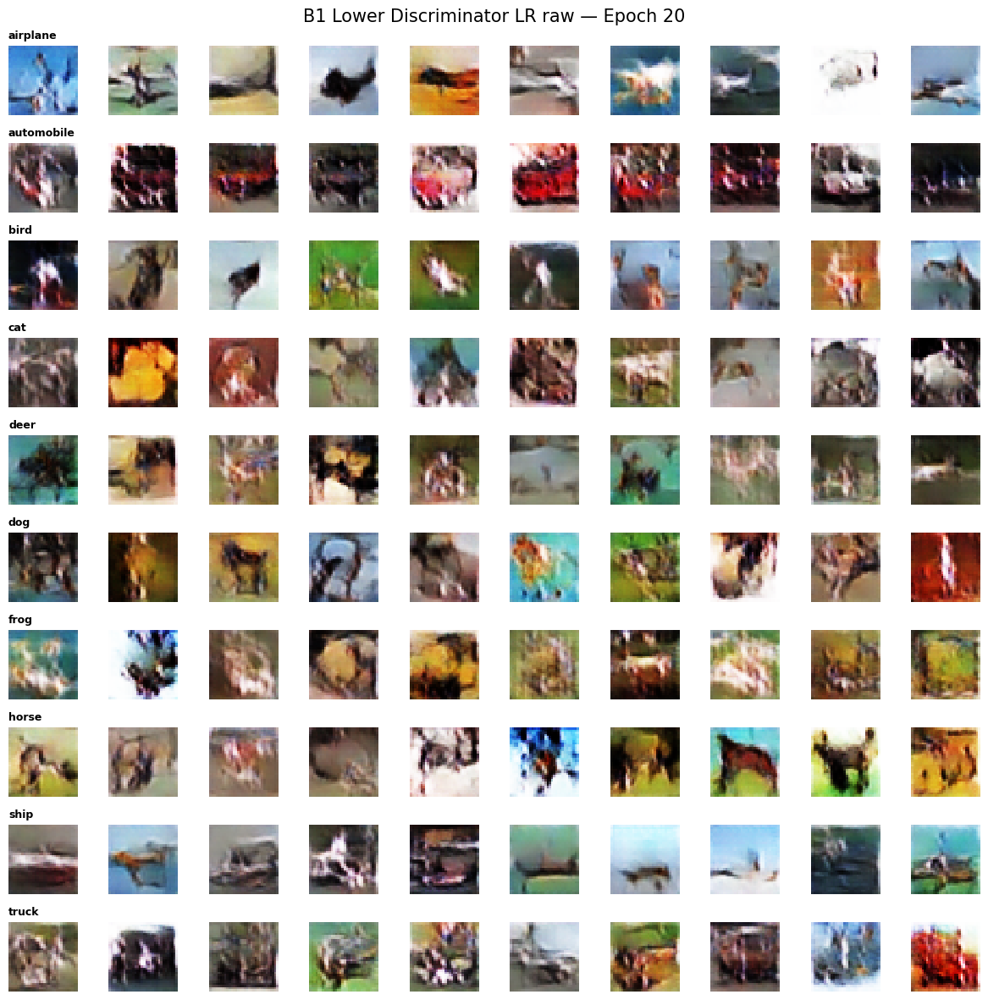

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_020.png
Epoch 021/100 | G 1.7469 | D 0.7044 | D(real) 0.7460 | D(fake) 0.2520 | D acc 0.8785 | 19.3s
Epoch 022/100 | G 1.7224 | D 0.6729 | D(real) 0.7473 | D(fake) 0.2501 | D acc 0.8862 | 19.3s
Epoch 023/100 | G 1.7529 | D 0.6955 | D(real) 0.7462 | D(fake) 0.2522 | D acc 0.8745 | 19.4s
Epoch 024/100 | G 1.6996 | D 0.6824 | D(real) 0.7435 | D(fake) 0.2540 | D acc 0.8826 | 19.4s
Epoch 025/100 | G 1.7611 | D 0.6640 | D(real) 0.7505 | D(fake) 0.2477 | D acc 0.8820 | 19.7s
Epoch 026/100 | G 1.7328 | D 0.6588 | D(real) 0.7506 | D(fake) 0.2478 | D acc 0.8868 | 19.5s
Epoch 027/100 | G 1.7210 | D 0.7005 | D(real) 0.7417 | D(fake) 0.2561 | D acc 0.8746 | 20.1s
Epoch 028/100 | G 1.7192 | D 0.6836 | D(real) 0.7445 | D(fake) 0.2540 | D acc 0.8754 | 19.7s
Epoch 029/100 | G 1.7525 | D 0.7060 | D(real) 0.7422 | D(fake) 0.2562 | D acc 0.8653 | 19.5s
Epoch 030/100 | G 1.6885 | D 0.7210 | D(real) 0.7362 |

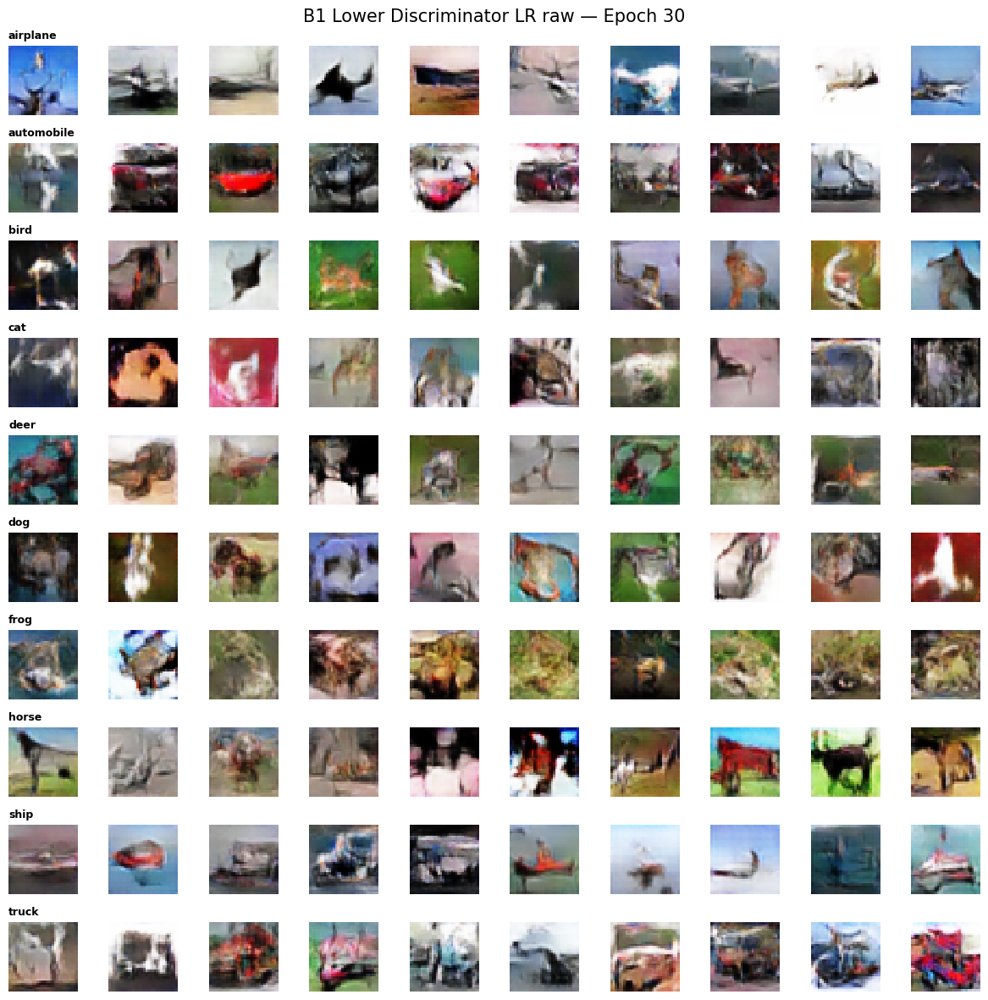

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_030.png
Epoch 031/100 | G 1.6842 | D 0.6555 | D(real) 0.7476 | D(fake) 0.2506 | D acc 0.8943 | 19.4s
Epoch 032/100 | G 1.6927 | D 0.7404 | D(real) 0.7329 | D(fake) 0.2651 | D acc 0.8659 | 19.4s
Epoch 033/100 | G 1.6968 | D 0.6908 | D(real) 0.7426 | D(fake) 0.2565 | D acc 0.8833 | 19.9s
Epoch 034/100 | G 1.6705 | D 0.7408 | D(real) 0.7338 | D(fake) 0.2649 | D acc 0.8700 | 19.4s
Epoch 035/100 | G 1.6600 | D 0.6711 | D(real) 0.7428 | D(fake) 0.2553 | D acc 0.8905 | 19.5s
Epoch 036/100 | G 1.6953 | D 0.7548 | D(real) 0.7325 | D(fake) 0.2661 | D acc 0.8651 | 19.6s
Epoch 037/100 | G 1.6376 | D 0.7333 | D(real) 0.7333 | D(fake) 0.2654 | D acc 0.8773 | 19.6s
Epoch 038/100 | G 1.6646 | D 0.7040 | D(real) 0.7384 | D(fake) 0.2608 | D acc 0.8809 | 19.8s
Epoch 039/100 | G 1.6627 | D 0.7194 | D(real) 0.7353 | D(fake) 0.2628 | D acc 0.8789 | 19.6s
Epoch 040/100 | G 1.6878 | D 0.7293 | D(real) 0.7336 |

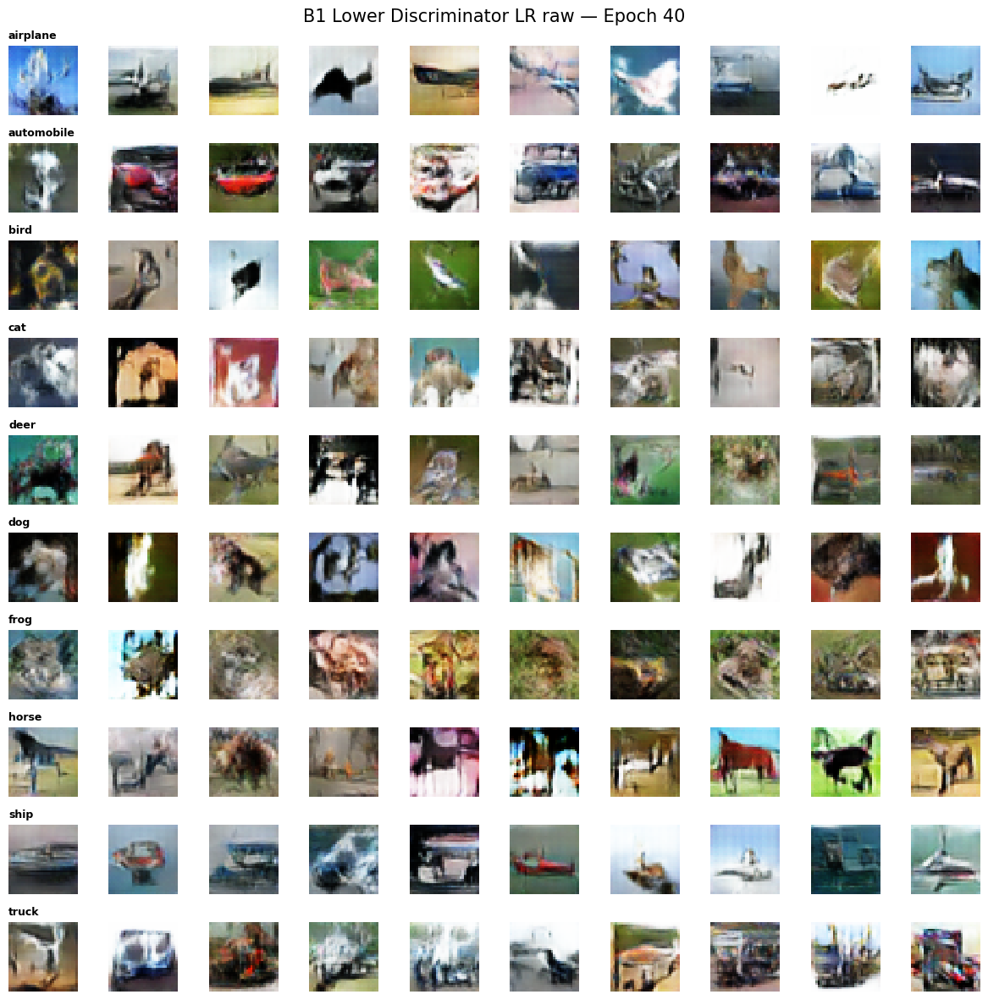

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_040.png
Epoch 041/100 | G 1.6594 | D 0.7117 | D(real) 0.7361 | D(fake) 0.2632 | D acc 0.8752 | 19.9s
Epoch 042/100 | G 1.6757 | D 0.7305 | D(real) 0.7361 | D(fake) 0.2631 | D acc 0.8737 | 20.0s
Epoch 043/100 | G 1.6646 | D 0.7276 | D(real) 0.7401 | D(fake) 0.2602 | D acc 0.8857 | 19.5s
Epoch 044/100 | G 1.6800 | D 0.6926 | D(real) 0.7382 | D(fake) 0.2585 | D acc 0.8812 | 19.8s
Epoch 045/100 | G 1.6987 | D 0.7153 | D(real) 0.7403 | D(fake) 0.2595 | D acc 0.8776 | 19.6s
Epoch 046/100 | G 1.7026 | D 0.7013 | D(real) 0.7419 | D(fake) 0.2561 | D acc 0.8889 | 19.7s
Epoch 047/100 | G 1.6927 | D 0.7257 | D(real) 0.7392 | D(fake) 0.2601 | D acc 0.8748 | 19.9s
Epoch 048/100 | G 1.6983 | D 0.6712 | D(real) 0.7461 | D(fake) 0.2526 | D acc 0.8910 | 19.7s
Epoch 049/100 | G 1.7323 | D 0.7079 | D(real) 0.7452 | D(fake) 0.2538 | D acc 0.8831 | 19.7s
Epoch 050/100 | G 1.7319 | D 0.7167 | D(real) 0.7445 |

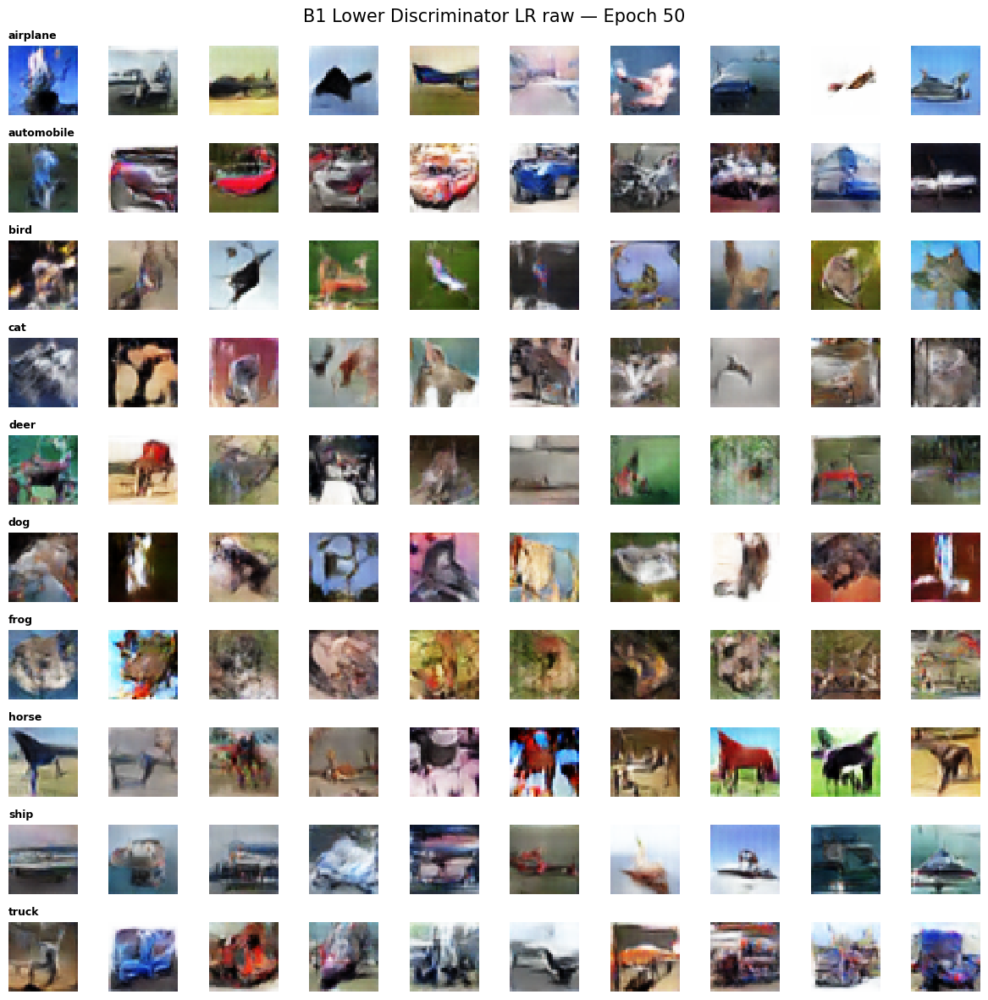

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_050.png
Epoch 051/100 | G 1.7438 | D 0.6435 | D(real) 0.7555 | D(fake) 0.2431 | D acc 0.9024 | 19.6s
Epoch 052/100 | G 1.7687 | D 0.6912 | D(real) 0.7495 | D(fake) 0.2499 | D acc 0.8852 | 20.2s
Epoch 053/100 | G 1.7867 | D 0.6796 | D(real) 0.7558 | D(fake) 0.2421 | D acc 0.8982 | 19.6s
Epoch 054/100 | G 1.7834 | D 0.6253 | D(real) 0.7607 | D(fake) 0.2387 | D acc 0.9020 | 19.7s
Epoch 055/100 | G 1.8369 | D 0.6089 | D(real) 0.7666 | D(fake) 0.2318 | D acc 0.9058 | 19.9s
Epoch 056/100 | G 1.8435 | D 0.6340 | D(real) 0.7652 | D(fake) 0.2336 | D acc 0.9044 | 19.6s
Epoch 057/100 | G 1.8252 | D 0.6902 | D(real) 0.7584 | D(fake) 0.2411 | D acc 0.8922 | 19.6s
Epoch 058/100 | G 1.8399 | D 0.6895 | D(real) 0.7589 | D(fake) 0.2403 | D acc 0.8947 | 19.7s
Epoch 059/100 | G 1.8746 | D 0.6036 | D(real) 0.7741 | D(fake) 0.2251 | D acc 0.9165 | 19.6s
Epoch 060/100 | G 1.9026 | D 0.6121 | D(real) 0.7761 |

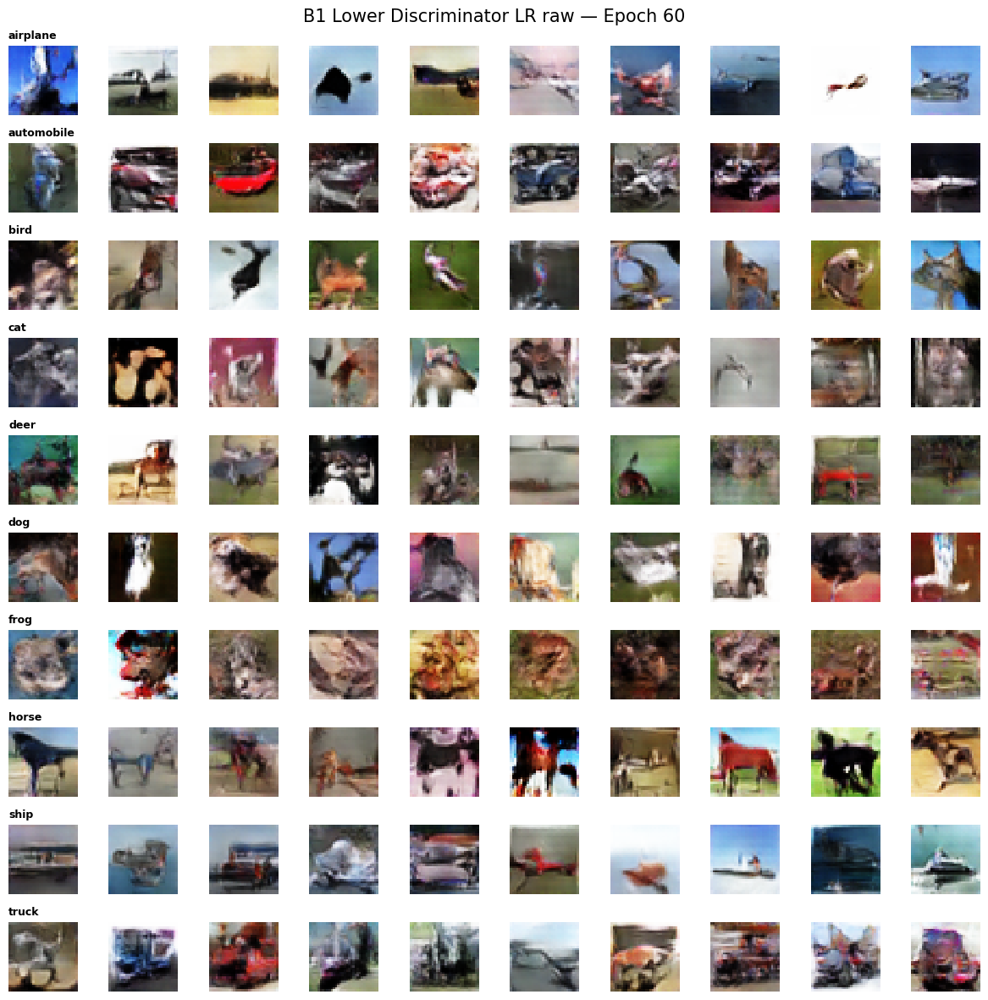

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_060.png
Epoch 061/100 | G 1.9103 | D 0.6100 | D(real) 0.7774 | D(fake) 0.2216 | D acc 0.9167 | 19.4s
Epoch 062/100 | G 1.9302 | D 0.5973 | D(real) 0.7788 | D(fake) 0.2198 | D acc 0.9178 | 19.8s
Epoch 063/100 | G 1.9644 | D 0.5575 | D(real) 0.7861 | D(fake) 0.2128 | D acc 0.9213 | 19.8s
Epoch 064/100 | G 1.9885 | D 0.5810 | D(real) 0.7880 | D(fake) 0.2112 | D acc 0.9247 | 19.6s
Epoch 065/100 | G 2.0325 | D 0.5288 | D(real) 0.7945 | D(fake) 0.2044 | D acc 0.9239 | 19.6s
Epoch 066/100 | G 2.0776 | D 0.6018 | D(real) 0.7888 | D(fake) 0.2107 | D acc 0.9130 | 19.6s
Epoch 067/100 | G 2.0472 | D 0.4881 | D(real) 0.8039 | D(fake) 0.1948 | D acc 0.9404 | 19.5s
Epoch 068/100 | G 2.0833 | D 0.5606 | D(real) 0.7953 | D(fake) 0.2034 | D acc 0.9215 | 19.7s
Epoch 069/100 | G 2.1043 | D 0.5293 | D(real) 0.8030 | D(fake) 0.1959 | D acc 0.9327 | 19.5s
Epoch 070/100 | G 2.1355 | D 0.4859 | D(real) 0.8094 |

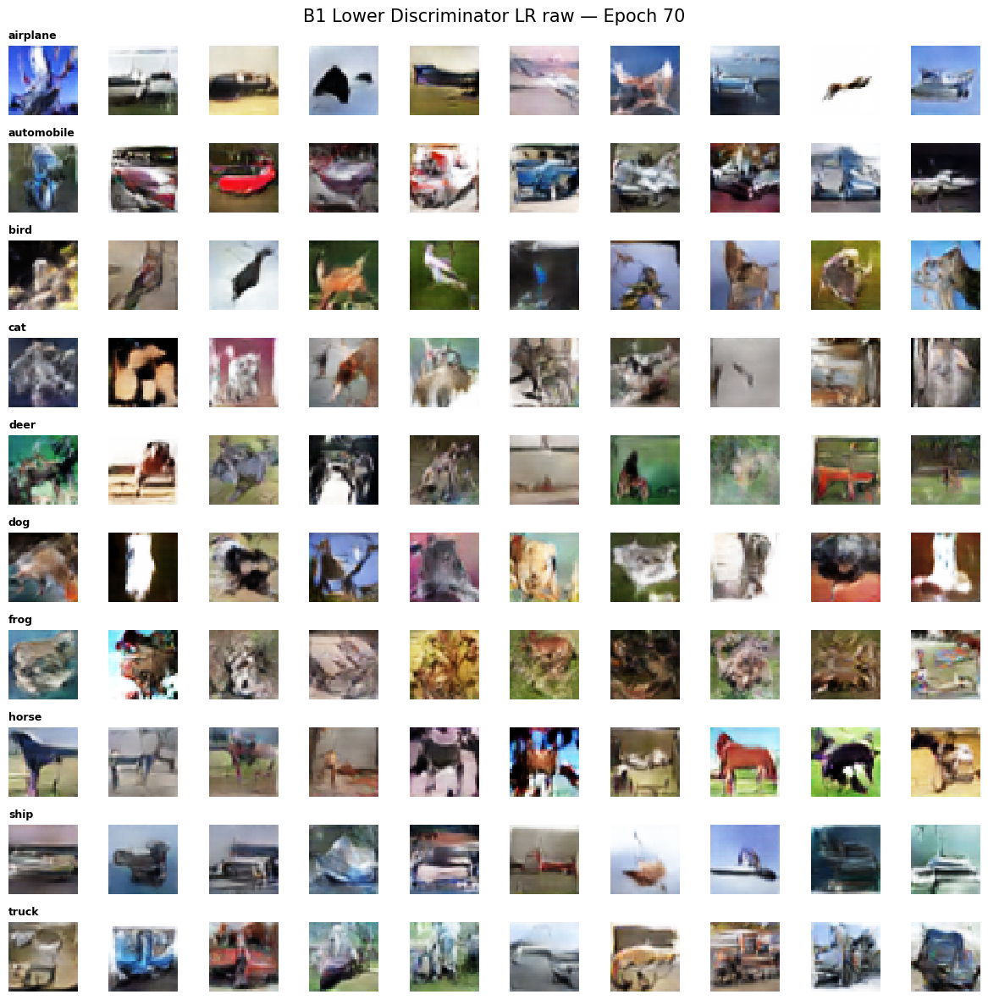

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_070.png
Epoch 071/100 | G 2.1402 | D 0.5483 | D(real) 0.8028 | D(fake) 0.1961 | D acc 0.9270 | 19.6s
Epoch 072/100 | G 2.1744 | D 0.5188 | D(real) 0.8088 | D(fake) 0.1907 | D acc 0.9331 | 19.4s
Epoch 073/100 | G 2.1853 | D 0.5420 | D(real) 0.8060 | D(fake) 0.1930 | D acc 0.9273 | 19.4s
Epoch 074/100 | G 2.1907 | D 0.5375 | D(real) 0.8113 | D(fake) 0.1878 | D acc 0.9371 | 19.7s
Epoch 075/100 | G 2.2326 | D 0.5073 | D(real) 0.8164 | D(fake) 0.1831 | D acc 0.9395 | 19.6s
Epoch 076/100 | G 2.1998 | D 0.5301 | D(real) 0.8103 | D(fake) 0.1882 | D acc 0.9339 | 19.6s
Epoch 077/100 | G 2.2595 | D 0.4773 | D(real) 0.8198 | D(fake) 0.1800 | D acc 0.9413 | 19.5s
Epoch 078/100 | G 2.2968 | D 0.5210 | D(real) 0.8196 | D(fake) 0.1800 | D acc 0.9342 | 19.7s
Epoch 079/100 | G 2.2951 | D 0.4247 | D(real) 0.8295 | D(fake) 0.1687 | D acc 0.9518 | 19.9s
Epoch 080/100 | G 2.3376 | D 0.4722 | D(real) 0.8258 |

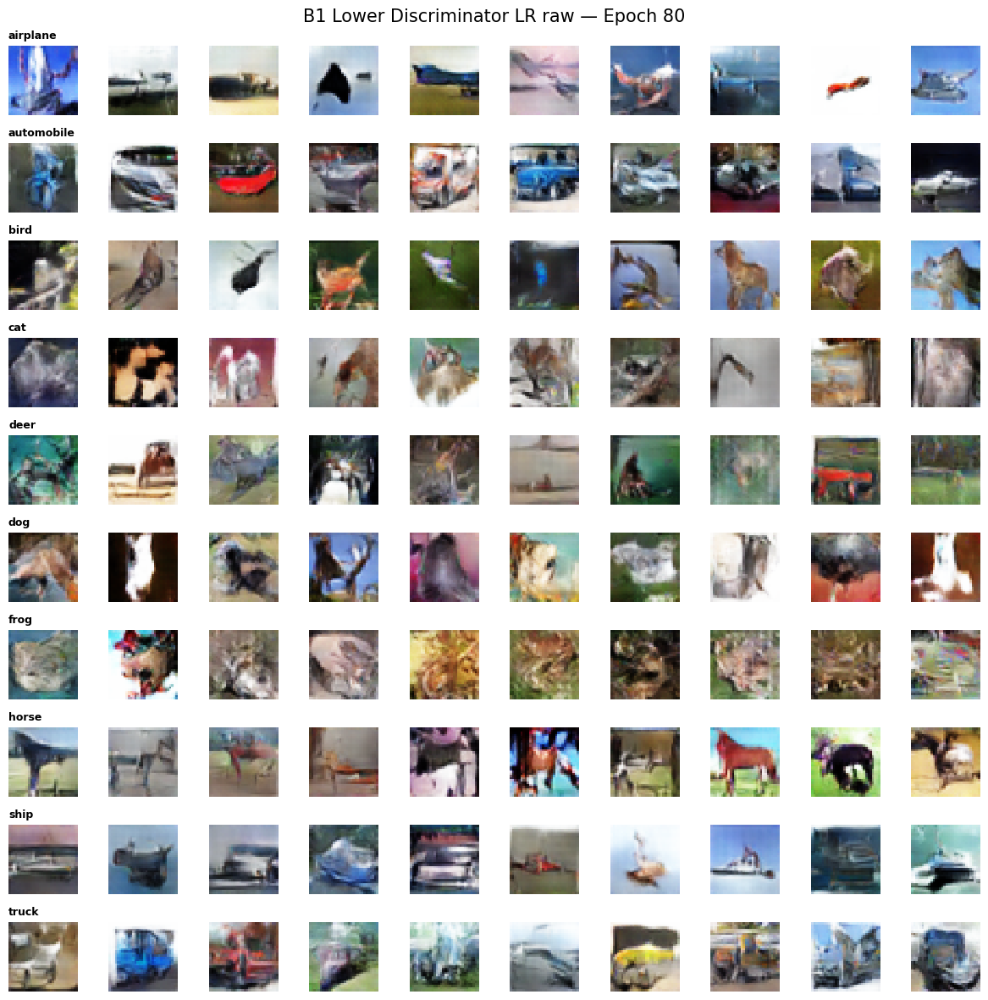

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_080.png
Epoch 081/100 | G 2.3631 | D 0.4439 | D(real) 0.8304 | D(fake) 0.1683 | D acc 0.9470 | 19.5s
Epoch 082/100 | G 2.3704 | D 0.4971 | D(real) 0.8249 | D(fake) 0.1748 | D acc 0.9370 | 19.4s
Epoch 083/100 | G 2.3821 | D 0.4324 | D(real) 0.8363 | D(fake) 0.1630 | D acc 0.9539 | 19.5s
Epoch 084/100 | G 2.3965 | D 0.4797 | D(real) 0.8299 | D(fake) 0.1695 | D acc 0.9388 | 19.5s
Epoch 085/100 | G 2.3976 | D 0.4951 | D(real) 0.8279 | D(fake) 0.1708 | D acc 0.9366 | 19.5s
Epoch 086/100 | G 2.4615 | D 0.4475 | D(real) 0.8398 | D(fake) 0.1599 | D acc 0.9505 | 19.6s
Epoch 087/100 | G 2.4528 | D 0.3666 | D(real) 0.8486 | D(fake) 0.1502 | D acc 0.9653 | 19.6s
Epoch 088/100 | G 2.5412 | D 0.4425 | D(real) 0.8439 | D(fake) 0.1557 | D acc 0.9478 | 19.6s
Epoch 089/100 | G 2.4967 | D 0.3642 | D(real) 0.8511 | D(fake) 0.1482 | D acc 0.9623 | 19.9s
Epoch 090/100 | G 2.5138 | D 0.5039 | D(real) 0.8301 |

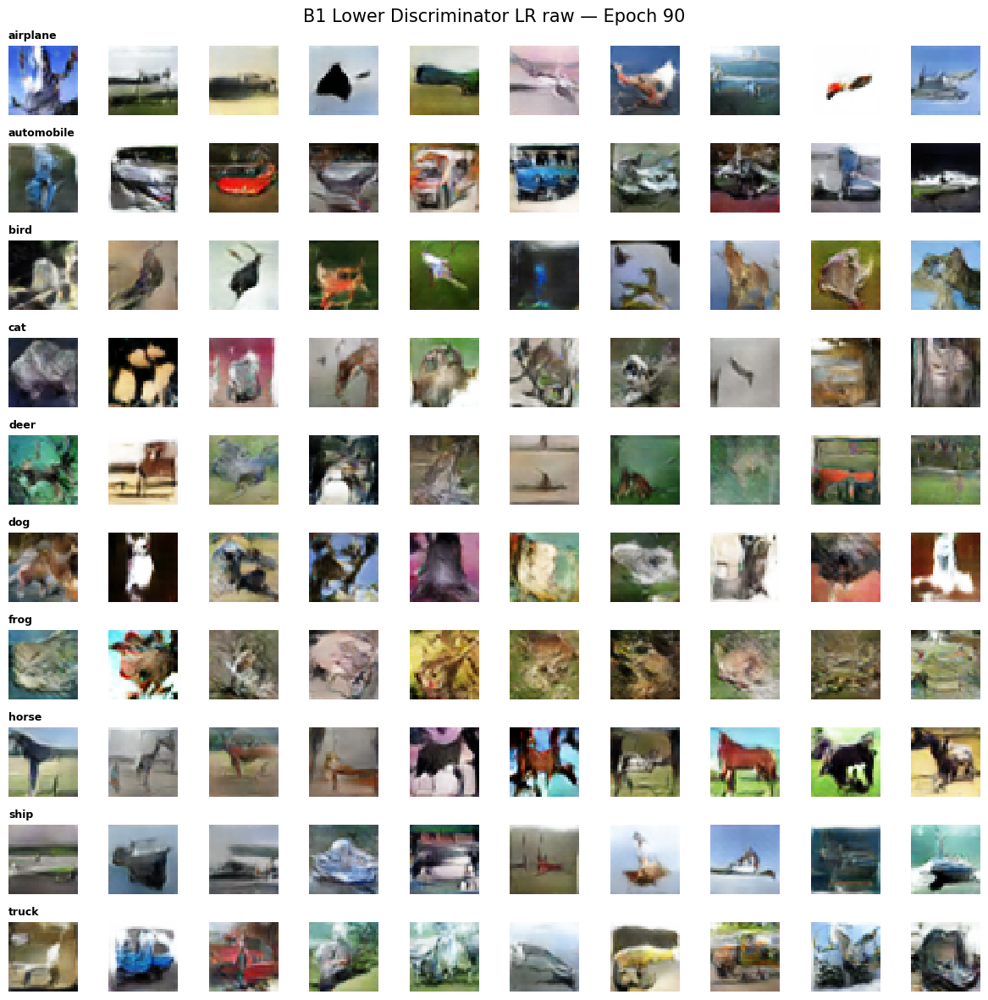

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_090.png
Epoch 091/100 | G 2.5737 | D 0.3300 | D(real) 0.8620 | D(fake) 0.1369 | D acc 0.9729 | 19.6s
Epoch 092/100 | G 2.5723 | D 0.4576 | D(real) 0.8394 | D(fake) 0.1602 | D acc 0.9385 | 19.8s
Epoch 093/100 | G 2.6124 | D 0.3474 | D(real) 0.8590 | D(fake) 0.1400 | D acc 0.9638 | 19.5s
Epoch 094/100 | G 2.5992 | D 0.4799 | D(real) 0.8382 | D(fake) 0.1616 | D acc 0.9317 | 19.5s
Epoch 095/100 | G 2.6316 | D 0.3370 | D(real) 0.8622 | D(fake) 0.1367 | D acc 0.9671 | 19.7s
Epoch 096/100 | G 2.7079 | D 0.3052 | D(real) 0.8719 | D(fake) 0.1274 | D acc 0.9750 | 19.6s
Epoch 097/100 | G 2.6798 | D 0.4314 | D(real) 0.8525 | D(fake) 0.1471 | D acc 0.9490 | 19.4s
Epoch 098/100 | G 2.6979 | D 0.4752 | D(real) 0.8509 | D(fake) 0.1487 | D acc 0.9454 | 19.4s
Epoch 099/100 | G 2.7222 | D 0.3076 | D(real) 0.8718 | D(fake) 0.1272 | D acc 0.9733 | 19.5s
Epoch 100/100 | G 2.7369 | D 0.3906 | D(real) 0.8647 |

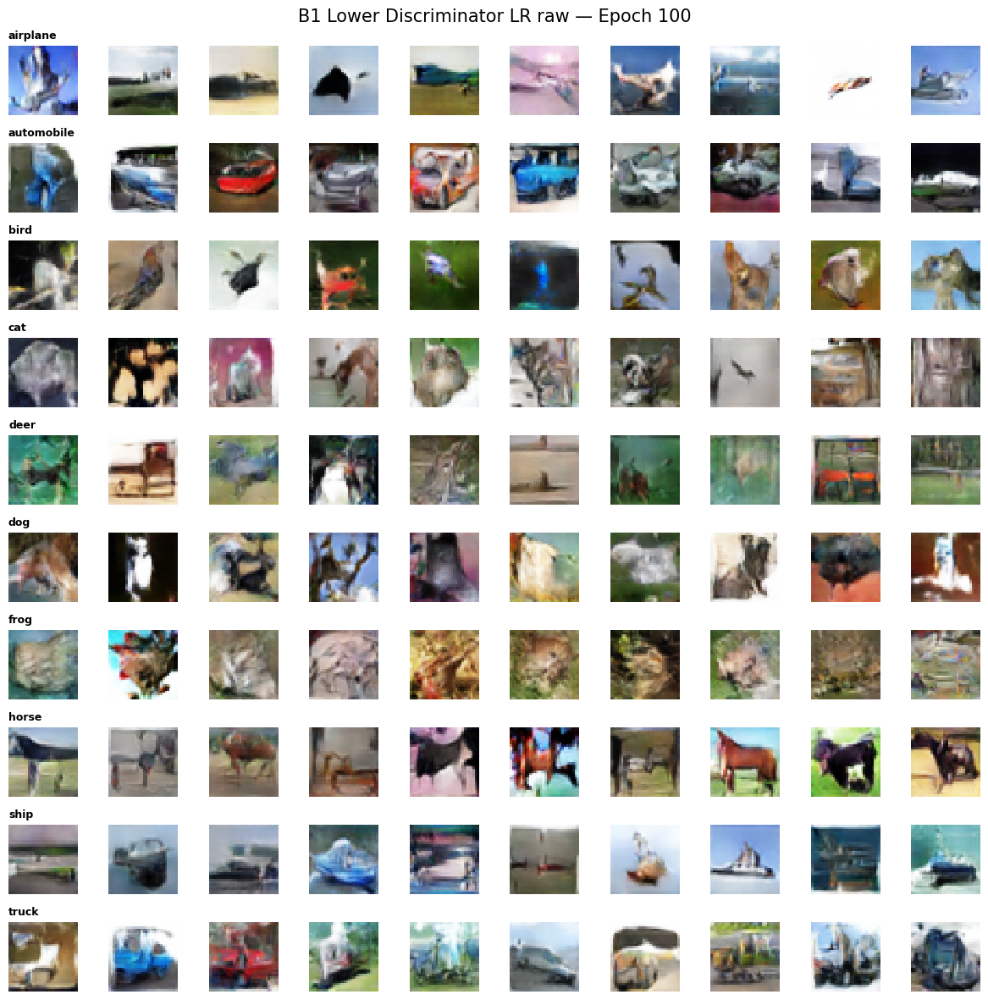

Saved grid: HeinHtetPartA_outputs\B1_lower_discriminator_lr\generated_grids_raw\generated_grid_epoch_100.png
Completed B1 Lower Discriminator LR: 100 epochs recorded.


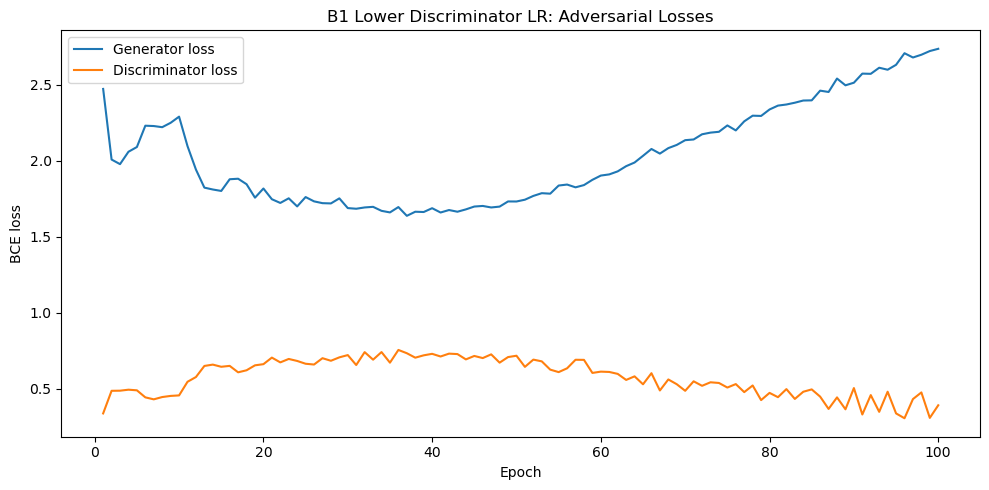

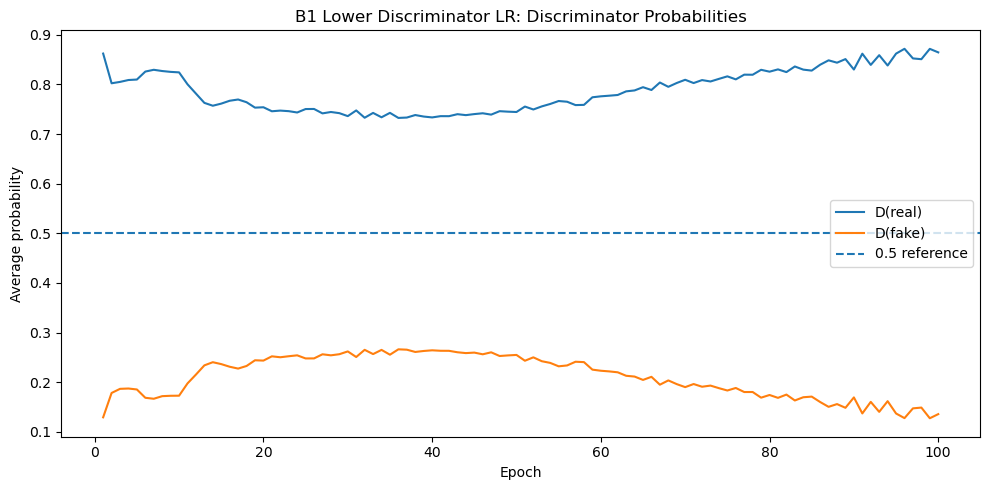

In [41]:
B1_RESULT = execute_fresh_experiment(
    run_name="B1_lower_discriminator_lr",
    run_label="B1 Lower Discriminator LR",
    augmentation_function=identity_policy,
    generator_learning_rate=2e-4,
    discriminator_learning_rate=1e-4,
)


#### B1 Training Assessment

B1 investigates whether lowering the discriminator learning rate produces a
better adversarial balance than the B0 baseline. Training remained numerically
stable across all 100 epochs, with finite losses and no sudden divergence.

The generator loss decreased from approximately 2.5 to around 1.7 during the
first half of training. This suggests that the generator initially improved
its ability to challenge the discriminator. After approximately epoch 40, the
generator loss gradually increased and reached about 2.7 by epoch 100,
indicating that the discriminator again became harder to fool during the later
stages of training.

The discriminator loss increased during the early epochs and remained mostly
between approximately 0.5 and 0.7 until the middle of training. It then
gradually decreased, ending at around 0.4. Compared with B0, the reduced
discriminator learning rate appears to have produced a more gradual and stable
change in the adversarial losses, particularly during the first half of the
run.

The discriminator-probability plot shows that `D(real)` decreased from about
0.86 to approximately 0.74 during the early and middle stages before rising
again to around 0.86 near epoch 100. At the same time, `D(fake)` initially rose
to approximately 0.26 before declining to around 0.13. This indicates that the
generator temporarily became more competitive, but the discriminator remained
the stronger network by the end of training.

There is no clear evidence of complete training collapse. The curves change
smoothly, and neither network loss becomes extreme or non-finite. However, the
increasing generator loss and widening separation between `D(real)` and
`D(fake)` during the later epochs suggest that reducing the discriminator
learning rate did not fully solve the adversarial imbalance.

The training curves alone were not used to determine the best B1 checkpoint,
because GAN loss values do not directly measure image quality. Checkpoint
selection was performed using FID as the primary metric and KID as supporting
evidence. The saved class-balanced grids were inspected only as a verification
step to confirm that the selected checkpoint did not show severe mode collapse,
major artefacts or loss of class recognisability.

#### B1  FID/KID Evaluation — Run After B1 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B1: epoch 10, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 010 | raw | FID 155.9429 | KID 0.135241 ± 0.008959
Evaluating B1: epoch 20, raw...
Epoch 020 | raw | FID 77.8999 | KID 0.050064 ± 0.005904
Evaluating B1: epoch 30, raw...
Epoch 030 | raw | FID 59.2802 | KID 0.034415 ± 0.004861
Evaluating B1: epoch 40, raw...
Epoch 040 | raw | FID 48.8541 | KID 0.025118 ± 0.003886
Evaluating B1: epoch 50, raw...
Epoch 050 | raw | FID 45.6134 | KID 0.022462 ± 0.004081
Evaluating B1: epoch 60, raw...
Epoch 060 | raw | FID 47.4276 | KID 0.024765 ± 0.004799
Evaluating B1: epoch 70, raw...
Epoch 070 | raw | FID 42.5281 | KID 0.020480 ± 0.003971
Evaluating B1: epoch 80, raw...
Epoch 080 | raw | FID 42.3066 | KID 0.020827 ± 0.003682
Evaluating B1: epoch 90, raw...
Epoch 090 | raw | FID 43.1272 | KID 0.021838 ± 0.00

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B1,B1_lower_discriminator_lr,10,raw,155.9429,0.135241,0.008959,5000
1,B1,B1_lower_discriminator_lr,20,raw,77.8999,0.050064,0.005904,5000
2,B1,B1_lower_discriminator_lr,30,raw,59.2802,0.034415,0.004861,5000
3,B1,B1_lower_discriminator_lr,40,raw,48.8541,0.025118,0.003886,5000
4,B1,B1_lower_discriminator_lr,50,raw,45.6134,0.022462,0.004081,5000
5,B1,B1_lower_discriminator_lr,60,raw,47.4276,0.024765,0.004799,5000
6,B1,B1_lower_discriminator_lr,70,raw,42.5281,0.020480,0.003971,5000
7,B1,B1_lower_discriminator_lr,80,raw,42.3066,0.020827,0.003682,5000
8,B1,B1_lower_discriminator_lr,90,raw,43.1272,0.021838,0.003959,5000
9,B1,B1_lower_discriminator_lr,100,raw,38.4121,0.017763,0.004000,5000


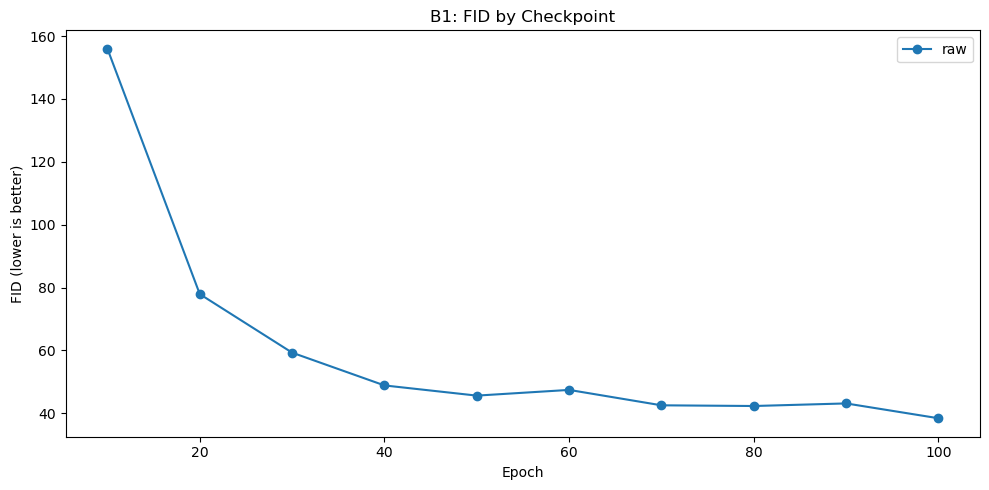

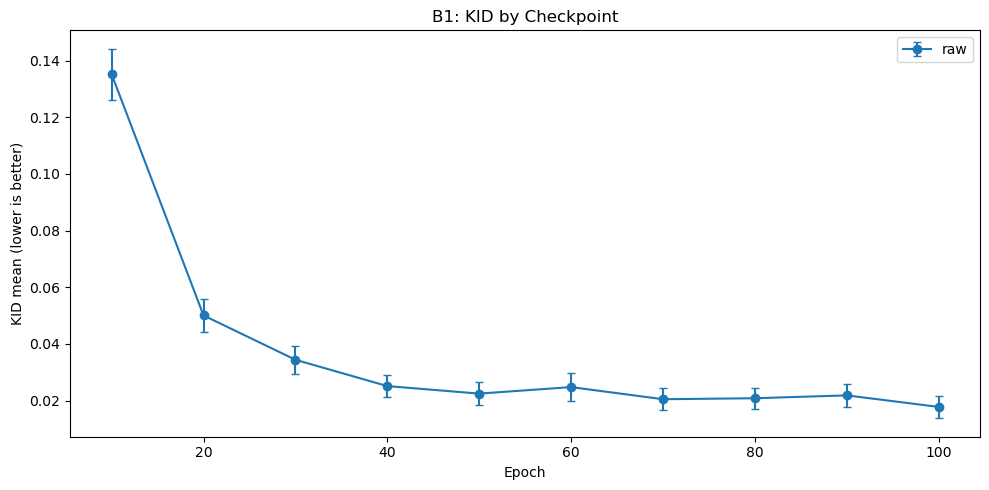

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B1_lower_discriminator_lr\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [42]:
B1_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B1",
    run_name="B1_lower_discriminator_lr",
    candidates=("raw",),
    expected_epochs=range(10, 101, 10),
)


### B1 Review

- **Chosen B1 epoch:** 100
- **FID:** 38.4121
- **KID mean ± standard deviation:** 0.017763 ± 0.004000
- **Decision:** Retained as the strongest B1 checkpoint.

### Checkpoint Selection

Epoch 100 was selected manually because it achieved the lowest FID among all
evaluated B1 checkpoints. FID was treated as the primary selection metric, and
the score decreased substantially from 155.9429 at epoch 10 to 38.4121 at
epoch 100. Although there were small temporary regressions at epochs 60 and 90,
the overall trend showed continued improvement throughout training.

KID was used as supporting evidence. Epoch 100 also achieved the lowest KID
mean of 0.017763. Its uncertainty range overlaps slightly with some nearby
checkpoints, but the result remains consistent with the FID-based selection.
Therefore, both quantitative metrics support choosing epoch 100.

### Comparison with B0

B1 reduced FID by approximately 2.2169 points and also achieved a lower KID
mean. This indicates that reducing the discriminator learning rate produced a
modest improvement in the generated-image feature distribution compared with
the baseline.

### Visual Verification

The fixed-input class-balanced grid for epoch 100 was inspected only as a
verification step. The visual check confirmed that the quantitative improvement
was not associated with severe mode collapse, major artefacts, or complete loss
of conditional class structure.

Visual inspection was not used as the primary checkpoint-selection method.
Instead, it was used to confirm that the FID and KID findings were consistent
with the visible outputs.

### Learning-Rate Conclusion

Lowering the discriminator learning rate produced a small but measurable
improvement over B0. It slowed the discriminator sufficiently for the generator
to become more competitive during training, although the discriminator still
became stronger during the later epochs. Since B1 achieved better FID and KID
scores than B0, the learning-rate adjustment was retained as a successful
experiment.

- **Visual label counts:** Not completed for B1 because the full
  `clear/marginal / nonsense` assessment was reserved for the strongest final
  candidates.
- **Requested-class match observations:** General class consistency was checked
  using the fixed-input grid, while detailed requested-class matching was
  reserved for the final shortlisted models.


### 8.3 B2 — Horizontal-Flip Augmentation

B2 is a controlled comparison against the fixed B0 configuration. It keeps the
same architecture, learning rates, dataset split, seed, batch size, loss and
100-epoch budget, while adding random horizontal flips.

Following the DiffAugment principle, the same differentiable flip policy is
applied to real and generated images before discriminator evaluation
(Zhao et al., 2020). Validation images and images used for FID and KID remain
unaugmented.

B2 begins from fresh weights. Its parent is fixed explicitly as B0 rather than
being chosen automatically from the learning-rate experiment.


#### B2 Experiment Setup

B2 uses the original B0 baseline learning-rate configuration but introduces
horizontal flipping during discriminator training. The dataset itself remains unchanged
because the augmentation will later be applied inside the training step to both
real and generated images.

This keeps all other experimental conditions consistent with B0 so that the
effect of horizontal flipping can be evaluated fairly.

#### B2 Horizontal-Flip Training Step

Horizontal flipping is applied inside the training step to both real and
generated images before they are passed to the discriminator. Applying the same
augmentation policy to both groups prevents the discriminator from identifying
generated images merely because only the real images were augmented.

The augmentation remains inside the gradient tapes so that gradients can pass
from the discriminator through the augmented generated images to the generator.
No augmentation is used when producing checkpoint grids or calculating FID and
KID.

#### B2 Checkpoint Setup

B2 uses a separate checkpoint directory so that its generator, discriminator and
optimiser states do not overwrite the completed B0 or B1 experiments.

A checkpoint is saved every 10 epochs. The untrained epoch-zero grid is also
generated using the same fixed noise and labels used in the earlier experiments.

Epoch 001/100 | G 3.2998 | D 0.2499 | D(real) 0.9037 | D(fake) 0.0883 | D acc 0.9667 | 20.8s
Epoch 002/100 | G 2.9621 | D 0.2760 | D(real) 0.8900 | D(fake) 0.1050 | D acc 0.9656 | 18.6s
Epoch 003/100 | G 2.7426 | D 0.3457 | D(real) 0.8689 | D(fake) 0.1290 | D acc 0.9501 | 18.7s
Epoch 004/100 | G 2.5482 | D 0.4319 | D(real) 0.8420 | D(fake) 0.1552 | D acc 0.9306 | 18.7s
Epoch 005/100 | G 2.5684 | D 0.4121 | D(real) 0.8477 | D(fake) 0.1502 | D acc 0.9388 | 18.9s
Epoch 006/100 | G 2.6281 | D 0.3693 | D(real) 0.8579 | D(fake) 0.1412 | D acc 0.9476 | 18.6s
Epoch 007/100 | G 2.5928 | D 0.4286 | D(real) 0.8423 | D(fake) 0.1551 | D acc 0.9291 | 18.7s
Epoch 008/100 | G 2.4470 | D 0.4752 | D(real) 0.8282 | D(fake) 0.1703 | D acc 0.9211 | 18.7s
Epoch 009/100 | G 2.3334 | D 0.5044 | D(real) 0.8158 | D(fake) 0.1827 | D acc 0.9119 | 18.9s
Epoch 010/100 | G 2.3009 | D 0.5609 | D(real) 0.8019 | D(fake) 0.1952 | D acc 0.8973 | 19.0s
Saved checkpoint: HeinHtetPartA_outputs\B2_horizontal_flip\checkpoints

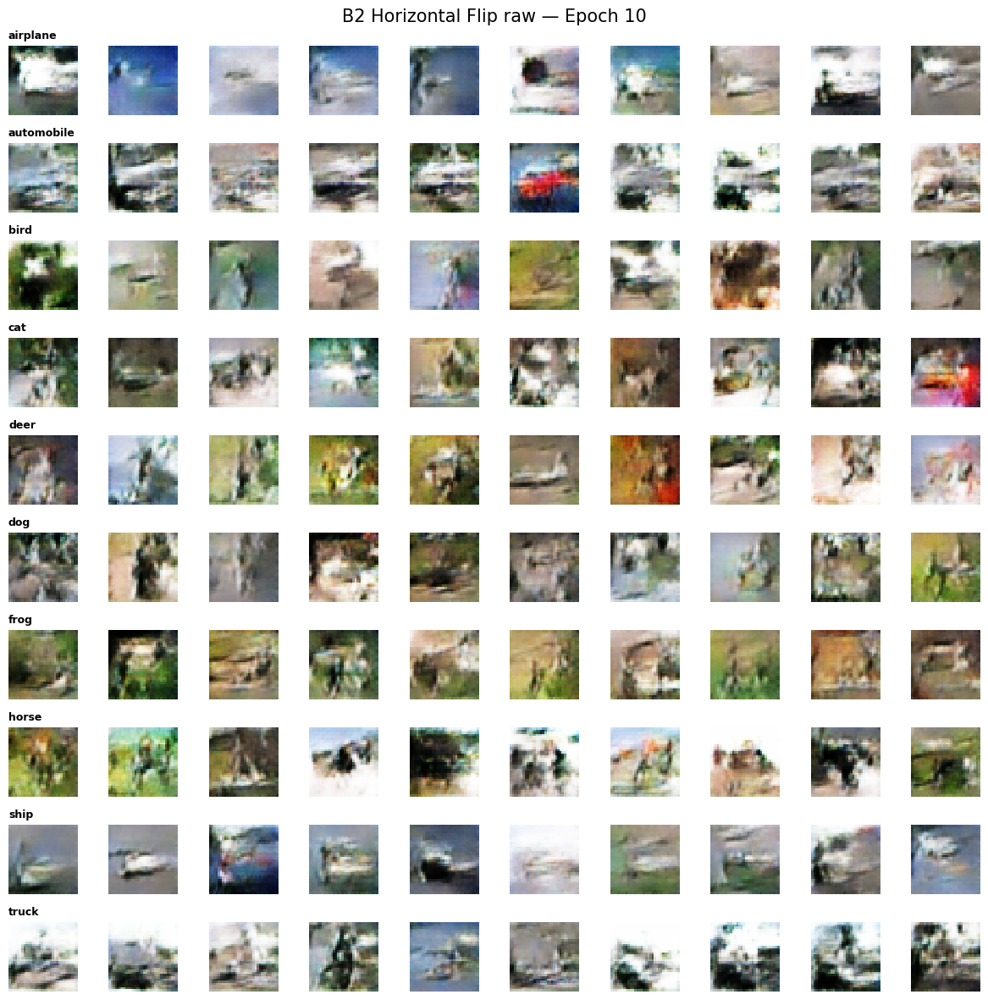

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_010.png
Epoch 011/100 | G 2.2244 | D 0.5259 | D(real) 0.8080 | D(fake) 0.1903 | D acc 0.9171 | 19.0s
Epoch 012/100 | G 2.1959 | D 0.5846 | D(real) 0.7986 | D(fake) 0.1993 | D acc 0.9063 | 19.1s
Epoch 013/100 | G 2.2127 | D 0.5371 | D(real) 0.8034 | D(fake) 0.1946 | D acc 0.9084 | 19.1s
Epoch 014/100 | G 2.1485 | D 0.5937 | D(real) 0.7916 | D(fake) 0.2078 | D acc 0.8979 | 19.4s
Epoch 015/100 | G 2.0985 | D 0.6078 | D(real) 0.7858 | D(fake) 0.2127 | D acc 0.8943 | 19.5s
Epoch 016/100 | G 2.1113 | D 0.5642 | D(real) 0.7924 | D(fake) 0.2057 | D acc 0.9030 | 19.3s
Epoch 017/100 | G 2.0999 | D 0.6130 | D(real) 0.7811 | D(fake) 0.2174 | D acc 0.8858 | 19.3s
Epoch 018/100 | G 2.1343 | D 0.6116 | D(real) 0.7877 | D(fake) 0.2113 | D acc 0.8937 | 19.3s
Epoch 019/100 | G 2.0351 | D 0.6181 | D(real) 0.7823 | D(fake) 0.2169 | D acc 0.8994 | 19.3s
Epoch 020/100 | G 2.0005 | D 0.6424 | D(real) 0.7714 | D(fake

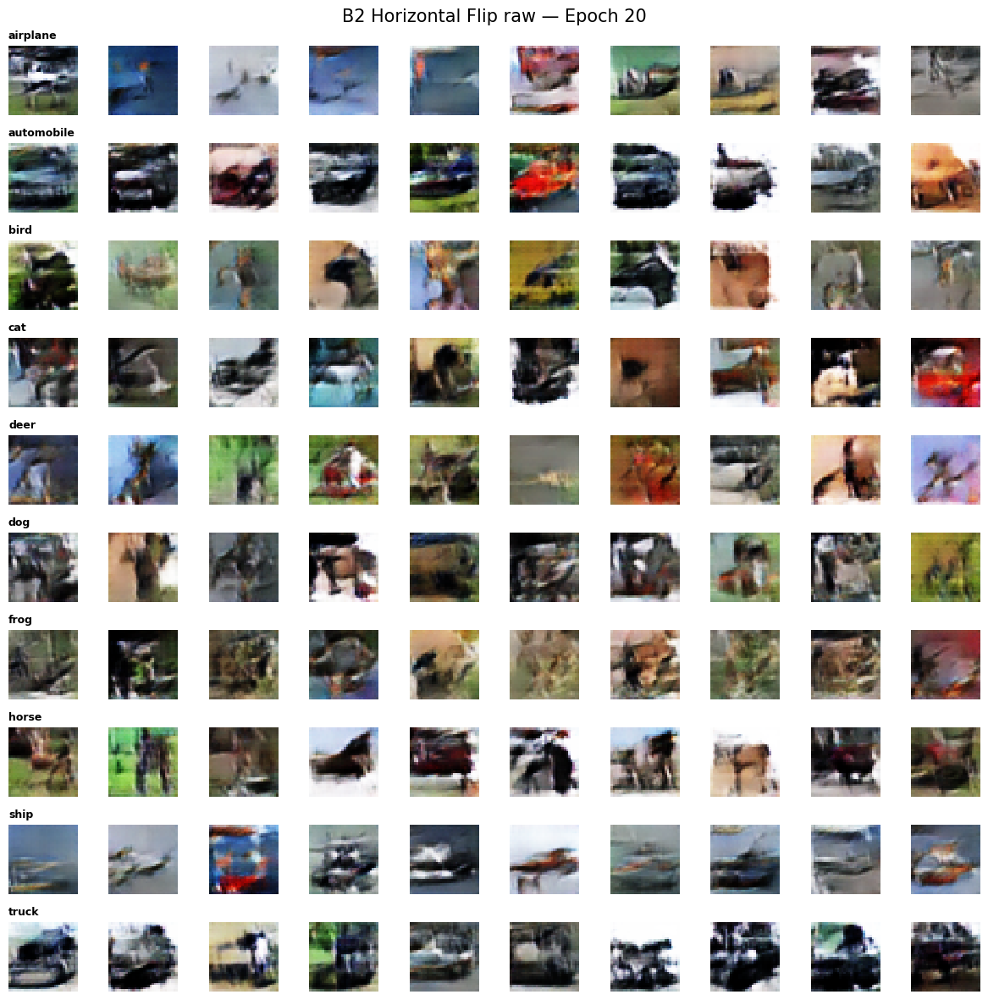

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_020.png
Epoch 021/100 | G 1.9899 | D 0.6199 | D(real) 0.7748 | D(fake) 0.2241 | D acc 0.8913 | 19.3s
Epoch 022/100 | G 1.9244 | D 0.6221 | D(real) 0.7705 | D(fake) 0.2287 | D acc 0.8914 | 19.3s
Epoch 023/100 | G 1.9121 | D 0.6867 | D(real) 0.7600 | D(fake) 0.2395 | D acc 0.8731 | 19.6s
Epoch 024/100 | G 1.9200 | D 0.6753 | D(real) 0.7614 | D(fake) 0.2370 | D acc 0.8784 | 19.3s
Epoch 025/100 | G 1.9218 | D 0.6881 | D(real) 0.7579 | D(fake) 0.2417 | D acc 0.8697 | 19.3s
Epoch 026/100 | G 1.8963 | D 0.6512 | D(real) 0.7625 | D(fake) 0.2366 | D acc 0.8810 | 19.4s
Epoch 027/100 | G 1.9412 | D 0.6452 | D(real) 0.7645 | D(fake) 0.2349 | D acc 0.8780 | 19.3s
Epoch 028/100 | G 1.9440 | D 0.6581 | D(real) 0.7634 | D(fake) 0.2348 | D acc 0.8762 | 19.5s
Epoch 029/100 | G 1.9373 | D 0.6965 | D(real) 0.7592 | D(fake) 0.2412 | D acc 0.8679 | 19.7s
Epoch 030/100 | G 1.8897 | D 0.6741 | D(real) 0.7592 | D(fake

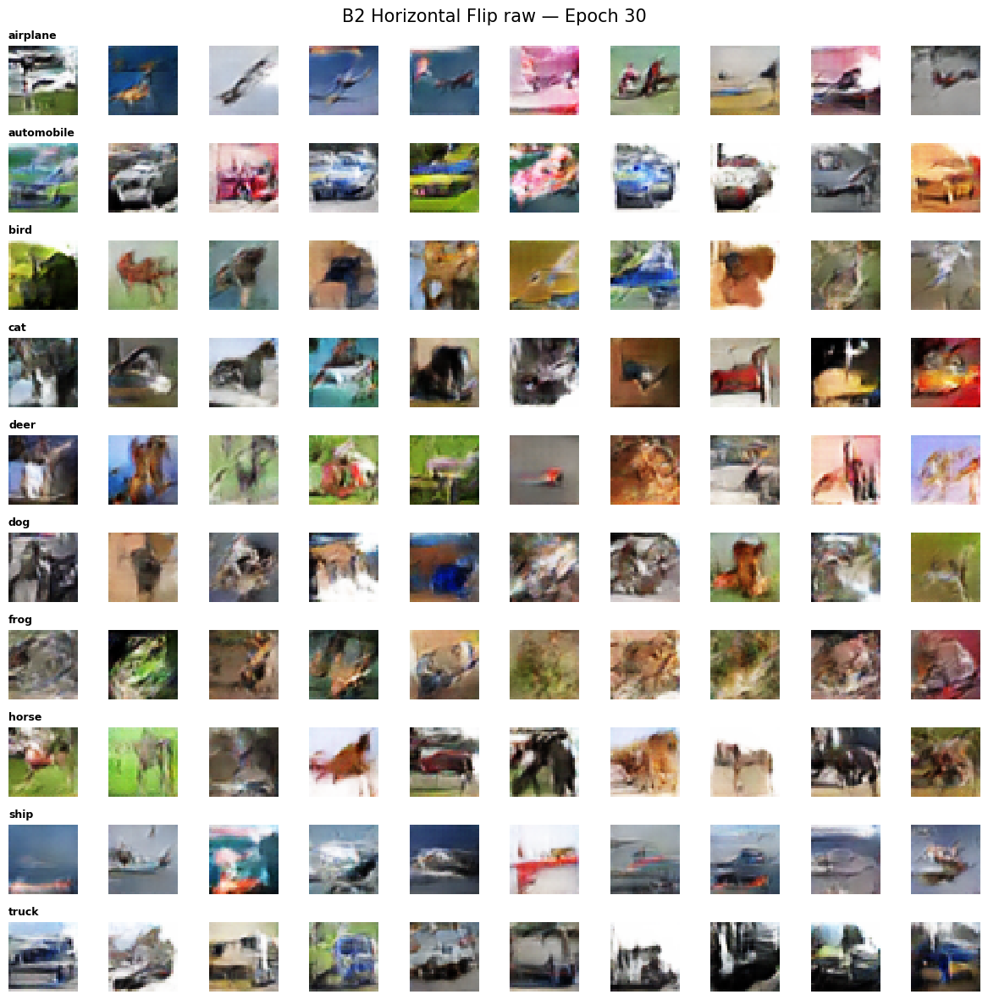

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_030.png
Epoch 031/100 | G 1.9005 | D 0.6748 | D(real) 0.7594 | D(fake) 0.2396 | D acc 0.8762 | 19.4s
Epoch 032/100 | G 1.9231 | D 0.7002 | D(real) 0.7602 | D(fake) 0.2391 | D acc 0.8776 | 19.4s
Epoch 033/100 | G 1.9209 | D 0.6715 | D(real) 0.7608 | D(fake) 0.2388 | D acc 0.8753 | 19.8s
Epoch 034/100 | G 1.9078 | D 0.6729 | D(real) 0.7622 | D(fake) 0.2366 | D acc 0.8831 | 19.5s
Epoch 035/100 | G 1.9562 | D 0.7098 | D(real) 0.7571 | D(fake) 0.2422 | D acc 0.8627 | 19.5s
Epoch 036/100 | G 1.9397 | D 0.6270 | D(real) 0.7704 | D(fake) 0.2290 | D acc 0.8886 | 19.5s
Epoch 037/100 | G 1.9174 | D 0.6807 | D(real) 0.7584 | D(fake) 0.2405 | D acc 0.8700 | 19.4s
Epoch 038/100 | G 1.9657 | D 0.6477 | D(real) 0.7721 | D(fake) 0.2284 | D acc 0.8911 | 19.6s
Epoch 039/100 | G 1.9936 | D 0.6504 | D(real) 0.7685 | D(fake) 0.2307 | D acc 0.8773 | 19.5s
Epoch 040/100 | G 1.9848 | D 0.7220 | D(real) 0.7594 | D(fake

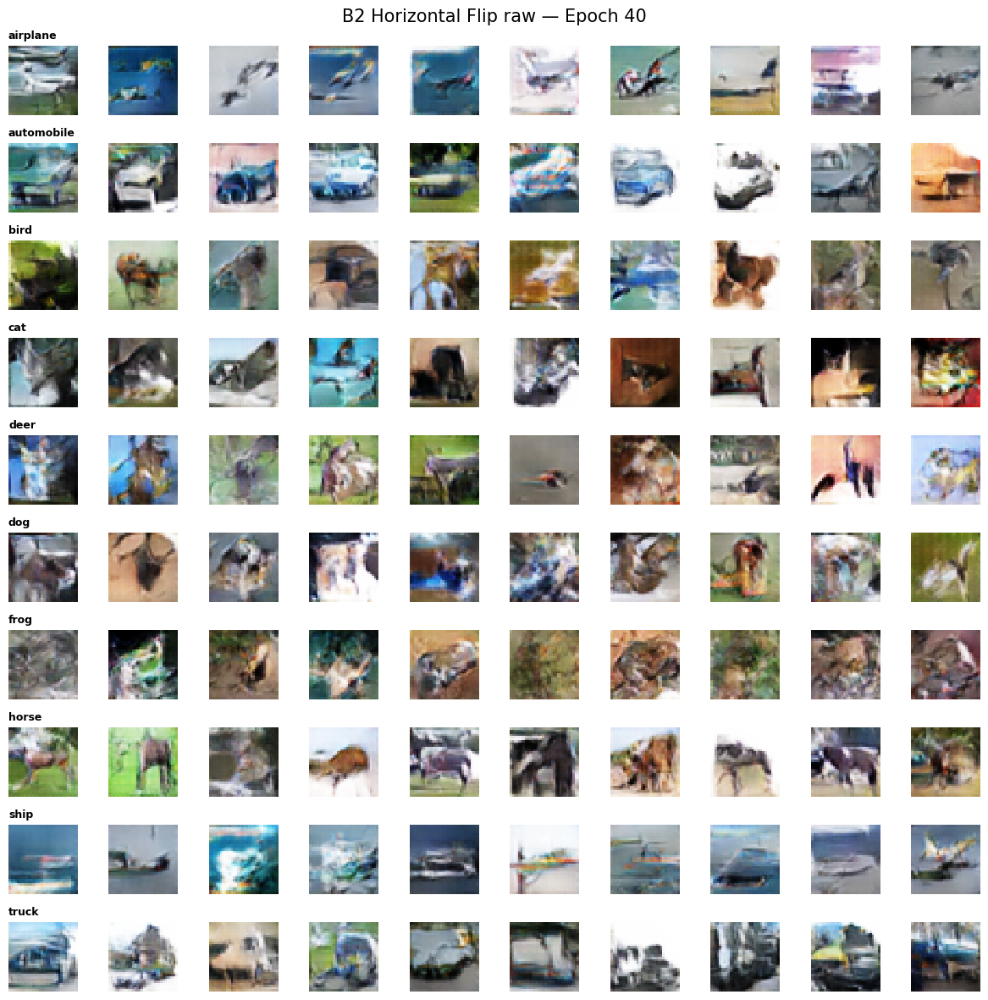

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_040.png
Epoch 041/100 | G 1.9700 | D 0.5794 | D(real) 0.7812 | D(fake) 0.2188 | D acc 0.9028 | 19.5s
Epoch 042/100 | G 2.0006 | D 0.6519 | D(real) 0.7693 | D(fake) 0.2298 | D acc 0.8772 | 19.3s
Epoch 043/100 | G 2.0384 | D 0.6742 | D(real) 0.7737 | D(fake) 0.2255 | D acc 0.8868 | 19.4s
Epoch 044/100 | G 2.0301 | D 0.6173 | D(real) 0.7768 | D(fake) 0.2221 | D acc 0.8896 | 19.4s
Epoch 045/100 | G 2.0520 | D 0.6034 | D(real) 0.7808 | D(fake) 0.2193 | D acc 0.8893 | 19.6s
Epoch 046/100 | G 2.0562 | D 0.5895 | D(real) 0.7875 | D(fake) 0.2110 | D acc 0.9091 | 19.8s
Epoch 047/100 | G 2.0817 | D 0.6287 | D(real) 0.7810 | D(fake) 0.2181 | D acc 0.8935 | 19.5s
Epoch 048/100 | G 2.0829 | D 0.6643 | D(real) 0.7800 | D(fake) 0.2201 | D acc 0.8879 | 19.6s
Epoch 049/100 | G 2.1212 | D 0.5462 | D(real) 0.7961 | D(fake) 0.2037 | D acc 0.9102 | 19.5s
Epoch 050/100 | G 2.1311 | D 0.6830 | D(real) 0.7827 | D(fake

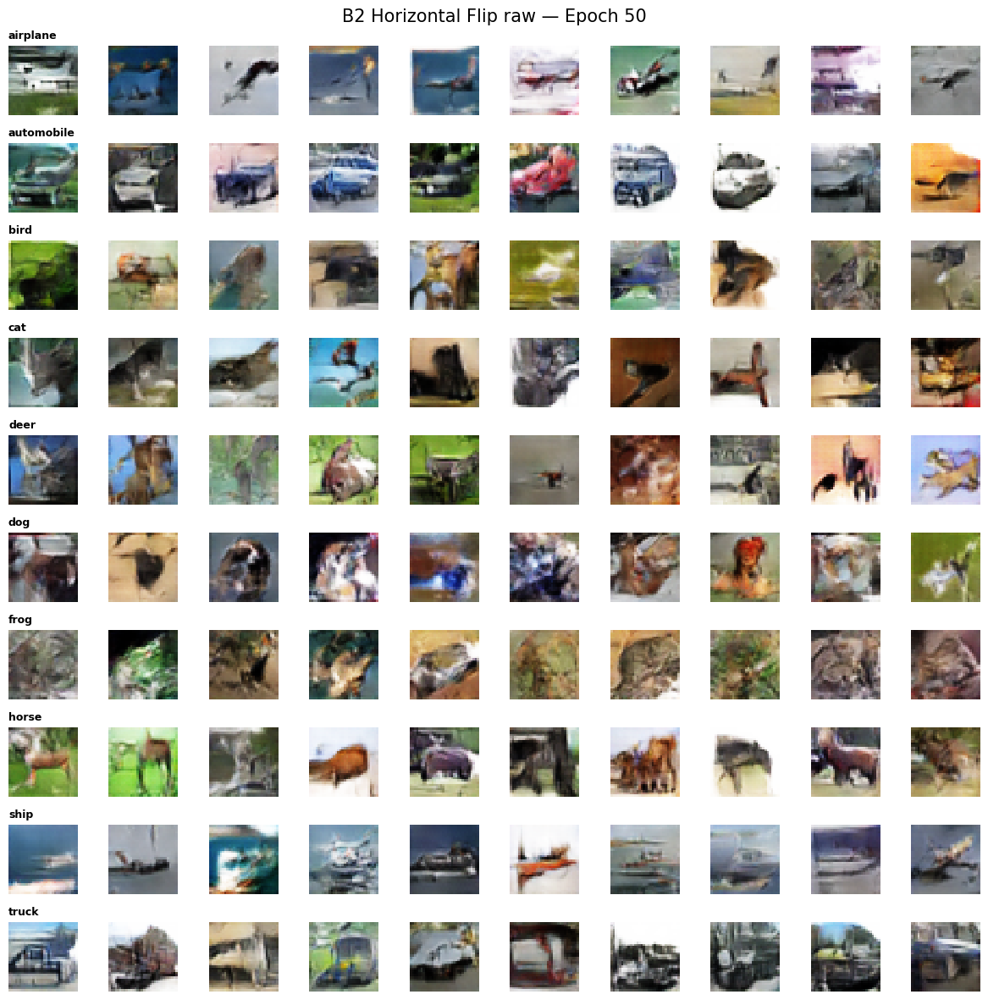

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_050.png
Epoch 051/100 | G 2.1091 | D 0.5936 | D(real) 0.7899 | D(fake) 0.2098 | D acc 0.9021 | 19.4s
Epoch 052/100 | G 2.1465 | D 0.5464 | D(real) 0.7976 | D(fake) 0.2017 | D acc 0.9107 | 19.6s
Epoch 053/100 | G 2.1956 | D 0.5732 | D(real) 0.7998 | D(fake) 0.1992 | D acc 0.9117 | 19.8s
Epoch 054/100 | G 2.1722 | D 0.6673 | D(real) 0.7833 | D(fake) 0.2153 | D acc 0.8868 | 19.4s
Epoch 055/100 | G 2.1685 | D 0.5497 | D(real) 0.8026 | D(fake) 0.1977 | D acc 0.9155 | 19.5s
Epoch 056/100 | G 2.2221 | D 0.5488 | D(real) 0.8045 | D(fake) 0.1944 | D acc 0.9156 | 19.4s
Epoch 057/100 | G 2.2256 | D 0.6107 | D(real) 0.7964 | D(fake) 0.2038 | D acc 0.9003 | 19.5s
Epoch 058/100 | G 2.2782 | D 0.4803 | D(real) 0.8166 | D(fake) 0.1820 | D acc 0.9280 | 19.4s
Epoch 059/100 | G 2.2833 | D 0.5641 | D(real) 0.8041 | D(fake) 0.1958 | D acc 0.9047 | 19.5s
Epoch 060/100 | G 2.2800 | D 0.5422 | D(real) 0.8117 | D(fake

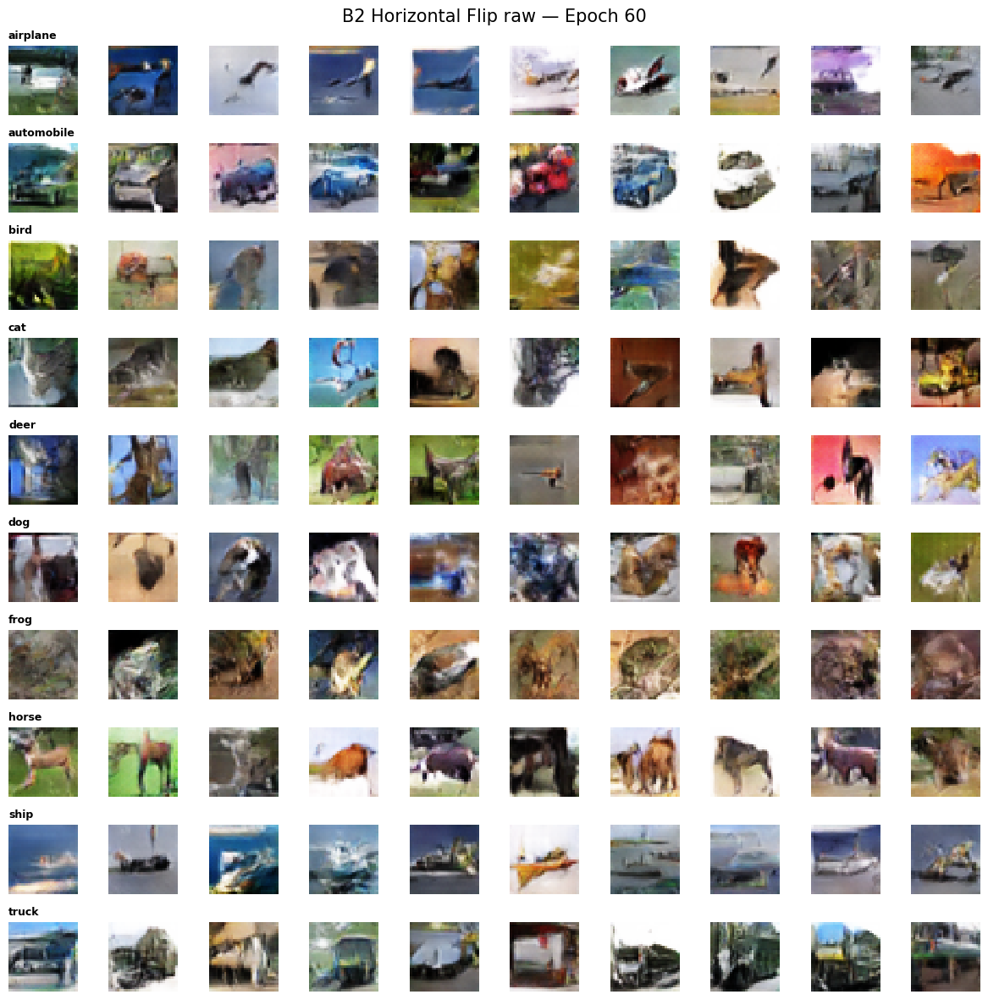

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_060.png
Epoch 061/100 | G 2.3165 | D 0.5295 | D(real) 0.8122 | D(fake) 0.1868 | D acc 0.9172 | 19.7s
Epoch 062/100 | G 2.3585 | D 0.4939 | D(real) 0.8171 | D(fake) 0.1820 | D acc 0.9203 | 19.4s
Epoch 063/100 | G 2.3712 | D 0.5918 | D(real) 0.8089 | D(fake) 0.1914 | D acc 0.9051 | 19.6s
Epoch 064/100 | G 2.3719 | D 0.4792 | D(real) 0.8258 | D(fake) 0.1747 | D acc 0.9316 | 19.5s
Epoch 065/100 | G 2.3466 | D 0.5493 | D(real) 0.8122 | D(fake) 0.1860 | D acc 0.9164 | 19.6s
Epoch 066/100 | G 2.4466 | D 0.5692 | D(real) 0.8201 | D(fake) 0.1795 | D acc 0.9187 | 19.4s
Epoch 067/100 | G 2.4054 | D 0.4435 | D(real) 0.8322 | D(fake) 0.1671 | D acc 0.9389 | 19.5s
Epoch 068/100 | G 2.4633 | D 0.4410 | D(real) 0.8340 | D(fake) 0.1651 | D acc 0.9370 | 19.5s
Epoch 069/100 | G 2.5051 | D 0.5036 | D(real) 0.8309 | D(fake) 0.1681 | D acc 0.9318 | 19.5s
Epoch 070/100 | G 2.5124 | D 0.4301 | D(real) 0.8366 | D(fake

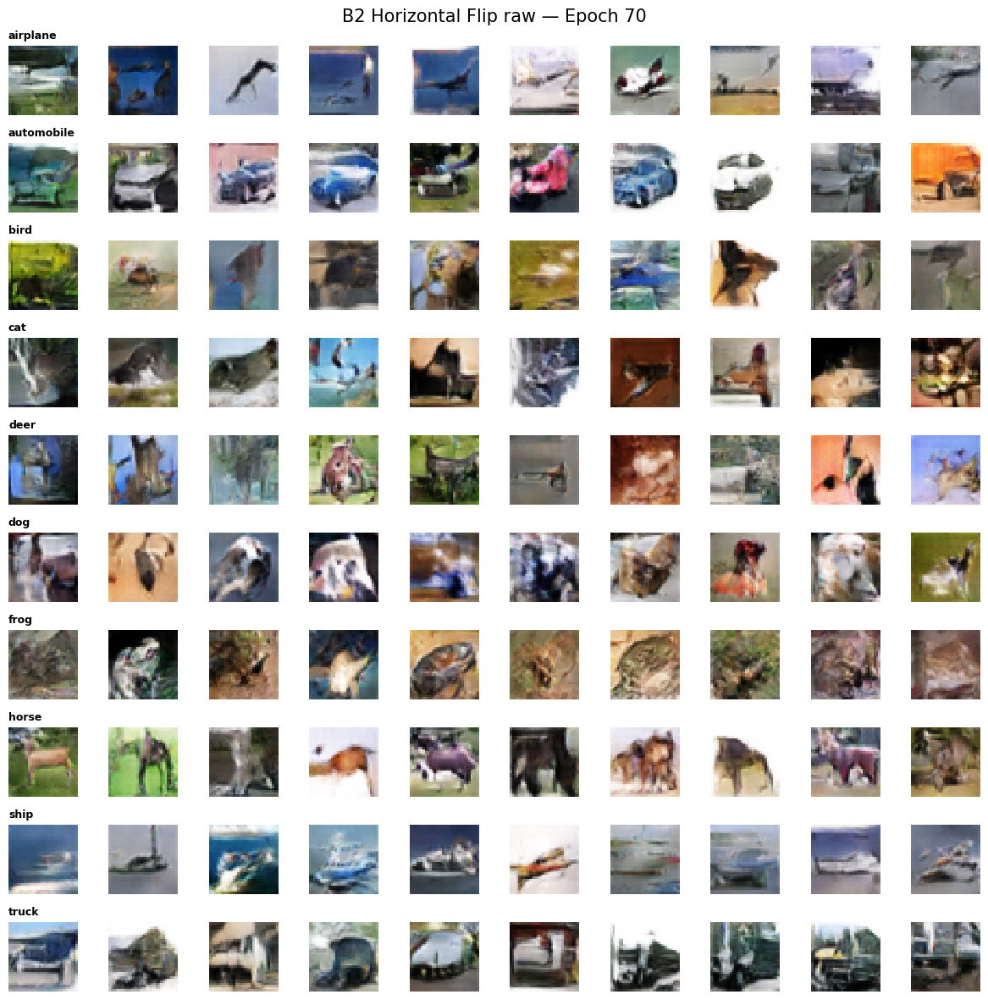

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_070.png
Epoch 071/100 | G 2.4581 | D 0.5936 | D(real) 0.8176 | D(fake) 0.1815 | D acc 0.9140 | 19.5s
Epoch 072/100 | G 2.5465 | D 0.4995 | D(real) 0.8348 | D(fake) 0.1656 | D acc 0.9318 | 19.9s
Epoch 073/100 | G 2.5192 | D 0.4324 | D(real) 0.8384 | D(fake) 0.1610 | D acc 0.9376 | 19.5s
Epoch 074/100 | G 2.5468 | D 0.5084 | D(real) 0.8326 | D(fake) 0.1667 | D acc 0.9288 | 19.5s
Epoch 075/100 | G 2.5882 | D 0.4033 | D(real) 0.8455 | D(fake) 0.1538 | D acc 0.9424 | 19.5s
Epoch 076/100 | G 2.6217 | D 0.4965 | D(real) 0.8362 | D(fake) 0.1634 | D acc 0.9292 | 19.6s
Epoch 077/100 | G 2.5995 | D 0.4921 | D(real) 0.8376 | D(fake) 0.1620 | D acc 0.9299 | 19.4s
Epoch 078/100 | G 2.5936 | D 0.4480 | D(real) 0.8403 | D(fake) 0.1594 | D acc 0.9329 | 19.4s
Epoch 079/100 | G 2.5999 | D 0.4630 | D(real) 0.8408 | D(fake) 0.1583 | D acc 0.9347 | 19.4s
Epoch 080/100 | G 2.6704 | D 0.4615 | D(real) 0.8476 | D(fake

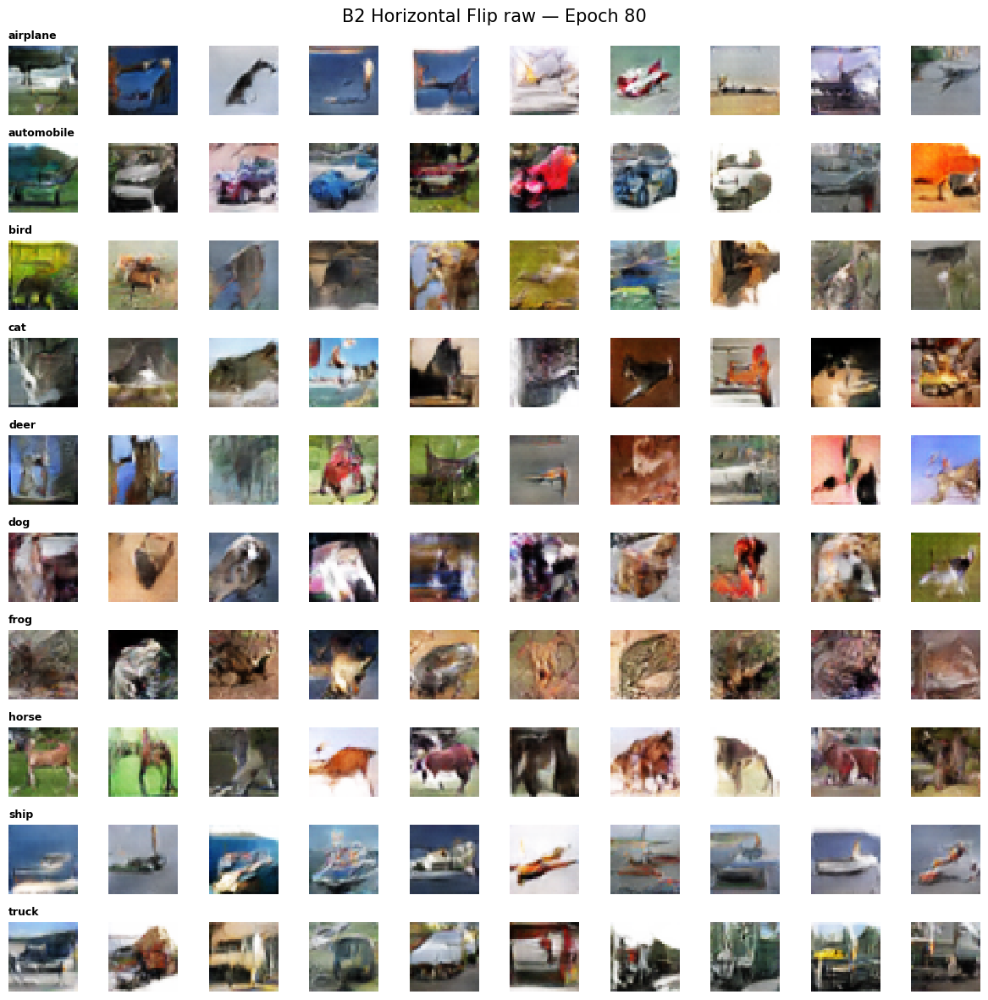

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_080.png
Epoch 081/100 | G 2.6787 | D 0.4425 | D(real) 0.8471 | D(fake) 0.1524 | D acc 0.9390 | 19.7s
Epoch 082/100 | G 2.6691 | D 0.3865 | D(real) 0.8517 | D(fake) 0.1492 | D acc 0.9430 | 19.8s
Epoch 083/100 | G 2.7201 | D 0.4799 | D(real) 0.8385 | D(fake) 0.1601 | D acc 0.9233 | 19.7s
Epoch 084/100 | G 2.7689 | D 0.3611 | D(real) 0.8601 | D(fake) 0.1387 | D acc 0.9501 | 19.8s
Epoch 085/100 | G 2.7104 | D 0.4706 | D(real) 0.8491 | D(fake) 0.1505 | D acc 0.9383 | 19.8s
Epoch 086/100 | G 2.7549 | D 0.3876 | D(real) 0.8604 | D(fake) 0.1393 | D acc 0.9505 | 19.9s
Epoch 087/100 | G 2.7717 | D 0.4215 | D(real) 0.8561 | D(fake) 0.1432 | D acc 0.9434 | 19.9s
Epoch 088/100 | G 2.7454 | D 0.5091 | D(real) 0.8475 | D(fake) 0.1527 | D acc 0.9329 | 19.9s
Epoch 089/100 | G 2.8381 | D 0.3276 | D(real) 0.8692 | D(fake) 0.1301 | D acc 0.9587 | 19.8s
Epoch 090/100 | G 2.7449 | D 0.5451 | D(real) 0.8383 | D(fake

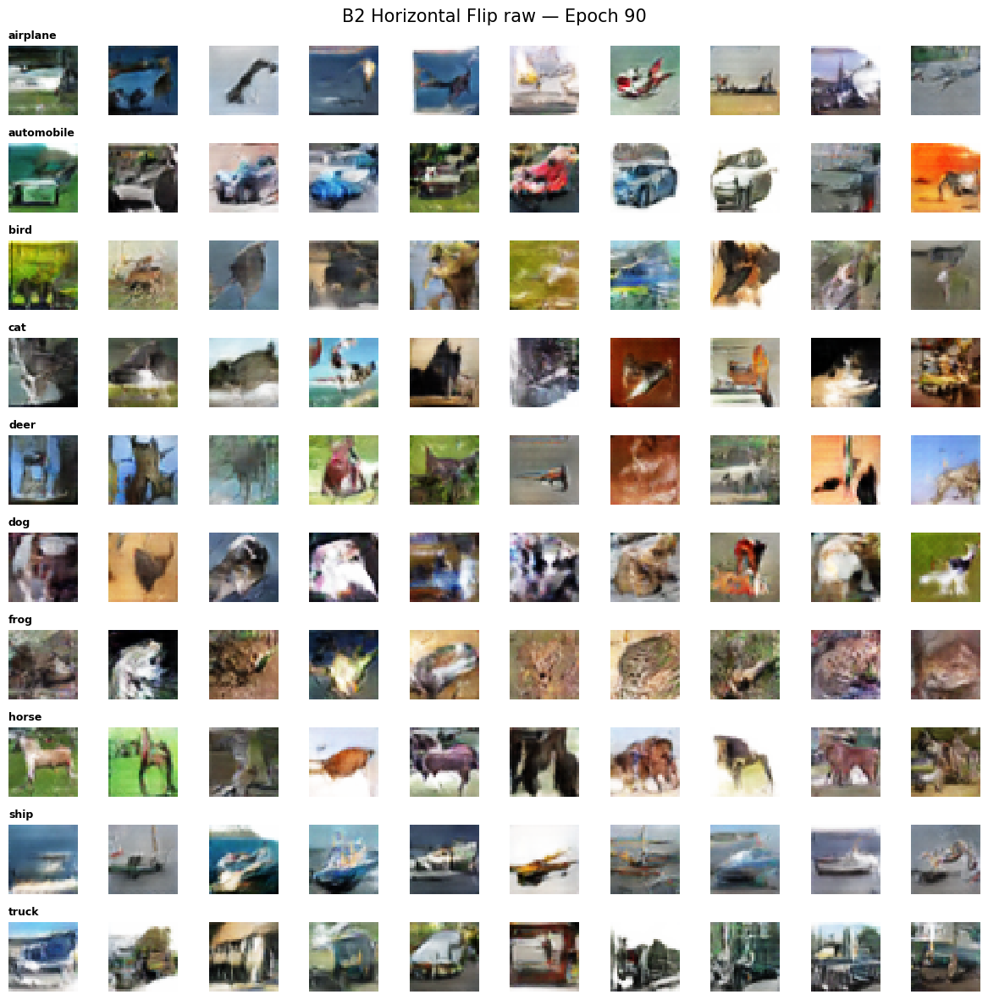

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_090.png
Epoch 091/100 | G 2.8299 | D 0.3670 | D(real) 0.8667 | D(fake) 0.1331 | D acc 0.9526 | 19.9s
Epoch 092/100 | G 2.8328 | D 0.4454 | D(real) 0.8533 | D(fake) 0.1463 | D acc 0.9332 | 19.8s
Epoch 093/100 | G 2.8533 | D 0.4512 | D(real) 0.8588 | D(fake) 0.1409 | D acc 0.9449 | 19.8s
Epoch 094/100 | G 2.8641 | D 0.3070 | D(real) 0.8771 | D(fake) 0.1233 | D acc 0.9652 | 20.0s
Epoch 095/100 | G 2.8436 | D 0.5051 | D(real) 0.8468 | D(fake) 0.1521 | D acc 0.9267 | 19.9s
Epoch 096/100 | G 2.8585 | D 0.4340 | D(real) 0.8606 | D(fake) 0.1387 | D acc 0.9466 | 20.1s
Epoch 097/100 | G 2.9551 | D 0.3733 | D(real) 0.8756 | D(fake) 0.1251 | D acc 0.9563 | 19.9s
Epoch 098/100 | G 2.8928 | D 0.3837 | D(real) 0.8629 | D(fake) 0.1357 | D acc 0.9450 | 20.1s
Epoch 099/100 | G 2.9958 | D 0.2963 | D(real) 0.8835 | D(fake) 0.1162 | D acc 0.9670 | 19.8s
Epoch 100/100 | G 2.9608 | D 0.4785 | D(real) 0.8586 | D(fake

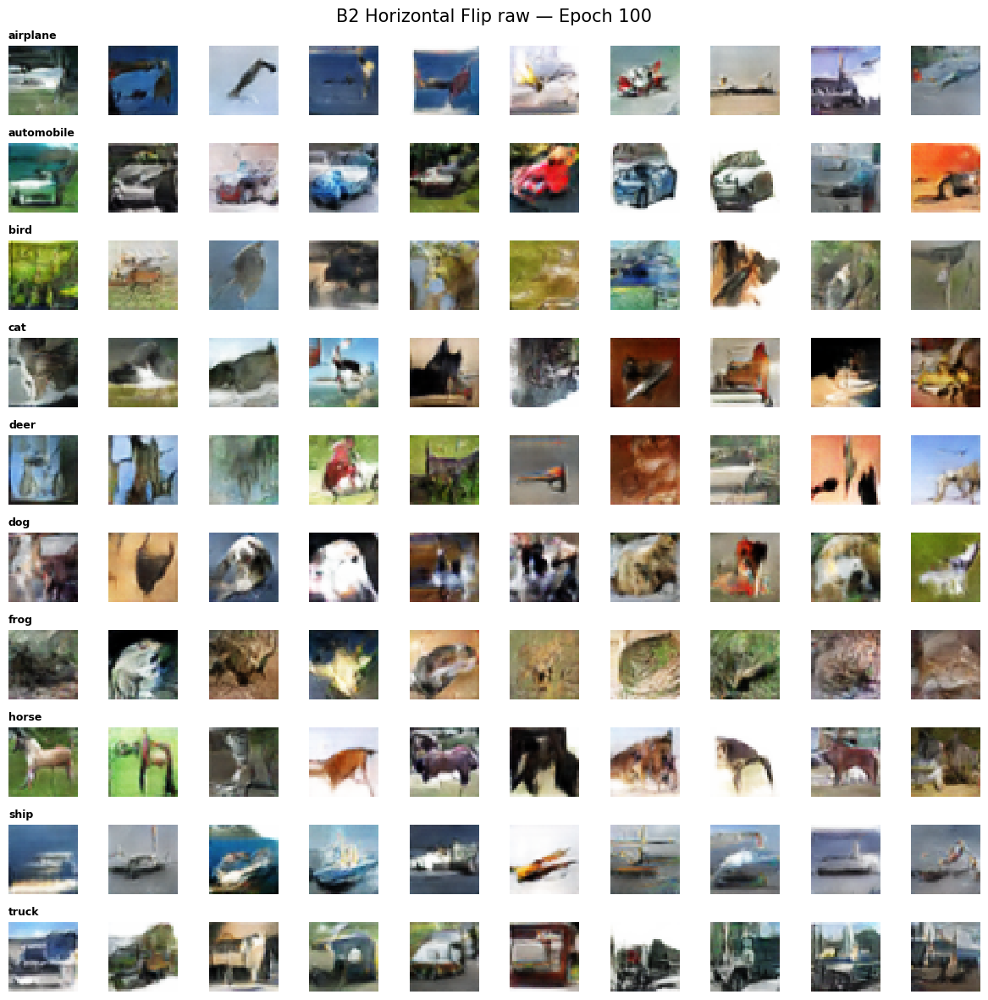

Saved grid: HeinHtetPartA_outputs\B2_horizontal_flip\generated_grids_raw\generated_grid_epoch_100.png
Completed B2 Horizontal Flip: 100 epochs recorded.


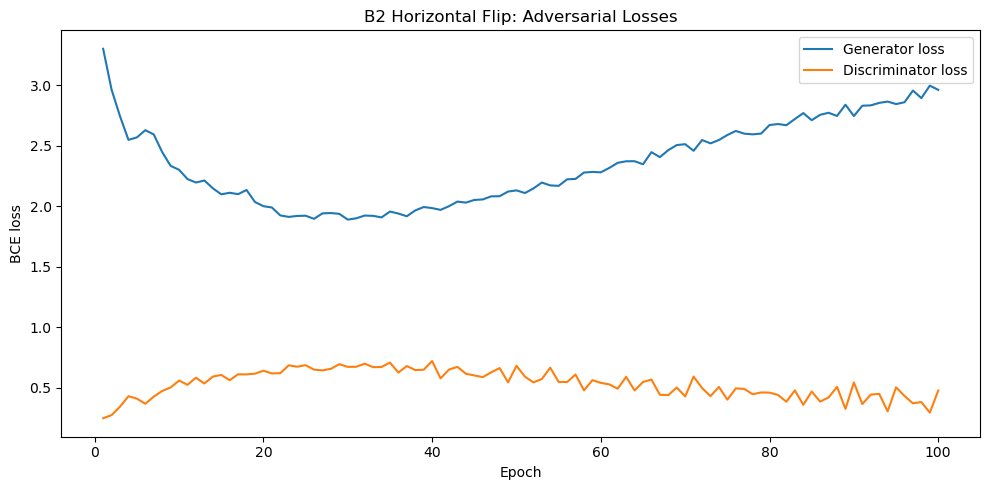

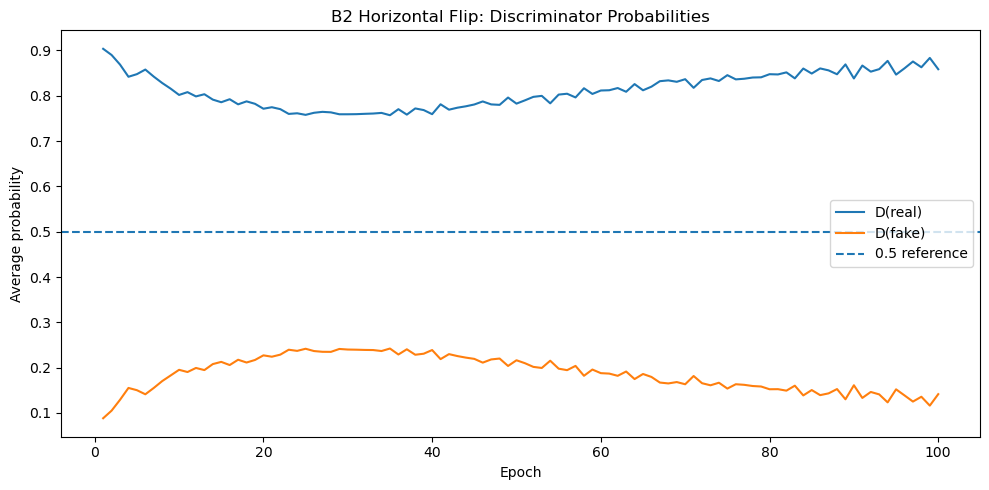

In [44]:
B2_RESULT = execute_fresh_experiment(
    run_name="B2_horizontal_flip",
    run_label="B2 Horizontal Flip",
    augmentation_function=horizontal_flip_policy,
)


### B2 Training Assessment

B2 applies random horizontal flipping to both real and generated images before
discriminator evaluation while keeping the conditional DCGAN architecture and
main training configuration unchanged. The purpose was to test whether a simple
label-preserving differentiable augmentation could improve generalisation
without allowing the discriminator to distinguish samples based on the presence
or absence of augmentation.

Training remained numerically stable throughout all 100 epochs. The generator
loss decreased from approximately 3.3 at the beginning to around 1.9 between
epochs 25 and 35, indicating that the generator initially became more effective
at challenging the discriminator. After this point, the generator loss
gradually increased and reached approximately 3.0 near epoch 100.

The discriminator loss followed the opposite pattern. It rose from about 0.25
to approximately 0.7 during the first third of training before gradually
declining to around 0.4 near the end. This indicates that the generator became
more competitive during the early and middle stages, but the discriminator
regained an advantage later in training.

The discriminator-probability plot supports this interpretation. `D(real)`
started near 0.90, decreased to approximately 0.76 during the middle of the run,
and then increased to about 0.86 by the final epochs. Meanwhile, `D(fake)` rose
from approximately 0.09 to around 0.24 before declining to approximately 0.13.
Therefore, the discriminator remained stronger than the generator by the end
of training.

Despite this imbalance, there was no clear evidence of complete training
collapse. The losses remained finite, the curves changed gradually, and neither
network showed an extreme or unstable numerical pattern. The horizontal-flip
augmentation therefore did not destabilise the adversarial training process.

The training losses were not used directly to select the best checkpoint
because GAN losses do not reliably measure perceptual image quality. FID was
used as the primary checkpoint-selection metric, KID was used as supporting
evidence, and the saved fixed-input class grids were used only to verify that
the quantitative results were not contradicted by an obvious visual failure.

#### B2 FID/KID Evaluation — Run After B2 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B2: epoch 10, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 010 | raw | FID 123.5171 | KID 0.108518 ± 0.008732
Evaluating B2: epoch 20, raw...
Epoch 020 | raw | FID 71.3088 | KID 0.046275 ± 0.005252
Evaluating B2: epoch 30, raw...
Epoch 030 | raw | FID 54.0184 | KID 0.030641 ± 0.004268
Evaluating B2: epoch 40, raw...
Epoch 040 | raw | FID 57.6504 | KID 0.037179 ± 0.005559
Evaluating B2: epoch 50, raw...
Epoch 050 | raw | FID 43.1863 | KID 0.020622 ± 0.003868
Evaluating B2: epoch 60, raw...
Epoch 060 | raw | FID 41.7155 | KID 0.020518 ± 0.004413
Evaluating B2: epoch 70, raw...
Epoch 070 | raw | FID 40.4236 | KID 0.019567 ± 0.003800
Evaluating B2: epoch 80, raw...
Epoch 080 | raw | FID 40.2072 | KID 0.019673 ± 0.003893
Evaluating B2: epoch 90, raw...
Epoch 090 | raw | FID 38.3497 | KID 0.017669 ± 0.00

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B2,B2_horizontal_flip,10,raw,123.5171,0.108518,0.008732,5000
1,B2,B2_horizontal_flip,20,raw,71.3088,0.046275,0.005252,5000
2,B2,B2_horizontal_flip,30,raw,54.0184,0.030641,0.004268,5000
3,B2,B2_horizontal_flip,40,raw,57.6504,0.037179,0.005559,5000
4,B2,B2_horizontal_flip,50,raw,43.1863,0.020622,0.003868,5000
5,B2,B2_horizontal_flip,60,raw,41.7155,0.020518,0.004413,5000
6,B2,B2_horizontal_flip,70,raw,40.4236,0.019567,0.003800,5000
7,B2,B2_horizontal_flip,80,raw,40.2072,0.019673,0.003893,5000
8,B2,B2_horizontal_flip,90,raw,38.3497,0.017669,0.003354,5000
9,B2,B2_horizontal_flip,100,raw,37.3169,0.017210,0.003439,5000


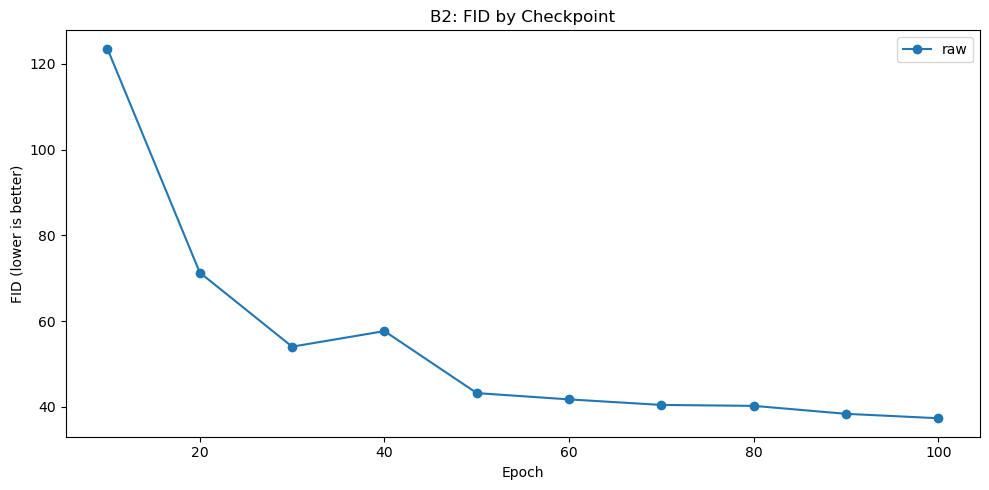

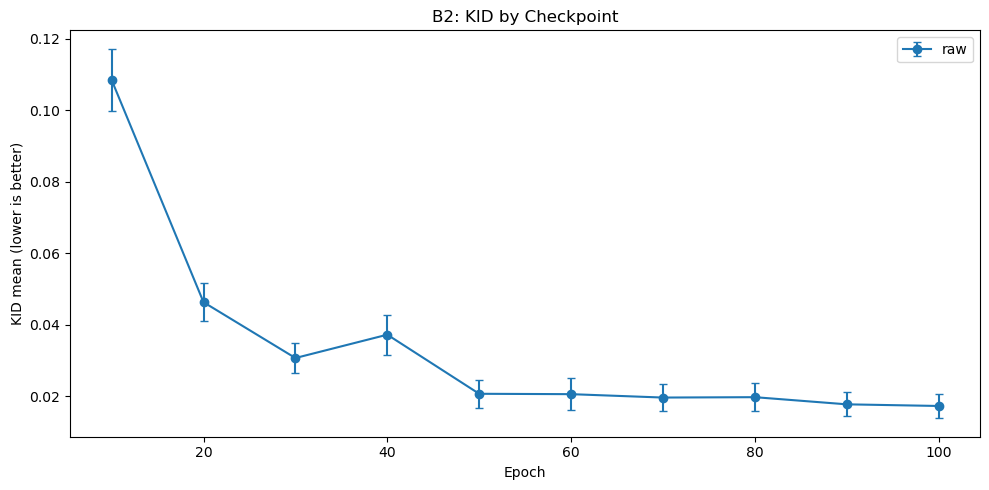

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B2_horizontal_flip\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [45]:
B2_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B2",
    run_name="B2_horizontal_flip",
    candidates=("raw",),
    expected_epochs=range(10, 101, 10),
)


### B2 Review

- **Chosen B2 epoch:** 100
- **FID:** 37.3169
- **KID mean ± standard deviation:** 0.017210 ± 0.003439
- **Decision:** Retained as the strongest B2 checkpoint and as an improvement
  over B0 and B1.

### Checkpoint Selection

Epoch 100 was selected manually because it achieved the lowest FID among all
evaluated B2 checkpoints. FID decreased substantially from 123.5171 at epoch 10
to 37.3169 at epoch 100. There was a temporary regression at epoch 40, where
FID increased from 54.0184 to 57.6504, but the overall trend continued to
improve after that point.

KID was used as supporting evidence. Epoch 100 also achieved the lowest KID
mean of 0.017210. The KID uncertainty overlaps with several nearby late
checkpoints, so KID alone does not prove that epoch 100 is substantially better
than every nearby checkpoint. However, its result is consistent with the
FID-based selection.

### Comparison with Earlier Experiments

Compared with B1, B2 reduced FID by approximately 1.0952 points. Compared with
the original B0 baseline, it reduced FID by approximately 3.3121 points. B2
also achieved the lowest KID mean among the three experiments.

These results indicate that horizontal flipping produced a small but consistent
improvement in the generated-image feature distribution. The augmentation
increased the variety of training presentations without changing the number of
stored CIFAR-10 images or altering their class labels.

### Visual Verification

The saved class-balanced grid for epoch 100 was used only as a verification
step. Its purpose was to check that the low FID and KID values were not caused
by an obvious failure such as severe mode collapse, repeated outputs, major
artefacts or complete loss of conditional class structure.

The visual check did not provide a reason to reject the checkpoint and was
therefore consistent with the quantitative findings. It was not used as the
main checkpoint-selection method.

### Augmentation Conclusion

Horizontal flipping was retained as a successful modification. B2 achieved
better FID and KID results than both B0 and B1 while maintaining stable
training. This suggests that simple label-preserving spatial augmentation
helped the model generalise better to the CIFAR-10 image distribution.

- **Visual label counts:** Not completed for B2 because the full
  `clear/marginal / nonsense` assessment was reserved for the strongest
  final candidates.
- **Requested-class match observations:** General conditional consistency was
  checked using the fixed-input class grid, while the detailed requested class
  Matching was reserved for the final shortlisted models.


### 8.4 B3 — Small Translation Augmentation

### Hypothesis

Small translations may reduce the discriminator's sensitivity to exact object
placement. B3 tests translations of up to two pixels horizontally and
vertically, applied to both real and generated images before discriminator
evaluation.

B3 is a fresh run using the fixed B0 architecture and learning rates. No
horizontal flip or colour transformation is included. This keeps translation as
the only intended change and does not depend on an automatically selected
earlier champion (Zhao et al., 2020).


Epoch 001/100 | G 4.0434 | D 0.1984 | D(real) 0.9268 | D(fake) 0.0675 | D acc 0.9709 | 80.3s
Epoch 002/100 | G 2.8163 | D 0.3953 | D(real) 0.8575 | D(fake) 0.1379 | D acc 0.9361 | 77.8s
Epoch 003/100 | G 2.3957 | D 0.4643 | D(real) 0.8309 | D(fake) 0.1692 | D acc 0.9219 | 77.5s
Epoch 004/100 | G 2.2916 | D 0.5266 | D(real) 0.8097 | D(fake) 0.1900 | D acc 0.9017 | 83.5s
Epoch 005/100 | G 2.2814 | D 0.5591 | D(real) 0.8052 | D(fake) 0.1946 | D acc 0.9011 | 82.5s
Epoch 006/100 | G 2.2275 | D 0.5312 | D(real) 0.8063 | D(fake) 0.1925 | D acc 0.9091 | 82.1s
Epoch 007/100 | G 2.0498 | D 0.6208 | D(real) 0.7780 | D(fake) 0.2212 | D acc 0.8786 | 83.0s
Epoch 008/100 | G 1.9233 | D 0.6539 | D(real) 0.7652 | D(fake) 0.2342 | D acc 0.8721 | 81.0s
Epoch 009/100 | G 1.9235 | D 0.6686 | D(real) 0.7628 | D(fake) 0.2373 | D acc 0.8712 | 79.3s
Epoch 010/100 | G 1.8742 | D 0.6952 | D(real) 0.7526 | D(fake) 0.2451 | D acc 0.8608 | 81.0s
Saved checkpoint: HeinHtetPartA_outputs\B3_translation_2px\checkpoints

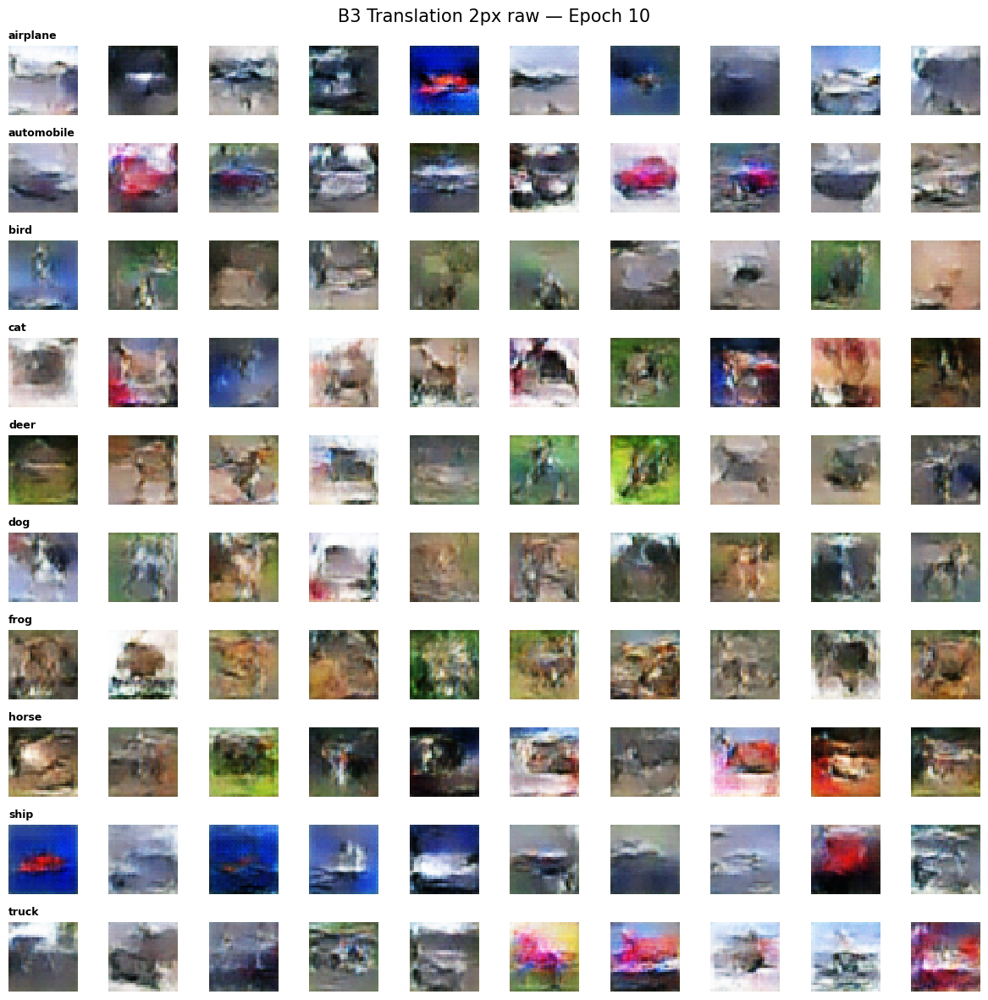

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_010.png
Epoch 011/100 | G 1.8851 | D 0.6614 | D(real) 0.7609 | D(fake) 0.2369 | D acc 0.8806 | 81.5s
Epoch 012/100 | G 1.8842 | D 0.6884 | D(real) 0.7590 | D(fake) 0.2401 | D acc 0.8750 | 79.2s
Epoch 013/100 | G 1.8999 | D 0.6644 | D(real) 0.7608 | D(fake) 0.2377 | D acc 0.8762 | 80.6s
Epoch 014/100 | G 1.8350 | D 0.7104 | D(real) 0.7509 | D(fake) 0.2488 | D acc 0.8681 | 81.8s
Epoch 015/100 | G 1.8498 | D 0.7049 | D(real) 0.7507 | D(fake) 0.2476 | D acc 0.8676 | 79.5s
Epoch 016/100 | G 1.8634 | D 0.6806 | D(real) 0.7581 | D(fake) 0.2405 | D acc 0.8758 | 80.5s
Epoch 017/100 | G 1.8803 | D 0.6559 | D(real) 0.7611 | D(fake) 0.2378 | D acc 0.8788 | 82.3s
Epoch 018/100 | G 1.8818 | D 0.6518 | D(real) 0.7638 | D(fake) 0.2349 | D acc 0.8865 | 79.4s
Epoch 019/100 | G 1.8927 | D 0.6676 | D(real) 0.7616 | D(fake) 0.2375 | D acc 0.8795 | 81.4s
Epoch 020/100 | G 1.8438 | D 0.6611 | D(real) 0.7588 | D(fake

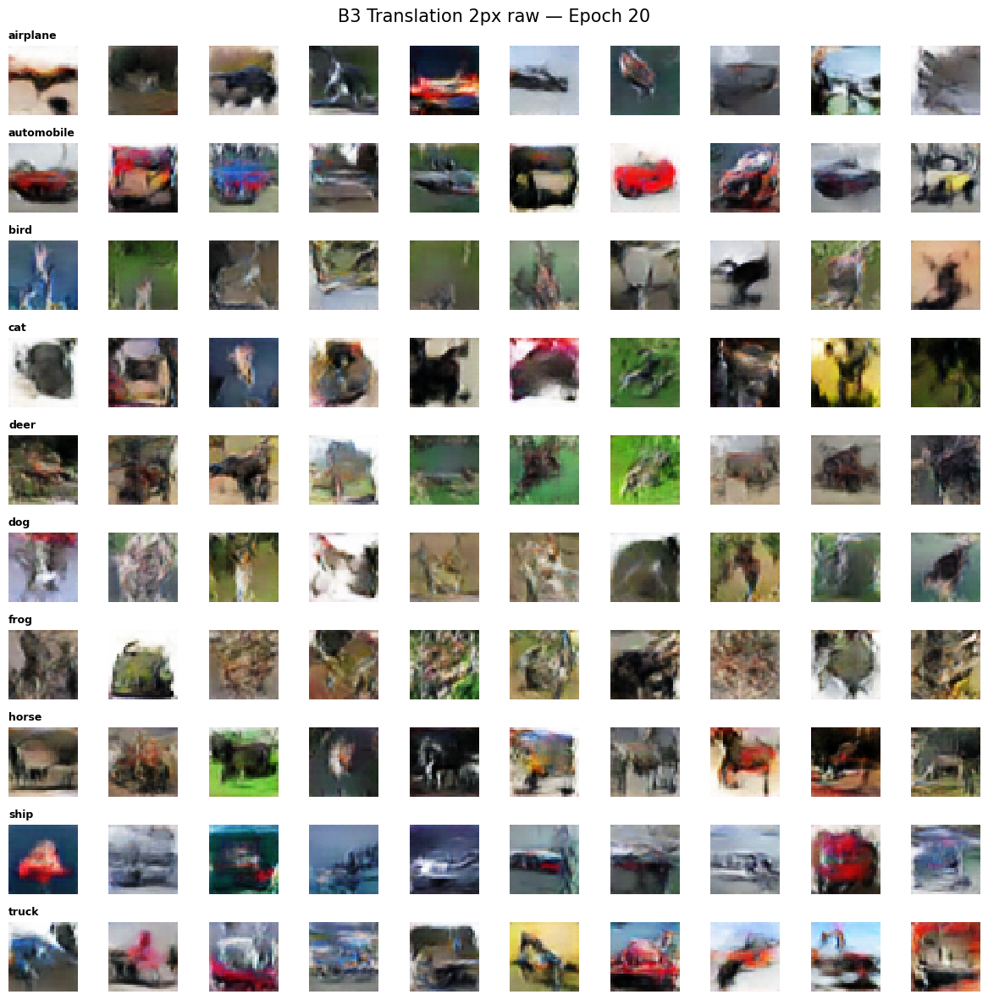

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_020.png
Epoch 021/100 | G 1.8907 | D 0.6981 | D(real) 0.7549 | D(fake) 0.2451 | D acc 0.8691 | 78.9s
Epoch 022/100 | G 1.8961 | D 0.7263 | D(real) 0.7499 | D(fake) 0.2484 | D acc 0.8608 | 81.3s
Epoch 023/100 | G 1.8085 | D 0.6800 | D(real) 0.7557 | D(fake) 0.2448 | D acc 0.8838 | 83.1s
Epoch 024/100 | G 1.8576 | D 0.6880 | D(real) 0.7559 | D(fake) 0.2426 | D acc 0.8764 | 83.3s
Epoch 025/100 | G 1.8574 | D 0.6448 | D(real) 0.7631 | D(fake) 0.2364 | D acc 0.8865 | 81.9s
Epoch 026/100 | G 1.8662 | D 0.6810 | D(real) 0.7570 | D(fake) 0.2422 | D acc 0.8764 | 83.9s
Epoch 027/100 | G 1.8749 | D 0.6721 | D(real) 0.7580 | D(fake) 0.2419 | D acc 0.8742 | 82.9s
Epoch 028/100 | G 1.8528 | D 0.6783 | D(real) 0.7558 | D(fake) 0.2440 | D acc 0.8736 | 82.8s
Epoch 029/100 | G 1.8734 | D 0.6755 | D(real) 0.7569 | D(fake) 0.2412 | D acc 0.8724 | 84.1s
Epoch 030/100 | G 1.8870 | D 0.7378 | D(real) 0.7556 | D(fake

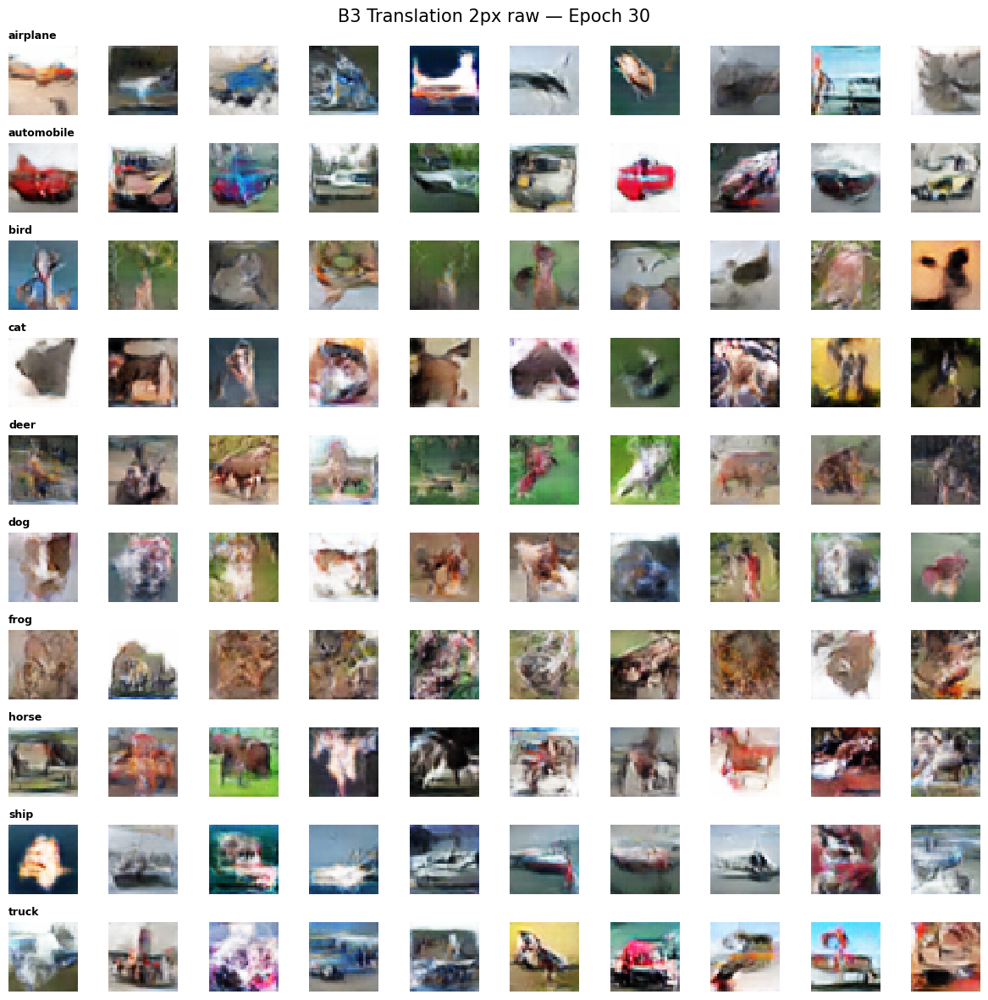

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_030.png
Epoch 031/100 | G 1.8703 | D 0.6799 | D(real) 0.7599 | D(fake) 0.2392 | D acc 0.8841 | 82.6s
Epoch 032/100 | G 1.8896 | D 0.6605 | D(real) 0.7649 | D(fake) 0.2339 | D acc 0.8893 | 80.8s
Epoch 033/100 | G 1.9003 | D 0.6597 | D(real) 0.7640 | D(fake) 0.2358 | D acc 0.8865 | 84.9s
Epoch 034/100 | G 1.8714 | D 0.6896 | D(real) 0.7585 | D(fake) 0.2409 | D acc 0.8784 | 81.7s
Epoch 035/100 | G 1.9004 | D 0.7025 | D(real) 0.7565 | D(fake) 0.2426 | D acc 0.8706 | 82.6s
Epoch 036/100 | G 1.9202 | D 0.5983 | D(real) 0.7743 | D(fake) 0.2249 | D acc 0.9005 | 84.7s
Epoch 037/100 | G 1.9237 | D 0.7127 | D(real) 0.7597 | D(fake) 0.2390 | D acc 0.8755 | 80.3s
Epoch 038/100 | G 1.8985 | D 0.6477 | D(real) 0.7673 | D(fake) 0.2331 | D acc 0.8901 | 80.8s
Epoch 039/100 | G 1.9338 | D 0.6430 | D(real) 0.7693 | D(fake) 0.2300 | D acc 0.8892 | 80.5s
Epoch 040/100 | G 1.9714 | D 0.6637 | D(real) 0.7692 | D(fake

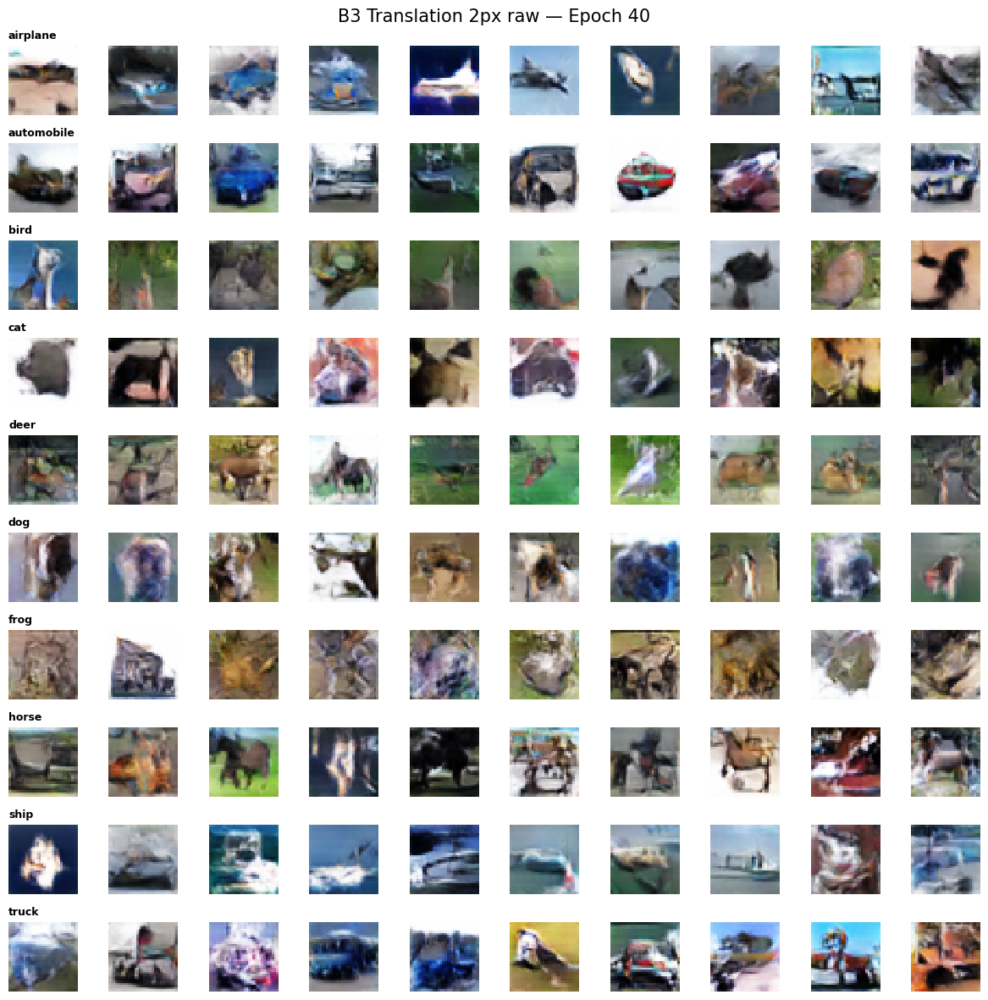

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_040.png
Epoch 041/100 | G 1.9710 | D 0.6419 | D(real) 0.7697 | D(fake) 0.2305 | D acc 0.8800 | 80.8s
Epoch 042/100 | G 1.9870 | D 0.6359 | D(real) 0.7711 | D(fake) 0.2280 | D acc 0.8809 | 79.9s
Epoch 043/100 | G 1.9682 | D 0.6870 | D(real) 0.7681 | D(fake) 0.2315 | D acc 0.8851 | 79.9s
Epoch 044/100 | G 1.9950 | D 0.6209 | D(real) 0.7778 | D(fake) 0.2218 | D acc 0.8960 | 80.9s
Epoch 045/100 | G 2.0042 | D 0.6245 | D(real) 0.7783 | D(fake) 0.2213 | D acc 0.8971 | 79.0s
Epoch 046/100 | G 2.0144 | D 0.5791 | D(real) 0.7849 | D(fake) 0.2136 | D acc 0.9018 | 79.0s
Epoch 047/100 | G 2.0306 | D 0.6545 | D(real) 0.7744 | D(fake) 0.2253 | D acc 0.8839 | 80.0s
Epoch 048/100 | G 2.0452 | D 0.6255 | D(real) 0.7793 | D(fake) 0.2209 | D acc 0.8873 | 78.5s
Epoch 049/100 | G 2.0494 | D 0.5565 | D(real) 0.7893 | D(fake) 0.2097 | D acc 0.9068 | 80.7s
Epoch 050/100 | G 2.0850 | D 0.5886 | D(real) 0.7880 | D(fake

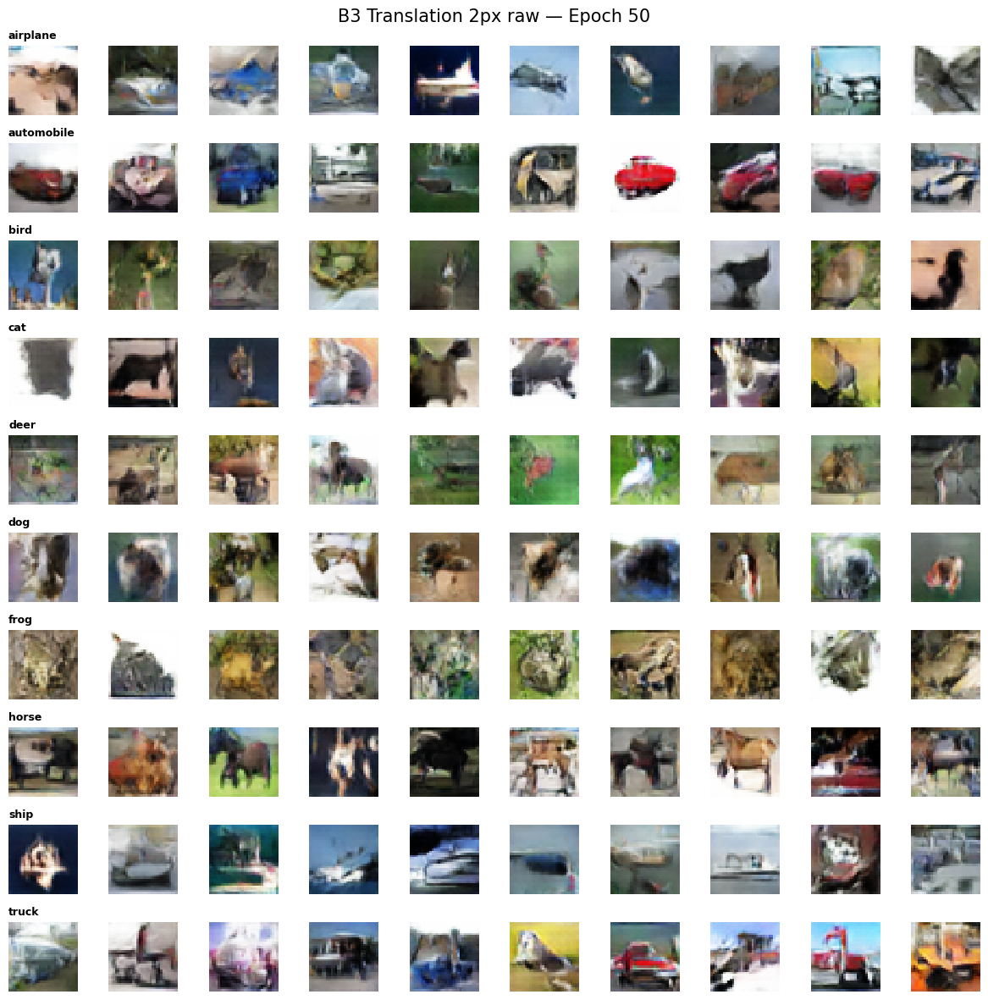

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_050.png
Epoch 051/100 | G 2.0924 | D 0.5938 | D(real) 0.7881 | D(fake) 0.2113 | D acc 0.8996 | 80.3s
Epoch 052/100 | G 2.1163 | D 0.5843 | D(real) 0.7897 | D(fake) 0.2097 | D acc 0.8971 | 80.0s
Epoch 053/100 | G 2.1554 | D 0.6186 | D(real) 0.7852 | D(fake) 0.2138 | D acc 0.8876 | 79.9s
Epoch 054/100 | G 2.1309 | D 0.5889 | D(real) 0.7913 | D(fake) 0.2090 | D acc 0.8990 | 79.2s
Epoch 055/100 | G 2.1360 | D 0.6192 | D(real) 0.7894 | D(fake) 0.2103 | D acc 0.8971 | 79.2s
Epoch 056/100 | G 2.1183 | D 0.5080 | D(real) 0.8044 | D(fake) 0.1941 | D acc 0.9231 | 80.1s
Epoch 057/100 | G 2.1561 | D 0.6440 | D(real) 0.7906 | D(fake) 0.2099 | D acc 0.8971 | 79.5s
Epoch 058/100 | G 2.1632 | D 0.6366 | D(real) 0.7923 | D(fake) 0.2071 | D acc 0.9011 | 78.7s
Epoch 059/100 | G 2.1711 | D 0.5081 | D(real) 0.8071 | D(fake) 0.1926 | D acc 0.9204 | 80.4s
Epoch 060/100 | G 2.1897 | D 0.6098 | D(real) 0.7936 | D(fake

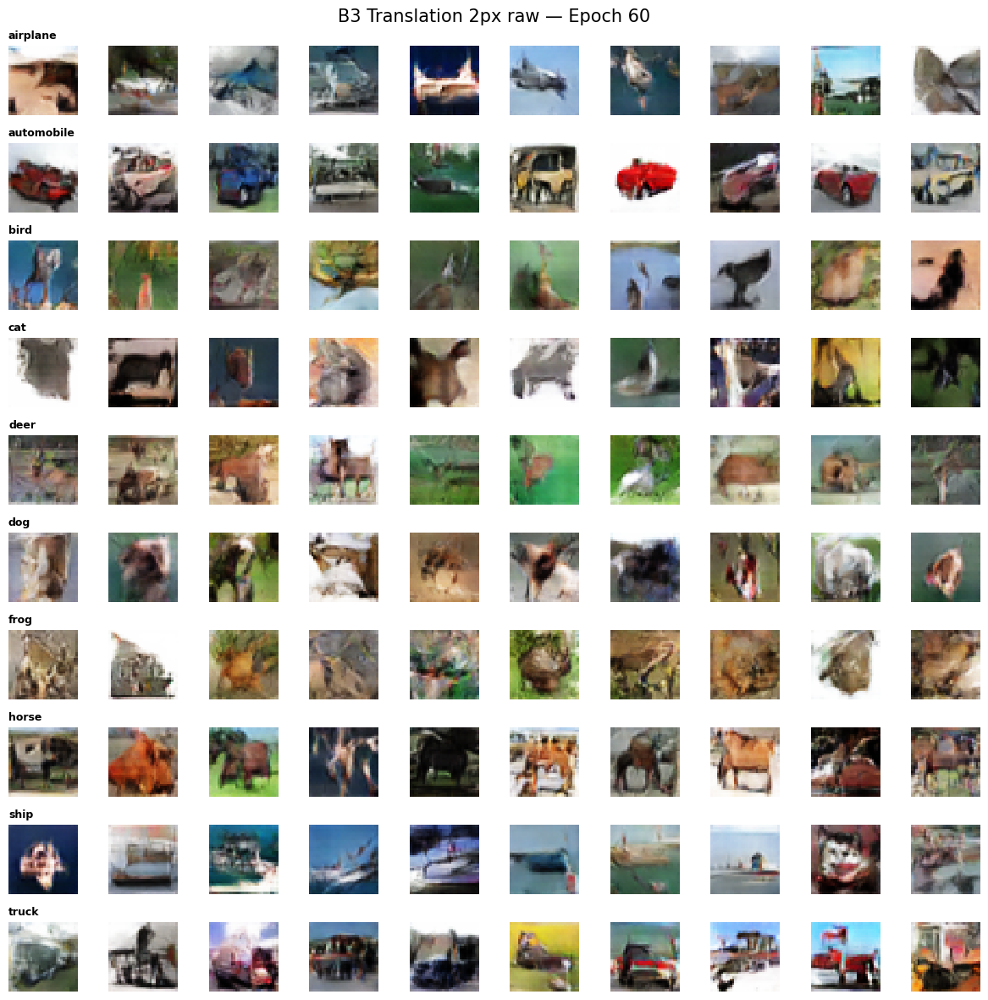

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_060.png
Epoch 061/100 | G 2.1779 | D 0.5698 | D(real) 0.7969 | D(fake) 0.2023 | D acc 0.9043 | 81.0s
Epoch 062/100 | G 2.3351 | D 0.6046 | D(real) 0.8073 | D(fake) 0.1916 | D acc 0.9066 | 80.9s
Epoch 063/100 | G 2.1982 | D 0.5078 | D(real) 0.8075 | D(fake) 0.1922 | D acc 0.9174 | 79.4s
Epoch 064/100 | G 2.2067 | D 0.5501 | D(real) 0.8052 | D(fake) 0.1945 | D acc 0.9154 | 79.3s
Epoch 065/100 | G 2.1979 | D 0.6279 | D(real) 0.7907 | D(fake) 0.2089 | D acc 0.8934 | 79.9s
Epoch 066/100 | G 2.2251 | D 0.5059 | D(real) 0.8107 | D(fake) 0.1890 | D acc 0.9210 | 77.5s
Epoch 067/100 | G 2.2572 | D 0.5413 | D(real) 0.8094 | D(fake) 0.1903 | D acc 0.9163 | 79.1s
Epoch 068/100 | G 2.3544 | D 0.5279 | D(real) 0.8179 | D(fake) 0.1822 | D acc 0.9163 | 80.2s
Epoch 069/100 | G 2.3776 | D 0.5871 | D(real) 0.8220 | D(fake) 0.1788 | D acc 0.9248 | 79.7s
Epoch 070/100 | G 2.2354 | D 0.5863 | D(real) 0.7994 | D(fake

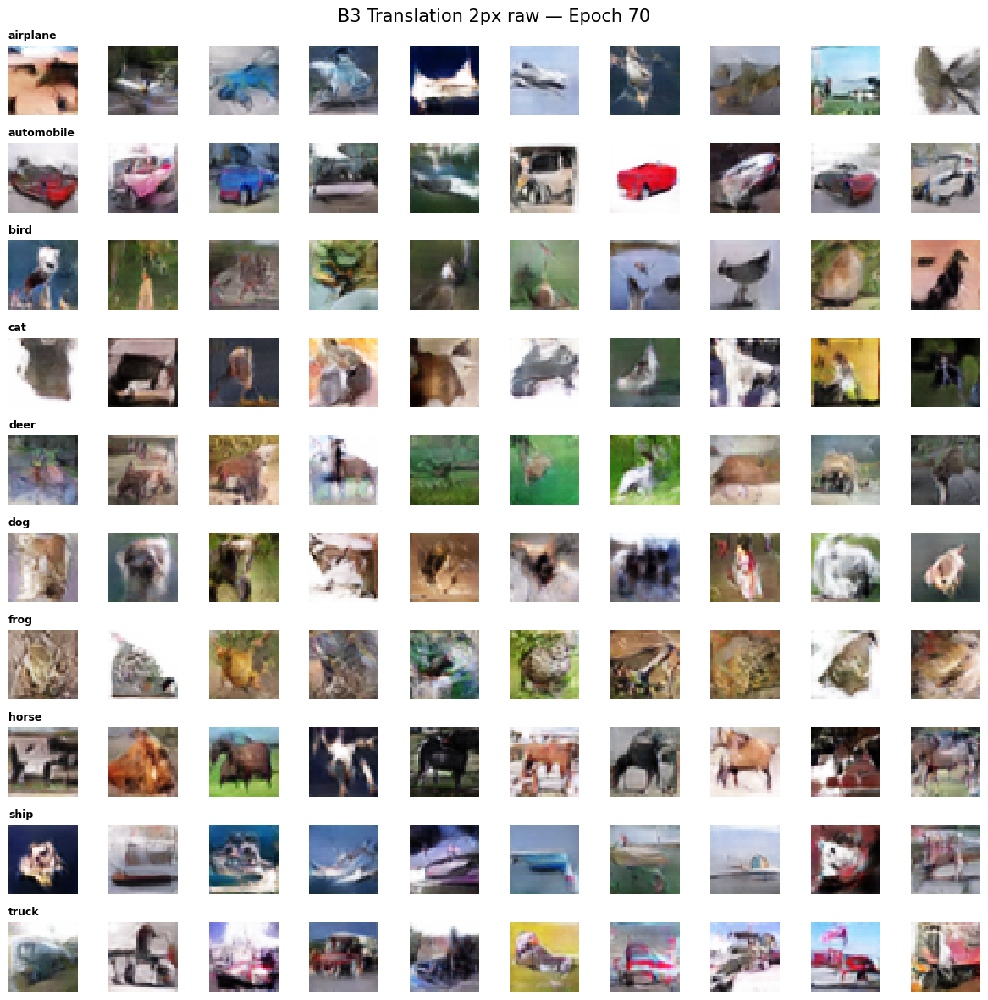

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_070.png
Epoch 071/100 | G 2.2963 | D 0.5571 | D(real) 0.8129 | D(fake) 0.1867 | D acc 0.9192 | 80.7s
Epoch 072/100 | G 2.2613 | D 0.5243 | D(real) 0.8124 | D(fake) 0.1869 | D acc 0.9217 | 81.1s
Epoch 073/100 | G 2.3647 | D 0.5481 | D(real) 0.8148 | D(fake) 0.1850 | D acc 0.9112 | 79.8s
Epoch 074/100 | G 2.5256 | D 0.4983 | D(real) 0.8293 | D(fake) 0.1696 | D acc 0.9198 | 80.8s
Epoch 075/100 | G 2.3715 | D 0.5196 | D(real) 0.8176 | D(fake) 0.1817 | D acc 0.9149 | 80.2s
Epoch 076/100 | G 2.3438 | D 0.5679 | D(real) 0.8113 | D(fake) 0.1887 | D acc 0.9100 | 80.4s
Epoch 077/100 | G 2.3292 | D 0.5804 | D(real) 0.8091 | D(fake) 0.1908 | D acc 0.9037 | 80.2s
Epoch 078/100 | G 2.4182 | D 0.4411 | D(real) 0.8346 | D(fake) 0.1646 | D acc 0.9362 | 78.7s
Epoch 079/100 | G 2.4255 | D 0.4659 | D(real) 0.8263 | D(fake) 0.1734 | D acc 0.9223 | 79.3s
Epoch 080/100 | G 2.4820 | D 0.4994 | D(real) 0.8319 | D(fake

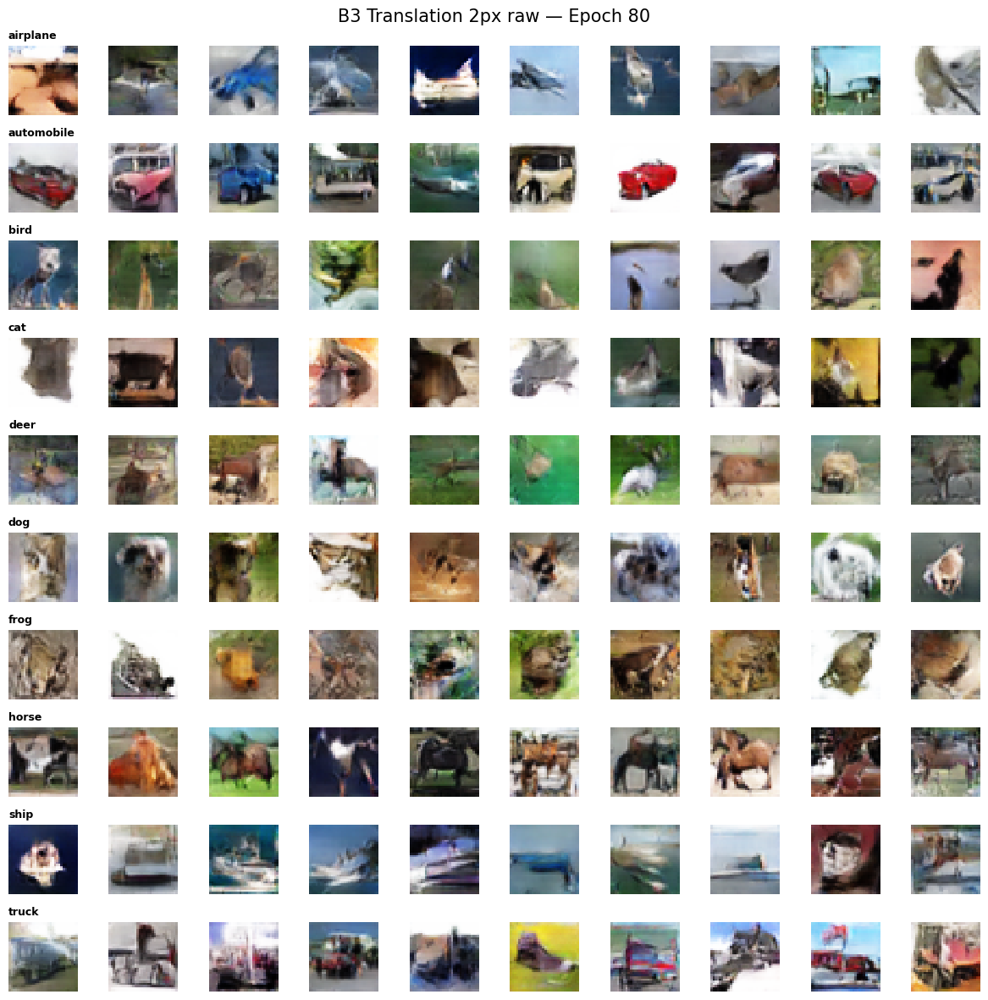

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_080.png
Epoch 081/100 | G 2.4237 | D 0.5140 | D(real) 0.8209 | D(fake) 0.1781 | D acc 0.9143 | 79.2s
Epoch 082/100 | G 2.4478 | D 0.5088 | D(real) 0.8236 | D(fake) 0.1771 | D acc 0.9163 | 79.3s
Epoch 083/100 | G 2.4231 | D 0.5225 | D(real) 0.8194 | D(fake) 0.1791 | D acc 0.9159 | 79.6s
Epoch 084/100 | G 2.4998 | D 0.5073 | D(real) 0.8294 | D(fake) 0.1713 | D acc 0.9214 | 79.3s
Epoch 085/100 | G 2.4706 | D 0.4520 | D(real) 0.8309 | D(fake) 0.1673 | D acc 0.9261 | 80.6s
Epoch 086/100 | G 2.4432 | D 0.5495 | D(real) 0.8180 | D(fake) 0.1829 | D acc 0.9049 | 79.5s
Epoch 087/100 | G 2.5215 | D 0.4893 | D(real) 0.8286 | D(fake) 0.1697 | D acc 0.9228 | 80.4s
Epoch 088/100 | G 2.5243 | D 0.4017 | D(real) 0.8444 | D(fake) 0.1556 | D acc 0.9414 | 79.3s
Epoch 089/100 | G 2.5493 | D 0.5051 | D(real) 0.8306 | D(fake) 0.1695 | D acc 0.9179 | 80.3s
Epoch 090/100 | G 2.5809 | D 0.4586 | D(real) 0.8376 | D(fake

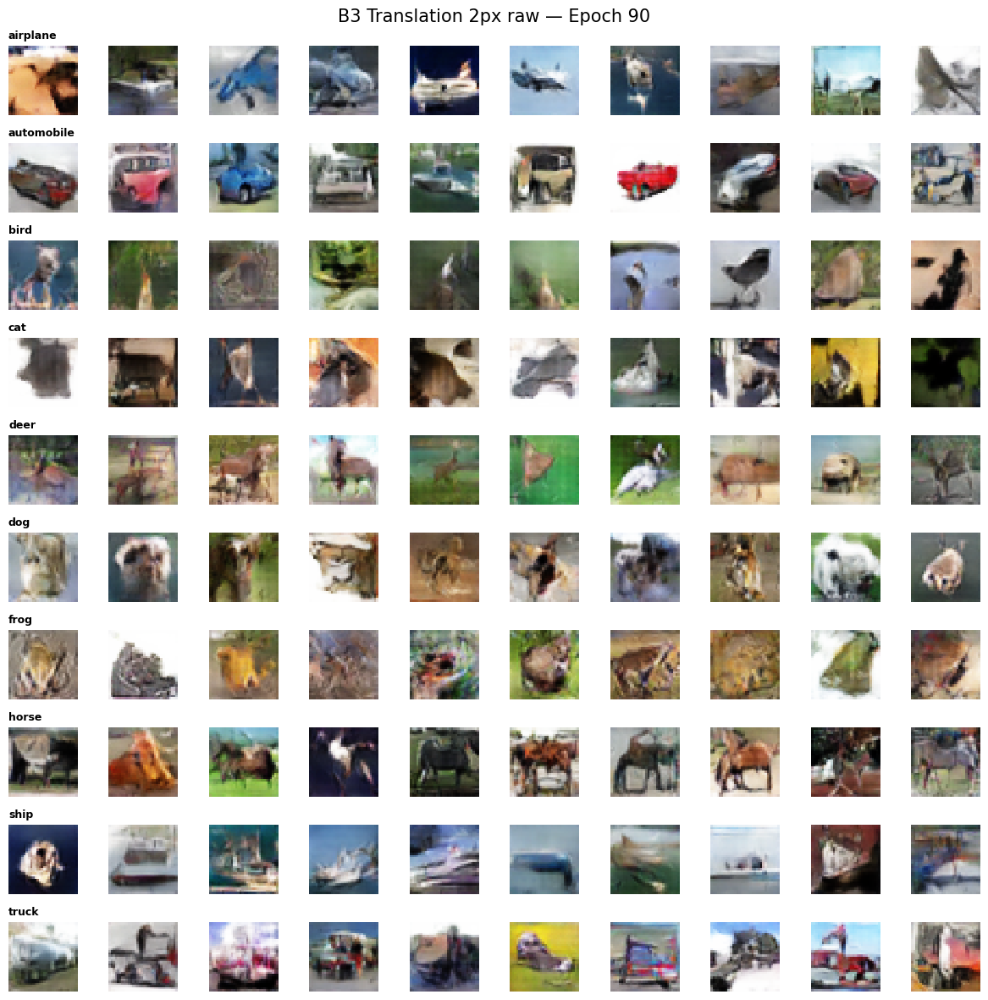

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_090.png
Epoch 091/100 | G 2.5229 | D 0.5040 | D(real) 0.8262 | D(fake) 0.1731 | D acc 0.9151 | 79.3s
Epoch 092/100 | G 2.6264 | D 0.4101 | D(real) 0.8466 | D(fake) 0.1530 | D acc 0.9374 | 79.4s
Epoch 093/100 | G 2.5713 | D 0.5029 | D(real) 0.8323 | D(fake) 0.1671 | D acc 0.9193 | 79.5s
Epoch 094/100 | G 2.5960 | D 0.5009 | D(real) 0.8292 | D(fake) 0.1710 | D acc 0.9099 | 78.7s
Epoch 095/100 | G 2.6859 | D 0.4603 | D(real) 0.8471 | D(fake) 0.1525 | D acc 0.9345 | 79.9s
Epoch 096/100 | G 2.6312 | D 0.4013 | D(real) 0.8487 | D(fake) 0.1508 | D acc 0.9386 | 79.5s
Epoch 097/100 | G 2.6298 | D 0.4482 | D(real) 0.8422 | D(fake) 0.1579 | D acc 0.9270 | 79.7s
Epoch 098/100 | G 2.7218 | D 0.4032 | D(real) 0.8535 | D(fake) 0.1457 | D acc 0.9384 | 81.0s
Epoch 099/100 | G 2.6641 | D 0.4520 | D(real) 0.8405 | D(fake) 0.1594 | D acc 0.9245 | 80.8s
Epoch 100/100 | G 2.7364 | D 0.4543 | D(real) 0.8493 | D(fake

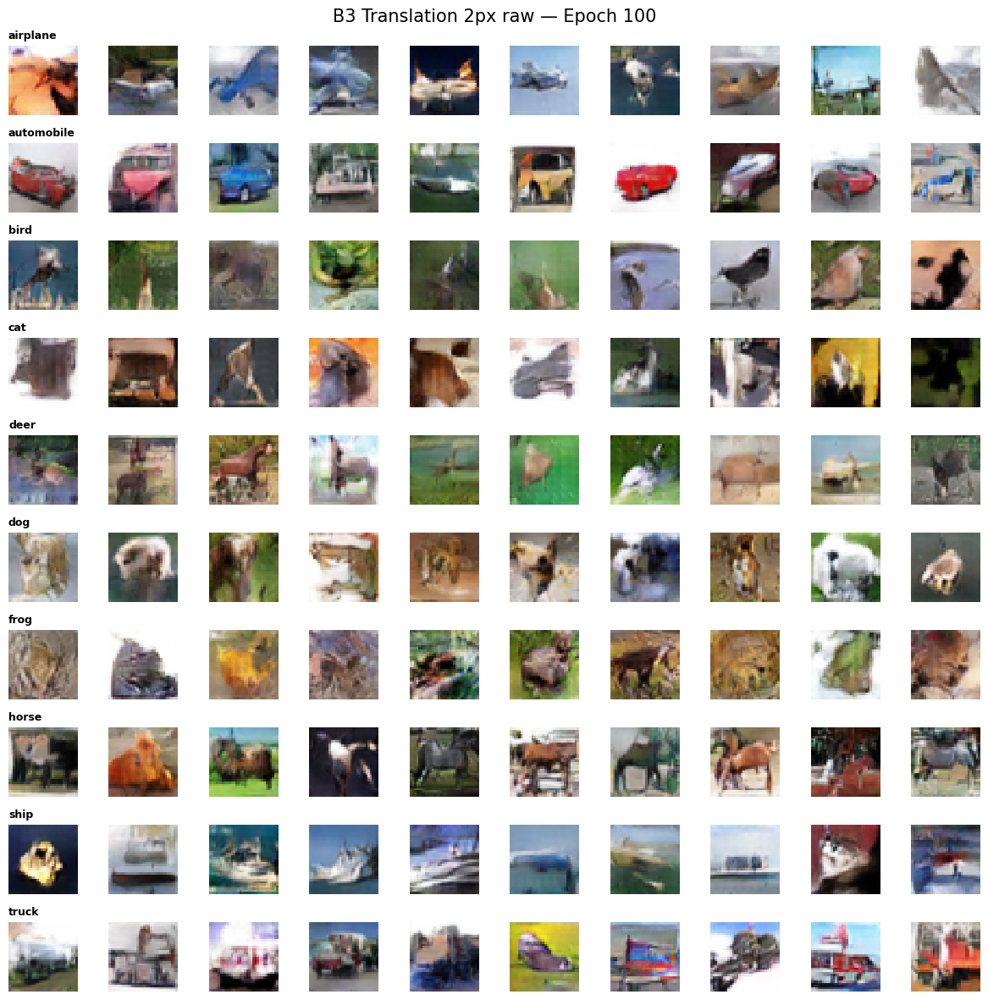

Saved grid: HeinHtetPartA_outputs\B3_translation_2px\generated_grids_raw\generated_grid_epoch_100.png
Completed B3 Translation 2px: 100 epochs recorded.


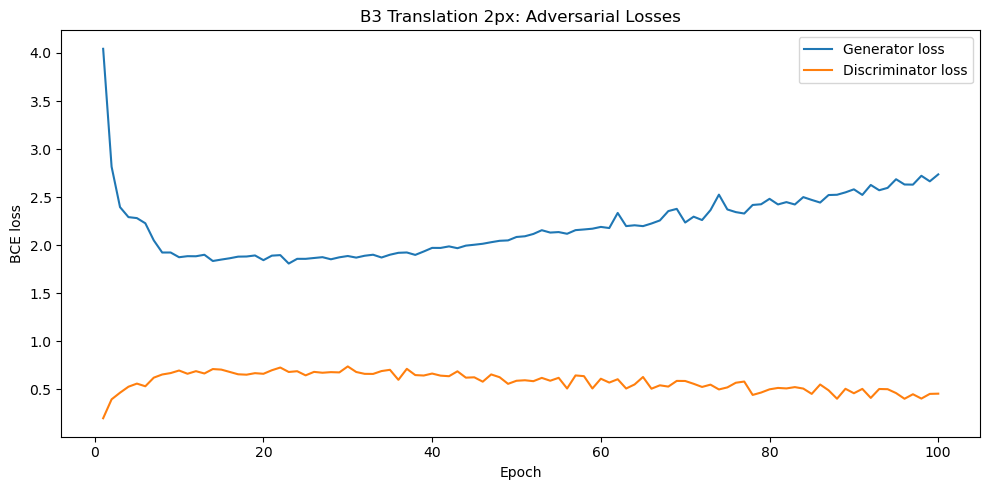

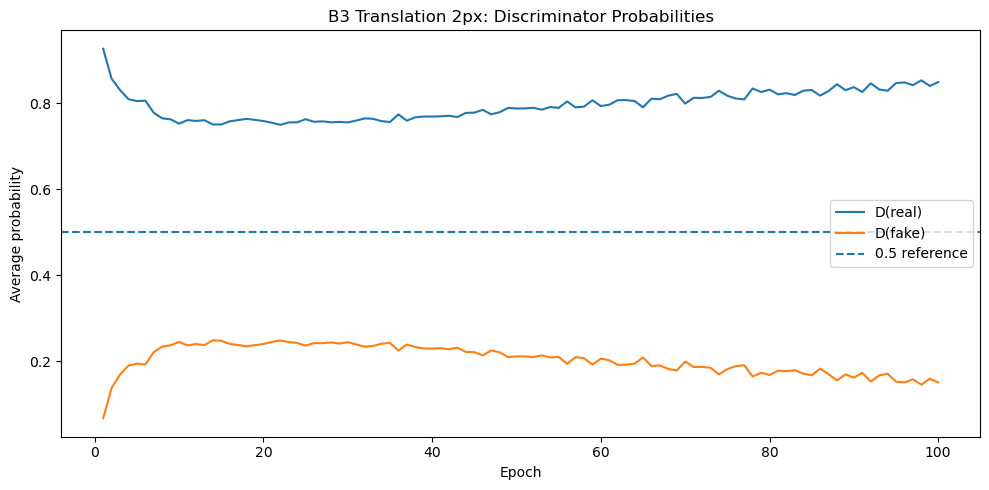

In [46]:
B3_RESULT = execute_fresh_experiment(
    run_name="B3_translation_2px",
    run_label="B3 Translation 2px",
    augmentation_function=translation_policy,
)


### B3 Training Assessment

B3 applies small random translations of up to two pixels to both real and
generated images before discriminator evaluation. The aim was to reduce the
discriminator's sensitivity to exact object positioning and encourage the
generator to learn more robust class-specific structures.

Training remained numerically stable across all 100 epochs. All generator and
discriminator losses remained finite, with no sudden divergence or evidence of
complete training collapse.

The generator loss decreased rapidly from approximately 4.0 to around 1.9
during the first 15 epochs. It then remained relatively stable until
approximately epoch 40, suggesting that the generator became substantially more
competitive during the early training period. After epoch 40, the generator
loss gradually increased and reached approximately 2.7 by epoch 100, indicating
that the discriminator became harder to fool during the later stages.

The discriminator loss initially increased from approximately 0.2 to around
0.7. It remained near this level during the early and middle stages before
gradually decreasing to approximately 0.45 by the final epoch. This pattern
shows that the generator initially challenged the discriminator more
effectively, although the discriminator later regained part of its advantage.

The discriminator-probability plot supports this interpretation. `D(real)`
decreased from above 0.90 to approximately 0.75 during the early epochs before
gradually increasing to around 0.85. At the same time, `D(fake)` increased from
approximately 0.07 to around 0.25 before gradually declining to approximately
0.15. The discriminator therefore remained stronger than the generator at the
end of training, but the changes were gradual rather than unstable.

Compared with the previous experiments, B3 maintained a reasonable adversarial
balance for a longer period and produced the strongest quantitative results so
far. The translation augmentation did not introduce numerical instability and
appears to have improved the model's ability to represent objects appearing at
slightly different positions.

The loss curves were not used directly to select the checkpoint because GAN
losses do not reliably measure perceptual image quality. FID was used as the
primary checkpoint-selection metric, KID was used as supporting evidence, and
the saved fixed-input class grids were inspected only to verify that the metric
results were not associated with severe mode collapse, repeated outputs, major
artefacts or loss of conditional class structure.

#### B3 FID/KID Evaluation — Run After B3 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B3: epoch 10, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 010 | raw | FID 102.9549 | KID 0.081637 ± 0.006571
Evaluating B3: epoch 20, raw...
Epoch 020 | raw | FID 61.1980 | KID 0.036236 ± 0.004933
Evaluating B3: epoch 30, raw...
Epoch 030 | raw | FID 49.3368 | KID 0.025518 ± 0.004223
Evaluating B3: epoch 40, raw...
Epoch 040 | raw | FID 50.5399 | KID 0.028210 ± 0.004929
Evaluating B3: epoch 50, raw...
Epoch 050 | raw | FID 42.7839 | KID 0.020538 ± 0.004055
Evaluating B3: epoch 60, raw...
Epoch 060 | raw | FID 37.8854 | KID 0.016884 ± 0.003512
Evaluating B3: epoch 70, raw...
Epoch 070 | raw | FID 41.0157 | KID 0.019061 ± 0.004127
Evaluating B3: epoch 80, raw...
Epoch 080 | raw | FID 37.7504 | KID 0.017187 ± 0.003823
Evaluating B3: epoch 90, raw...
Epoch 090 | raw | FID 36.8900 | KID 0.017265 ± 0.00

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B3,B3_translation_2px,10,raw,102.9549,0.081637,0.006571,5000
1,B3,B3_translation_2px,20,raw,61.1980,0.036236,0.004933,5000
2,B3,B3_translation_2px,30,raw,49.3368,0.025518,0.004223,5000
3,B3,B3_translation_2px,40,raw,50.5399,0.028210,0.004929,5000
4,B3,B3_translation_2px,50,raw,42.7839,0.020538,0.004055,5000
5,B3,B3_translation_2px,60,raw,37.8854,0.016884,0.003512,5000
6,B3,B3_translation_2px,70,raw,41.0157,0.019061,0.004127,5000
7,B3,B3_translation_2px,80,raw,37.7504,0.017187,0.003823,5000
8,B3,B3_translation_2px,90,raw,36.8900,0.017265,0.004286,5000
9,B3,B3_translation_2px,100,raw,34.1947,0.014281,0.003679,5000


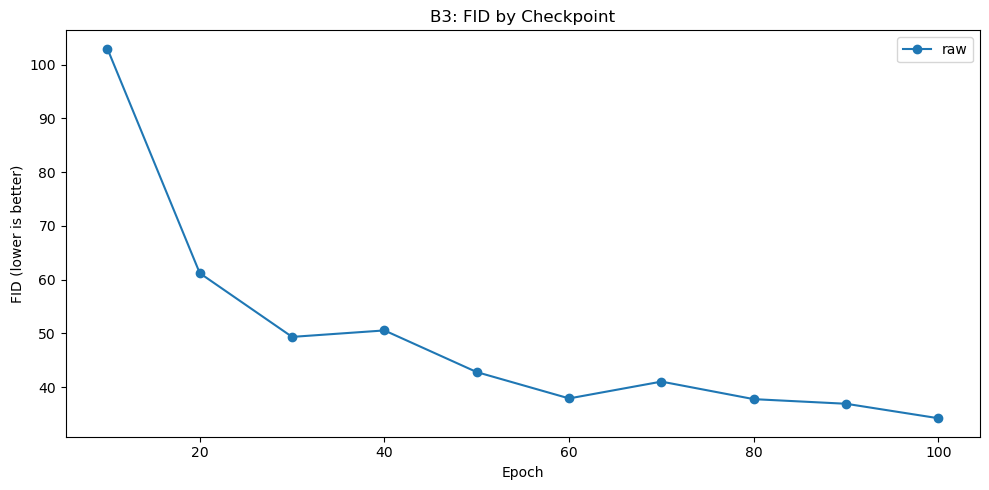

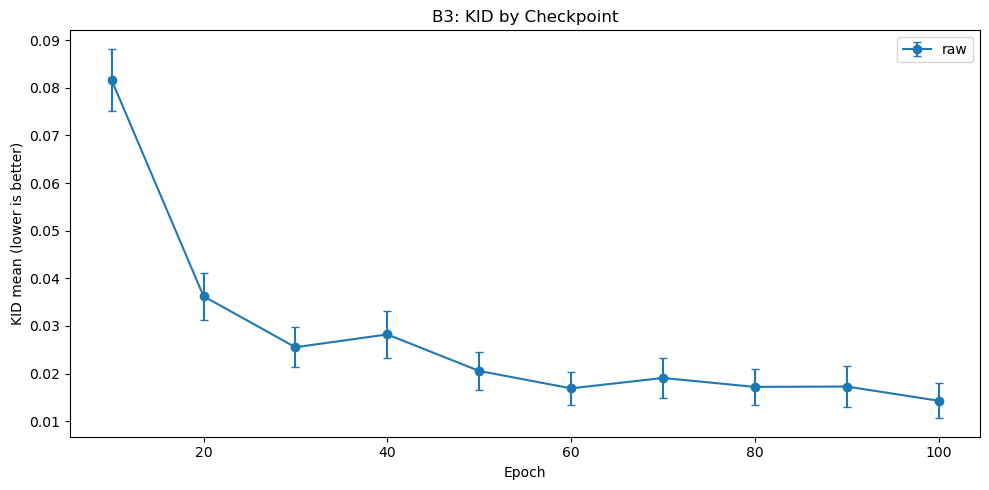

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B3_translation_2px\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [47]:
B3_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B3",
    run_name="B3_translation_2px",
    candidates=("raw",),
    expected_epochs=range(10, 101, 10),
)


### B3 Manual Review

- **Chosen B3 epoch:** 100
- **FID:** 34.1947
- **KID mean ± standard deviation:** 0.014281 ± 0.003679
- **Decision:** Retained as the strongest B3 checkpoint and the best experiment
  evaluated so far.

### Checkpoint Selection

Epoch 100 was selected manually because it achieved the lowest FID among all
evaluated B3 checkpoints. FID decreased from 102.9549 at epoch 10 to 34.1947 at
epoch 100, showing a substantial overall improvement in the generated-image
feature distribution.

The improvement was not perfectly continuous. FID temporarily increased at
epochs 40 and 70, indicating normal variation in adversarial training.
Nevertheless, the later checkpoints generally produced better results, and
epoch 100 achieved the lowest final value.

KID was used as supporting evidence. Epoch 100 also achieved the lowest KID
mean of 0.014281. Although its uncertainty interval overlaps with some nearby
late checkpoints, the KID result is consistent with the FID-based selection.
Both quantitative metrics therefore support choosing epoch 100.

### Comparison with Earlier Experiments

B3 reduced FID by approximately 3.1222 points compared with B2 and by
approximately 6.4343 points compared with the original B0 baseline. It also
achieved the lowest KID mean among the four experiments.

These results indicate that small random translations were more effective than
horizontal flipping alone. The translation augmentation likely helped the
discriminator become less dependent on exact object positioning, encouraging
the generator to learn a more general representation of each class.

### Visual Verification

The saved class-balanced grid for epoch 100 was inspected as a verification
step only. The purpose was to ensure that the low FID and KID values were not
associated with an obvious visual failure such as severe mode collapse,
excessive repetition, major artefacts or complete loss of class
recognisability.

The visual outputs remained varied and retained general class-dependent
features. The inspection therefore supported the quantitative findings and did
not provide a reason to reject epoch 100.

Visual inspection was not used as the primary checkpoint-selection method.
Checkpoint selection remained based on FID as the primary metric, with KID as
supporting evidence.

### Translation-Augmentation Conclusion

The two-pixel translation experiment was retained as a successful improvement.
It produced the lowest FID and KID values obtained so far while maintaining
stable adversarial training. B3 therefore became the new reference model for
the subsequent continuation experiments.

- **Visual label counts:** Not completed for B3 because the full
  `clear / marginal / nonsense` assessment was reserved for the strongest final
  candidates.
- **Requested-class match observations:** General conditional consistency was
  verified using the fixed-input grid, while detailed requested-class matching
  was reserved for the final shortlisted models.

### 8.5 B4 — B3 Continuation with EMA and Late TTUR

B4 restores the complete B3 epoch-100 training state and continues to epoch 150.
The architecture, BCE loss, and translation policy are unchanged. The additions
are an EMA generator and separate late-stage learning rates for the generator
and discriminator.


Restored B3: HeinHtetPartA_outputs\B3_translation_2px\checkpoints\ckpt-100
Saved continuation baseline: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\checkpoints\ckpt-100


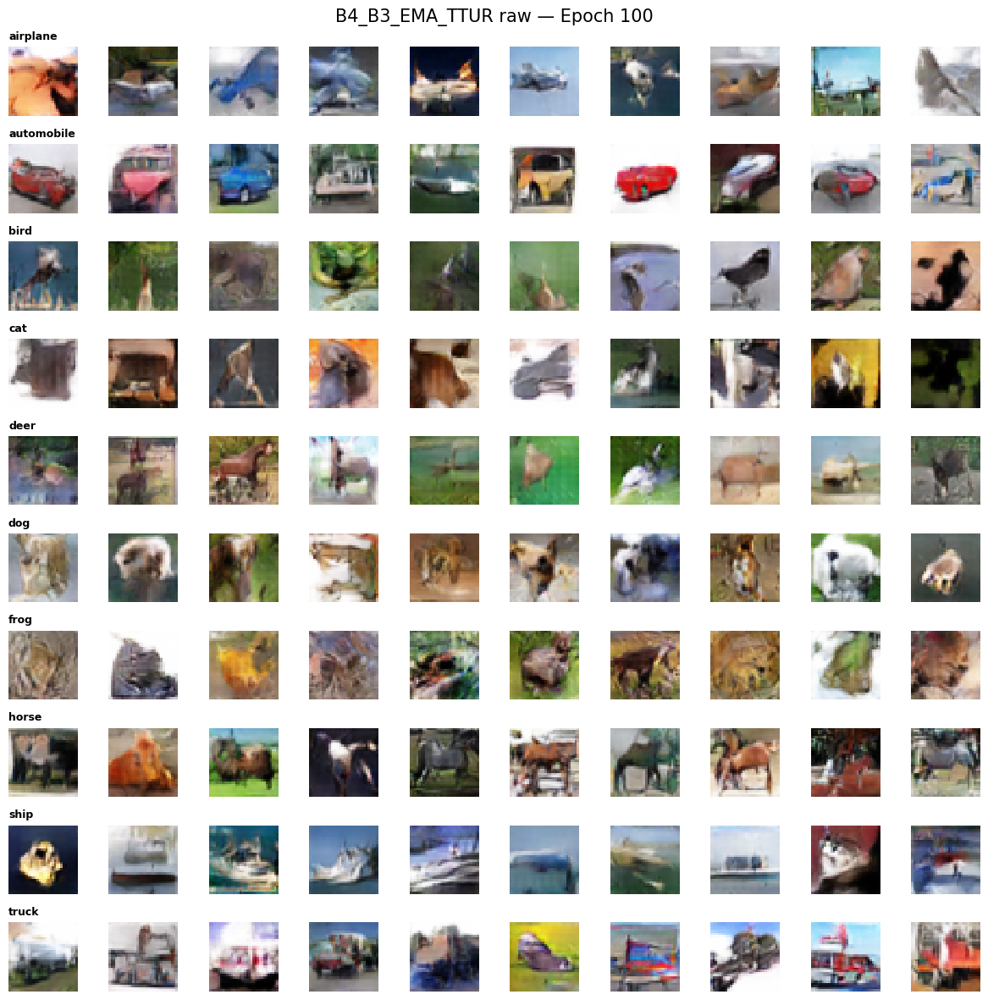

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_100.png


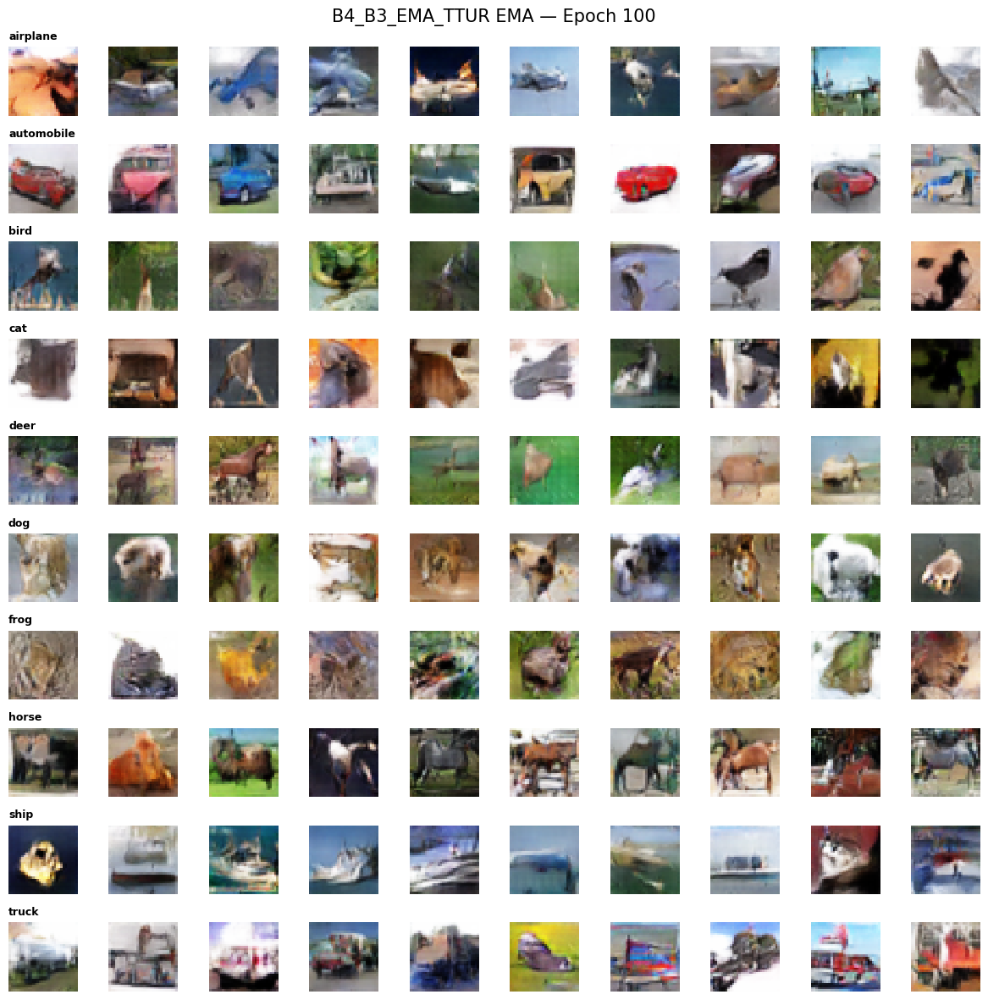

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_100.png
Epoch 101/150 | G 2.9096 | D 0.2364 | D(real) 0.8982 | D(fake) 0.1010 | D acc 0.9847 | 81.5s
Epoch 102/150 | G 2.9474 | D 0.2365 | D(real) 0.8988 | D(fake) 0.1007 | D acc 0.9838 | 84.0s
Epoch 103/150 | G 2.8872 | D 0.2566 | D(real) 0.8913 | D(fake) 0.1077 | D acc 0.9795 | 84.1s
Epoch 104/150 | G 2.9096 | D 0.2568 | D(real) 0.8928 | D(fake) 0.1078 | D acc 0.9778 | 81.4s
Epoch 105/150 | G 2.8395 | D 0.2912 | D(real) 0.8811 | D(fake) 0.1180 | D acc 0.9690 | 83.0s
Epoch 106/150 | G 2.9294 | D 0.2728 | D(real) 0.8879 | D(fake) 0.1116 | D acc 0.9721 | 83.6s
Epoch 107/150 | G 2.8490 | D 0.3476 | D(real) 0.8693 | D(fake) 0.1305 | D acc 0.9512 | 82.1s
Epoch 108/150 | G 3.0127 | D 0.2536 | D(real) 0.8950 | D(fake) 0.1050 | D acc 0.9759 | 82.5s
Epoch 109/150 | G 2.9177 | D 0.2895 | D(real) 0.8842 | D(fake) 0.1154 | D acc 0.9663 | 83.2s
Epoch 110/150 | G 2.9931 | D 0.2857 | D(real) 0.8869 | D(fake) 0.

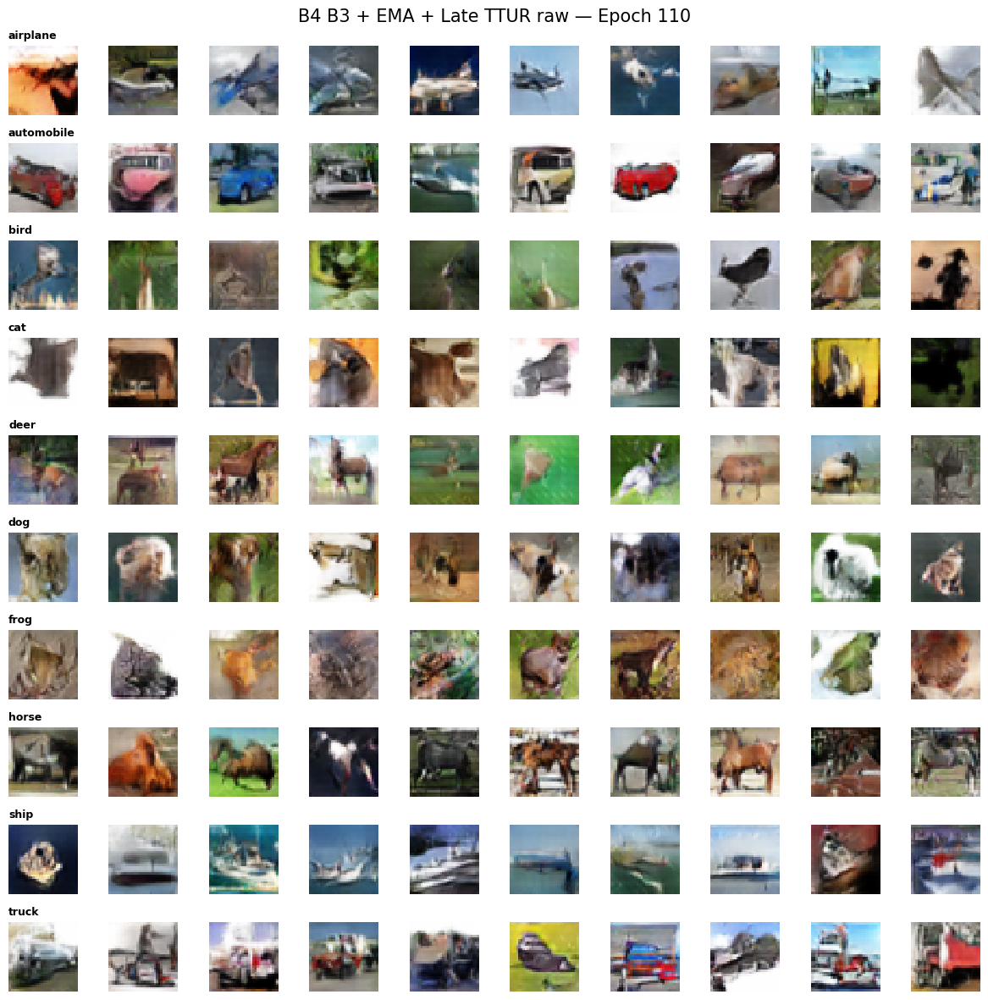

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_110.png


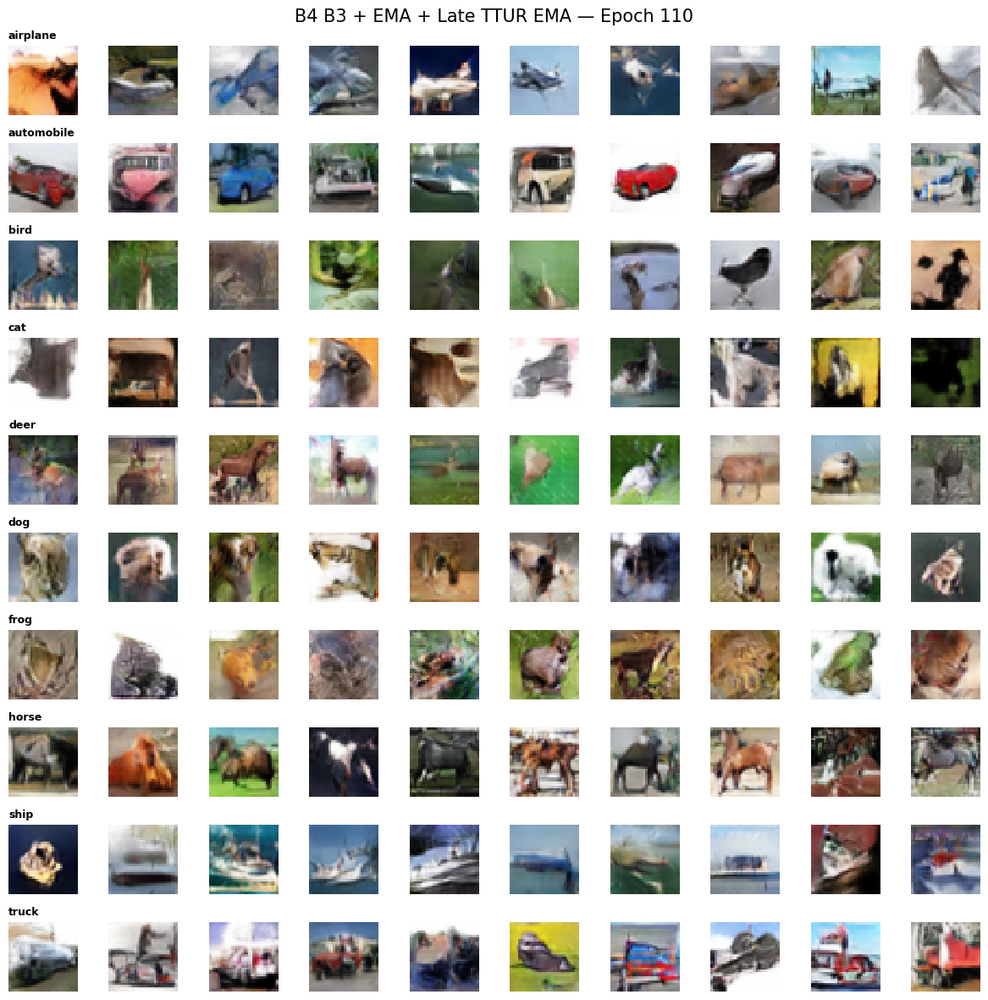

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_110.png
Epoch 111/150 | G 3.0097 | D 0.2687 | D(real) 0.8905 | D(fake) 0.1088 | D acc 0.9708 | 80.8s
Epoch 112/150 | G 2.9756 | D 0.2953 | D(real) 0.8840 | D(fake) 0.1161 | D acc 0.9630 | 80.5s
Epoch 113/150 | G 2.9380 | D 0.3290 | D(real) 0.8747 | D(fake) 0.1243 | D acc 0.9537 | 79.1s
Epoch 114/150 | G 2.9342 | D 0.2845 | D(real) 0.8858 | D(fake) 0.1143 | D acc 0.9677 | 80.4s
Epoch 115/150 | G 3.0724 | D 0.2485 | D(real) 0.8971 | D(fake) 0.1026 | D acc 0.9759 | 81.4s
Epoch 116/150 | G 2.9867 | D 0.3385 | D(real) 0.8768 | D(fake) 0.1234 | D acc 0.9519 | 80.1s
Epoch 117/150 | G 3.0601 | D 0.2413 | D(real) 0.8993 | D(fake) 0.1005 | D acc 0.9784 | 79.2s
Epoch 118/150 | G 3.1190 | D 0.2565 | D(real) 0.8978 | D(fake) 0.1020 | D acc 0.9716 | 79.8s
Epoch 119/150 | G 3.0157 | D 0.3198 | D(real) 0.8820 | D(fake) 0.1173 | D acc 0.9584 | 80.1s
Epoch 120/150 | G 2.9910 | D 0.2761 | D(real) 0.8881 | D(fake) 0.

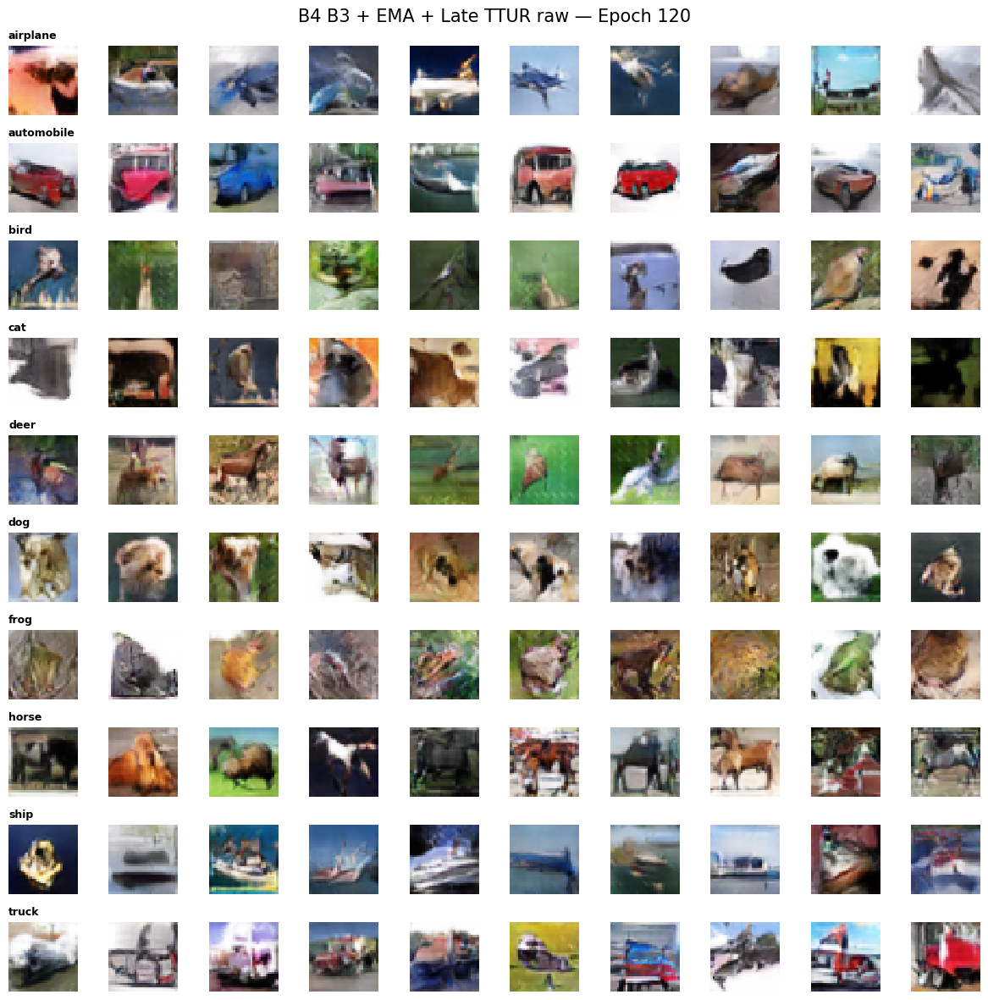

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_120.png


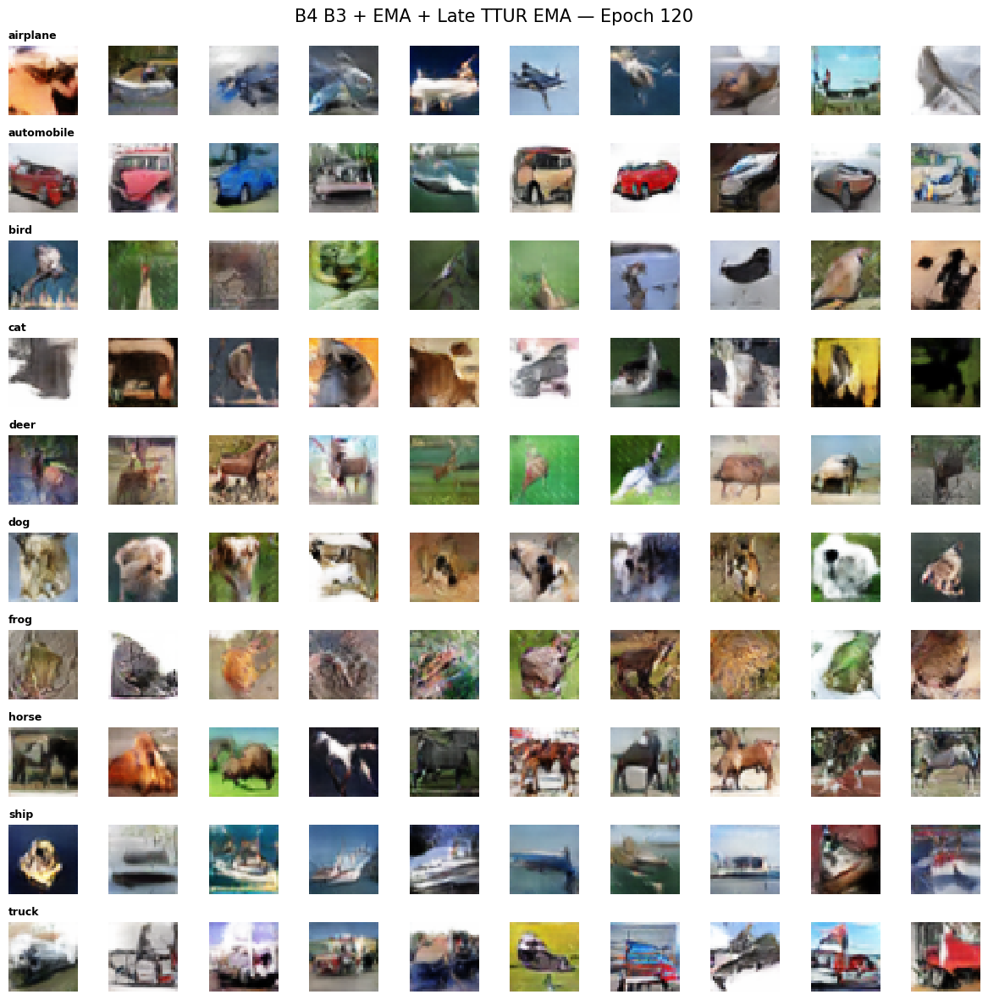

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_120.png
Epoch 121/150 | G 3.0282 | D 0.2790 | D(real) 0.8884 | D(fake) 0.1106 | D acc 0.9651 | 81.1s
Epoch 122/150 | G 2.8904 | D 0.3765 | D(real) 0.8635 | D(fake) 0.1358 | D acc 0.9423 | 80.2s
Epoch 123/150 | G 3.1376 | D 0.2324 | D(real) 0.9033 | D(fake) 0.0965 | D acc 0.9793 | 80.3s
Epoch 124/150 | G 2.9573 | D 0.3252 | D(real) 0.8789 | D(fake) 0.1212 | D acc 0.9582 | 81.6s
Epoch 125/150 | G 2.9937 | D 0.3361 | D(real) 0.8803 | D(fake) 0.1194 | D acc 0.9569 | 80.7s
Epoch 126/150 | G 2.9126 | D 0.2413 | D(real) 0.8963 | D(fake) 0.1023 | D acc 0.9843 | 80.6s
Epoch 127/150 | G 2.9229 | D 0.2363 | D(real) 0.8986 | D(fake) 0.1010 | D acc 0.9846 | 81.1s
Epoch 128/150 | G 2.8935 | D 0.2485 | D(real) 0.8947 | D(fake) 0.1054 | D acc 0.9817 | 81.0s
Epoch 129/150 | G 2.9250 | D 0.2509 | D(real) 0.8943 | D(fake) 0.1054 | D acc 0.9796 | 79.3s
Epoch 130/150 | G 2.9517 | D 0.2382 | D(real) 0.8984 | D(fake) 0.

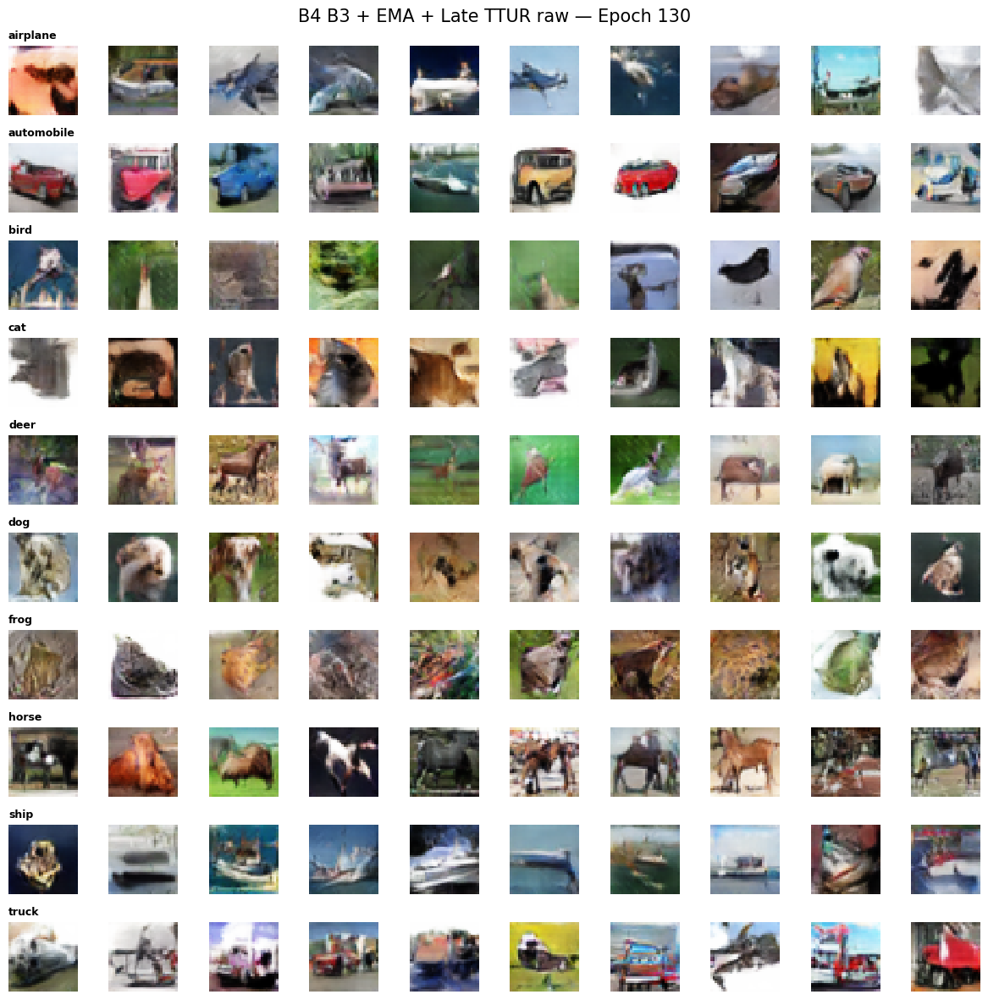

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_130.png


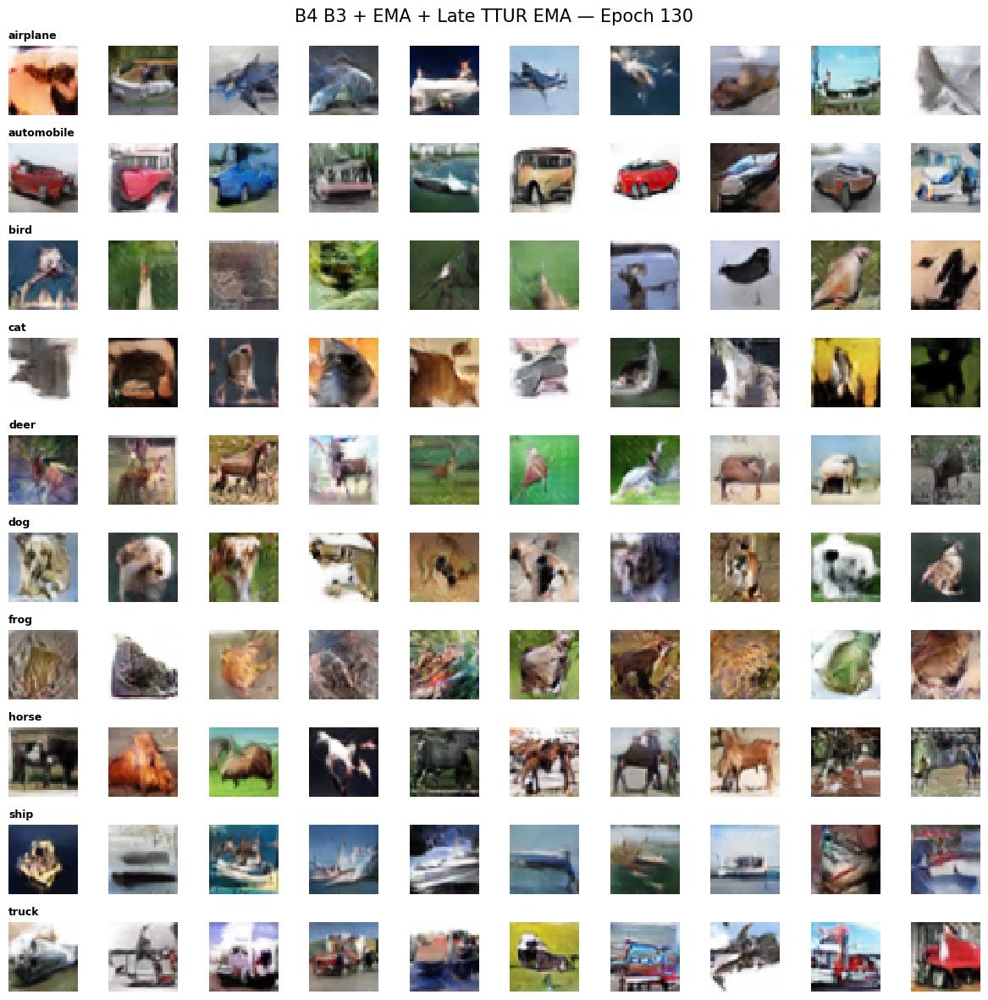

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_130.png
Epoch 131/150 | G 2.9622 | D 0.2459 | D(real) 0.8968 | D(fake) 0.1031 | D acc 0.9796 | 80.3s
Epoch 132/150 | G 2.9610 | D 0.2474 | D(real) 0.8956 | D(fake) 0.1033 | D acc 0.9798 | 80.7s
Epoch 133/150 | G 2.9534 | D 0.2518 | D(real) 0.8948 | D(fake) 0.1054 | D acc 0.9784 | 81.1s
Epoch 134/150 | G 2.9822 | D 0.2450 | D(real) 0.8971 | D(fake) 0.1024 | D acc 0.9788 | 79.9s
Epoch 135/150 | G 3.0150 | D 0.2393 | D(real) 0.8990 | D(fake) 0.1004 | D acc 0.9805 | 79.8s
Epoch 136/150 | G 3.0311 | D 0.2383 | D(real) 0.8996 | D(fake) 0.1001 | D acc 0.9808 | 80.6s
Epoch 137/150 | G 3.0150 | D 0.2436 | D(real) 0.8980 | D(fake) 0.1018 | D acc 0.9798 | 80.1s
Epoch 138/150 | G 3.0112 | D 0.2448 | D(real) 0.8983 | D(fake) 0.1015 | D acc 0.9784 | 80.3s
Epoch 139/150 | G 3.1133 | D 0.2205 | D(real) 0.9059 | D(fake) 0.0936 | D acc 0.9845 | 80.7s
Epoch 140/150 | G 3.0653 | D 0.2364 | D(real) 0.9003 | D(fake) 0.

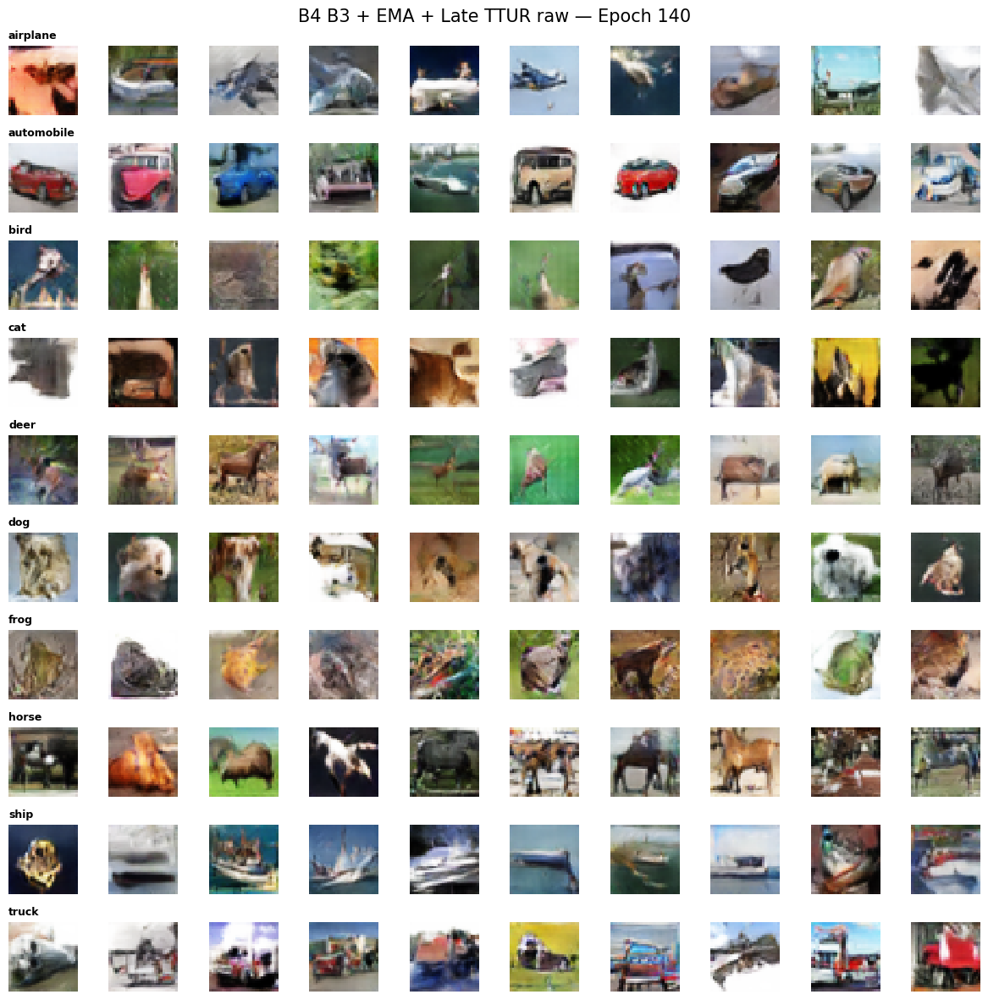

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_140.png


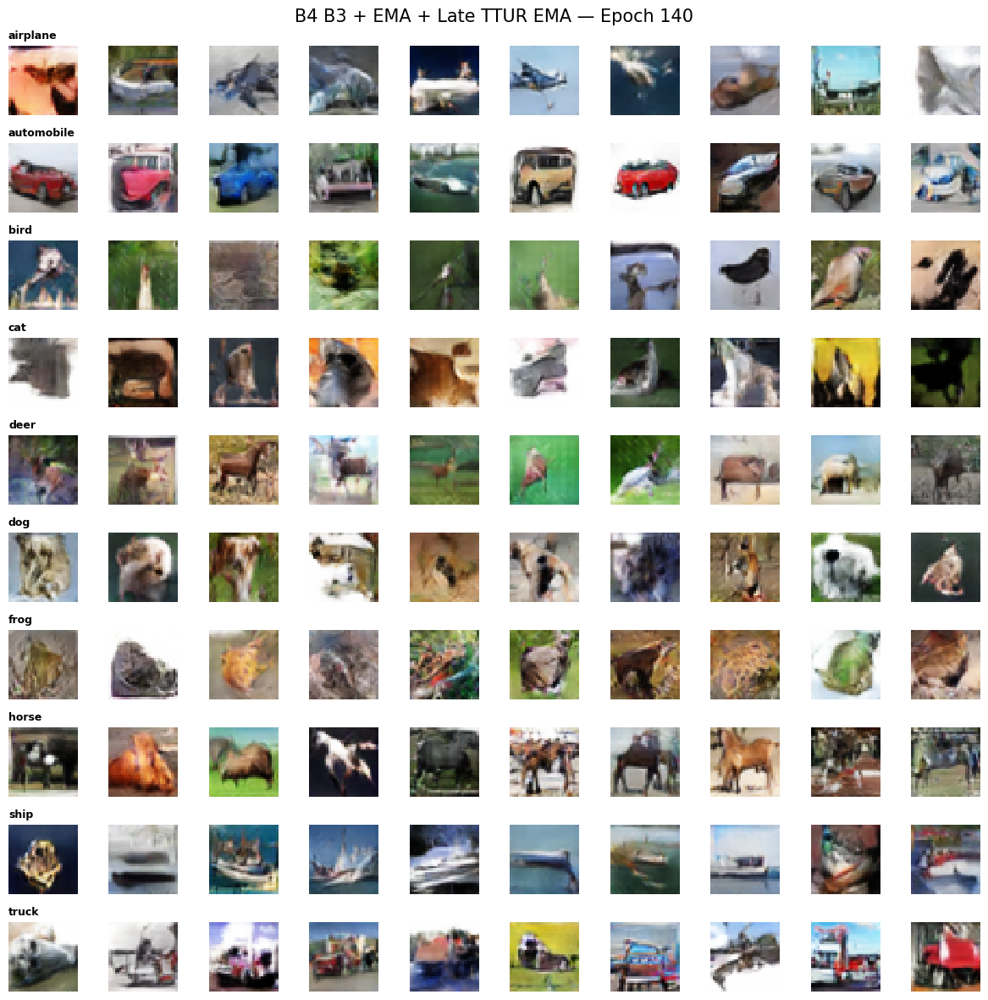

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_140.png
Epoch 141/150 | G 3.0600 | D 0.2380 | D(real) 0.9007 | D(fake) 0.0994 | D acc 0.9788 | 80.7s
Epoch 142/150 | G 3.0976 | D 0.2202 | D(real) 0.9063 | D(fake) 0.0930 | D acc 0.9839 | 80.4s
Epoch 143/150 | G 3.0652 | D 0.2381 | D(real) 0.9009 | D(fake) 0.0990 | D acc 0.9790 | 79.9s
Epoch 144/150 | G 3.1147 | D 0.2296 | D(real) 0.9036 | D(fake) 0.0960 | D acc 0.9807 | 79.8s
Epoch 145/150 | G 3.1184 | D 0.2309 | D(real) 0.9036 | D(fake) 0.0960 | D acc 0.9791 | 81.0s
Epoch 146/150 | G 3.1207 | D 0.2410 | D(real) 0.9012 | D(fake) 0.0980 | D acc 0.9757 | 80.2s
Epoch 147/150 | G 3.1359 | D 0.2257 | D(real) 0.9056 | D(fake) 0.0941 | D acc 0.9812 | 80.5s
Epoch 148/150 | G 3.1621 | D 0.2211 | D(real) 0.9072 | D(fake) 0.0930 | D acc 0.9817 | 80.8s
Epoch 149/150 | G 3.1613 | D 0.2175 | D(real) 0.9075 | D(fake) 0.0921 | D acc 0.9841 | 80.3s
Epoch 150/150 | G 3.1368 | D 0.2203 | D(real) 0.9064 | D(fake) 0.

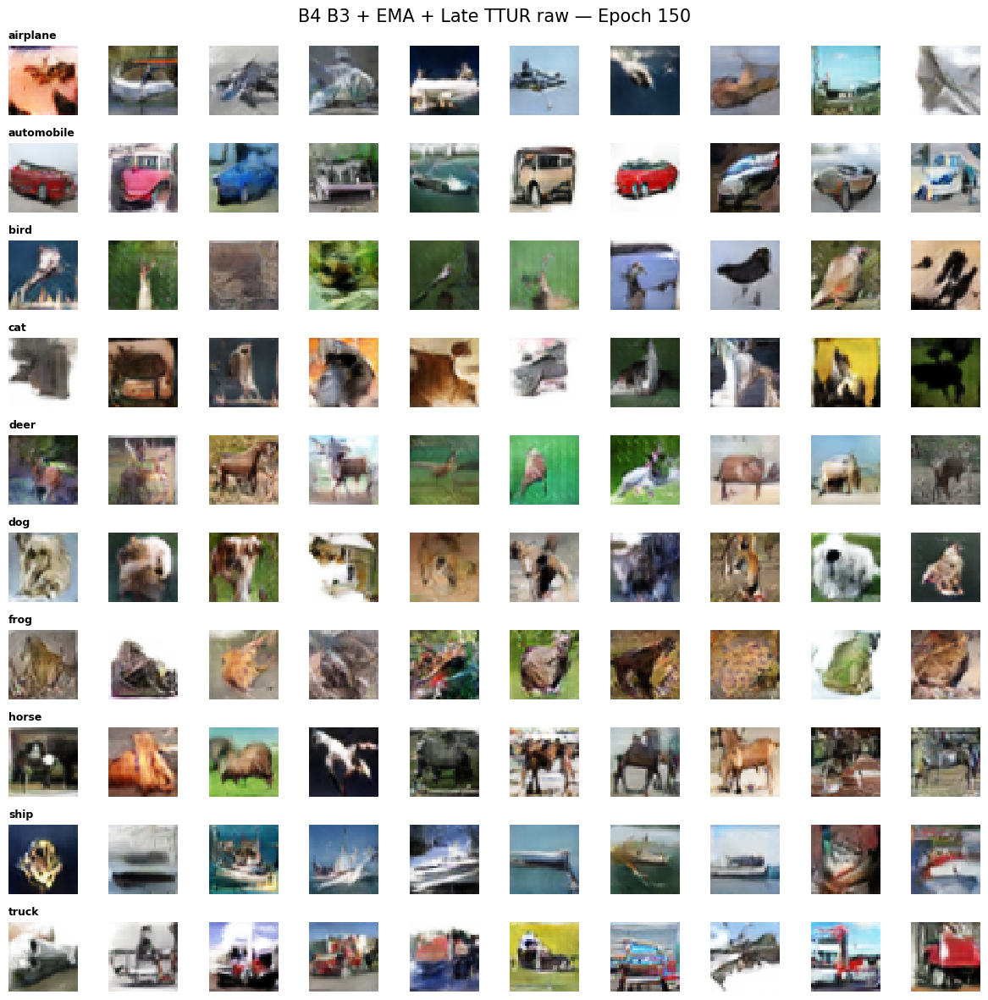

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_raw\generated_grid_epoch_150.png


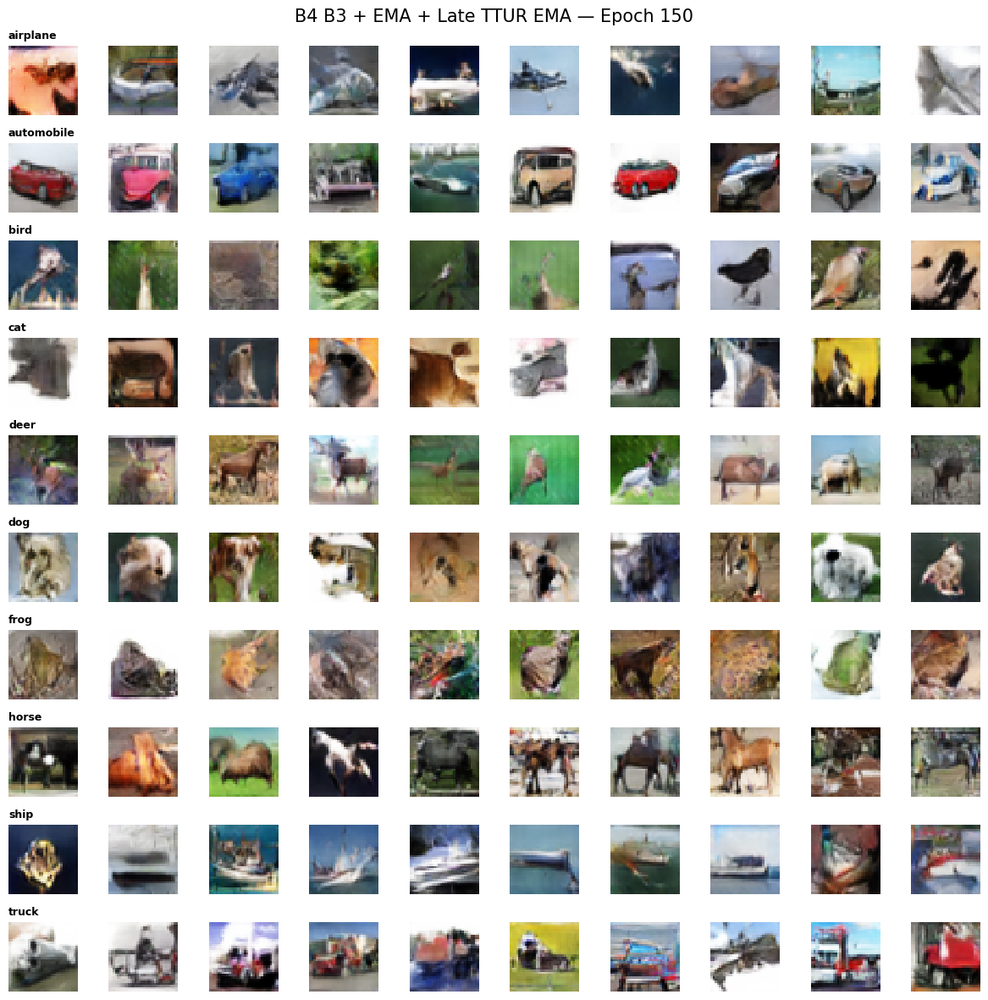

Saved grid: HeinHtetPartA_outputs\B4_B3_EMA_TTUR\generated_grids_ema\generated_grid_epoch_150.png
Completed B4 B3 + EMA + Late TTUR: 50 epochs recorded.


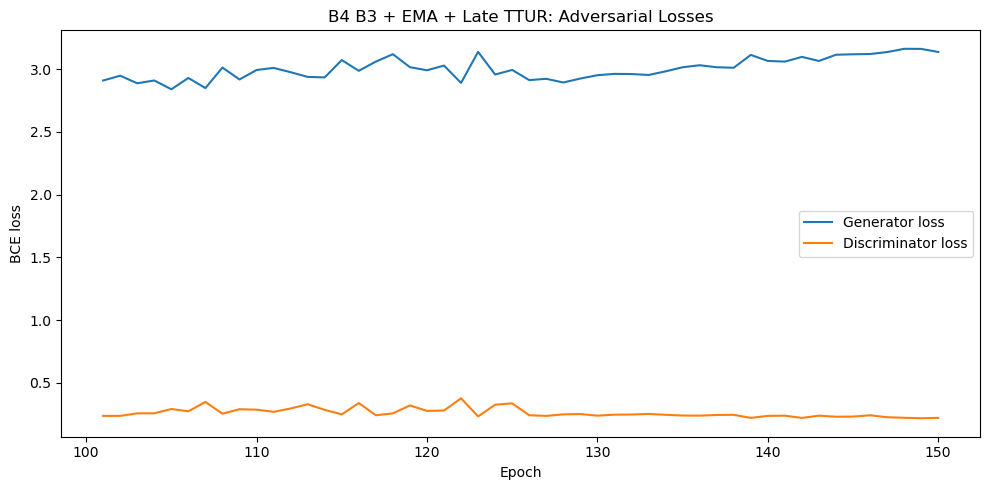

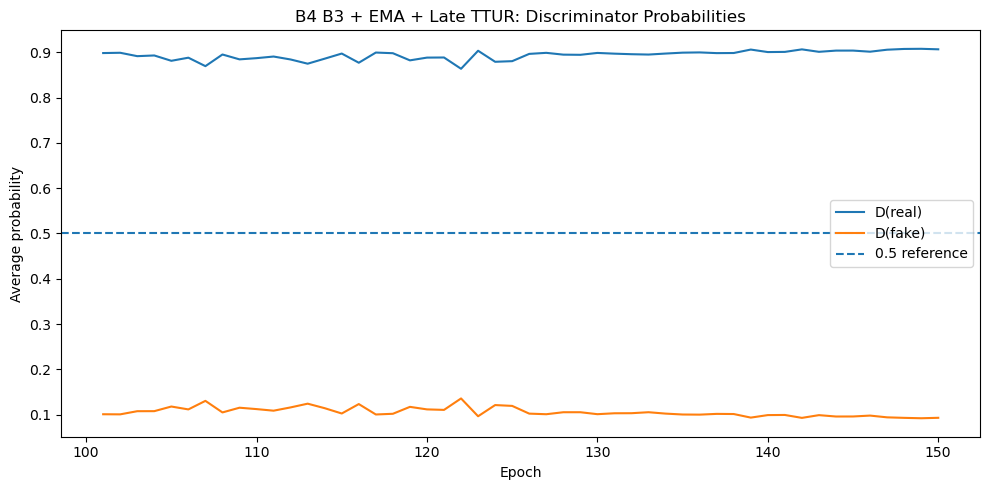

In [48]:
B4_RESULT = execute_b3_continuation(
    run_name="B4_B3_EMA_TTUR",
    run_label="B4 B3 + EMA + Late TTUR",
    augmentation_function=translation_policy,
)


### B4 Training Assessment

B4 continued training from the selected B3 epoch-100 checkpoint for an
additional 50 epochs. It retained the two-pixel translation augmentation and
introduced exponential moving average (EMA) generator weights together with a
late TTUR adjustment. The purpose was to determine whether the already strong
B3 model could be refined further without restarting training.

Because B4 is a continuation experiment, the plots cover epochs 101 to 150
rather than a new training run beginning from random initialization. Its loss
values should therefore be interpreted as the later-stage behaviour of B3.

Training remained numerically stable throughout the continuation. The
generator loss stayed mostly between approximately 2.9 and 3.2, with a small
upward trend toward the end. The discriminator loss remained low, generally
between approximately 0.2 and 0.35, and became relatively steady after the
first half of the continuation.

The discriminator-probability plot shows a clear imbalance. `D(real)` remained
high at approximately 0.88 to 0.91, while `D(fake)` stayed near approximately
0.09 to 0.13. This indicates that the discriminator was consistently confident
when separating real and generated images. The slightly increasing generator
loss also suggests that the generator became progressively harder to improve
during this late training stage.

Despite the imbalance, there was no evidence of numerical divergence or
complete mode collapse. The losses remained finite, the probability curves
were stable, and there were no sudden sustained changes. The continuation
therefore refined the model under a strong discriminator rather than causing
the adversarial process to fail.

EMA did not directly affect the displayed training losses because it maintains
a smoothed copy of the generator weights for evaluation. Its usefulness was
therefore assessed by comparing the raw and EMA checkpoints using the same FID,
KID and fixed-input visual protocol.

The training curves were not used to select the final B4 checkpoint. FID was
used as the primary metric, KID was used as supporting evidence, and visual
inspection was used only to verify that the selected metric result was not
associated with severe repetition, major artefacts or loss of class-dependent
structure.

#### B4 FID/KID Evaluation — Run After B4 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B4: epoch 100, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 100 | raw | FID 34.1947 | KID 0.014281 ± 0.003679
Evaluating B4: epoch 100, ema...
Epoch 100 | ema | FID 34.1947 | KID 0.014281 ± 0.003679
Evaluating B4: epoch 110, raw...
Epoch 110 | raw | FID 32.1056 | KID 0.012841 ± 0.003530
Evaluating B4: epoch 110, ema...
Epoch 110 | ema | FID 32.7285 | KID 0.013288 ± 0.003704
Evaluating B4: epoch 120, raw...
Epoch 120 | raw | FID 33.5490 | KID 0.013712 ± 0.003262
Evaluating B4: epoch 120, ema...
Epoch 120 | ema | FID 32.0302 | KID 0.012765 ± 0.003761
Evaluating B4: epoch 130, raw...
Epoch 130 | raw | FID 32.7569 | KID 0.013871 ± 0.003702
Evaluating B4: epoch 130, ema...
Epoch 130 | ema | FID 32.0502 | KID 0.013361 ± 0.004045
Evaluating B4: epoch 140, raw...
Epoch 140 | raw | FID 32.0000 | KID 0.01305

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B4,B4_B3_EMA_TTUR,100,ema,34.1947,0.014281,0.003679,5000
1,B4,B4_B3_EMA_TTUR,110,ema,32.7285,0.013288,0.003704,5000
2,B4,B4_B3_EMA_TTUR,120,ema,32.0302,0.012765,0.003761,5000
3,B4,B4_B3_EMA_TTUR,130,ema,32.0502,0.013361,0.004045,5000
4,B4,B4_B3_EMA_TTUR,140,ema,31.1171,0.012706,0.003891,5000
5,B4,B4_B3_EMA_TTUR,150,ema,31.1634,0.012623,0.003703,5000
6,B4,B4_B3_EMA_TTUR,100,raw,34.1947,0.014281,0.003679,5000
7,B4,B4_B3_EMA_TTUR,110,raw,32.1056,0.012841,0.003530,5000
8,B4,B4_B3_EMA_TTUR,120,raw,33.5490,0.013712,0.003262,5000
9,B4,B4_B3_EMA_TTUR,130,raw,32.7569,0.013871,0.003702,5000


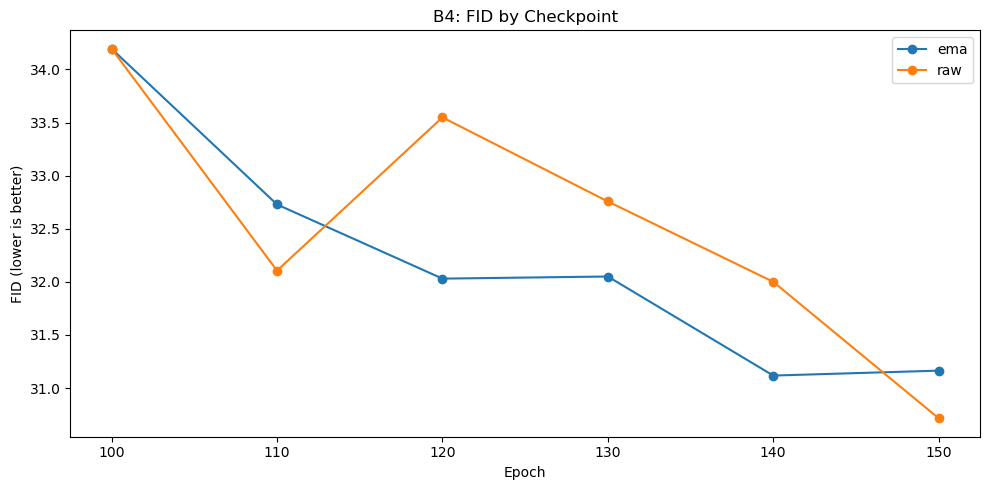

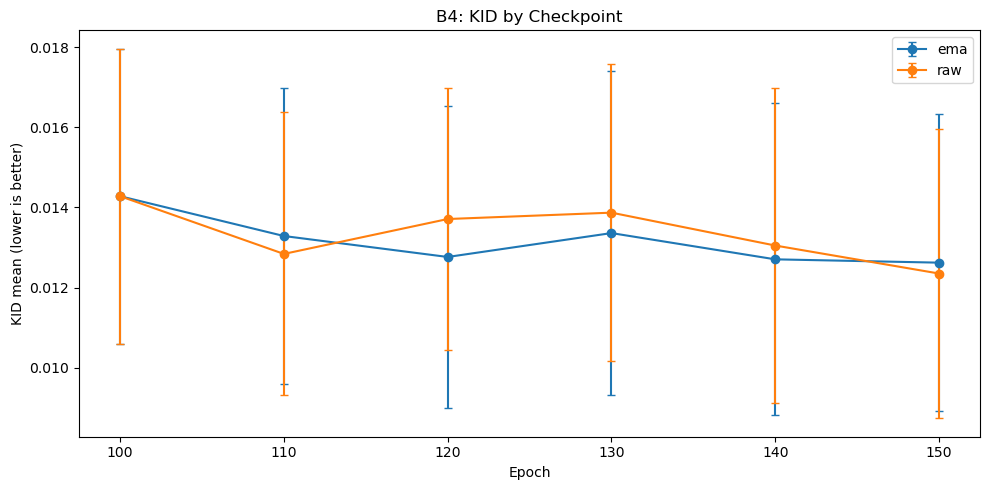

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B4_B3_EMA_TTUR\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [49]:
B4_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B4",
    run_name="B4_B3_EMA_TTUR",
    candidates=("raw", "ema"),
    expected_epochs=[100, 110, 120, 130, 140, 150],
)


### B4 Manual Review

- **Chosen B4 checkpoint:** Raw generator at epoch 150
- **FID:** 30.7151
- **KID mean ± standard deviation:** 0.012351 ± 0.003612
- **Decision:** Retained as the strongest B4 checkpoint and the best candidate
  evaluated so far.

### Checkpoint Selection

The raw generator at epoch 150 was selected manually because it achieved the
lowest FID among all evaluated B4 raw and EMA checkpoints. FID was treated as
the primary checkpoint-selection metric.

The raw FID result improved from 34.1947 at epoch 100 to 30.7151 at epoch 150.
The progression was not perfectly continuous: the raw FID improved at epoch
110, worsened at epochs 120 and 130, and then improved again at epochs 140 and
150. This variation is expected in adversarial training, and the final
checkpoint produced the strongest overall FID result.

KID was used as supporting evidence. The selected raw epoch-150 checkpoint
also achieved the lowest B4 KID mean of 0.012351. The KID uncertainty ranges
overlap across several B4 checkpoints, so the small differences should not be
treated as conclusive on their own. However, the KID result supports rather
than contradicts the FID-based selection.

### Raw and EMA Comparison


EMA produced stable and competitive results, particularly at epochs 140 and
150. However, it did not outperform the raw epoch-150 generator on either FID
or KID mean. The smoothed EMA weights were therefore retained as useful
supporting evidence but were not selected as the strongest B4 candidate.

### Comparison with B3

Compared with B3, B4 reduced FID by approximately 3.4796 points and also
achieved a lower KID mean. This shows that continuing the B3 model with the
late-training modifications produced a meaningful quantitative improvement.

The result also demonstrates that the best evaluated weights were not
necessarily the EMA weights. In this run, the raw generator continued to adapt
successfully and produced the strongest feature-distribution match at epoch
150.

### Visual Verification

The fixed-input class-balanced grids for the raw and EMA candidates were
inspected only as a verification step. The inspection checked for severe mode
collapse, excessive duplication, major visual artefacts and complete loss of
conditional class recognisability.

The selected raw epoch-150 output did not show an obvious failure that
contradicted its FID and KID results. Visual inspection therefore supported the
quantitative selection but was not used as the main reason for choosing the
checkpoint.

### Continuation Conclusion

The B4 continuation was successful. Extending B3 with EMA tracking and late
TTUR produced lower FID and KID values than the original B3 checkpoint while
remaining numerically stable. The raw epoch-150 generator became the strongest
candidate at this stage.

- **Visual label counts:** Not completed for the full B4 experiment review
  because the `clear / marginal / nonsense` assessment was reserved for the
  strongest final shortlisted candidates.
- **Requested-class match observations:** General class consistency was checked
  using the fixed-input grids, while detailed requested-class matching was
  reserved for the final visual-labelling stage.


### 8.6 B5 — B3 Continuation with EMA, TTUR and Mild Colour DiffAugment

B5 starts independently from the same B3 epoch-100 checkpoint. It keeps EMA and
late TTUR, then adds mild brightness and contrast after the two-pixel
translation. The same differentiable transformation is applied to real and
generated images, following the central DiffAugment principle (Zhao et al.,
2020).


Restored B3: HeinHtetPartA_outputs\B3_translation_2px\checkpoints\ckpt-100
Saved continuation baseline: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\checkpoints\ckpt-100


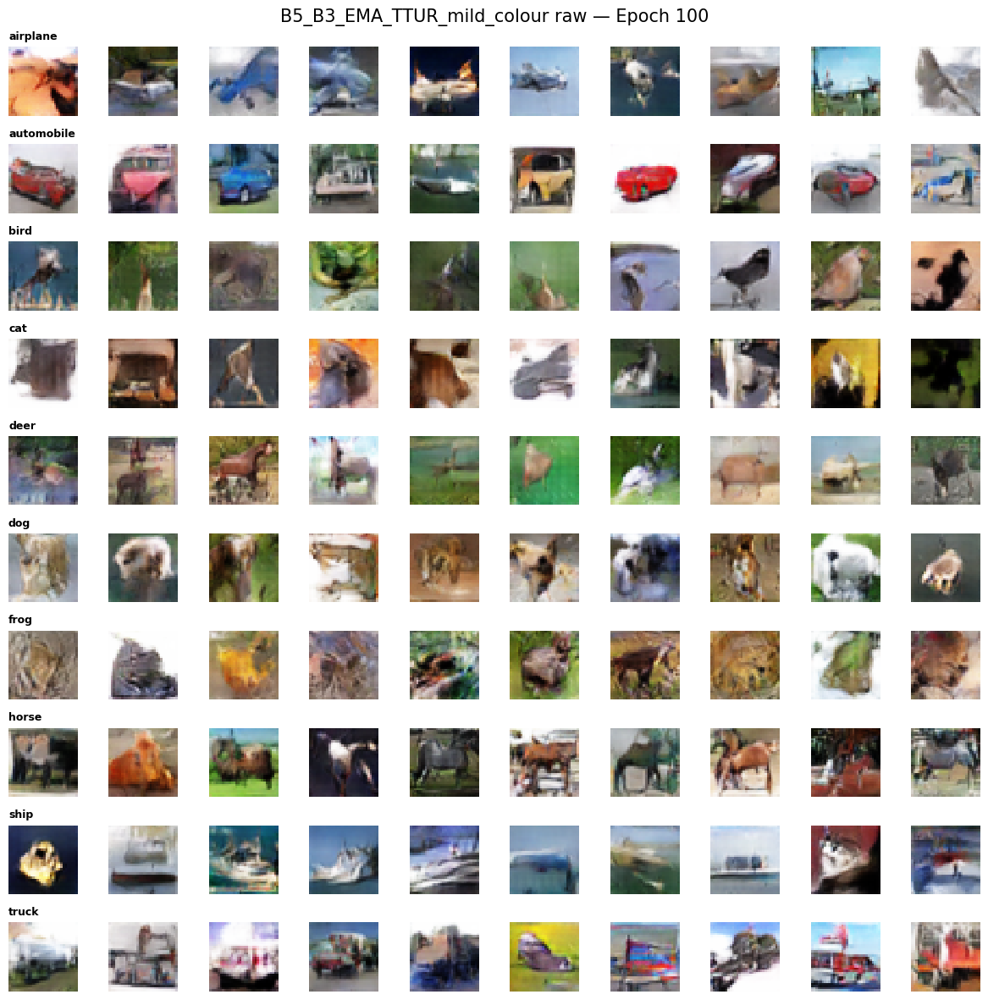

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_100.png


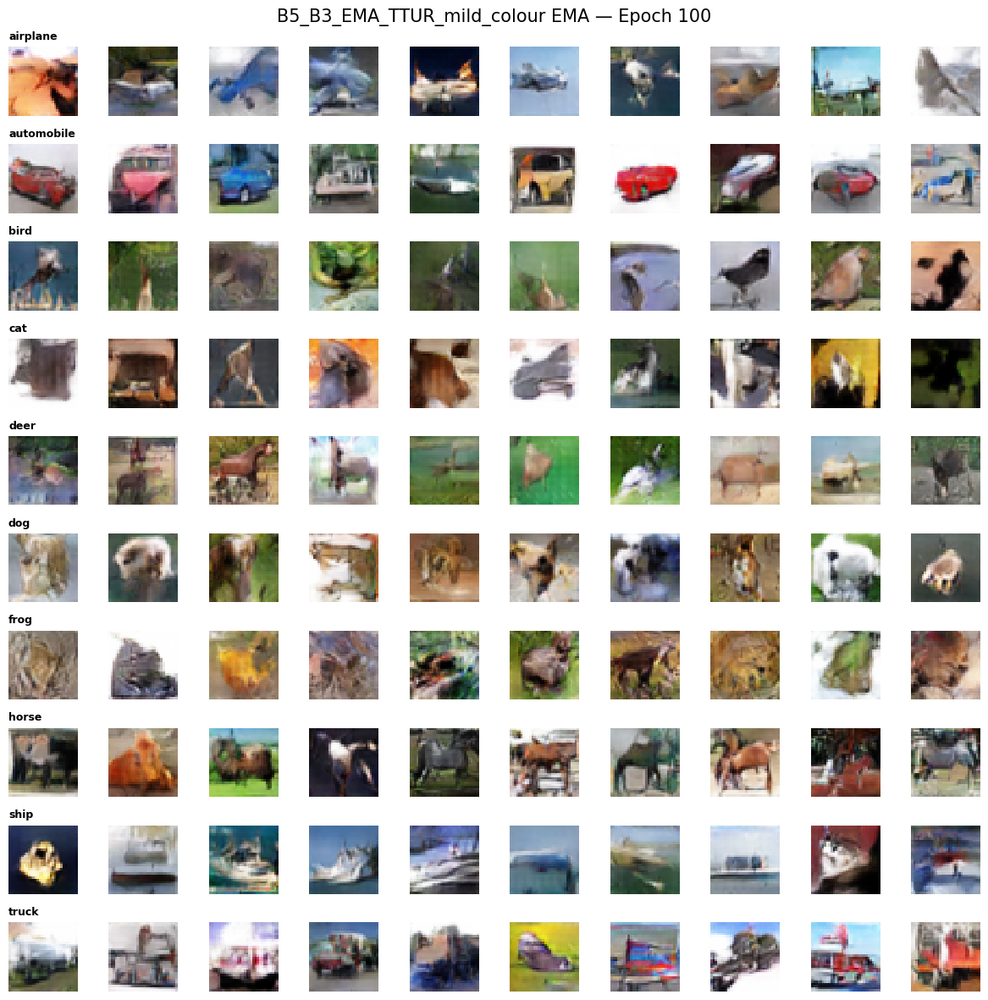

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_100.png
Epoch 101/150 | G 2.8245 | D 0.2581 | D(real) 0.8900 | D(fake) 0.1090 | D acc 0.9815 | 84.5s
Epoch 102/150 | G 2.8214 | D 0.2641 | D(real) 0.8883 | D(fake) 0.1109 | D acc 0.9784 | 80.0s
Epoch 103/150 | G 2.8376 | D 0.2638 | D(real) 0.8890 | D(fake) 0.1106 | D acc 0.9787 | 79.1s
Epoch 104/150 | G 2.8859 | D 0.2672 | D(real) 0.8894 | D(fake) 0.1112 | D acc 0.9756 | 79.9s
Epoch 105/150 | G 2.8239 | D 0.2992 | D(real) 0.8782 | D(fake) 0.1208 | D acc 0.9673 | 83.1s
Epoch 106/150 | G 2.8564 | D 0.2928 | D(real) 0.8809 | D(fake) 0.1183 | D acc 0.9679 | 78.9s
Epoch 107/150 | G 2.8699 | D 0.2996 | D(real) 0.8789 | D(fake) 0.1204 | D acc 0.9649 | 79.9s
Epoch 108/150 | G 2.9231 | D 0.3042 | D(real) 0.8841 | D(fake) 0.1165 | D acc 0.9659 | 80.6s
Epoch 109/150 | G 2.8289 | D 0.3522 | D(real) 0.8688 | D(fake) 0.1307 | D acc 0.9523 | 80.9s
Epoch 110/150 | G 2.9401 | D 0.2733 | D(real) 0.8888 

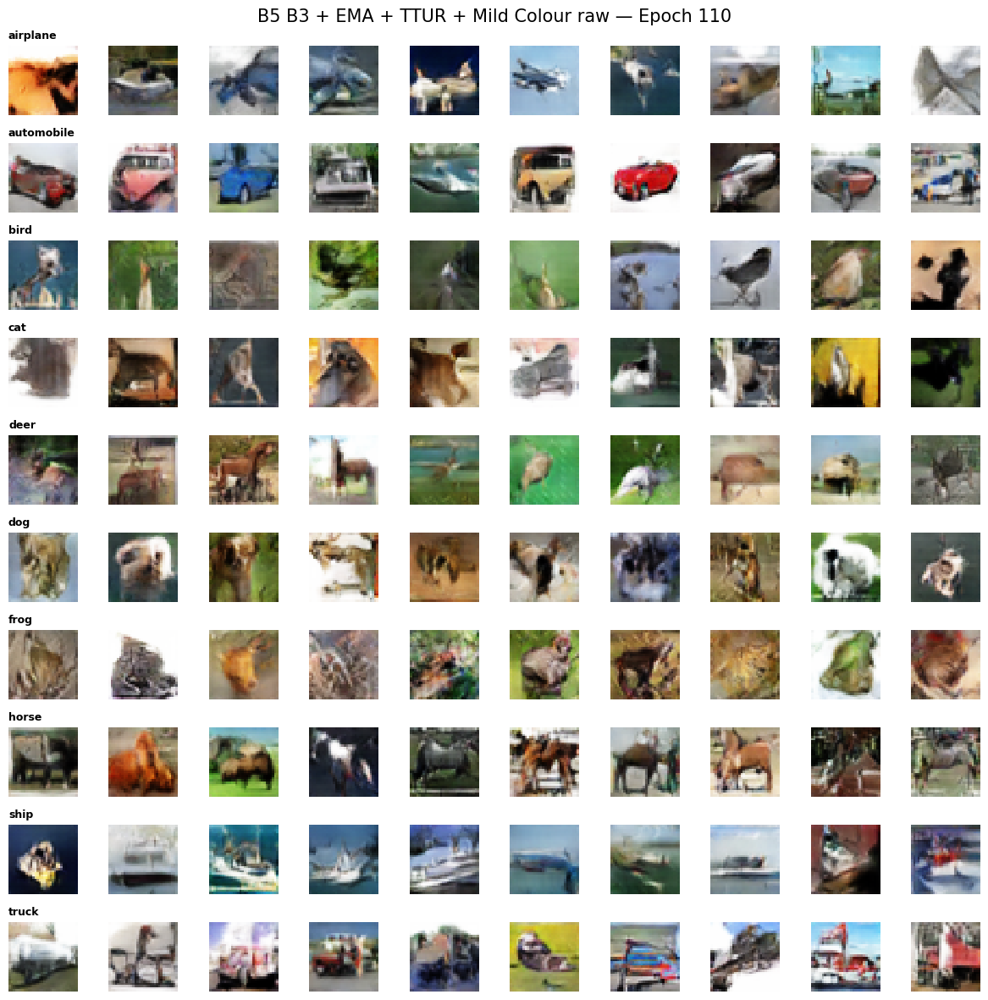

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_110.png


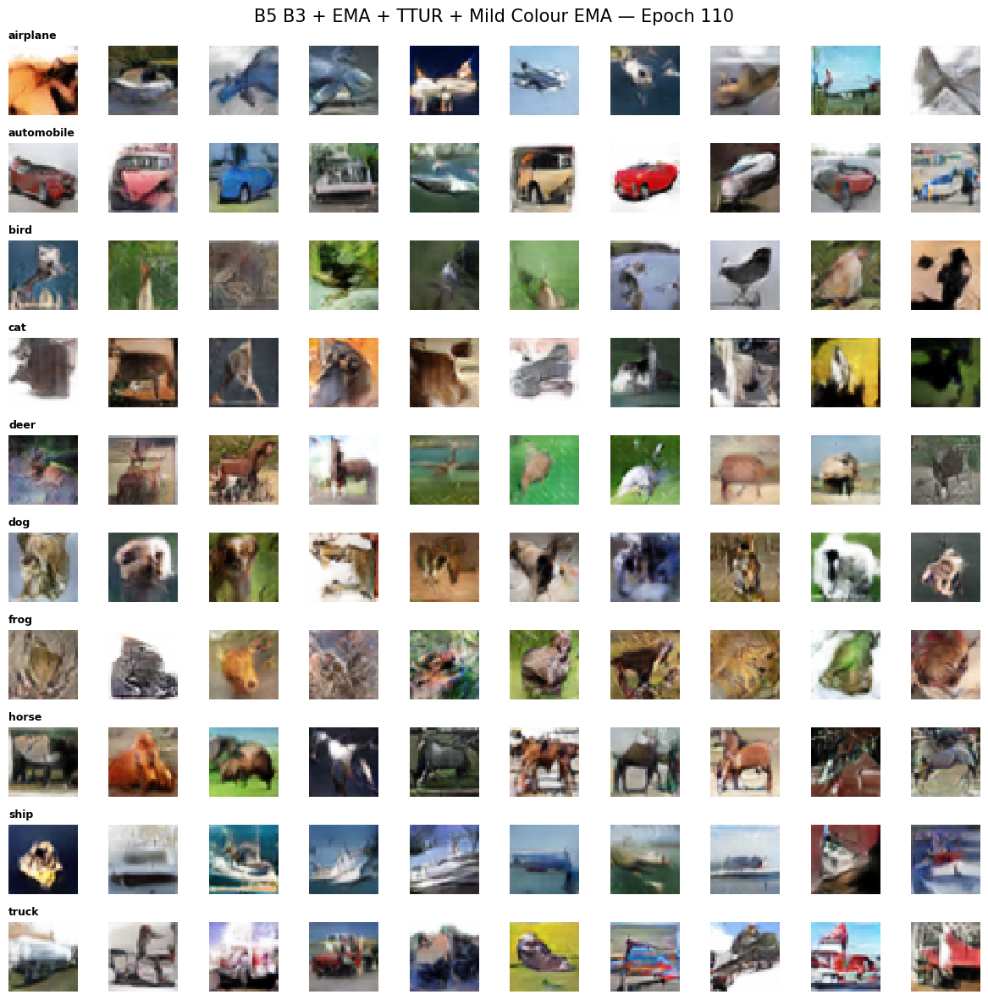

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_110.png
Epoch 111/150 | G 2.8895 | D 0.3009 | D(real) 0.8783 | D(fake) 0.1202 | D acc 0.9638 | 80.5s
Epoch 112/150 | G 2.9315 | D 0.3232 | D(real) 0.8771 | D(fake) 0.1234 | D acc 0.9560 | 80.6s
Epoch 113/150 | G 2.9526 | D 0.2946 | D(real) 0.8824 | D(fake) 0.1167 | D acc 0.9652 | 81.9s
Epoch 114/150 | G 2.9249 | D 0.2763 | D(real) 0.8868 | D(fake) 0.1131 | D acc 0.9709 | 79.7s
Epoch 115/150 | G 2.9408 | D 0.3034 | D(real) 0.8796 | D(fake) 0.1201 | D acc 0.9611 | 80.4s
Epoch 116/150 | G 2.9872 | D 0.2762 | D(real) 0.8893 | D(fake) 0.1108 | D acc 0.9689 | 81.8s
Epoch 117/150 | G 2.9030 | D 0.3276 | D(real) 0.8741 | D(fake) 0.1248 | D acc 0.9548 | 81.1s
Epoch 118/150 | G 2.9210 | D 0.2856 | D(real) 0.8844 | D(fake) 0.1155 | D acc 0.9673 | 80.5s
Epoch 119/150 | G 3.0017 | D 0.3058 | D(real) 0.8808 | D(fake) 0.1193 | D acc 0.9607 | 80.1s
Epoch 120/150 | G 2.9127 | D 0.3231 | D(real) 0.8746 

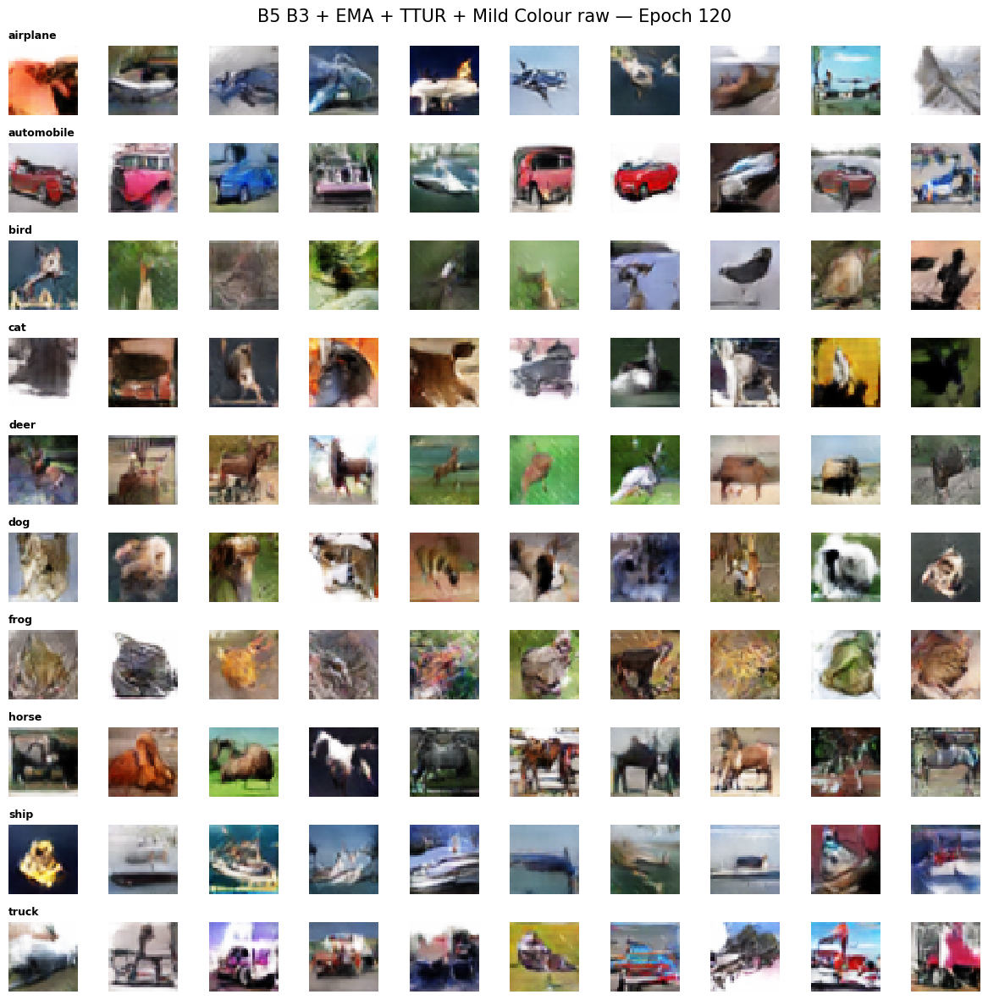

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_120.png


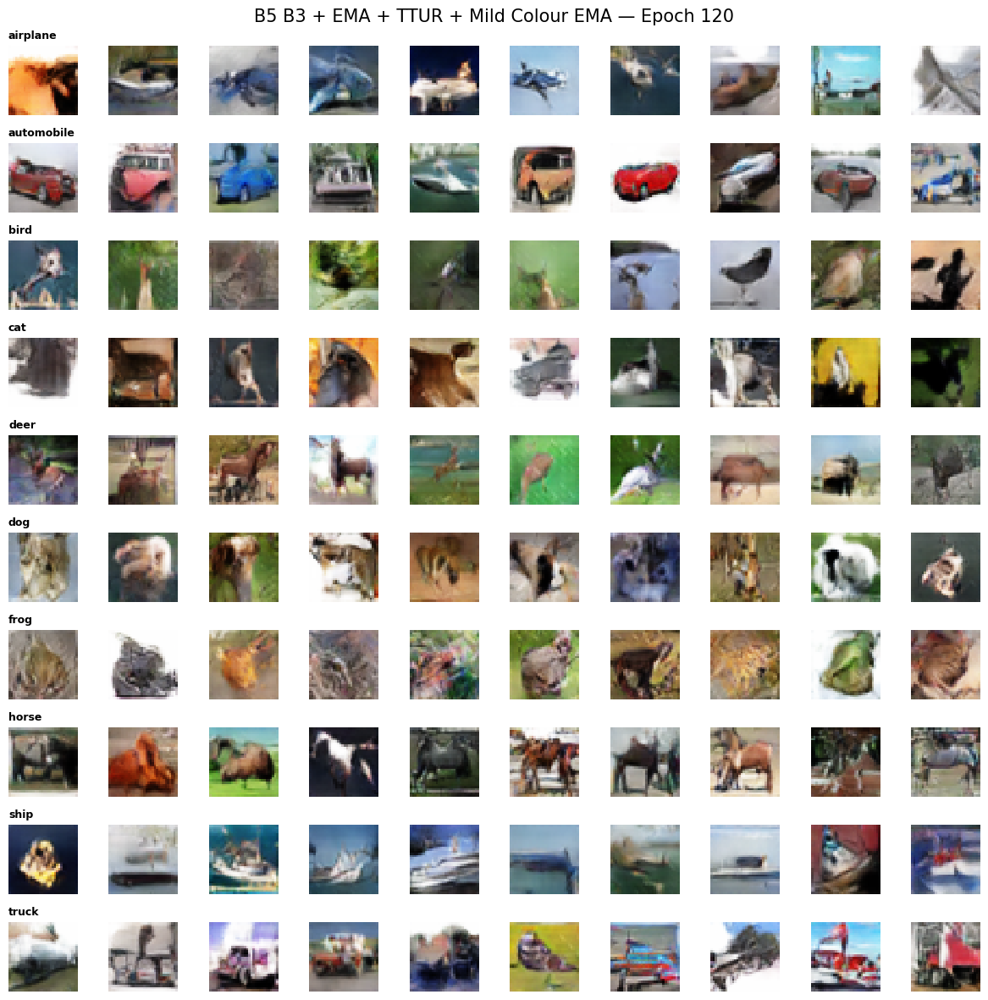

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_120.png
Epoch 121/150 | G 2.9479 | D 0.3154 | D(real) 0.8782 | D(fake) 0.1210 | D acc 0.9579 | 80.9s
Epoch 122/150 | G 2.9650 | D 0.3218 | D(real) 0.8762 | D(fake) 0.1234 | D acc 0.9535 | 81.3s
Epoch 123/150 | G 2.9857 | D 0.2848 | D(real) 0.8855 | D(fake) 0.1142 | D acc 0.9665 | 79.9s
Epoch 124/150 | G 3.0209 | D 0.2777 | D(real) 0.8887 | D(fake) 0.1109 | D acc 0.9664 | 80.8s
Epoch 125/150 | G 2.9509 | D 0.3196 | D(real) 0.8763 | D(fake) 0.1233 | D acc 0.9550 | 81.2s
Epoch 126/150 | G 2.8782 | D 0.2472 | D(real) 0.8942 | D(fake) 0.1051 | D acc 0.9832 | 80.1s
Epoch 127/150 | G 2.8807 | D 0.2493 | D(real) 0.8941 | D(fake) 0.1058 | D acc 0.9824 | 80.5s
Epoch 128/150 | G 2.8957 | D 0.2478 | D(real) 0.8946 | D(fake) 0.1051 | D acc 0.9823 | 80.6s
Epoch 129/150 | G 2.8648 | D 0.2677 | D(real) 0.8885 | D(fake) 0.1116 | D acc 0.9767 | 79.4s
Epoch 130/150 | G 2.9203 | D 0.2472 | D(real) 0.8951 

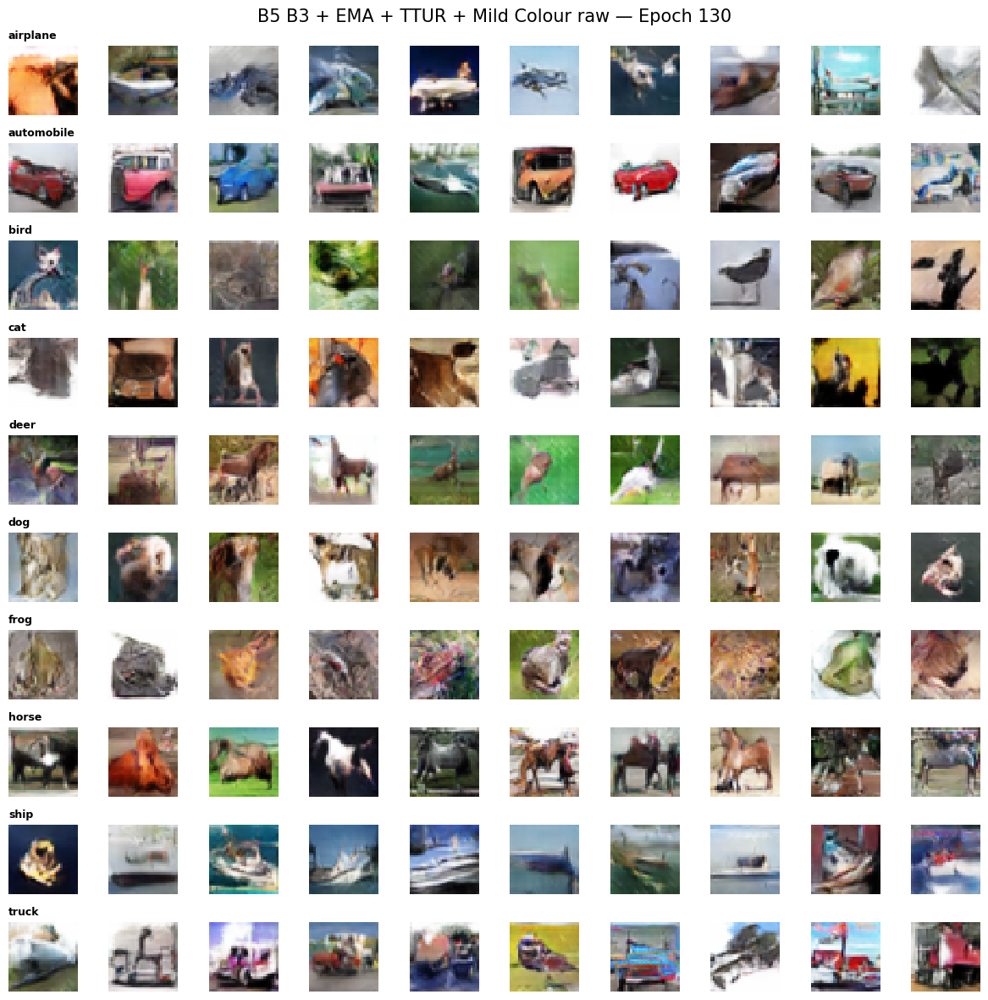

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_130.png


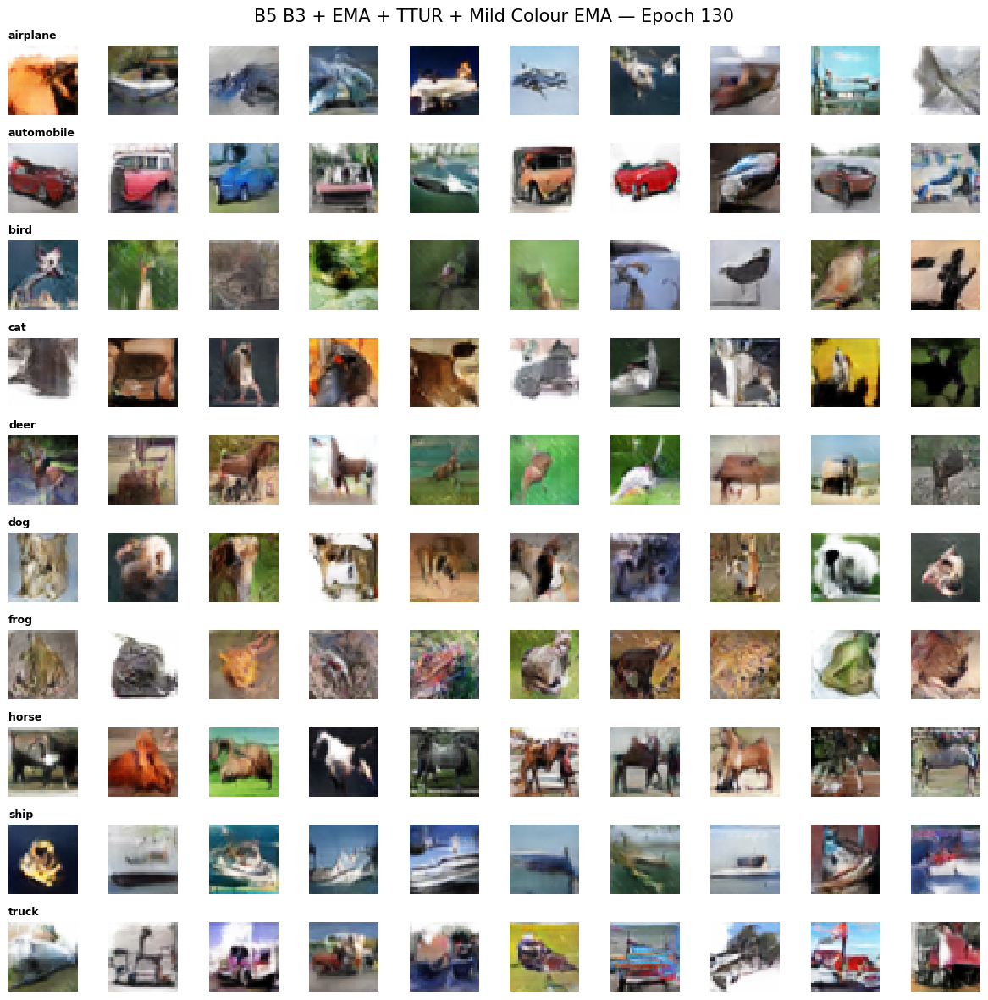

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_130.png
Epoch 131/150 | G 2.9167 | D 0.2628 | D(real) 0.8904 | D(fake) 0.1092 | D acc 0.9773 | 81.3s
Epoch 132/150 | G 2.9729 | D 0.2483 | D(real) 0.8954 | D(fake) 0.1038 | D acc 0.9797 | 79.6s
Epoch 133/150 | G 2.9213 | D 0.2476 | D(real) 0.8955 | D(fake) 0.1049 | D acc 0.9813 | 80.0s
Epoch 134/150 | G 2.9242 | D 0.2554 | D(real) 0.8927 | D(fake) 0.1064 | D acc 0.9786 | 80.8s
Epoch 135/150 | G 2.9419 | D 0.2548 | D(real) 0.8931 | D(fake) 0.1063 | D acc 0.9780 | 81.4s
Epoch 136/150 | G 2.9861 | D 0.2502 | D(real) 0.8959 | D(fake) 0.1041 | D acc 0.9777 | 81.0s
Epoch 137/150 | G 2.9779 | D 0.2557 | D(real) 0.8940 | D(fake) 0.1056 | D acc 0.9760 | 80.5s
Epoch 138/150 | G 2.9877 | D 0.2430 | D(real) 0.8977 | D(fake) 0.1018 | D acc 0.9806 | 79.7s
Epoch 139/150 | G 3.0090 | D 0.2380 | D(real) 0.8993 | D(fake) 0.1001 | D acc 0.9816 | 80.4s
Epoch 140/150 | G 3.0300 | D 0.2358 | D(real) 0.9003 

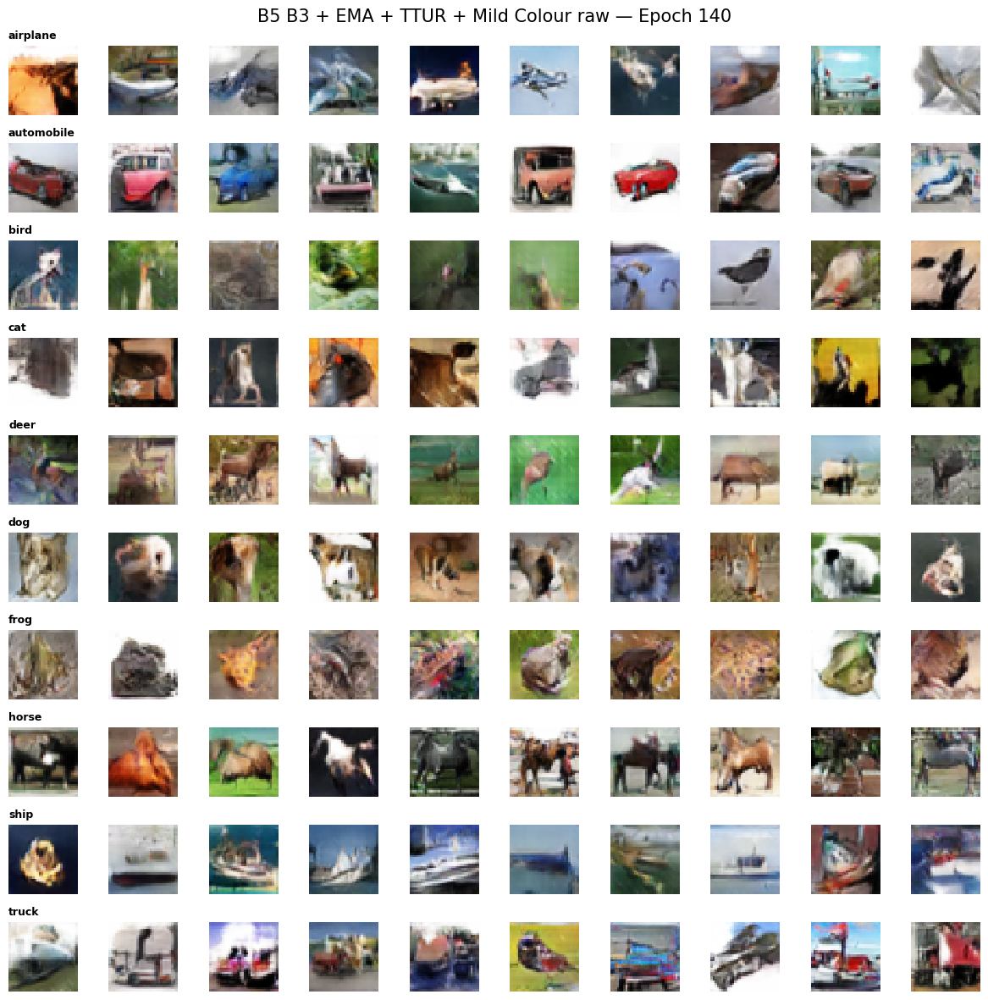

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_140.png


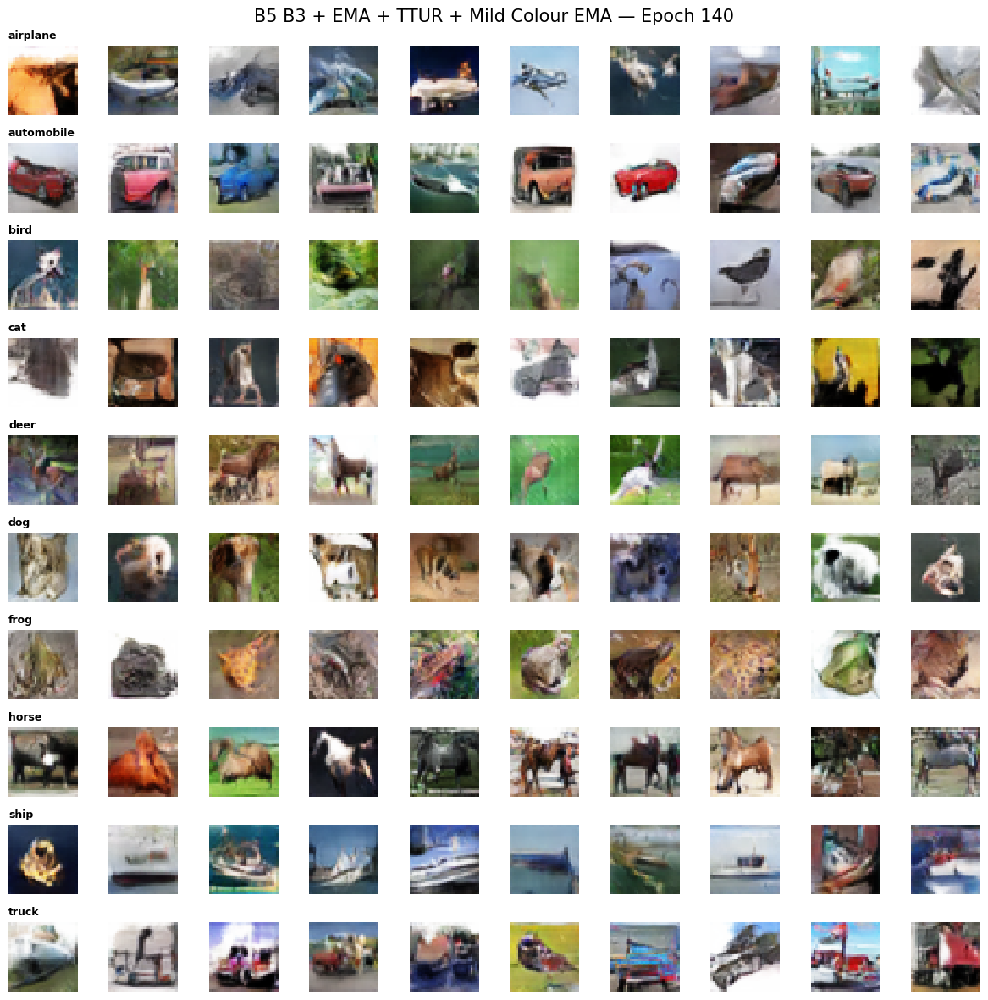

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_140.png
Epoch 141/150 | G 3.0303 | D 0.2464 | D(real) 0.8973 | D(fake) 0.1024 | D acc 0.9774 | 79.7s
Epoch 142/150 | G 3.0230 | D 0.2403 | D(real) 0.8993 | D(fake) 0.1003 | D acc 0.9793 | 80.6s
Epoch 143/150 | G 3.0194 | D 0.2452 | D(real) 0.8977 | D(fake) 0.1024 | D acc 0.9785 | 80.9s
Epoch 144/150 | G 3.0650 | D 0.2367 | D(real) 0.9004 | D(fake) 0.0991 | D acc 0.9804 | 81.2s
Epoch 145/150 | G 3.0853 | D 0.2414 | D(real) 0.8997 | D(fake) 0.0998 | D acc 0.9772 | 80.5s
Epoch 146/150 | G 3.0751 | D 0.2258 | D(real) 0.9039 | D(fake) 0.0953 | D acc 0.9832 | 81.1s
Epoch 147/150 | G 3.0713 | D 0.2259 | D(real) 0.9040 | D(fake) 0.0956 | D acc 0.9832 | 79.9s
Epoch 148/150 | G 3.0944 | D 0.2351 | D(real) 0.9017 | D(fake) 0.0985 | D acc 0.9803 | 80.1s
Epoch 149/150 | G 3.1064 | D 0.2327 | D(real) 0.9024 | D(fake) 0.0971 | D acc 0.9801 | 80.9s
Epoch 150/150 | G 3.0606 | D 0.2381 | D(real) 0.9003 

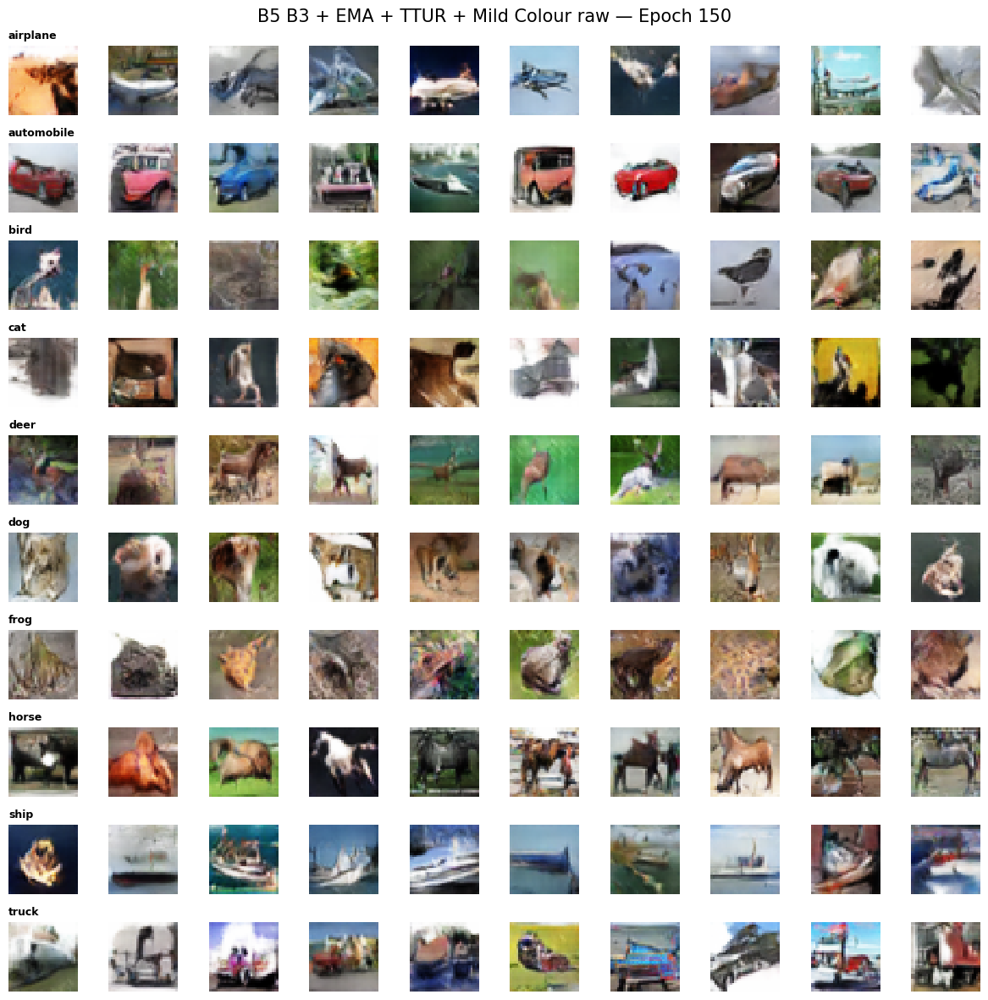

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_raw\generated_grid_epoch_150.png


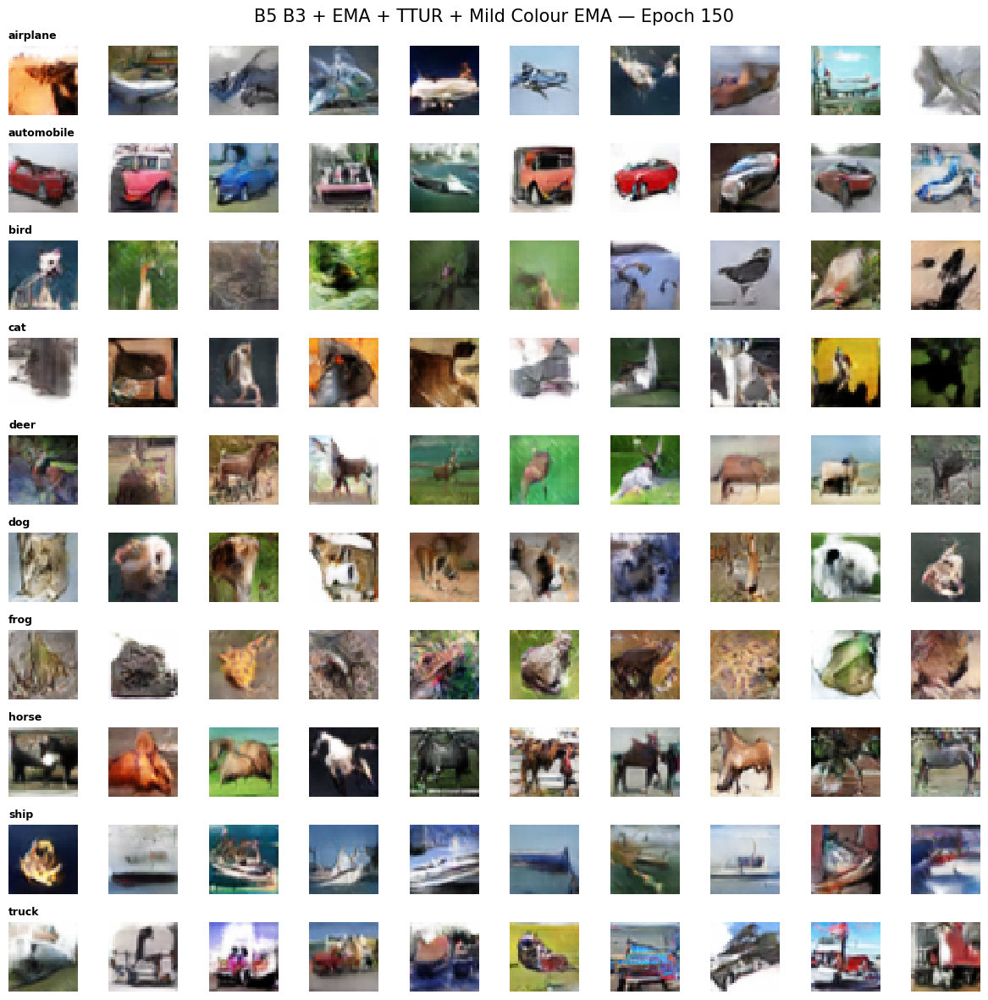

Saved grid: HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\generated_grids_ema\generated_grid_epoch_150.png
Completed B5 B3 + EMA + TTUR + Mild Colour: 50 epochs recorded.


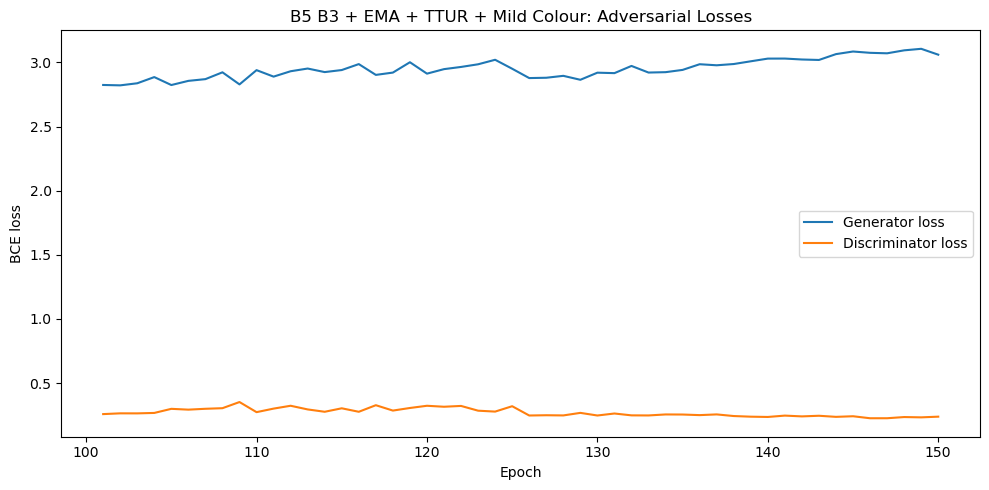

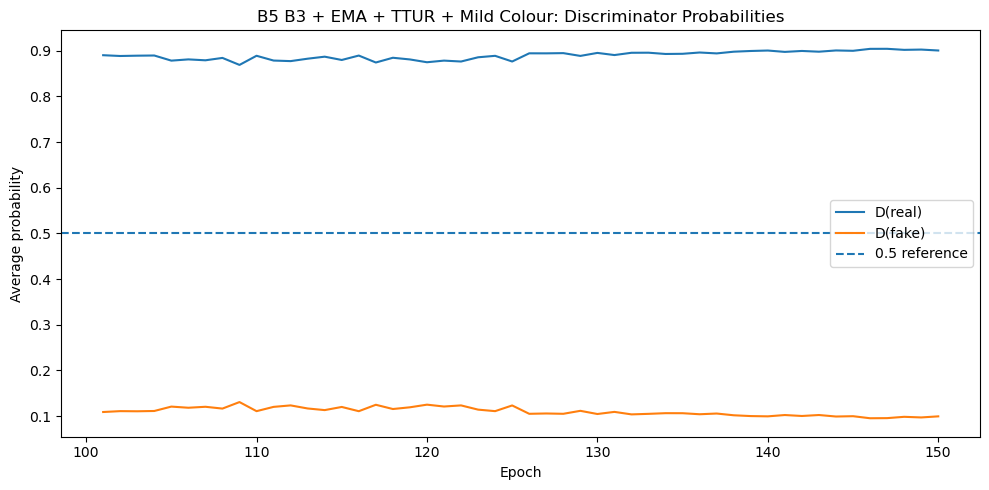

In [50]:
B5_RESULT = execute_b3_continuation(
    run_name="B5_B3_EMA_TTUR_mild_colour",
    run_label="B5 B3 + EMA + TTUR + Mild Colour",
    augmentation_function=mild_colour_translation_policy,
)


### B5 Training Assessment

B5 continued from the selected B3 epoch-100 checkpoint for an additional
50 epochs. It retained two-pixel translation, EMA tracking and the late TTUR
configuration, while adding mild colour augmentation to both real and generated
images before discriminator evaluation.

Because B5 is a continuation experiment, the plots cover epochs 101 to 150
rather than training from random initialization.

Training remained numerically stable throughout the continuation. The generator
loss stayed mostly between approximately 2.8 and 3.1, with a small gradual
increase toward the later epochs. The discriminator loss remained low,
generally between approximately 0.23 and 0.35, and became relatively stable
after approximately epoch 128.

The discriminator-probability plot shows that `D(real)` remained high at
approximately 0.87 to 0.90, while `D(fake)` remained low at approximately
0.10 to 0.13. This indicates that the discriminator continued to distinguish
real and generated images confidently. The slight increase in generator loss
also suggests that the generator became progressively harder to improve during
this late training stage.

Although the adversarial game remained imbalanced in favour of the
discriminator, there was no evidence of numerical divergence or complete mode
collapse. The losses remained finite, the probability curves changed gradually,
and no sudden sustained instability occurred. Mild colour augmentation
therefore did not destabilise the continuation.

EMA did not directly affect the displayed training losses because it maintains
a smoothed copy of the generator weights for evaluation. Its effect was assessed
by comparing the raw and EMA checkpoints using the same FID, KID and fixed-input
visual protocol.

The training curves were not used to select the strongest B5 checkpoint. FID
was used as the primary metric, KID was used as supporting evidence, and visual
inspection was used only to verify that the quantitative result was not
associated with severe repetition, major colour artefacts, mode collapse or
loss of conditional class structure.

#### B5 FID/KID Evaluation — Run After B5 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B5: epoch 100, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 100 | raw | FID 34.1947 | KID 0.014281 ± 0.003679
Evaluating B5: epoch 100, ema...
Epoch 100 | ema | FID 34.1947 | KID 0.014281 ± 0.003679
Evaluating B5: epoch 110, raw...
Epoch 110 | raw | FID 33.5234 | KID 0.013531 ± 0.003833
Evaluating B5: epoch 110, ema...
Epoch 110 | ema | FID 32.6012 | KID 0.013045 ± 0.003431
Evaluating B5: epoch 120, raw...
Epoch 120 | raw | FID 33.6019 | KID 0.014625 ± 0.003677
Evaluating B5: epoch 120, ema...
Epoch 120 | ema | FID 32.1114 | KID 0.012953 ± 0.003444
Evaluating B5: epoch 130, raw...
Epoch 130 | raw | FID 32.3033 | KID 0.013441 ± 0.003380
Evaluating B5: epoch 130, ema...
Epoch 130 | ema | FID 31.9499 | KID 0.012985 ± 0.003532
Evaluating B5: epoch 140, raw...
Epoch 140 | raw | FID 32.0147 | KID 0.01295

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B5,B5_B3_EMA_TTUR_mild_colour,100,ema,34.1947,0.014281,0.003679,5000
1,B5,B5_B3_EMA_TTUR_mild_colour,110,ema,32.6012,0.013045,0.003431,5000
2,B5,B5_B3_EMA_TTUR_mild_colour,120,ema,32.1114,0.012953,0.003444,5000
3,B5,B5_B3_EMA_TTUR_mild_colour,130,ema,31.9499,0.012985,0.003532,5000
4,B5,B5_B3_EMA_TTUR_mild_colour,140,ema,31.7243,0.012888,0.003280,5000
5,B5,B5_B3_EMA_TTUR_mild_colour,150,ema,31.0457,0.012302,0.003811,5000
6,B5,B5_B3_EMA_TTUR_mild_colour,100,raw,34.1947,0.014281,0.003679,5000
7,B5,B5_B3_EMA_TTUR_mild_colour,110,raw,33.5234,0.013531,0.003833,5000
8,B5,B5_B3_EMA_TTUR_mild_colour,120,raw,33.6019,0.014625,0.003677,5000
9,B5,B5_B3_EMA_TTUR_mild_colour,130,raw,32.3033,0.013441,0.003380,5000


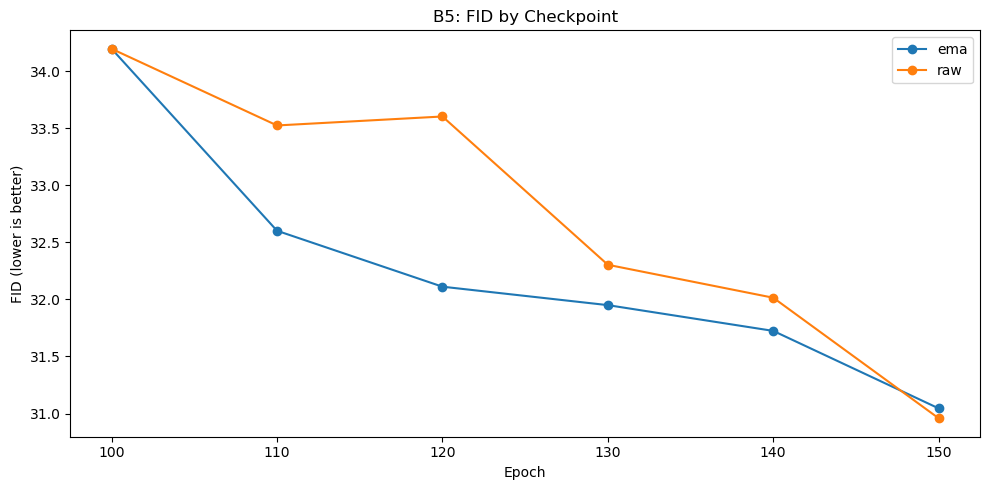

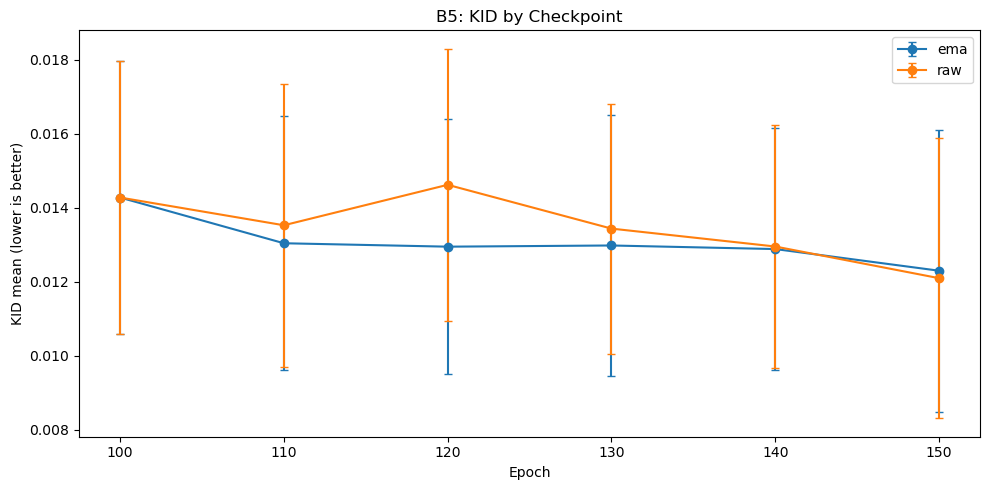

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [51]:
B5_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B5",
    run_name="B5_B3_EMA_TTUR_mild_colour",
    candidates=("raw", "ema"),
    expected_epochs=[100, 110, 120, 130, 140, 150],
)


### B5 Manual Review

- **Chosen B5 checkpoint:** Raw generator at epoch 150
- **FID:** 30.9592
- **KID mean ± standard deviation:** 0.012101 ± 0.003787
- **Decision:** Retained as the strongest checkpoint within B5, but not selected
  over B4 because B4 achieved a lower FID.

### Checkpoint Selection

The raw generator at epoch 150 was selected manually because it achieved the
lowest FID among all evaluated B5 raw and EMA checkpoints. FID was treated as
the primary checkpoint-selection metric.

The B5 raw FID improved from 34.1947 at epoch 100 to 30.9592 at epoch 150.
The improvement was not completely continuous because FID increased slightly
between epochs 110 and 120. However, performance improved substantially from
epoch 120 onward, and epoch 150 produced the lowest B5 FID.

KID was used as supporting evidence. The raw epoch-150 checkpoint also achieved
the lowest B5 KID mean of 0.012101. The KID uncertainty intervals overlap across
several late checkpoints, meaning that the small differences should not be
interpreted as conclusive by themselves. Nevertheless, KID supports rather
than contradicts the FID-based selection.

### Raw and EMA Comparison

EMA produced a smoother and more consistent improvement across the continuation,
especially between epochs 110 and 150. However, the raw epoch-150 generator
achieved slightly better FID and KID values than the EMA epoch-150 generator.
The raw generator was therefore selected as the strongest B5 candidate.

### Comparison with B4


B5 achieved a KID mean that was approximately 0.000250 lower than B4.
However, B5's FID was approximately 0.2441 points higher.

Because FID was defined as the primary model-selection metric, the small KID
Improvement was not sufficient to replace B4 as the overall leading candidate.
The KID uncertainty ranges also overlap considerably, so the difference between
the two KID means should not be treated as strong evidence of a meaningful
advantage.

### Visual Verification

The fixed-input class-balanced grids for B5 raw and EMA were inspected only as
a verification step. The inspection checked that the mild colour augmentation
had not introduced severe colour distortion, mode collapse, excessive
duplication, major artefacts or complete loss of requested-class structure.

The visual outputs did not reveal an obvious failure that contradicted the FID
and KID results. However, the visual inspection also did not show a sufficiently
clear improvement over B4 to override B4's lower FID.

### Mild-Colour-Augmentation Conclusion

Mild colour augmentation produced competitive results and the best KID mean
observed at this stage. However, it did not improve the primary FID metric
relative to B4. The additional colour augmentation was therefore considered a
useful but unsuccessful attempt to improve the overall leading model.

B5 raw at epoch 150 was retained as the strongest B5 checkpoint and as a final
comparison candidate, while B4 raw at epoch 150 remained the provisional
overall winner.

- **Visual label counts:** The detailed `clear / marginal / nonsense`
  assessment was completed only during the final shortlisted-candidate
  comparison.
- **Requested-class match observations:** General conditional consistency and
  colour plausibility were verified using the fixed-input grids, while detailed
  class matching was reserved for the final visual-labelling stage.

### 8.7 B6 — Minibatch Standard Deviation

B6 is a fresh 100-epoch run. It keeps the B3 translation policy and BCE loss,
but adds one minibatch-standard-deviation feature channel before the
discriminator is flattened. This gives the discriminator a direct signal about
variation across a batch and targets repeated or low-diversity samples (Karras
et al., 2017).


#### Why B6 Is Retained Even If It Performs Worse

B6 is kept because it tests a distinct diversity-related discriminator feature.
A controlled negative result is useful evidence: it shows that an idea intended
to discourage repeated samples does not necessarily improve CIFAR-10 quality in
this architecture. The result should be discussed rather than hidden if FID,
KID or the visual grids regress.


Epoch 001/100 | G 3.7892 | D 0.2488 | D(real) 0.9126 | D(fake) 0.0812 | D acc 0.9614 | 82.6s
Epoch 002/100 | G 2.7579 | D 0.3811 | D(real) 0.8594 | D(fake) 0.1368 | D acc 0.9397 | 78.9s
Epoch 003/100 | G 2.2890 | D 0.5025 | D(real) 0.8156 | D(fake) 0.1835 | D acc 0.9126 | 80.2s
Epoch 004/100 | G 2.2334 | D 0.5224 | D(real) 0.8093 | D(fake) 0.1897 | D acc 0.9110 | 79.1s
Epoch 005/100 | G 2.2085 | D 0.5464 | D(real) 0.8035 | D(fake) 0.1965 | D acc 0.9045 | 78.4s
Epoch 006/100 | G 2.1390 | D 0.5742 | D(real) 0.7952 | D(fake) 0.2046 | D acc 0.8993 | 79.4s
Epoch 007/100 | G 1.9425 | D 0.6501 | D(real) 0.7672 | D(fake) 0.2318 | D acc 0.8742 | 81.9s
Epoch 008/100 | G 1.9099 | D 0.6522 | D(real) 0.7635 | D(fake) 0.2356 | D acc 0.8726 | 79.0s
Epoch 009/100 | G 1.8377 | D 0.7205 | D(real) 0.7500 | D(fake) 0.2515 | D acc 0.8577 | 79.1s
Epoch 010/100 | G 1.8299 | D 0.7165 | D(real) 0.7502 | D(fake) 0.2477 | D acc 0.8688 | 78.8s
Saved checkpoint: HeinHtetPartA_outputs\B6_minibatch_stddev_translatio

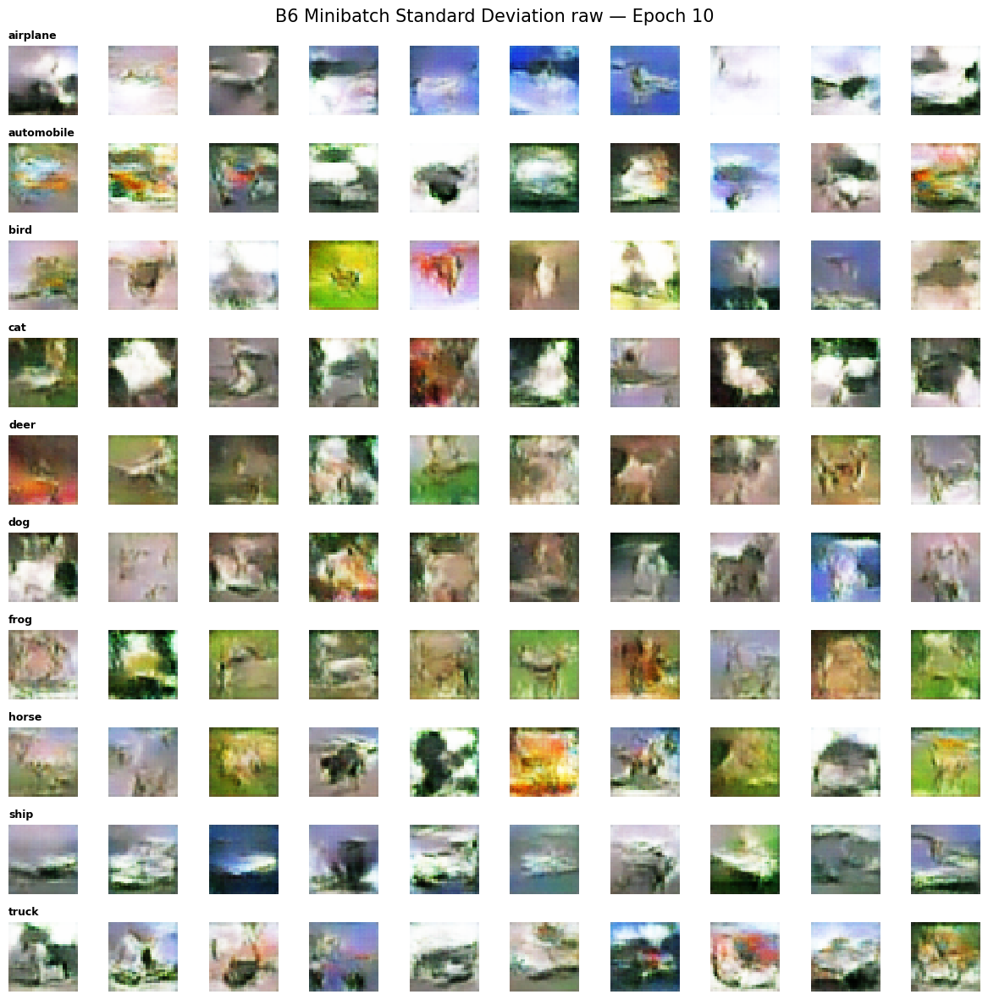

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_010.png
Epoch 011/100 | G 1.8778 | D 0.6269 | D(real) 0.7682 | D(fake) 0.2305 | D acc 0.8930 | 78.5s
Epoch 012/100 | G 1.9043 | D 0.6885 | D(real) 0.7595 | D(fake) 0.2401 | D acc 0.8720 | 80.6s
Epoch 013/100 | G 1.8904 | D 0.6725 | D(real) 0.7579 | D(fake) 0.2413 | D acc 0.8679 | 78.7s
Epoch 014/100 | G 1.7907 | D 0.6954 | D(real) 0.7490 | D(fake) 0.2496 | D acc 0.8719 | 79.0s
Epoch 015/100 | G 1.7872 | D 0.6959 | D(real) 0.7473 | D(fake) 0.2525 | D acc 0.8648 | 80.2s
Epoch 016/100 | G 1.7933 | D 0.6858 | D(real) 0.7511 | D(fake) 0.2490 | D acc 0.8701 | 78.5s
Epoch 017/100 | G 1.7902 | D 0.7089 | D(real) 0.7458 | D(fake) 0.2524 | D acc 0.8663 | 78.3s
Epoch 018/100 | G 1.8561 | D 0.7310 | D(real) 0.7473 | D(fake) 0.2524 | D acc 0.8562 | 79.2s
Epoch 019/100 | G 1.8227 | D 0.6738 | D(real) 0.7552 | D(fake) 0.2450 | D acc 0.8778 | 79.6s
Epoch 020/100 | G 1.8070 | D 0.6663 | D(real) 0.

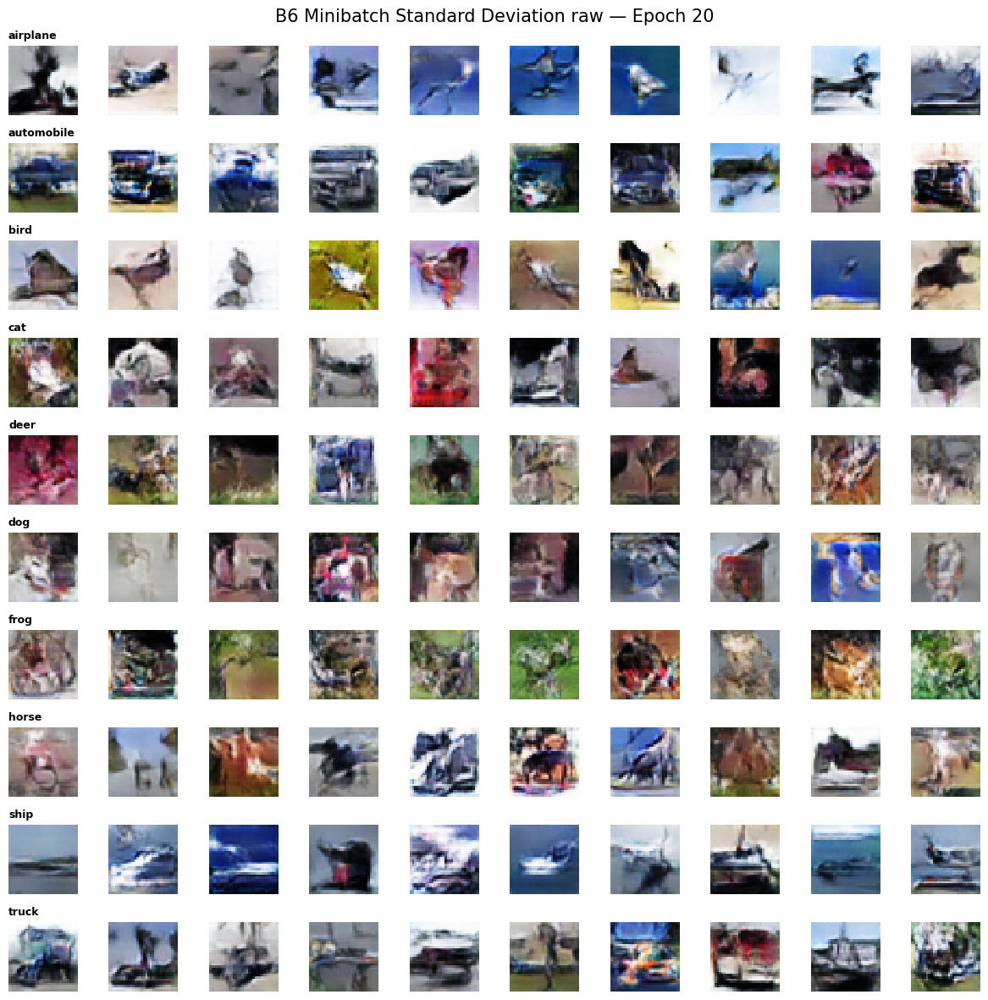

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_020.png
Epoch 021/100 | G 1.8000 | D 0.7351 | D(real) 0.7438 | D(fake) 0.2559 | D acc 0.8604 | 79.9s
Epoch 022/100 | G 1.8103 | D 0.7110 | D(real) 0.7468 | D(fake) 0.2528 | D acc 0.8633 | 79.0s
Epoch 023/100 | G 1.7940 | D 0.6876 | D(real) 0.7526 | D(fake) 0.2465 | D acc 0.8814 | 80.1s
Epoch 024/100 | G 1.8078 | D 0.6925 | D(real) 0.7505 | D(fake) 0.2492 | D acc 0.8726 | 79.8s
Epoch 025/100 | G 1.8128 | D 0.7609 | D(real) 0.7402 | D(fake) 0.2596 | D acc 0.8540 | 79.3s
Epoch 026/100 | G 1.8085 | D 0.6679 | D(real) 0.7530 | D(fake) 0.2453 | D acc 0.8776 | 78.4s
Epoch 027/100 | G 1.8194 | D 0.7388 | D(real) 0.7441 | D(fake) 0.2564 | D acc 0.8579 | 79.3s
Epoch 028/100 | G 1.8049 | D 0.7000 | D(real) 0.7485 | D(fake) 0.2504 | D acc 0.8685 | 78.2s
Epoch 029/100 | G 1.8211 | D 0.6582 | D(real) 0.7574 | D(fake) 0.2426 | D acc 0.8803 | 76.6s
Epoch 030/100 | G 1.8480 | D 0.6978 | D(real) 0.

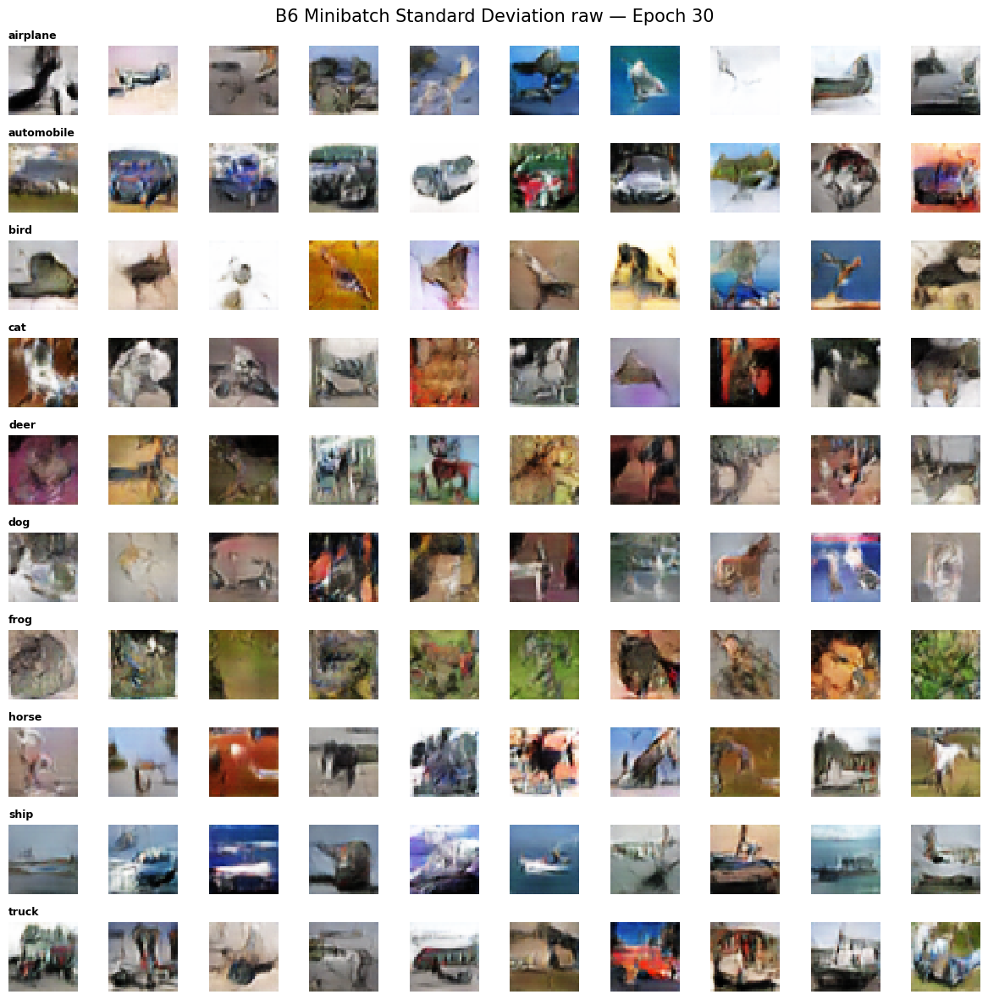

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_030.png
Epoch 031/100 | G 1.8029 | D 0.7330 | D(real) 0.7500 | D(fake) 0.2499 | D acc 0.8743 | 78.4s
Epoch 032/100 | G 1.8423 | D 0.6691 | D(real) 0.7550 | D(fake) 0.2437 | D acc 0.8776 | 77.1s
Epoch 033/100 | G 1.8617 | D 0.6955 | D(real) 0.7569 | D(fake) 0.2439 | D acc 0.8759 | 79.2s
Epoch 034/100 | G 1.8617 | D 0.6700 | D(real) 0.7598 | D(fake) 0.2391 | D acc 0.8834 | 78.4s
Epoch 035/100 | G 1.8329 | D 0.7385 | D(real) 0.7482 | D(fake) 0.2506 | D acc 0.8645 | 77.8s
Epoch 036/100 | G 1.8678 | D 0.6563 | D(real) 0.7617 | D(fake) 0.2380 | D acc 0.8833 | 79.4s
Epoch 037/100 | G 1.8956 | D 0.6392 | D(real) 0.7674 | D(fake) 0.2321 | D acc 0.8892 | 77.8s
Epoch 038/100 | G 1.9359 | D 0.7095 | D(real) 0.7599 | D(fake) 0.2407 | D acc 0.8729 | 78.7s
Epoch 039/100 | G 1.9109 | D 0.6619 | D(real) 0.7634 | D(fake) 0.2357 | D acc 0.8828 | 79.3s
Epoch 040/100 | G 1.9631 | D 0.6772 | D(real) 0.

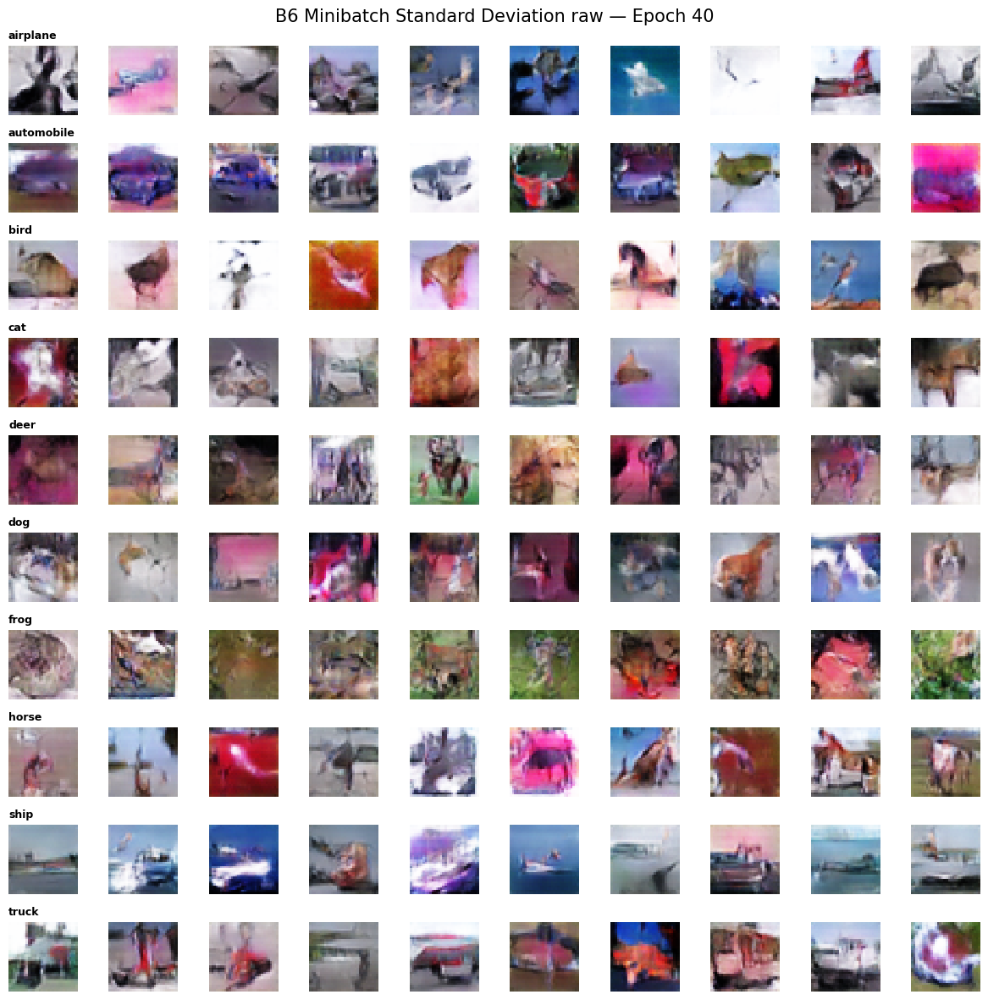

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_040.png
Epoch 041/100 | G 1.8902 | D 0.6536 | D(real) 0.7656 | D(fake) 0.2353 | D acc 0.8888 | 76.6s
Epoch 042/100 | G 1.9380 | D 0.6487 | D(real) 0.7682 | D(fake) 0.2318 | D acc 0.8829 | 79.0s
Epoch 043/100 | G 1.9679 | D 0.6014 | D(real) 0.7769 | D(fake) 0.2217 | D acc 0.8982 | 78.2s
Epoch 044/100 | G 1.9866 | D 0.6799 | D(real) 0.7713 | D(fake) 0.2296 | D acc 0.8847 | 78.2s
Epoch 045/100 | G 1.9997 | D 0.6496 | D(real) 0.7758 | D(fake) 0.2238 | D acc 0.8909 | 78.8s
Epoch 046/100 | G 1.9624 | D 0.5822 | D(real) 0.7812 | D(fake) 0.2175 | D acc 0.9072 | 78.7s
Epoch 047/100 | G 2.0066 | D 0.7030 | D(real) 0.7669 | D(fake) 0.2328 | D acc 0.8748 | 77.3s
Epoch 048/100 | G 2.0184 | D 0.6039 | D(real) 0.7798 | D(fake) 0.2200 | D acc 0.8949 | 78.1s
Epoch 049/100 | G 2.0175 | D 0.5953 | D(real) 0.7808 | D(fake) 0.2185 | D acc 0.8950 | 78.6s
Epoch 050/100 | G 2.0497 | D 0.5982 | D(real) 0.

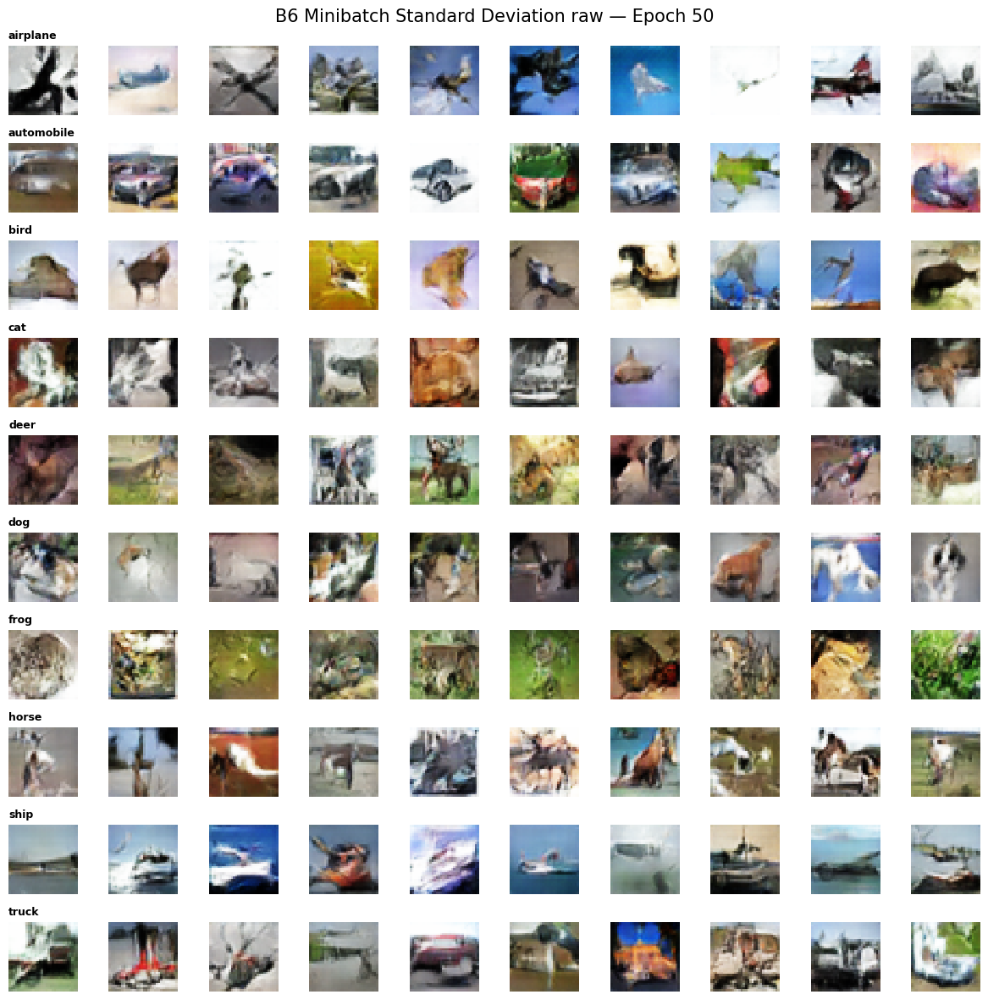

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_050.png
Epoch 051/100 | G 2.0426 | D 0.6389 | D(real) 0.7785 | D(fake) 0.2215 | D acc 0.8889 | 80.1s
Epoch 052/100 | G 2.0686 | D 0.5944 | D(real) 0.7865 | D(fake) 0.2137 | D acc 0.8977 | 79.3s
Epoch 053/100 | G 2.0872 | D 0.6239 | D(real) 0.7813 | D(fake) 0.2180 | D acc 0.8898 | 78.2s
Epoch 054/100 | G 2.0807 | D 0.6011 | D(real) 0.7874 | D(fake) 0.2117 | D acc 0.9026 | 79.5s
Epoch 055/100 | G 2.0933 | D 0.5925 | D(real) 0.7886 | D(fake) 0.2109 | D acc 0.8996 | 78.6s
Epoch 056/100 | G 2.1025 | D 0.5829 | D(real) 0.7926 | D(fake) 0.2069 | D acc 0.9078 | 78.4s
Epoch 057/100 | G 2.1331 | D 0.6041 | D(real) 0.7897 | D(fake) 0.2107 | D acc 0.8940 | 79.2s
Epoch 058/100 | G 2.1397 | D 0.5673 | D(real) 0.7965 | D(fake) 0.2029 | D acc 0.9068 | 78.6s
Epoch 059/100 | G 2.1539 | D 0.5705 | D(real) 0.7952 | D(fake) 0.2048 | D acc 0.9021 | 78.3s
Epoch 060/100 | G 2.1762 | D 0.5886 | D(real) 0.

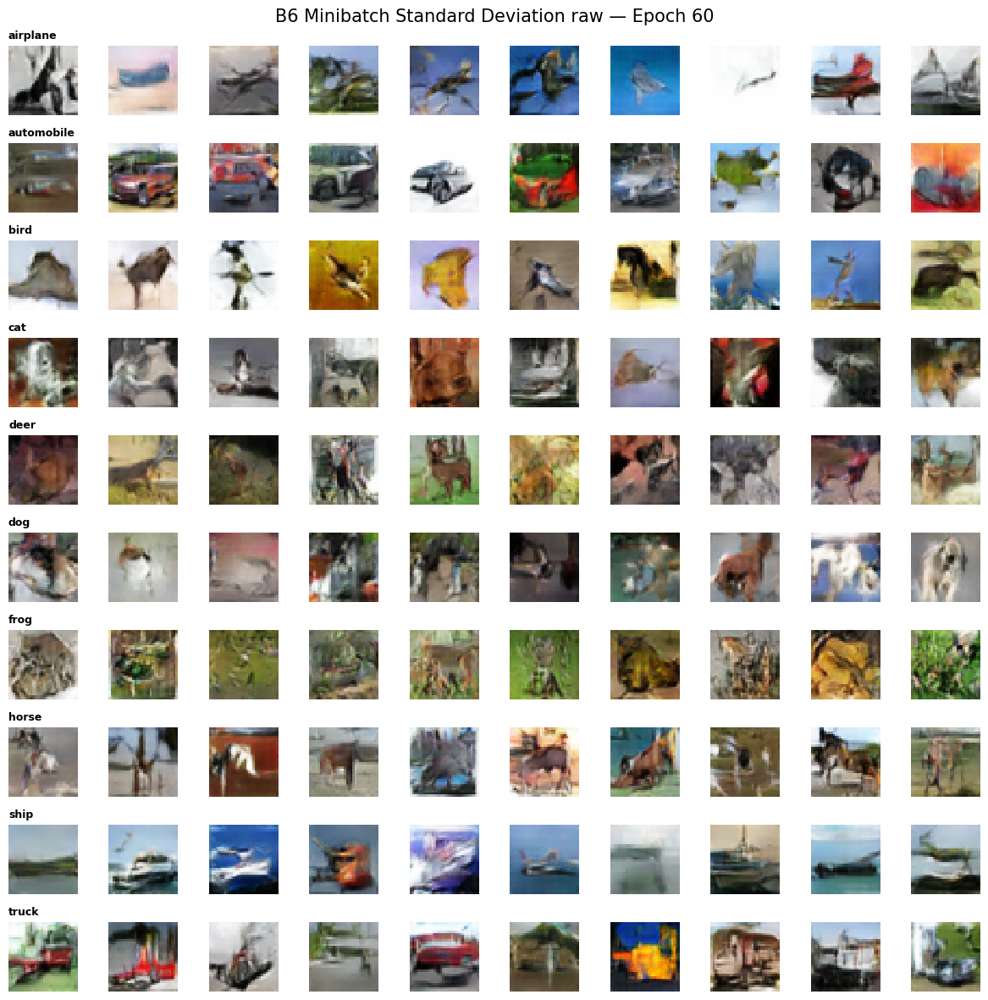

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_060.png
Epoch 061/100 | G 2.1777 | D 0.6004 | D(real) 0.7929 | D(fake) 0.2067 | D acc 0.8978 | 78.6s
Epoch 062/100 | G 2.1949 | D 0.5473 | D(real) 0.7996 | D(fake) 0.1999 | D acc 0.9041 | 79.2s
Epoch 063/100 | G 2.2071 | D 0.5219 | D(real) 0.8052 | D(fake) 0.1942 | D acc 0.9143 | 78.9s
Epoch 064/100 | G 2.2275 | D 0.5671 | D(real) 0.8040 | D(fake) 0.1956 | D acc 0.9113 | 78.8s
Epoch 065/100 | G 2.2170 | D 0.7123 | D(real) 0.7890 | D(fake) 0.2121 | D acc 0.8936 | 77.0s
Epoch 066/100 | G 2.1865 | D 0.5117 | D(real) 0.8064 | D(fake) 0.1923 | D acc 0.9173 | 78.5s
Epoch 067/100 | G 2.2510 | D 0.5154 | D(real) 0.8072 | D(fake) 0.1920 | D acc 0.9124 | 78.8s
Epoch 068/100 | G 2.2378 | D 0.5969 | D(real) 0.7992 | D(fake) 0.2008 | D acc 0.9032 | 78.0s
Epoch 069/100 | G 2.2883 | D 0.4649 | D(real) 0.8221 | D(fake) 0.1773 | D acc 0.9338 | 77.7s
Epoch 070/100 | G 2.2705 | D 0.6288 | D(real) 0.

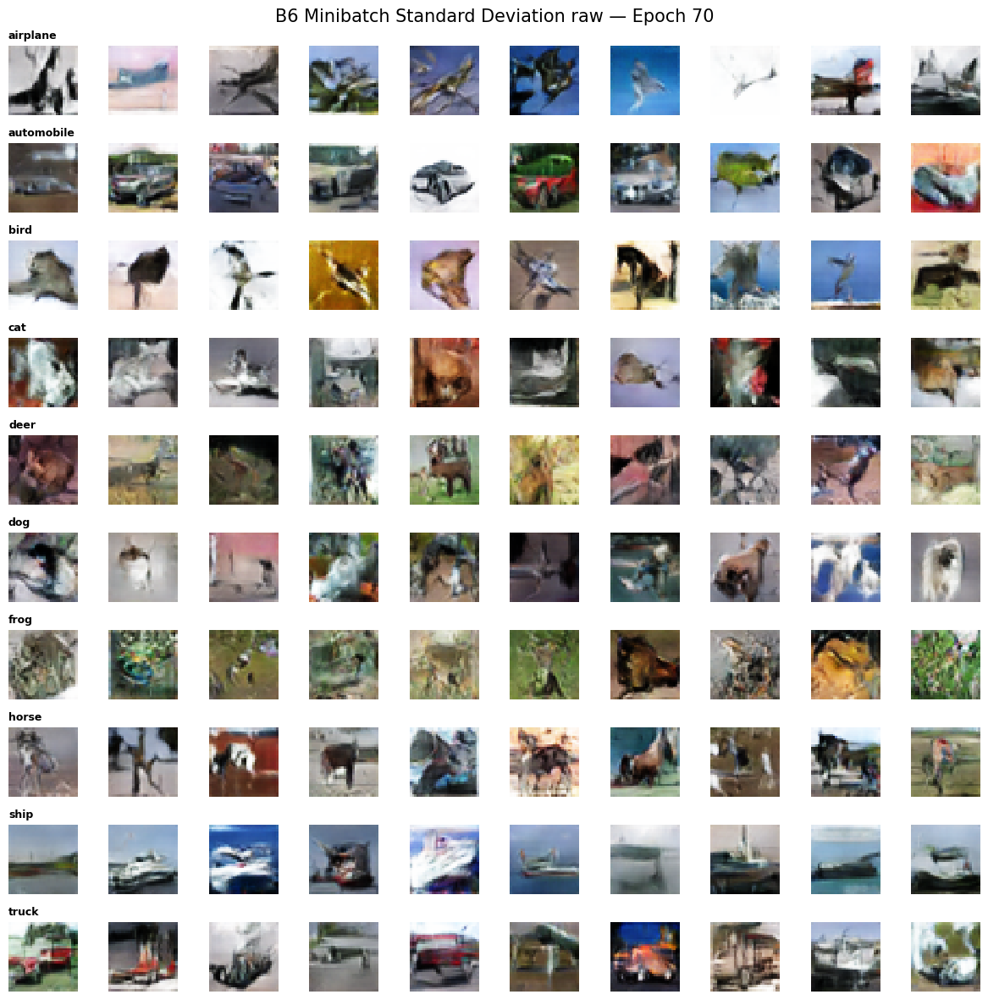

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_070.png
Epoch 071/100 | G 2.2860 | D 0.4932 | D(real) 0.8152 | D(fake) 0.1851 | D acc 0.9206 | 79.2s
Epoch 072/100 | G 2.2981 | D 0.5365 | D(real) 0.8116 | D(fake) 0.1886 | D acc 0.9149 | 79.0s
Epoch 073/100 | G 2.3412 | D 0.5383 | D(real) 0.8082 | D(fake) 0.1905 | D acc 0.9046 | 79.4s
Epoch 074/100 | G 2.3440 | D 0.4679 | D(real) 0.8234 | D(fake) 0.1764 | D acc 0.9264 | 77.8s
Epoch 075/100 | G 2.3098 | D 0.7023 | D(real) 0.7987 | D(fake) 0.2008 | D acc 0.8990 | 78.9s
Epoch 076/100 | G 2.3680 | D 0.5234 | D(real) 0.8197 | D(fake) 0.1800 | D acc 0.9228 | 79.6s
Epoch 077/100 | G 2.3609 | D 0.5815 | D(real) 0.8124 | D(fake) 0.1873 | D acc 0.9116 | 78.2s
Epoch 078/100 | G 2.3533 | D 0.4539 | D(real) 0.8255 | D(fake) 0.1742 | D acc 0.9329 | 79.2s
Epoch 079/100 | G 2.3892 | D 0.4546 | D(real) 0.8271 | D(fake) 0.1718 | D acc 0.9292 | 79.3s
Epoch 080/100 | G 2.3244 | D 0.6753 | D(real) 0.

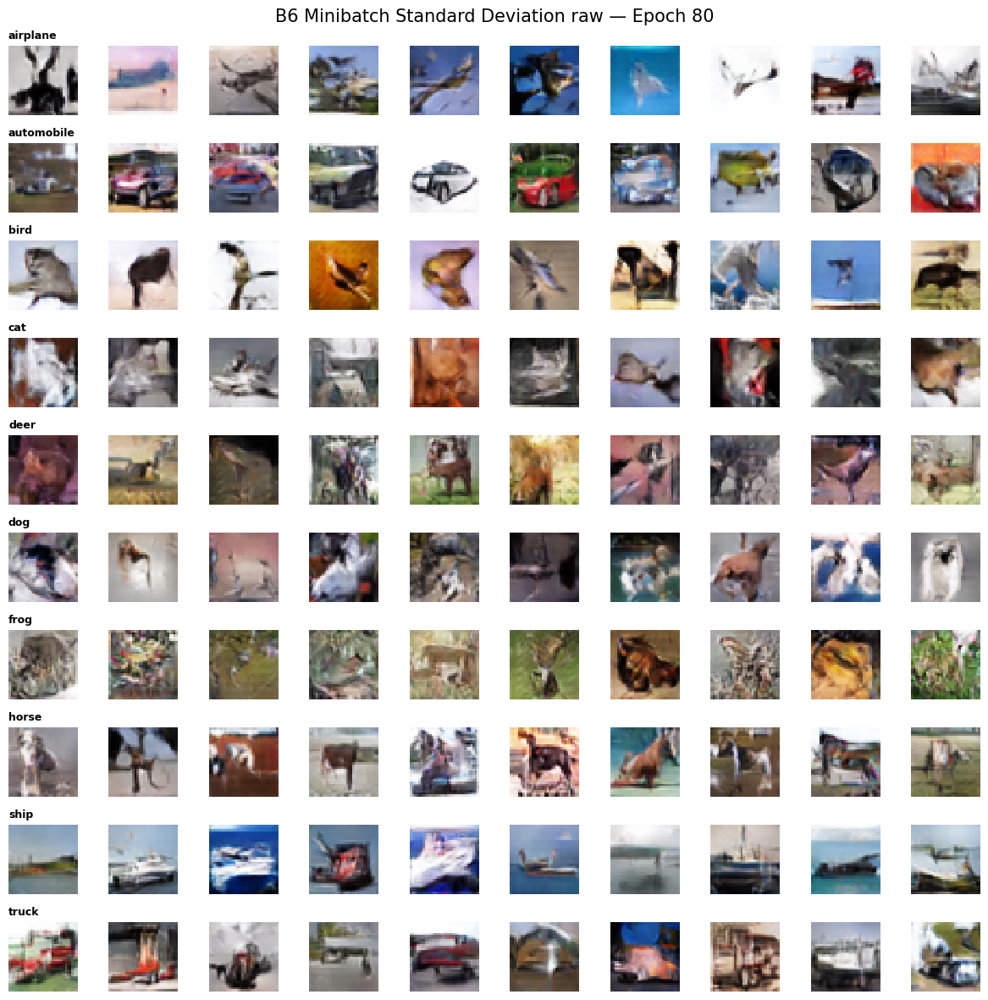

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_080.png
Epoch 081/100 | G 2.4007 | D 0.5440 | D(real) 0.8226 | D(fake) 0.1771 | D acc 0.9244 | 77.8s
Epoch 082/100 | G 2.3969 | D 0.4669 | D(real) 0.8264 | D(fake) 0.1730 | D acc 0.9292 | 79.1s
Epoch 083/100 | G 2.4032 | D 0.5440 | D(real) 0.8184 | D(fake) 0.1813 | D acc 0.9174 | 78.8s
Epoch 084/100 | G 2.4430 | D 0.4435 | D(real) 0.8317 | D(fake) 0.1680 | D acc 0.9303 | 78.3s
Epoch 085/100 | G 2.4103 | D 0.5275 | D(real) 0.8208 | D(fake) 0.1784 | D acc 0.9215 | 79.3s
Epoch 086/100 | G 2.4531 | D 0.4723 | D(real) 0.8288 | D(fake) 0.1716 | D acc 0.9261 | 78.7s
Epoch 087/100 | G 2.5115 | D 0.5111 | D(real) 0.8259 | D(fake) 0.1735 | D acc 0.9195 | 77.9s
Epoch 088/100 | G 2.5262 | D 0.5011 | D(real) 0.8295 | D(fake) 0.1700 | D acc 0.9245 | 79.2s
Epoch 089/100 | G 2.4937 | D 0.4876 | D(real) 0.8304 | D(fake) 0.1704 | D acc 0.9249 | 79.2s
Epoch 090/100 | G 2.4918 | D 0.4099 | D(real) 0.

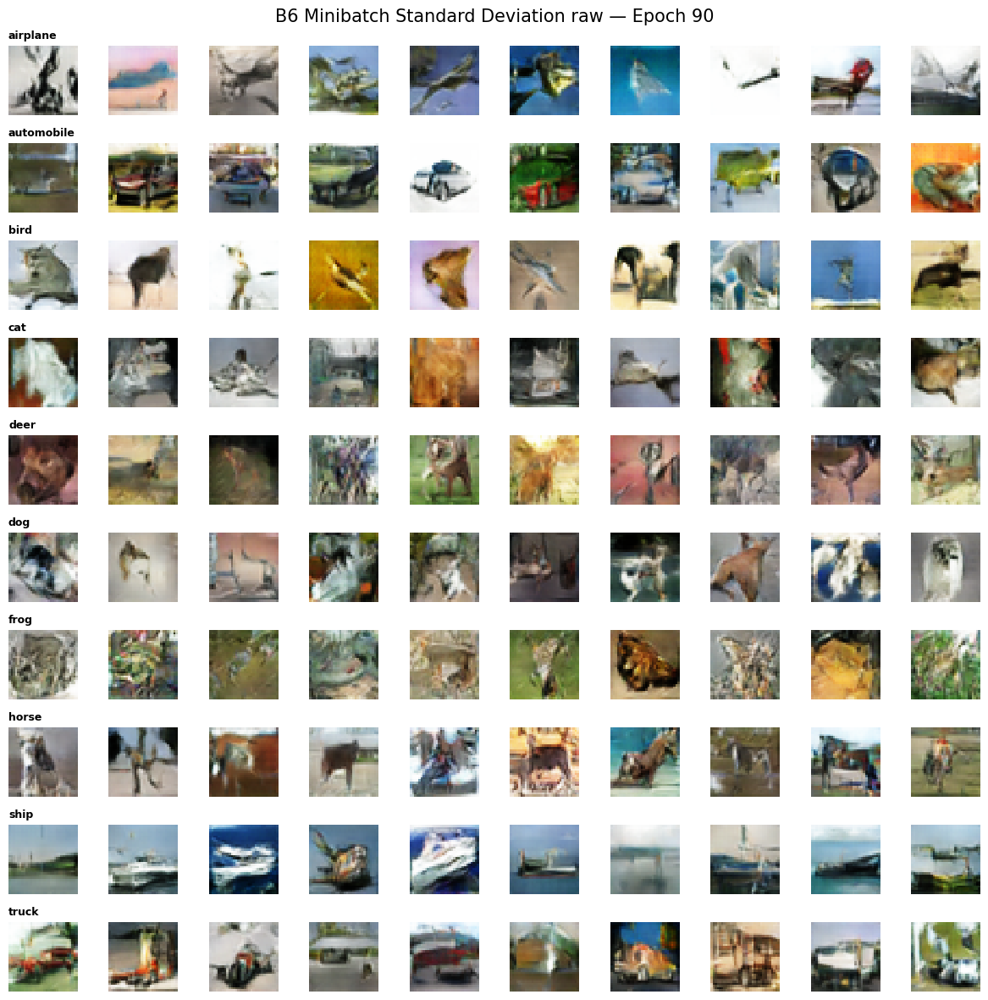

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_090.png
Epoch 091/100 | G 2.4860 | D 0.6424 | D(real) 0.8101 | D(fake) 0.1897 | D acc 0.8978 | 79.6s
Epoch 092/100 | G 2.4811 | D 0.3779 | D(real) 0.8489 | D(fake) 0.1509 | D acc 0.9534 | 79.5s
Epoch 093/100 | G 2.5105 | D 0.5015 | D(real) 0.8308 | D(fake) 0.1687 | D acc 0.9273 | 78.8s
Epoch 094/100 | G 2.5607 | D 0.5033 | D(real) 0.8353 | D(fake) 0.1649 | D acc 0.9287 | 80.8s
Epoch 095/100 | G 2.5467 | D 0.4167 | D(real) 0.8425 | D(fake) 0.1576 | D acc 0.9365 | 80.1s
Epoch 096/100 | G 2.5627 | D 0.5348 | D(real) 0.8238 | D(fake) 0.1757 | D acc 0.9099 | 78.9s
Epoch 097/100 | G 2.5531 | D 0.3600 | D(real) 0.8558 | D(fake) 0.1439 | D acc 0.9570 | 80.3s
Epoch 098/100 | G 2.5389 | D 0.5708 | D(real) 0.8264 | D(fake) 0.1735 | D acc 0.9166 | 78.7s
Epoch 099/100 | G 2.6122 | D 0.4577 | D(real) 0.8434 | D(fake) 0.1562 | D acc 0.9362 | 78.5s
Epoch 100/100 | G 2.5899 | D 0.4863 | D(real) 0.

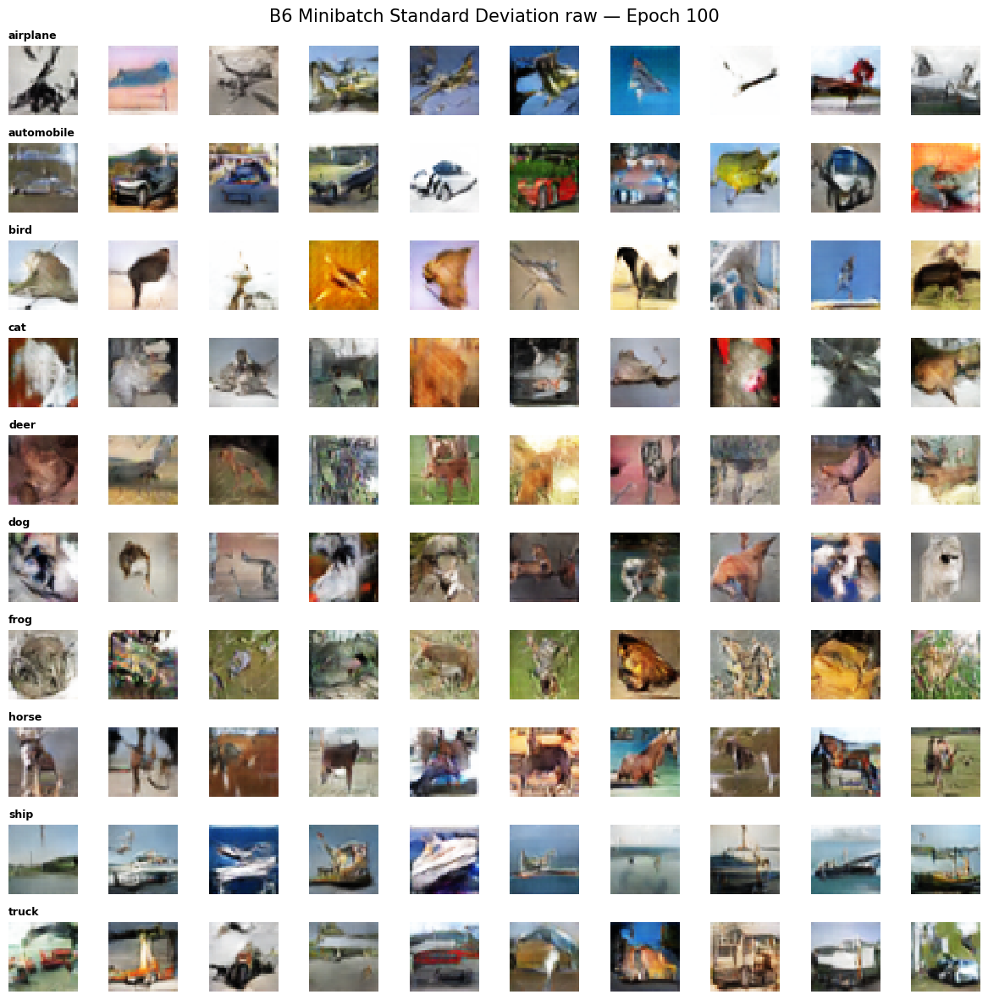

Saved grid: HeinHtetPartA_outputs\B6_minibatch_stddev_translation\generated_grids_raw\generated_grid_epoch_100.png
Completed B6 Minibatch Standard Deviation: 100 epochs recorded.


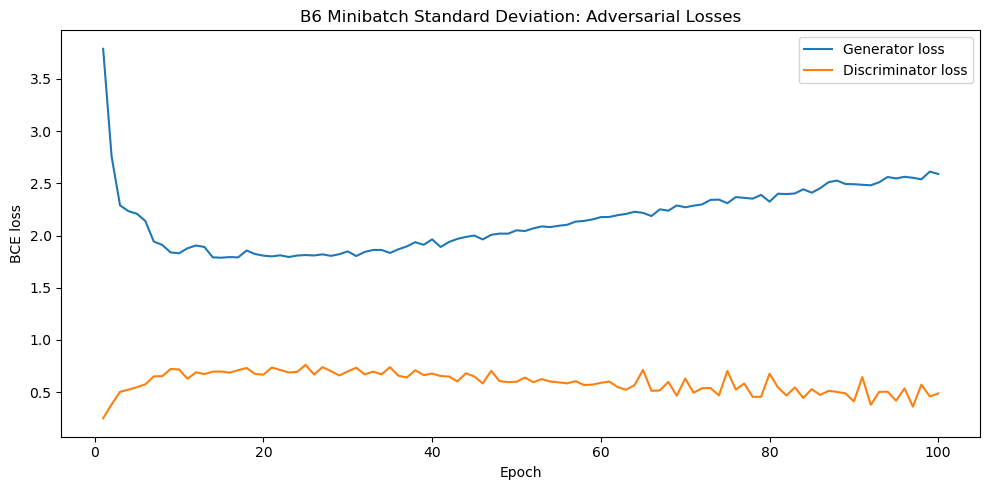

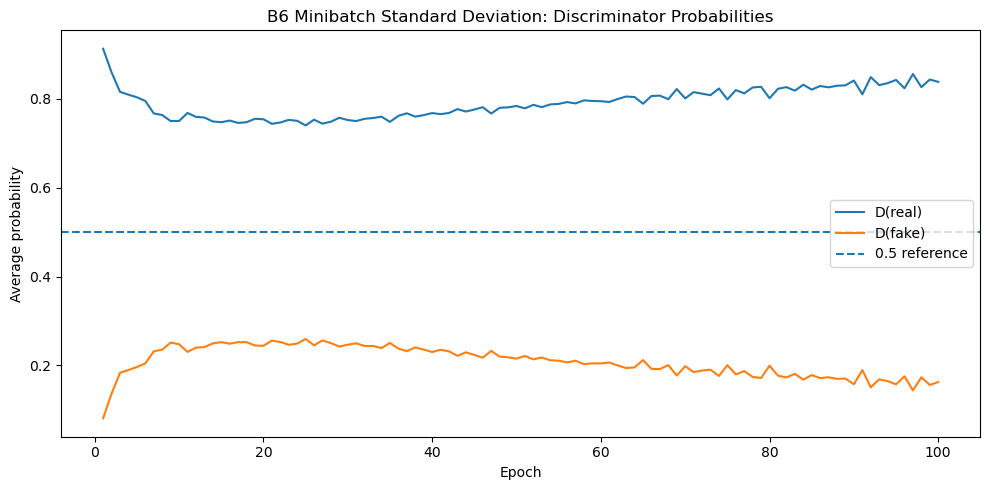

In [52]:
B6_RESULT = execute_fresh_experiment(
    run_name="B6_minibatch_stddev_translation",
    run_label="B6 Minibatch Standard Deviation",
    augmentation_function=translation_policy,
    discriminator_builder=lambda: build_discriminator(
        add_minibatch_stddev=True
    ),
)


### B6 Training Assessment

B6 adds a minibatch standard-deviation feature to the discriminator while
retaining the two-pixel translation augmentation used in B3. The purpose was to
give the discriminator information about variation across each minibatch,
potentially discouraging the generator from producing overly similar images.

Training remained numerically stable throughout all 100 epochs. The generator
loss decreased rapidly from approximately 3.8 to around 1.8 during the first
20 epochs. It then remained relatively stable until approximately epoch 35
before gradually increasing to around 2.6 by epoch 100. This indicates that the
generator initially became more effective but found it increasingly difficult
to fool the discriminator during the later stages.

The discriminator loss increased from approximately 0.25 to around 0.70 during
the early epochs before gradually decreasing to approximately 0.50 near the end
of training. This suggests that the generator temporarily became more
competitive before the discriminator regained part of its advantage.

The discriminator-probability plot supports this interpretation. `D(real)`
decreased from above 0.90 to approximately 0.75 during the early and middle
stages before gradually increasing to around 0.84. At the same time, `D(fake)`
increased from approximately 0.08 to around 0.25 before declining to
approximately 0.16 by epoch 100.

The discriminator therefore remained stronger than the generator at the end of
training, although the separation between `D(real)` and `D(fake)` was less
extreme than in the late B4 and B5 continuation experiments.

There was no evidence of numerical divergence or complete training collapse.
The losses remained finite, the probability curves changed gradually, and the
minibatch standard-deviation feature did not destabilise training.

The loss curves were not used directly to choose the best checkpoint because
GAN losses do not reliably represent perceptual image quality. FID was used as
the primary checkpoint-selection metric, KID was used as supporting evidence,
and the saved fixed-input grids were inspected only to verify that the selected
checkpoint did not contain severe mode collapse, excessive repetition, major
artefacts or loss of conditional class structure.

#### B6 FID/KID Evaluation — Run After B6 Training


Loaded cached real features: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\feature_cache\cifar10_validation_5000_inceptionv3.npy
Evaluating B6: epoch 10, raw...
Loading InceptionV3 for FID/KID evaluation...
Epoch 010 | raw | FID 102.8620 | KID 0.081865 ± 0.007158
Evaluating B6: epoch 20, raw...
Epoch 020 | raw | FID 60.0376 | KID 0.036880 ± 0.004694
Evaluating B6: epoch 30, raw...
Epoch 030 | raw | FID 48.2192 | KID 0.027018 ± 0.004160
Evaluating B6: epoch 40, raw...
Epoch 040 | raw | FID 48.5828 | KID 0.025830 ± 0.004138
Evaluating B6: epoch 50, raw...
Epoch 050 | raw | FID 45.3976 | KID 0.024711 ± 0.005125
Evaluating B6: epoch 60, raw...
Epoch 060 | raw | FID 37.7384 | KID 0.017094 ± 0.003313
Evaluating B6: epoch 70, raw...
Epoch 070 | raw | FID 38.8483 | KID 0.019067 ± 0.003257
Evaluating B6: epoch 80, raw...
Epoch 080 | raw | FID 34.9381 | KID 0.016044 ± 0.003818
Evaluating B6: epoch 90, raw...
Epoch 090 | raw | FID 36.1806 | KID 0.016615 ± 0.00

,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B6,B6_minibatch_stddev_translation,10,raw,102.8620,0.081865,0.007158,5000
1,B6,B6_minibatch_stddev_translation,20,raw,60.0376,0.036880,0.004694,5000
2,B6,B6_minibatch_stddev_translation,30,raw,48.2192,0.027018,0.004160,5000
3,B6,B6_minibatch_stddev_translation,40,raw,48.5828,0.025830,0.004138,5000
4,B6,B6_minibatch_stddev_translation,50,raw,45.3976,0.024711,0.005125,5000
5,B6,B6_minibatch_stddev_translation,60,raw,37.7384,0.017094,0.003313,5000
6,B6,B6_minibatch_stddev_translation,70,raw,38.8483,0.019067,0.003257,5000
7,B6,B6_minibatch_stddev_translation,80,raw,34.9381,0.016044,0.003818,5000
8,B6,B6_minibatch_stddev_translation,90,raw,36.1806,0.016615,0.003873,5000
9,B6,B6_minibatch_stddev_translation,100,raw,33.2279,0.014358,0.004044,5000


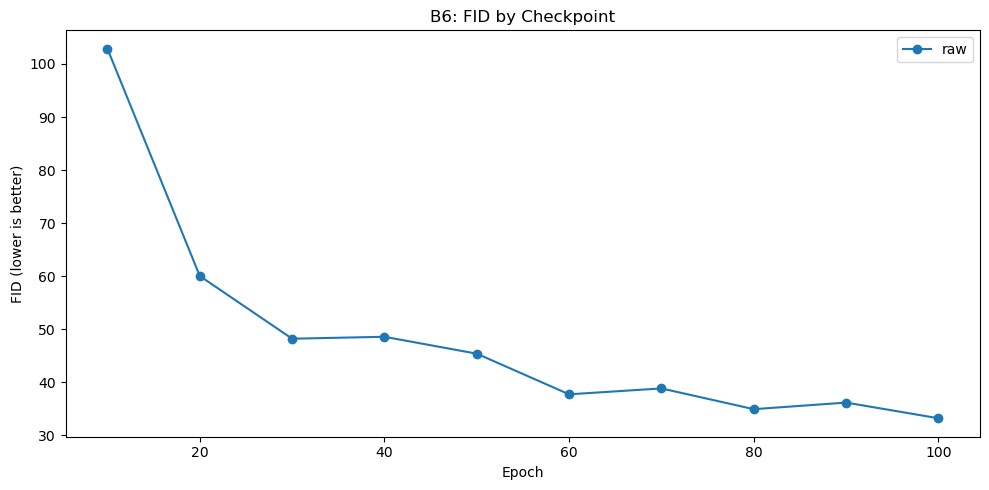

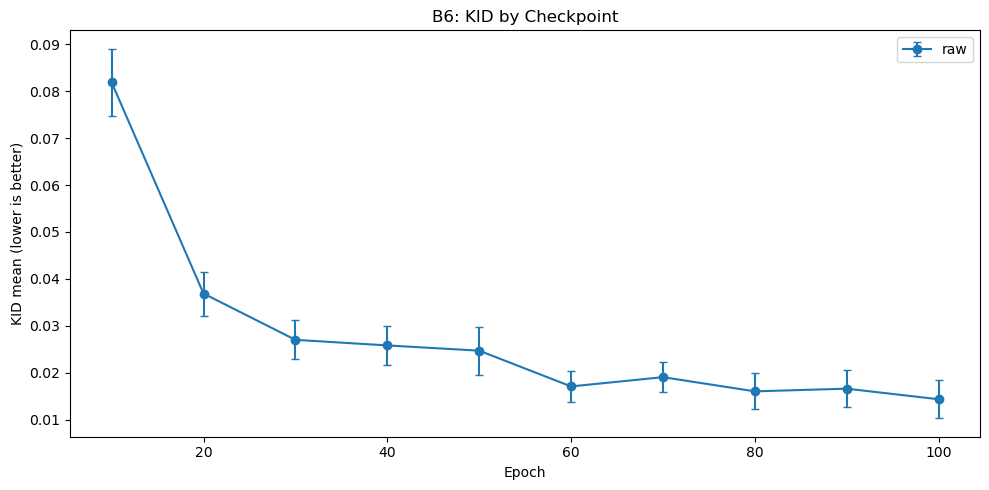

Saved checkpoint metrics: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B6_minibatch_stddev_translation\checkpoint_evaluation\fid_kid_by_checkpoint.csv
No checkpoint was selected automatically. Review the table, plots and saved class grids together.


In [53]:
B6_CHECKPOINT_METRICS = evaluate_checkpoint_directory(
    experiment_name="B6",
    run_name="B6_minibatch_stddev_translation",
    candidates=("raw",),
    expected_epochs=range(10, 101, 10),
)


### B6 Manual Review

- **Chosen B6 epoch:** 100
- **FID:** 33.2279
- **KID mean ± standard deviation:** 0.014358 ± 0.004044
- **Decision:** Retained as the strongest B6 checkpoint, but not selected over
  B4 because its primary FID score was higher.

### Checkpoint Selection

Epoch 100 was selected manually because it achieved the lowest FID among all
evaluated B6 checkpoints. FID decreased substantially from 102.8620 at epoch 10
to 33.2279 at epoch 100.

The improvement was not completely continuous. FID increased slightly at
epochs 40, 70 and 90, showing the expected variation of adversarial training.
However, the overall trend continued downward, and epoch 100 produced the best
B6 FID result.

KID was used as supporting evidence. Epoch 100 also achieved the lowest B6 KID
mean of 0.014358. The KID uncertainty overlaps with several nearby checkpoints,
so KID alone does not establish that epoch 100 is substantially better than all
late checkpoints. Nevertheless, it supports rather than contradicts the
FID-based selection.

### Comparison with B3

B6 reduced FID by approximately 0.9668 points compared with B3. However, its
KID mean was approximately 0.000077 higher. The difference in KID is extremely
small relative to the reported standard deviations, so it does not provide
strong evidence that either model is clearly better according to KID.

Using FID as the primary metric, B6 produced a modest improvement over B3.
This suggests that the minibatch standard-deviation feature may have provided
some benefit by encouraging the discriminator to consider diversity across
generated samples.

### Comparison with the Overall Leading Model

B6 had an FID approximately 2.5128 points higher than B4 and also had a higher
KID mean. Therefore, although B6 improved upon B3 according to the primary FID
metric, it did not outperform the later continuation strategy used in B4.

### Visual Verification

The epoch-100 fixed-input class grid was inspected only as a verification step.
The inspection checked for severe mode collapse, repeated outputs, major
artefacts and complete loss of requested-class structure.

The visual outputs did not show an obvious failure that contradicted the FID
and KID results. Visual inspection therefore supported the quantitative
selection but was not used as the main reason for choosing epoch 100.

### Minibatch Standard-Deviation Conclusion

The minibatch standard-deviation experiment was partially successful. It
produced a lower FID than B3 while maintaining stable adversarial training,
suggesting that batch-level diversity information provided some benefit.

However, the improvement was smaller than the gains achieved by continuing B3
with EMA tracking and late TTUR in B4. B6 was therefore retained as useful
experimental evidence but was not selected as the overall final model.

- **Visual label counts:** Not completed for B6 because the full
  `clear / marginal / nonsense` assessment was reserved for the strongest final
  shortlisted candidates.
- **Requested-class match observations:** General conditional consistency was
  checked using the fixed-input grid, while detailed requested-class matching
  was reserved for the final visual-labelling stage.

## 9. Final Manual Evaluation and Comparison


The final decision uses multiple forms of evidence:

1. **FID — primary metric:** compares real and generated feature distributions.
2. **KID — secondary metric:** checks whether the quantitative conclusion is
   consistent and reports sampling variation.
3. **Fixed-input visual grids:** inspect recognisability, diversity, artefacts and
   possible mode collapse using the same noise and labels.
4. **Manual labelling:** label 100 images as `clear`, `marginal` or `nonsense`,
   and record the visually recognised class.

A lower FID alone does not prove that class conditioning works or that diversity
is acceptable. The final model is selected manually after all evidence is
reviewed.


In [54]:
EXPERIMENT_RUNS = {
    "B0": "B0_baseline",
    "B1": "B1_lower_discriminator_lr",
    "B2": "B2_horizontal_flip",
    "B3": "B3_translation_2px",
    "B4": "B4_B3_EMA_TTUR",
    "B5": "B5_B3_EMA_TTUR_mild_colour",
    "B6": "B6_minibatch_stddev_translation",
}

all_checkpoint_tables = []

for experiment_name, run_name in EXPERIMENT_RUNS.items():
    metric_path = (
        OUTPUT_ROOT
        / run_name
        / "checkpoint_evaluation"
        / "fid_kid_by_checkpoint.csv"
    )

    if metric_path.exists():
        table = pd.read_csv(metric_path)
        all_checkpoint_tables.append(table)
        print(experiment_name, "loaded from", metric_path.resolve())
    else:
        print(experiment_name, "not evaluated yet:", metric_path.resolve())

if all_checkpoint_tables:
    all_checkpoint_metrics = pd.concat(
        all_checkpoint_tables,
        ignore_index=True,
    ).sort_values(["experiment", "candidate", "epoch"])

    combined_metric_path = (
        EVALUATION_ROOT / "all_checkpoint_metrics.csv"
    )
    all_checkpoint_metrics.to_csv(combined_metric_path, index=False)

    display(all_checkpoint_metrics.style.format({
        "fid": "{:.4f}",
        "kid_mean": "{:.6f}",
        "kid_std": "{:.6f}",
    }))
    print("Combined checkpoint table:", combined_metric_path.resolve())
else:
    print("No manual checkpoint-evaluation CSV files are available yet.")


B0 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B0_baseline\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B1 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B1_lower_discriminator_lr\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B2 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B2_horizontal_flip\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B3 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B3_translation_2px\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B4 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B4_B3_EMA_TTUR\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B5 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B5_B3_EMA_TTUR_mild_colour\checkpoint_evaluation\fid_kid_by_checkpoint.csv
B6 loaded from C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\B6_minibatch_stddev_translation\checkpoint_evaluation\fid_kid_by_checkpoint.csv


,experiment,run_name,epoch,candidate,fid,kid_mean,kid_std,generated_samples
0,B0,B0_baseline,10,raw,115.4572,0.093037,0.006093,5000
1,B0,B0_baseline,20,raw,65.8842,0.041301,0.004600,5000
2,B0,B0_baseline,30,raw,54.0379,0.029529,0.004619,5000
3,B0,B0_baseline,40,raw,54.2456,0.030553,0.003932,5000
4,B0,B0_baseline,50,raw,46.6291,0.022650,0.003794,5000
5,B0,B0_baseline,60,raw,43.8061,0.021033,0.003892,5000
6,B0,B0_baseline,70,raw,43.1193,0.020370,0.003706,5000
7,B0,B0_baseline,80,raw,41.6952,0.019938,0.004004,5000
8,B0,B0_baseline,90,raw,41.2569,0.019602,0.003938,5000
9,B0,B0_baseline,100,raw,40.6290,0.018764,0.003678,5000


Combined checkpoint table: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\all_checkpoint_metrics.csv


### 9.1 Manual 100-Image Visual Labelling


In [60]:
VISUAL_REVIEW_SAMPLES_PER_CLASS = 10
VISUAL_REVIEW_SAMPLE_COUNT = (
    NUM_CLASSES * VISUAL_REVIEW_SAMPLES_PER_CLASS
)

visual_review_labels = tf.convert_to_tensor(
    np.repeat(
        np.arange(NUM_CLASSES),
        VISUAL_REVIEW_SAMPLES_PER_CLASS,
    ).reshape(-1, 1),
    dtype=tf.int32,
)
visual_review_noise = tf.random.stateless_normal(
    (VISUAL_REVIEW_SAMPLE_COUNT, LATENT_DIM),
    seed=[SEED, 8080],
)


def create_manual_label_sheet(
    experiment,
    epoch,
    candidate,
    image_paths,
):
    """Create a blank sheet matching the 100 saved visual-review images."""

    rows = []

    for image_index, image_path in enumerate(image_paths):
        class_id = image_index // VISUAL_REVIEW_SAMPLES_PER_CLASS
        sample_index = image_index % VISUAL_REVIEW_SAMPLES_PER_CLASS
        rows.append({
            "experiment": str(experiment),
            "epoch": int(epoch),
            "candidate": str(candidate).lower(),
            "image_id": (
                f"{experiment}_{candidate}_{int(epoch):03d}_"
                f"{class_id:02d}_{sample_index:02d}"
            ),
            "image_path": str(image_path),
            "requested_class_id": int(class_id),
            "requested_class": CLASS_NAMES[class_id],
            "quality_label": "",
            "recognised_class": "",
            "notes": "",
        })

    return pd.DataFrame(rows)


def prepare_manual_visual_review(
    *,
    experiment_name,
    run_name,
    epoch,
    candidate="raw",
    overwrite=False,
):
    """Save a fixed 100-image review set, grid and blank labelling CSV."""

    review_directory = (
        MANUAL_EVALUATION_DIRECTORY
        / f"{experiment_name}_{candidate}_epoch_{int(epoch):03d}"
    )

    if review_directory.exists() and any(review_directory.iterdir()):
        if not overwrite:
            raise FileExistsError(
                "Review files already exist. Set overwrite=True only when "
                f"you intend to replace: {review_directory.resolve()}"
            )

    review_directory.mkdir(parents=True, exist_ok=True)
    image_directory = review_directory / "images"
    image_directory.mkdir(parents=True, exist_ok=True)

    generator = load_selected_generator(
        run_name=run_name,
        epoch=epoch,
        candidate=candidate,
    )
    generated = generator(
        [visual_review_noise, visual_review_labels],
        training=False,
    ).numpy()
    generated_uint8 = np.clip(
        (generated + 1.0) * 127.5,
        0.0,
        255.0,
    ).round().astype(np.uint8)

    image_paths = []

    for image_index, image in enumerate(generated_uint8):
        class_id = image_index // VISUAL_REVIEW_SAMPLES_PER_CLASS
        sample_index = image_index % VISUAL_REVIEW_SAMPLES_PER_CLASS
        class_directory = (
            image_directory
            / f"class_{class_id:02d}_{CLASS_NAMES[class_id]}"
        )
        class_directory.mkdir(parents=True, exist_ok=True)
        image_path = class_directory / f"sample_{sample_index:02d}.png"
        tf.keras.utils.save_img(str(image_path), image, scale=False)
        image_paths.append(image_path.resolve())

    # Save one class-balanced overview using the same image order as the CSV.
    fig, axes = plt.subplots(
        NUM_CLASSES,
        VISUAL_REVIEW_SAMPLES_PER_CLASS,
        figsize=(12, 12),
    )

    for class_id in range(NUM_CLASSES):
        for sample_index in range(VISUAL_REVIEW_SAMPLES_PER_CLASS):
            image_index = (
                class_id * VISUAL_REVIEW_SAMPLES_PER_CLASS + sample_index
            )
            axis = axes[class_id, sample_index]
            axis.imshow(generated_uint8[image_index])
            axis.axis("off")

            if sample_index == 0:
                axis.set_title(
                    CLASS_NAMES[class_id],
                    loc="left",
                    fontsize=9,
                    fontweight="bold",
                )

    fig.suptitle(
        f"{experiment_name} {candidate} — epoch {int(epoch)}",
        fontsize=15,
    )
    plt.tight_layout()
    grid_path = review_directory / "visual_review_grid.png"
    fig.savefig(grid_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    label_sheet = create_manual_label_sheet(
        experiment=experiment_name,
        epoch=epoch,
        candidate=candidate,
        image_paths=image_paths,
    )
    label_path = review_directory / "manual_labels.csv"
    label_sheet.to_csv(label_path, index=False)

    print("Saved review grid:", grid_path.resolve())
    print("Saved 100 review images:", image_directory.resolve())
    print("Complete this label sheet:", label_path.resolve())

    del generator, generated
    gc.collect()
    return label_sheet


def summarise_manual_labels(labelled_sheet):
    """Summarise completed visual labels without selecting a model."""

    labelled = labelled_sheet.copy()
    labelled["quality_label"] = (
        labelled["quality_label"].astype(str).str.strip().str.lower()
    )
    labelled["recognised_class"] = (
        labelled["recognised_class"].astype(str).str.strip().str.lower()
    )

    allowed_quality = {"clear", "marginal", "nonsense"}
    allowed_classes = set(CLASS_NAMES) | {"unclear"}

    if len(labelled) != VISUAL_REVIEW_SAMPLE_COUNT:
        raise ValueError(
            f"Expected {VISUAL_REVIEW_SAMPLE_COUNT} labelled rows."
        )

    if not set(labelled["quality_label"]).issubset(allowed_quality):
        raise ValueError(
            "Every quality_label must be clear, marginal or nonsense."
        )

    if not set(labelled["recognised_class"]).issubset(allowed_classes):
        raise ValueError(
            "Every recognised_class must be a CIFAR-10 class or unclear."
        )

    labelled["class_matches_request"] = (
        labelled["recognised_class"] == labelled["requested_class"]
    )

    quality_counts = (
        labelled["quality_label"]
        .value_counts()
        .reindex(["clear", "marginal", "nonsense"], fill_value=0)
    )

    overall = pd.DataFrame([{
        "total": int(len(labelled)),
        "clear": int(quality_counts["clear"]),
        "marginal": int(quality_counts["marginal"]),
        "nonsense": int(quality_counts["nonsense"]),
        "clear_rate": float((labelled["quality_label"] == "clear").mean()),
        "acceptable_rate": float(
            labelled["quality_label"].isin(["clear", "marginal"]).mean()
        ),
        "class_match_rate": float(labelled["class_matches_request"].mean()),
    }])

    per_class_rows = []

    for class_name in CLASS_NAMES:
        class_rows = labelled[labelled["requested_class"] == class_name]
        class_quality = (
            class_rows["quality_label"]
            .value_counts()
            .reindex(["clear", "marginal", "nonsense"], fill_value=0)
        )
        per_class_rows.append({
            "requested_class": class_name,
            "clear": int(class_quality["clear"]),
            "marginal": int(class_quality["marginal"]),
            "nonsense": int(class_quality["nonsense"]),
            "clear_rate": float(
                (class_rows["quality_label"] == "clear").mean()
            ),
            "acceptable_rate": float(
                class_rows["quality_label"]
                .isin(["clear", "marginal"])
                .mean()
            ),
            "class_match_rate": float(
                class_rows["class_matches_request"].mean()
            ),
        })

    per_class = (
        pd.DataFrame(per_class_rows)
        .sort_values(
            ["clear_rate", "class_match_rate"],
            ascending=False,
        )
        .reset_index(drop=True)
    )

    confusion = pd.crosstab(
        labelled["requested_class"],
        labelled["recognised_class"],
        dropna=False,
    ).reindex(index=CLASS_NAMES, fill_value=0)

    return overall, per_class, confusion


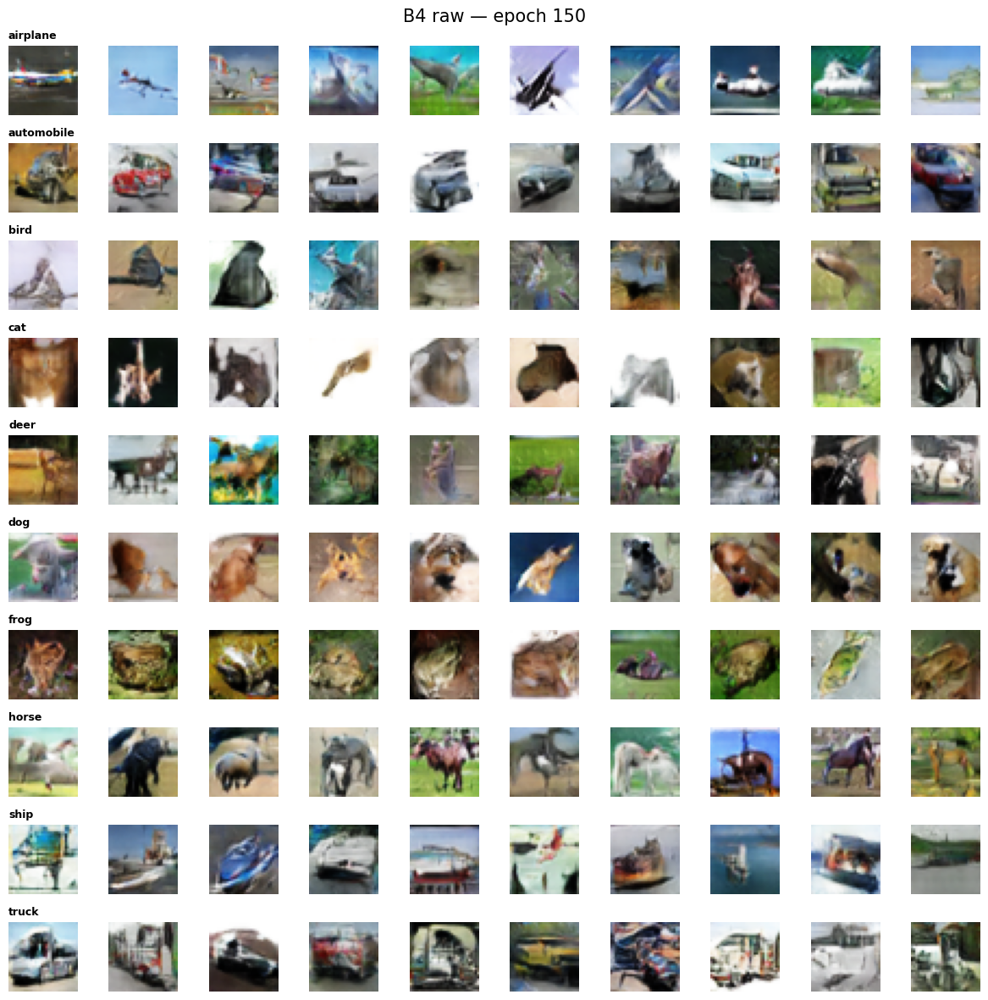

Saved review grid: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B4_raw_epoch_150\visual_review_grid.png
Saved 100 review images: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B4_raw_epoch_150\images
Complete this label sheet: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B4_raw_epoch_150\manual_labels.csv


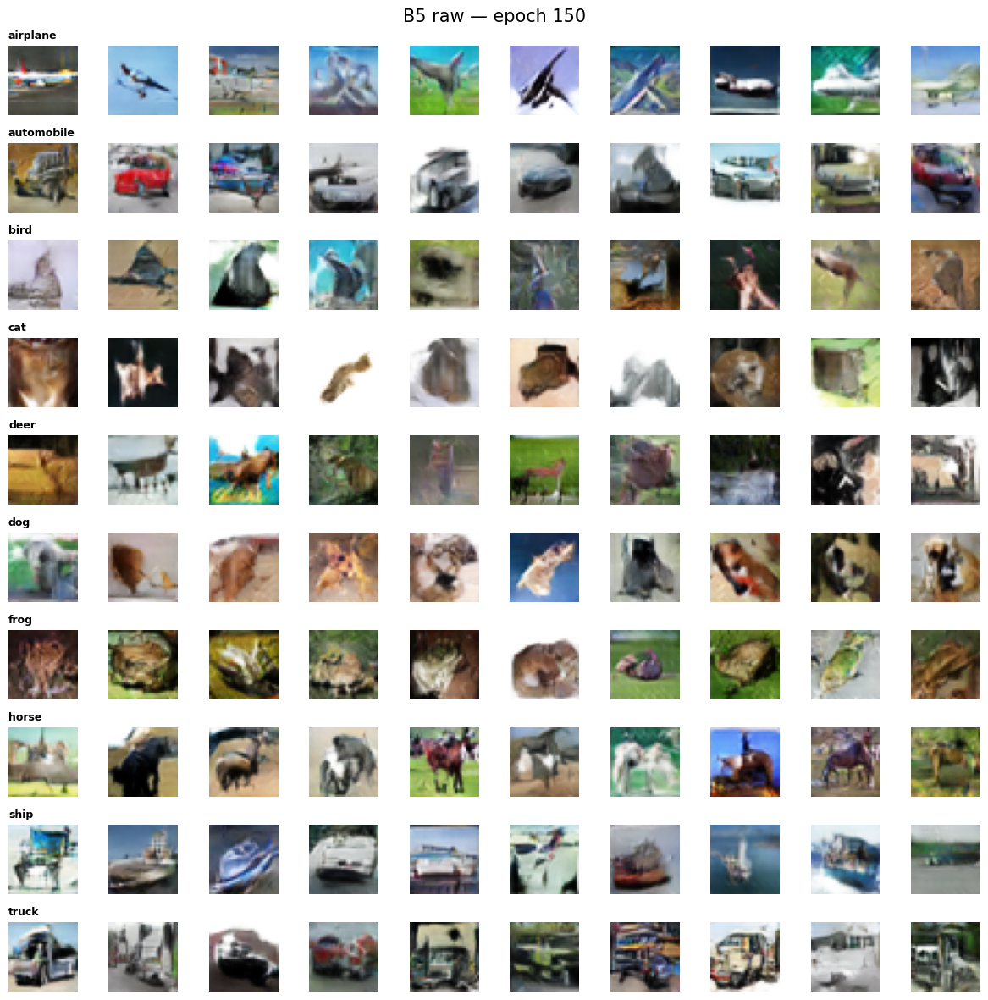

Saved review grid: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_raw_epoch_150\visual_review_grid.png
Saved 100 review images: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_raw_epoch_150\images
Complete this label sheet: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_raw_epoch_150\manual_labels.csv


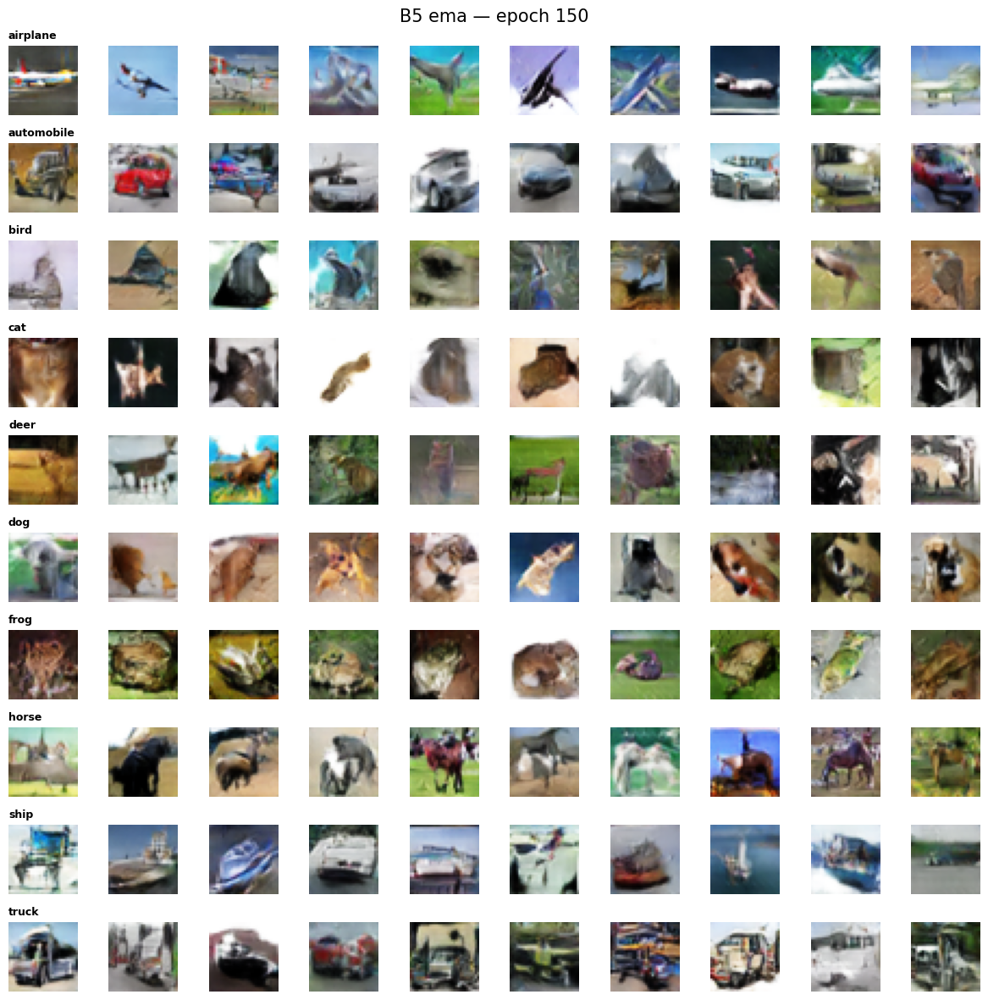

Saved review grid: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_ema_epoch_150\visual_review_grid.png
Saved 100 review images: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_ema_epoch_150\images
Complete this label sheet: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_ema_epoch_150\manual_labels.csv


In [61]:
b4_raw_label_sheet = prepare_manual_visual_review(
    experiment_name="B4",
    run_name="B4_B3_EMA_TTUR",
    epoch=150,
    candidate="raw",
)

b5_raw_label_sheet = prepare_manual_visual_review(
    experiment_name="B5",
    run_name="B5_B3_EMA_TTUR_mild_colour",
    epoch=150,
    candidate="raw",
)

b5_ema_label_sheet = prepare_manual_visual_review(
    experiment_name="B5",
    run_name="B5_B3_EMA_TTUR_mild_colour",
    epoch=150,
    candidate="ema",
)

In [65]:
PROJECT_DIRECTORY = Path.cwd()
ZIP_PATH = PROJECT_DIRECTORY / "completed_manual_labelling.zip"
EXTRACT_DIRECTORY = PROJECT_DIRECTORY / "completed_manual_labelling"

TARGET_DIRECTORY = (
    PROJECT_DIRECTORY
    / "HeinHtetPartA_outputs"
    / "manual_checkpoint_evaluation"
    / "visual_labelling"
)

CANDIDATES = [
    "B4_raw_epoch_150",
    "B5_raw_epoch_150",
    "B5_ema_epoch_150",
]


if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Upload this file beside the notebook first:\n{ZIP_PATH.resolve()}"
    )

with ZipFile(ZIP_PATH, "r") as zip_file:
    zip_file.extractall(EXTRACT_DIRECTORY)

for candidate in CANDIDATES:
    source_csv = (
        EXTRACT_DIRECTORY
        / candidate
        / "manual_labels.csv"
    )

    destination_csv = (
        TARGET_DIRECTORY
        / candidate
        / "manual_labels.csv"
    )

    if not source_csv.exists():
        raise FileNotFoundError(
            f"Completed CSV not found:\n{source_csv.resolve()}"
        )

    if not destination_csv.parent.exists():
        raise FileNotFoundError(
            f"Original review folder not found:\n"
            f"{destination_csv.parent.resolve()}"
        )

    shutil.copy2(source_csv, destination_csv)
    print("Installed completed labels:", destination_csv.resolve())

print("\nAll completed manual labels were installed.")

Installed completed labels: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B4_raw_epoch_150\manual_labels.csv
Installed completed labels: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_raw_epoch_150\manual_labels.csv
Installed completed labels: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\B5_ema_epoch_150\manual_labels.csv

All completed manual labels were installed.


In [66]:
candidate_details = {
    "B4 raw epoch 150": "B4_raw_epoch_150",
    "B5 raw epoch 150": "B5_raw_epoch_150",
    "B5 EMA epoch 150": "B5_ema_epoch_150",
}

manual_results = {}

for display_name, folder_name in candidate_details.items():
    labels_path = (
        TARGET_DIRECTORY
        / folder_name
        / "manual_labels.csv"
    )

    completed_labels = pd.read_csv(labels_path)

    overall, per_class, confusion = summarise_manual_labels(
        completed_labels
    )

    manual_results[display_name] = {
        "overall": overall,
        "per_class": per_class,
        "confusion": confusion,
    }

    print("=" * 70)
    print(display_name)
    print("=" * 70)

    display(overall)
    display(per_class)
    display(confusion)

B4 raw epoch 150


,total,clear,marginal,nonsense,clear_rate,acceptable_rate,class_match_rate
0,100,48,45,7,0.48,0.93,0.87


,requested_class,clear,marginal,nonsense,clear_rate,acceptable_rate,class_match_rate
0,frog,7,3,0,0.7,1.0,0.9
1,airplane,6,4,0,0.6,1.0,1.0
2,ship,6,4,0,0.6,1.0,0.9
3,dog,5,5,0,0.5,1.0,1.0
4,automobile,5,4,1,0.5,0.9,0.9
5,horse,5,5,0,0.5,1.0,0.9
6,truck,5,5,0,0.5,1.0,0.9
7,deer,4,4,2,0.4,0.8,0.8
8,cat,3,4,3,0.3,0.7,0.5
9,bird,2,7,1,0.2,0.9,0.9


recognised_class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck,unclear
requested_class,,,,,,,,,,,
airplane,10,0,0,0,0,0,0,0,0,0,0
automobile,0,9,0,0,0,0,0,0,0,0,1
bird,0,0,9,0,0,0,0,0,0,0,1
cat,0,0,0,5,0,2,0,0,0,0,3
deer,0,0,0,0,8,0,0,0,0,0,2
dog,0,0,0,0,0,10,0,0,0,0,0
frog,0,0,0,0,0,0,9,0,0,0,1
horse,0,0,0,0,0,0,0,9,0,0,1
ship,1,0,0,0,0,0,0,0,9,0,0


B5 raw epoch 150


,total,clear,marginal,nonsense,clear_rate,acceptable_rate,class_match_rate
0,100,48,45,7,0.48,0.93,0.87


... (2 outputs left out)

B5 EMA epoch 150


,total,clear,marginal,nonsense,clear_rate,acceptable_rate,class_match_rate
0,100,48,45,7,0.48,0.93,0.87


,requested_class,clear,marginal,nonsense,clear_rate,acceptable_rate,class_match_rate
0,frog,7,3,0,0.7,1.0,0.9
1,airplane,6,4,0,0.6,1.0,1.0
2,ship,6,4,0,0.6,1.0,0.9
3,dog,5,5,0,0.5,1.0,1.0
4,automobile,5,4,1,0.5,0.9,0.9
5,horse,5,5,0,0.5,1.0,0.9
6,truck,5,5,0,0.5,1.0,0.9
7,deer,4,4,2,0.4,0.8,0.8
8,cat,3,4,3,0.3,0.7,0.5
9,bird,2,7,1,0.2,0.9,0.9


recognised_class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck,unclear
requested_class,,,,,,,,,,,
airplane,10,0,0,0,0,0,0,0,0,0,0
automobile,0,9,0,0,0,0,0,0,0,0,1
bird,0,0,9,0,0,0,0,0,0,0,1
cat,0,0,0,5,0,2,0,0,0,0,3
deer,0,0,0,0,8,0,0,0,0,0,2
dog,0,0,0,0,0,10,0,0,0,0,0
frog,0,0,0,0,0,0,9,0,0,0,1
horse,0,0,0,0,0,0,0,9,0,0,1
ship,1,0,0,0,0,0,0,0,9,0,0


### 9.2 Final Comparison Table


In [72]:
# FID is the primary model-selection metric.
# KID is supporting evidence.
# Detailed 100-image visual labelling was completed only for the final
# shortlisted candidate B4 Raw

manual_comparison = pd.DataFrame([
    {
        "experiment": "B0",
        "main_change": "Non-augmented conditional DCGAN baseline",
        "selected_epoch": 100,
        "candidate": "raw",
        "fid": 40.6290,
        "kid_mean": 0.018764,
        "kid_std": 0.003678,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": "",
        "harder_classes": "",
        "diversity_notes": (
            "Fixed-input grid was checked for general variation. "
            "No formal 100-image labelling was completed."
        ),
        "artefact_notes": (
            "Blurred boundaries and ambiguous animal classes were visible."
        ),
        "decision": (
            "Retained as the baseline reference. Epoch 100 had the lowest "
            "B0 FID, supported by the lowest B0 KID."
        ),
    },
    {
        "experiment": "B1",
        "main_change": "Lower discriminator learning rate",
        "selected_epoch": 100,
        "candidate": "raw",
        "fid": 38.4121,
        "kid_mean": 0.017763,
        "kid_std": 0.004000,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": "",
        "harder_classes": "",
        "diversity_notes": (
            "Fixed-input grid showed varied outputs without obvious severe "
            "mode collapse. No formal 100-image labelling was completed."
        ),
        "artefact_notes": (
            "Some blurry objects and animal-class ambiguity remained."
        ),
        "decision": (
            "Successful modest improvement over B0 because both FID and "
            "KID decreased."
        ),
    },
    {
        "experiment": "B2",
        "main_change": "Random horizontal flipping",
        "selected_epoch": 100,
        "candidate": "raw",
        "fid": 37.3169,
        "kid_mean": 0.017210,
        "kid_std": 0.003439,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": "",
        "harder_classes": "",
        "diversity_notes": (
            "The fixed-input grid retained varied object orientations and "
            "did not show obvious severe mode collapse."
        ),
        "artefact_notes": (
            "Blur and conditional ambiguity remained, particularly for "
            "visually similar animal classes."
        ),
        "decision": (
            "Successful augmentation experiment. It improved FID and KID "
            "over both B0 and B1."
        ),
    },
    {
        "experiment": "B3",
        "main_change": "Random translation of up to two pixels",
        "selected_epoch": 100,
        "candidate": "raw",
        "fid": 34.1947,
        "kid_mean": 0.014281,
        "kid_std": 0.003679,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": "",
        "harder_classes": "",
        "diversity_notes": (
            "The class-balanced grid showed varied positions, shapes and "
            "backgrounds without obvious severe repetition."
        ),
        "artefact_notes": (
            "Animal categories remained less distinct than vehicle "
            "categories at 32 × 32 resolution."
        ),
        "decision": (
            "Strongest initial 100-epoch experiment. It became the reference "
            "checkpoint for the B4 and B5 continuation experiments."
        ),
    },
    {
        "experiment": "B4",
        "main_change": "B3 continuation with EMA tracking and late TTUR",
        "selected_epoch": 150,
        "candidate": "raw",
        "fid": 30.7151,
        "kid_mean": 0.012351,
        "kid_std": 0.003612,
        "clear_count": 48,
        "marginal_count": 45,
        "nonsense_count": 7,
        "acceptable_rate": 0.93,
        "class_match_rate": 0.87,
        "easier_classes": (
            "airplane, dog, frog, horse, ship, truck"
        ),
        "harder_classes": (
            "cat and deer; cat was the most difficult class"
        ),
        "diversity_notes": (
            "Generated images showed varied shapes, poses, colours and "
            "backgrounds. No obvious severe mode collapse was observed."
        ),
        "artefact_notes": (
            "The main limitations were blur, distorted object boundaries "
            "and confusion between visually similar animal classes. Cat "
            "images were sometimes recognised as dogs or remained unclear."
        ),
        "decision": (
            "Selected as the final model because it achieved the lowest FID. "
            "Its KID was also competitive, and visual inspection did not "
            "contradict the quantitative result."
        ),
    },
    {
        "experiment": "B5",
        "main_change": (
            "B3 continuation with EMA, late TTUR and mild colour augmentation"
        ),
        "selected_epoch": 150,
        "candidate": "raw",
        "fid": 30.9592,
        "kid_mean": 0.012101,
        "kid_std": 0.003787,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": (
            "None"
        ),
        "harder_classes": (
            "None"
        ),
        "diversity_notes": (
            "Generated images showed varied shapes, poses, colours and "
            "backgrounds. No obvious severe mode collapse was observed."
        ),
        "artefact_notes": (
            "Blur and animal-class confusion remained. Mild colour "
            "Augmentation did not introduce an obvious severe colour failure."
        ),
        "decision": (
            "Retained as a strong finalist and achieved the lowest KID mean, "
            "but was not selected because its primary FID was slightly higher "
            "than B4 and its manual visual results were tied with B4."
        ),
    },
    {
        "experiment": "B6",
        "main_change": "Minibatch standard-deviation discriminator feature",
        "selected_epoch": 100,
        "candidate": "raw",
        "fid": 33.2279,
        "kid_mean": 0.014358,
        "kid_std": 0.004044,
        "clear_count": None,
        "marginal_count": None,
        "nonsense_count": None,
        "acceptable_rate": None,
        "class_match_rate": None,
        "easier_classes": "",
        "harder_classes": "",
        "diversity_notes": (
            "The fixed-input grid showed varied generated outputs without "
            "obvious severe mode collapse."
        ),
        "artefact_notes": (
            "Blur and ambiguity remained for several animal categories."
        ),
        "decision": (
            "Partially successful because it improved FID over B3, but it "
            "did not outperform the B4 or B5 continuation strategies."
        ),
    },
])


MANUAL_EVALUATION_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

MANUAL_COMPARISON_PATH = (
    MANUAL_EVALUATION_DIRECTORY
    / "final_manual_comparison.csv"
)

manual_comparison.to_csv(
    MANUAL_COMPARISON_PATH,
    index=False,
)


display(
    manual_comparison.style.format({
        "fid": lambda value: (
            f"{value:.4f}"
            if pd.notna(value)
            else ""
        ),
        "kid_mean": lambda value: (
            f"{value:.6f}"
            if pd.notna(value)
            else ""
        ),
        "kid_std": lambda value: (
            f"{value:.6f}"
            if pd.notna(value)
            else ""
        ),
        "acceptable_rate": lambda value: (
            f"{value:.0%}"
            if pd.notna(value)
            else ""
        ),
        "class_match_rate": lambda value: (
            f"{value:.0%}"
            if pd.notna(value)
            else ""
        ),
    })
)

print(
    "Saved completed manual comparison table:",
    MANUAL_COMPARISON_PATH.resolve(),
)
display(manual_comparison)

# After entering all results, save the completed evidence table with:
# manual_comparison.to_csv(MANUAL_COMPARISON_PATH, index=False)


,experiment,main_change,selected_epoch,candidate,fid,kid_mean,kid_std,clear_count,marginal_count,nonsense_count,acceptable_rate,class_match_rate,easier_classes,harder_classes,diversity_notes,artefact_notes,decision
0,B0,Non-augmented conditional DCGAN baseline,100,raw,40.6290,0.018764,0.003678,nan,nan,nan,,,,,Fixed-input grid was checked for general variation. No formal 100-image labelling was completed.,Blurred boundaries and ambiguous animal classes were visible.,"Retained as the baseline reference. Epoch 100 had the lowest B0 FID, supported by the lowest B0 KID."
1,B1,Lower discriminator learning rate,100,raw,38.4121,0.017763,0.004000,nan,nan,nan,,,,,Fixed-input grid showed varied outputs without obvious severe mode collapse. No formal 100-image labelling was completed.,Some blurry objects and animal-class ambiguity remained.,Successful modest improvement over B0 because both FID and KID decreased.
2,B2,Random horizontal flipping,100,raw,37.3169,0.017210,0.003439,nan,nan,nan,,,,,The fixed-input grid retained varied object orientations and did not show obvious severe mode collapse.,"Blur and conditional ambiguity remained, particularly for visually similar animal classes.",Successful augmentation experiment. It improved FID and KID over both B0 and B1.
3,B3,Random translation of up to two pixels,100,raw,34.1947,0.014281,0.003679,nan,nan,nan,,,,,"The class-balanced grid showed varied positions, shapes and backgrounds without obvious severe repetition.",Animal categories remained less distinct than vehicle categories at 32 × 32 resolution.,Strongest initial 100-epoch experiment. It became the reference checkpoint for the B4 and B5 continuation experiments.
4,B4,B3 continuation with EMA tracking and late TTUR,150,raw,30.7151,0.012351,0.003612,48.000000,45.000000,7.000000,93%,87%,"airplane, dog, frog, horse, ship, truck",cat and deer; cat was the most difficult class,"Generated images showed varied shapes, poses, colours and backgrounds. No obvious severe mode collapse was observed.","The main limitations were blur, distorted object boundaries and confusion between visually similar animal classes. Cat images were sometimes recognised as dogs or remained unclear.","Selected as the final model because it achieved the lowest FID. Its KID was also competitive, and visual inspection did not contradict the quantitative result."
5,B5,"B3 continuation with EMA, late TTUR and mild colour augmentation",150,raw,30.9592,0.012101,0.003787,nan,nan,nan,,,None,None,"Generated images showed varied shapes, poses, colours and backgrounds. No obvious severe mode collapse was observed.",Blur and animal-class confusion remained. Mild colour Augmentation did not introduce an obvious severe colour failure.,"Retained as a strong finalist and achieved the lowest KID mean, but was not selected because its primary FID was slightly higher than B4 and its manual visual results were tied with B4."
6,B6,Minibatch standard-deviation discriminator feature,100,raw,33.2279,0.014358,0.004044,nan,nan,nan,,,,,The fixed-input grid showed varied generated outputs without obvious severe mode collapse.,Blur and ambiguity remained for several animal categories.,"Partially successful because it improved FID over B3, but it did not outperform the B4 or B5 continuation strategies."


Saved completed manual comparison table: C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\manual_checkpoint_evaluation\visual_labelling\final_manual_comparison.csv


,experiment,main_change,selected_epoch,candidate,fid,kid_mean,kid_std,clear_count,marginal_count,nonsense_count,acceptable_rate,class_match_rate,easier_classes,harder_classes,diversity_notes,artefact_notes,decision
0,B0,Non-augmented conditional DCGAN baseline,100,raw,40.6290,0.018764,0.003678,NaN,NaN,NaN,NaN,NaN,,,Fixed-input grid was checked for general varia...,Blurred boundaries and ambiguous animal classe...,Retained as the baseline reference. Epoch 100 ...
1,B1,Lower discriminator learning rate,100,raw,38.4121,0.017763,0.004000,NaN,NaN,NaN,NaN,NaN,,,Fixed-input grid showed varied outputs without...,Some blurry objects and animal-class ambiguity...,Successful modest improvement over B0 because ...
2,B2,Random horizontal flipping,100,raw,37.3169,0.017210,0.003439,NaN,NaN,NaN,NaN,NaN,,,The fixed-input grid retained varied object or...,"Blur and conditional ambiguity remained, parti...",Successful augmentation experiment. It improve...
3,B3,Random translation of up to two pixels,100,raw,34.1947,0.014281,0.003679,NaN,NaN,NaN,NaN,NaN,,,The class-balanced grid showed varied position...,Animal categories remained less distinct than ...,Strongest initial 100-epoch experiment. It bec...
4,B4,B3 continuation with EMA tracking and late TTUR,150,raw,30.7151,0.012351,0.003612,48.0,45.0,7.0,0.93,0.87,"airplane, dog, frog, horse, ship, truck",cat and deer; cat was the most difficult class,"Generated images showed varied shapes, poses, ...","The main limitations were blur, distorted obje...",Selected as the final model because it achieve...
5,B5,"B3 continuation with EMA, late TTUR and mild c...",150,raw,30.9592,0.012101,0.003787,NaN,NaN,NaN,NaN,NaN,None,None,"Generated images showed varied shapes, poses, ...",Blur and animal-class confusion remained. Mild...,Retained as a strong finalist and achieved the...
6,B6,Minibatch standard-deviation discriminator fea...,100,raw,33.2279,0.014358,0.004044,NaN,NaN,NaN,NaN,NaN,,,The fixed-input grid showed varied generated o...,Blur and ambiguity remained for several animal...,Partially successful because it improved FID o...


### 9.3 Final Model Decision

The final model was selected using FID as the primary quantitative metric,
with KID used as supporting evidence. The detailed 100-image visual assessment
was used to verify that the quantitative result was not associated with mode
collapse, severe artefacts or loss of conditional class control.

- **Selected experiment:** B4 — B3 continuation with EMA tracking and late TTUR
- **Selected epoch:** 150
- **Selected candidate:** Raw generator
- **FID:** 30.7151
- **KID mean ± standard deviation:** 0.012351 ± 0.003612
- **Clear / marginal / nonsense:** 48 / 45 / 7
- **Acceptable-image rate:** 93%
- **Requested-class match rate:** 87%

#### Quantitative Decision

B4 raw at epoch 150 achieved the lowest FID among all evaluated experiments and
checkpoints. Its FID of 30.7151 improved upon B3 raw at epoch 100, which achieved
an FID of 34.1947. This represents an improvement of approximately 3.4796 FID
points after continuing the B3 model with EMA tracking and late TTUR.

B5 raw at epoch 150 achieved a slightly lower KID mean of 0.012101, compared
with 0.012351 for B4 raw. However, B5's FID was slightly higher at 30.9592.
Because FID was defined as the primary model-selection metric, B5's small KID
advantage was not sufficient to override B4's lower FID. The KID standard
deviation ranges also overlapped considerably, indicating that the difference
between their KID means should not be interpreted as conclusive.


#### EMA Assessment

EMA produced competitive results but did not provide a clear advantage in this
experiment. B4 EMA at epoch 150 achieved an FID of 31.1634, which was worse than
the raw B4 result of 30.7151. B5 EMA also achieved a slightly worse FID than B5
raw at epoch 150.

The fixed-input grids for B5 raw and B5 EMA were compared qualitatively using
the same latent vectors and class labels. Neither candidate showed a sufficiently
clear visual advantage to override the quantitative result. A formal 100-image
clear/marginal/nonsense assessment was reserved for the selected B4 raw model.

#### Why the Other Candidates Were Rejected

- **B0** was retained only as the baseline because it had a substantially higher
  FID of 40.6290.
- **B1** improved upon B0, but its FID of 38.4121 remained weaker than the later
  augmentation experiments.
- **B2** showed that horizontal flipping was useful, but its FID of 37.3169 was
  higher than B3, B4 and B5.
- **B3** was a strong model and provided the starting checkpoint for B4 and B5,
  but its FID of 34.1947 was improved by both continuation experiments.
- **B5** achieved the lowest KID mean but had a slightly higher primary FID than
  B4. Its fixed-input grids did not show a sufficiently clear visual advantage
  to override the FID-based decision.
- **B6** improved slightly upon B3 according to FID but did not outperform the
  continuation strategies used in B4 and B5.

#### Final Justification

B4 raw at epoch 150 was selected because it achieved the strongest primary
quantitative result, remained competitive according to KID, and passed the
visual verification without evidence of severe mode collapse or unacceptable
artefacts. It also avoided the additional mild-colour augmentation used by B5,
making it the simpler of the two visually tied final candidates.

## 10. Analysis of the Assignment Questions


### 10.1 Would Black-and-White Generation Be Easier or Harder?

It would **probably be easier to produce visually clean structure** because a
one-channel grayscale model predicts 1,024 values per image instead of 3,072 RGB
values. It does not need to learn three-channel colour correlations, realistic
colour boundaries or colour balance, so more capacity can focus on silhouette,
edge, brightness and texture.

The trade-off is that colour is also a useful semantic cue in low-resolution
CIFAR-10. Blue sky/water, green vegetation, fur colour and vehicle/background
contrast can help distinguish classes. A grayscale image may therefore look
sharper while being harder to identify correctly.

**Answer:** grayscale is likely easier at the pixel-modelling level and may
produce cleaner-looking outputs, but it is not guaranteed to improve class
recognisability. A conclusive claim would require a separate one-channel model
trained and evaluated with the same FID/KID and manual-labelling protocol.


### 10.2 Which Classes Are Relatively Easier or Harder?

The relative difficulty of each class was assessed using the 100-image manual
evaluation of the selected B4 raw epoch-150 generator. Ten images were reviewed
for each CIFAR-10 class.

| Requested class | Clear | Marginal | Nonsense | Acceptable rate | Class-match rate |
|---|---:|---:|---:|---:|---:|
| airplane | 6 | 4 | 0 | 100% | 100% |
| automobile | 5 | 4 | 1 | 90% | 90% |
| bird | 2 | 7 | 1 | 90% | 90% |
| cat | 3 | 4 | 3 | 70% | 50% |
| deer | 4 | 4 | 2 | 80% | 80% |
| dog | 5 | 5 | 0 | 100% | 100% |
| frog | 7 | 3 | 0 | 100% | 90% |
| horse | 5 | 5 | 0 | 100% | 90% |
| ship | 6 | 4 | 0 | 100% | 90% |
| truck | 5 | 5 | 0 | 100% | 90% |

#### Relatively Easier Classes

Airplane and dog were the strongest classes because both achieved a 100%
acceptable-image rate and a 100% requested-class match rate.

Frog, horse, ship and truck also performed strongly. Each achieved a 100%
acceptable-image rate and a 90% class-match rate. These classes generally
produced recognisable global structures even when finer details remained
blurred.

Airplanes, ships and trucks benefit from relatively distinctive silhouettes and
recurring contextual features such as sky, water or road-like backgrounds.
Frogs and dogs also performed well in the reviewed sample, although many of
their outputs were classified as marginal rather than fully clear.

#### Relatively Harder Classes

Cat was the most difficult class. It achieved only a 70% acceptable-image rate
and a 50% requested-class match rate. Several requested cat images were unclear
or visually resembled dogs. This is likely caused by overlapping animal body
shapes, fur textures and poses at the low `32 × 32` resolution.

Deer was the second weakest class, with an 80% acceptable-image rate and an 80%
class-match rate. Deer images often contained natural colours and backgrounds
that blended with the object, making the silhouette less distinct.

Bird achieved a relatively high 90% acceptable and class-match rate, but only
2 of its 10 images were labelled clear. Most bird images were marginal,
indicating that the requested class was often identifiable while fine shape and
texture details remained weak.

#### Final Class-Difficulty Conclusion

The results only partially supported the preliminary expectation that vehicle
classes would always be easier than animal classes. Airplane, ship and truck
were strong, but dog and frog also performed well. The most important source of
difficulty was not simply whether a class represented an animal or vehicle.
Difficulty was influenced by silhouette consistency, similarity to other
classes, pose variation, background complexity and the limited spatial detail
available at `32 × 32` resolution.

Therefore, the relatively easiest classes were airplane and dog, followed by
frog, horse, ship and truck. Cat was the hardest class, followed by deer, while
bird images were often recognisable but visually unclear.


### 10.3 Generating a Specific Requested Class

The conditional generator receives a random latent vector and an integer class
label. The label chooses the requested CIFAR-10 category, while different latent
vectors create variation within that category. For example, class ID `8`
requests a ship and class ID `9` requests a truck. This is more direct and
verifiable than generating an unconditional mixture and sorting it afterward.


## 11. Manual Final-Model Loading and Export


In [58]:
def generate_requested_class(
    generator,
    *,
    class_id,
    number_of_images=16,
    seed=2026,
):
    """Generate several images from one explicitly requested class."""

    class_id = int(class_id)
    if class_id < 0 or class_id >= NUM_CLASSES:
        raise ValueError("class_id must be between 0 and 9.")

    noise = tf.random.stateless_normal(
        (number_of_images, LATENT_DIM),
        seed=[SEED, int(seed)],
    )
    labels = tf.fill(
        (number_of_images, 1),
        tf.cast(class_id, tf.int32),
    )
    images = generator([noise, labels], training=False).numpy()
    return denormalise_gan_images(images)


#### ONLY RUN ONCE IT'S FOR GENERATING FINAL 1000 small images

FINAL_SELECTION_CONFIRMED = True

FINAL_RUN_NAME = "B4_B3_EMA_TTUR"
FINAL_EPOCH = 150
FINAL_CANDIDATE = "raw"

if FINAL_SELECTION_CONFIRMED:
    if not FINAL_RUN_NAME or FINAL_EPOCH is None or not FINAL_CANDIDATE:
        raise ValueError(
            "Fill FINAL_RUN_NAME, FINAL_EPOCH and FINAL_CANDIDATE first."
        )

    final_generator = load_selected_generator(
        run_name=FINAL_RUN_NAME,
        epoch=FINAL_EPOCH,
        candidate=FINAL_CANDIDATE,
    )

    final_directory = OUTPUT_ROOT / "final_selected_model"
    image_directory = final_directory / "generated_1000_png"
    final_directory.mkdir(parents=True, exist_ok=True)
    image_directory.mkdir(parents=True, exist_ok=True)

    weights_path = (
        final_directory / "best_conditional_gan_generator.weights.h5"
    )
    final_generator.save_weights(str(weights_path))

    # Generate exactly 100 images for each of the ten classes.
    final_labels = tf.reshape(
        tf.repeat(tf.range(NUM_CLASSES, dtype=tf.int32), repeats=100),
        (-1, 1),
    )
    final_noise = tf.random.stateless_normal(
        (1000, LATENT_DIM),
        seed=[SEED, 999],
    )

    generated_batches = []
    for start in range(0, 1000, 100):
        end = start + 100
        generated_batches.append(
            final_generator(
                [final_noise[start:end], final_labels[start:end]],
                training=False,
            ).numpy()
        )

    final_images = np.concatenate(generated_batches, axis=0)
    final_images_uint8 = np.clip(
        (final_images + 1.0) * 127.5,
        0.0,
        255.0,
    ).round().astype(np.uint8)
    label_array = final_labels.numpy().reshape(-1)

    assert final_images_uint8.shape == (1000, 32, 32, 3)
    assert np.all(np.bincount(label_array, minlength=NUM_CLASSES) == 100)

    # Exact hashes verify that no two submitted PNG arrays are identical.
    image_hashes = [
        hashlib.sha256(np.ascontiguousarray(image).tobytes()).hexdigest()
        for image in final_images_uint8
    ]
    if len(set(image_hashes)) != 1000:
        raise RuntimeError(
            "The final set contains exact duplicate images. Change the final "
            "generation seed and regenerate before submission."
        )

    class_counters = {class_id: 0 for class_id in range(NUM_CLASSES)}

    for image, class_id in zip(final_images_uint8, label_array):
        class_id = int(class_id)
        class_folder = (
            image_directory
            / f"class_{class_id:02d}_{CLASS_NAMES[class_id]}"
        )
        class_folder.mkdir(parents=True, exist_ok=True)

        class_index = class_counters[class_id]
        class_counters[class_id] += 1
        image_path = (
            class_folder
            / f"{CLASS_NAMES[class_id]}_{class_index:03d}.png"
        )
        tf.keras.utils.save_img(str(image_path), image, scale=False)

    np.savez_compressed(
        final_directory / "final_1000_generated_images.npz",
        images=final_images_uint8,
        labels=label_array,
    )

    metadata = {
        "run_name": FINAL_RUN_NAME,
        "epoch": int(FINAL_EPOCH),
        "candidate": FINAL_CANDIDATE,
        "total_images": 1000,
        "images_per_class": 100,
        "exact_unique_images": 1000,
        "class_names": CLASS_NAMES,
    }
    with open(
        final_directory / "final_model_metadata.json",
        "w",
        encoding="utf-8",
    ) as metadata_file:
        json.dump(metadata, metadata_file, indent=2)

    saved_pngs = list(image_directory.rglob("*.png"))
    assert len(saved_pngs) == 1000
    assert all(count == 100 for count in class_counters.values())

    print("Saved weights:", weights_path.resolve())
    print("Saved PNG images:", len(saved_pngs))
    print("All ten classes contain 100 exact-pixel-unique images.")
else:
    print(
        "Final export is intentionally disabled. Complete the manual "
        "comparison, fill the three selection values, then set "
        "FINAL_SELECTION_CONFIRMED = True."
    )


## 12. Final Conclusion

A conditional DCGAN was developed to generate class-specific CIFAR-10 images.
The baseline B0 model was progressively investigated through learning-rate
changes, differentiable augmentation, late-stage continuation, exponential
moving averaging and a minibatch standard-deviation discriminator feature.

Among the initial 100-epoch experiments, B3 was the strongest model. Its
two-pixel translation augmentation achieved an FID of 34.1947 and a KID of
0.014281 ± 0.003679 at epoch 100. This showed that reducing the
discriminator's dependence on exact object position was more beneficial than
using no augmentation or horizontal flipping alone.

B4 continued the complete B3 epoch-100 training state to epoch 150 using late
TTUR while also tracking an EMA generator. The raw B4 generator at epoch 150
achieved the lowest observed FID of 30.7151, with a KID of
0.012351 ± 0.003612. It was therefore selected as the final model using FID as
the primary metric and KID as supporting evidence.

A formal manual assessment of 100 generated images from the selected model
identified 48 clear images, 45 marginal images and 7 nonsense images. This
corresponded to a 93% acceptable-image rate and an 87% requested-class match
rate. The generated set contained variation in object shape, pose, colour and
background, with no obvious severe mode collapse.

Airplane and dog were the strongest measured classes, while cat was the most
difficult. Cat images were frequently unclear or confused with dogs, reflecting
the difficulty of representing similar animal shapes and textures at
`32 × 32` resolution.

The most successful early modification was two-pixel translation augmentation.
The late B4 continuation produced a further improvement, although the effect of
the extra 50 training epochs cannot be completely separated from the effect of
the late TTUR schedule without an unchanged B3-to-150 control run. B6 was an
informative secondary experiment because its minibatch standard-deviation
feature modestly improved upon B3 but did not outperform B4.

Grayscale generation would probably be simpler at the pixel-modelling level
because only one output channel would be required. However, removing colour
could also remove useful semantic information, so improved class
recognisability is not guaranteed.

The selected generator was finally used to produce 1,000 images: 100 images
for each of the ten CIFAR-10 classes. The export verification confirmed the
correct image shape, the correct class balance and 1,000 exact-pixel-unique
PNG images.


## 13. References

Bińkowski, M., Sutherland, D.J., Arbel, M. and Gretton, A. (2018)
‘Demystifying MMD GANs’, *International Conference on Learning
Representations*. Available at: arXiv:1801.01401.

Goodfellow, I.J., Pouget-Abadie, J., Mirza, M., Xu, B., Warde-Farley, D.,
Ozair, S., Courville, A. and Bengio, Y. (2014) ‘Generative Adversarial
Nets’, *Advances in Neural Information Processing Systems*, 27,
pp. 2672–2680. Available at: arXiv:1406.2661.

Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B. and Hochreiter, S.
(2017) ‘GANs Trained by a Two Time-Scale Update Rule Converge to a Local
Nash Equilibrium’, *Advances in Neural Information Processing Systems*,
30. Available at: arXiv:1706.08500.

Karras, T., Aila, T., Laine, S. and Lehtinen, J. (2018) ‘Progressive
Growing of GANs for Improved Quality, Stability, and Variation’,
*International Conference on Learning Representations*. Available at:
arXiv:1710.10196.

Krizhevsky, A. (2009) *Learning Multiple Layers of Features from Tiny
Images*. Technical report, University of Toronto.

Mirza, M. and Osindero, S. (2014) ‘Conditional Generative Adversarial
Nets’. Available at: arXiv:1411.1784.

Radford, A., Metz, L. and Chintala, S. (2016) ‘Unsupervised Representation
Learning with Deep Convolutional Generative Adversarial Networks’,
*International Conference on Learning Representations*. Available at:
arXiv:1511.06434.

Yazıcı, Y., Foo, C.-S., Winkler, S., Yap, K.-H., Piliouras, G. and
Chandrasekhar, V. (2019) ‘The Unusual Effectiveness of Averaging in GAN
Training’, *International Conference on Learning Representations*.
Available at: arXiv:1806.04498.

Zhao, S., Liu, Z., Lin, J., Zhu, J.-Y. and Han, S. (2020)
‘Differentiable Augmentation for Data-Efficient GAN Training’,
*Advances in Neural Information Processing Systems*, 33.
Available at: arXiv:2006.10738.

TensorFlow (2026) *CIFAR-10 Dataset Documentation*. TensorFlow/Keras.

Scikit-learn Developers (2026) *train_test_split Documentation*.
Scikit-learn.

In [ ]:
from pathlib import Path
import shutil


# Folder containing the 1,000 PNG images
SOURCE_FOLDER = Path(
    "HeinHtetPartA_outputs"
) / "final_selected_model" / "generated_1000_png"

# Where the ZIP file will be created
ZIP_BASE_PATH = Path(
    "HeinHtetPartA_outputs"
) / "final_selected_model" / "generated_1000_png"


# Check that the folder exists
if not SOURCE_FOLDER.exists():
    raise FileNotFoundError(
        f"Folder not found:\n{SOURCE_FOLDER.resolve()}"
    )

print("Source folder:")
print(SOURCE_FOLDER.resolve())


# Count PNG files before zipping
png_files = list(
    SOURCE_FOLDER.rglob("*.png")
)

print("\nPNG files found:", len(png_files))

if len(png_files) != 1000:
    print(
        "⚠️ Warning: expected 1000 PNG files, "
        f"but found {len(png_files)}."
    )


# Create ZIP
zip_path = shutil.make_archive(
    base_name=str(ZIP_BASE_PATH),
    format="zip",
    root_dir=str(SOURCE_FOLDER)
)

print("\n✅ ZIP created successfully:")
print(zip_path)

Source folder:
C:\Users\ASUS\Deep Learning CA2\HeinHtetPartA_outputs\final_selected_model\generated_1000_png

PNG files found: 1006
⚠️ Warning: expected 1000 PNG files, but found 1006.


In [ ]:
import zipfile


ZIP_PATH = Path(
    "HeinHtetPartA_outputs"
) / "final_selected_model" / "generated_1000_png.zip"


with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zip_file:

    all_files = zip_file.namelist()

    png_files_in_zip = [
        file_name
        for file_name in all_files
        if file_name.lower().endswith(".png")
    ]


print(
    "PNG files inside ZIP:",
    len(png_files_in_zip)
)

print(
    "ZIP size:",
    round(
        ZIP_PATH.stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)


if len(png_files_in_zip) == 1000:
    print(
        "✅ ZIP verified — exactly 1,000 PNG images."
    )
else:
    print(
        "⚠️ ZIP does not contain exactly 1,000 PNG images."
    )